In [10]:

#import os
#os.environ['HDF5_USE_FILE_LOCKING'] = 'FALSE'
#Very first step is to import these modules and libraries into the satprocessing kernel
import numpy as np
import dask as ds
import earthaccess as ea
import xarray as xr
import sys
import matplotlib.pyplot as plt
import requests
import pandas as pd
import PyCO2SYS as pyco2
import cartopy.crs as ccrs          # ccrs handles projections
import cartopy.feature as cfeature  # cfeature handles land, ocean, coastlines
import cartopy
from shapely.ops import unary_union
import cartopy.feature as cfeature
from datetime import date
from scipy.spatial import KDTree
from datasets import Dataset
import geopandas as gpd
import rioxarray
from shapely.geometry import mapping
from setuptools import setup, find_packages
import statsmodels.api as sm
import seaborn as sns
print("module import success")

import sys
sys.path.append(r'C:\\Users\\edmund.gable\\Documents\\Hollings_2026\\RESOURCES\\python\\utilities\\bootstrap\\')
print("path import success")

import pprint
from environment import bootstrap_environment  
pprint.pprint(bootstrap_environment(preferred="edmund_gable"))
print("success")

from utilities.bootstrap.environment import bootstrap_environment
env = bootstrap_environment(preferred="edmund.gable")
env
print("utilities import success")

#Before this next step, install the library 'resource': conda install -c conda-forge resource
from utilities import get_dates, get_source_file_dates, find_text
find_text("stats")

from utilities import get_prod_files 
get_prod_files("DO", period="DOY")
#"DOY" is climatological 'day of year
#'W' is climatological weekly files

from pathlib import Path

root = Path(r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026")
raw_data = Path(r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Raw_Data")
model_data = Path(r"Z:\\MOM6\Hindcasts\\BTM-O2-REGRID")
processed_data=Path(r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Processed_Data\comparison")




module import success
path import success
⚠ Unrecognized preferred label 'edmund_gable'. Valid options: ['NECMAC04363461.local', 'nefscsatdata', 'guihyde', 'Mac.localdomain', 'gdavis', 'egable']
{'dataset_path': WindowsPath('C:/Users/edmund.gable/Documents/Hollings_2026/DATASETS'),
 'hostname': 'NECL04363598',
 'lookuptable_path': WindowsPath('C:/Users/edmund.gable/Documents/Hollings_2026/RESOURCES/workflow_resources/lookuptables'),
 'metadata_path': WindowsPath('C:/Users/edmund.gable/Documents/Hollings_2026/RESOURCES/workflow_resources/metadata'),
 'project_root': WindowsPath('C:/Users/edmund.gable/Documents/Hollings_2026/RESOURCES/python'),
 'python_path': WindowsPath('C:/Users/edmund.gable/Documents/Hollings_2026/RESOURCES/python'),
 'satlogs_path': WindowsPath('C:/Users/edmund.gable/Documents/Hollings_2026/RESOURCES/logs/satprocessing'),
 'timestamp': datetime.datetime(2026, 7, 7, 16, 8, 20, 996241),
 'utilities_path': WindowsPath('C:/Users/edmund.gable/Documents/Hollings_2026/RESO

In [15]:
import statsmodels.api as sm
import numpy as np


def regress2(_x, _y, _method_type_1 = "ordinary least square",
             _method_type_2 = "reduced major axis",
             _weight_x = [], _weight_y = [], _need_intercept = True):
    # Regression Type II based on statsmodels
    # Type II regressions are recommended if there is variability on both x and y
    # It's computing the linear regression type I for (x,y) and (y,x)
    # and then average relationship with one of the type II methods
    #
    # INPUT:
    #   _x <np.array>
    #   _y <np.array>
    #   _method_type_1 <str> method to use for regression type I:
    #     ordinary least square or OLS <default>
    #     weighted least square or WLS
    #     robust linear model or RLM
    #   _method_type_2 <str> method to use for regression type II:
    #     major axis
    #     reduced major axis <default> (also known as geometric mean)
    #     arithmetic mean
    #   _need_intercept <bool>
    #     True <default> add a constant to relation (y = a x + b)
    #     False force relation by 0 (y = a x)
    #   _weight_x <np.array> containing the weigth of x
    #   _weigth_y <np.array> containing the weigth of y
    #
    # OUTPUT:
    #   slope
    #   intercept
    #   r
    #   std_slope
    #   std_intercept
    #   predict
    #
    # REQUIRE:
    #   numpy
    #   statsmodels
    #
    # The code is based on the matlab function of MBARI.
    # AUTHOR: Nils Haentjens
    # REFERENCE: https://www.mbari.org/products/research-software/matlab-scripts-linear-regressions/

    # Check input
    if _method_type_2 != "reduced major axis" and _method_type_1 != "ordinary least square":
        raise ValueError("'" + _method_type_2 + "' only supports '" + _method_type_1 + "' method as type 1.")

    # Set x, y depending on intercept requirement
    if _need_intercept:
        x_intercept = sm.add_constant(_x)
        y_intercept = sm.add_constant(_y)

    # Compute Regression Type I (if type II requires it)
    if (_method_type_2 == "reduced major axis" or
        _method_type_2 == "geometric mean"):
        if _method_type_1 == "OLS" or _method_type_1 == "ordinary least square":
            if _need_intercept:
                [intercept_a, slope_a] = sm.OLS(_y, x_intercept).fit().params
                [intercept_b, slope_b] = sm.OLS(_x, y_intercept).fit().params
            else:
                slope_a = sm.OLS(_y, _x).fit().params
                slope_b = sm.OLS(_x, _y).fit().params
        elif _method_type_1 == "WLS" or _method_type_1 == "weighted least square":
            if _need_intercept:
                [intercept_a, slope_a] = sm.WLS(
                    _y, x_intercept, weights=1. / _weight_y).fit().params
                [intercept_b, slope_b] = sm.WLS(
                    _x, y_intercept, weights=1. / _weight_x).fit().params
            else:
                slope_a = sm.WLS(_y, _x, weights=1. / _weight_y).fit().params
                slope_b = sm.WLS(_x, _y, weights=1. / _weight_x).fit().params
        elif _method_type_1 == "RLM" or _method_type_1 == "robust linear model":
            if _need_intercept:
                [intercept_a, slope_a] = sm.RLM(_y, x_intercept).fit().params
                [intercept_b, slope_b] = sm.RLM(_x, y_intercept).fit().params
            else:
                slope_a = sm.RLM(_y, _x).fit().params
                slope_b = sm.RLM(_x, _y).fit().params
        else:
            raise ValueError("Invalid literal for _method_type_1: " + _method_type_1)

    # Compute Regression Type II
    if (_method_type_2 == "reduced major axis" or
        _method_type_2 == "geometric mean"):
        # Transpose coefficients
        if _need_intercept:
            intercept_b = -intercept_b / slope_b
        slope_b = 1 / slope_b
        # Check if correlated in same direction
        if np.sign(slope_a) != np.sign(slope_b):
            raise RuntimeError('Type I regressions of opposite sign.')
        # Compute Reduced Major Axis Slope
        slope = np.sign(slope_a) * np.sqrt(slope_a * slope_b)
        if _need_intercept:
            # Compute Intercept (use mean for least square)
            if _method_type_1 == "OLS" or _method_type_1 == "ordinary least square":
                intercept = np.mean(_y) - slope * np.mean(_x)
            else:
                intercept = np.median(_y) - slope * np.median(_x)
        else:
            intercept = 0
        # Compute r
        r = np.sign(slope_a) * np.sqrt(slope_a / slope_b)
        # Compute predicted values
        predict = slope * _x + intercept
        # Compute standard deviation of the slope and the intercept
        n = len(_x)
        diff = _y - predict
        Sx2 = np.sum(np.multiply(_x, _x))
        den = n * Sx2 - np.sum(_x) ** 2
        s2 = np.sum(np.multiply(diff, diff)) / (n - 2)
        std_slope = np.sqrt(n * s2 / den)
        if _need_intercept:
            std_intercept = np.sqrt(Sx2 * s2 / den)
        else:
            std_intercept = 0
    elif (_method_type_2 == "Pearson's major axis" or
          _method_type_2 == "major axis"):
        if not _need_intercept:
            raise ValueError("Invalid value for _need_intercept: " + str(_need_intercept))
        xm = np.mean(_x)
        ym = np.mean(_y)
        xp = _x - xm
        yp = _y - ym
        sumx2 = np.sum(np.multiply(xp, xp))
        sumy2 = np.sum(np.multiply(yp, yp))
        sumxy = np.sum(np.multiply(xp, yp))
        slope = ((sumy2 - sumx2 + np.sqrt((sumy2 - sumx2)**2 + 4 * sumxy**2)) /
                 (2 * sumxy))
        intercept = ym - slope * xm
        # Compute r
        r = sumxy / np.sqrt(sumx2 * sumy2)
        # Compute standard deviation of the slope and the intercept
        n = len(_x)
        std_slope = (slope / r) * np.sqrt((1 - r ** 2) / n)
        sigx = np.sqrt(sumx2 / (n - 1))
        sigy = np.sqrt(sumy2 / (n - 1))
        std_i1 = (sigy - sigx * slope) ** 2
        std_i2 = (2 * sigx * sigy) + ((xm ** 2 * slope * (1 + r)) / r ** 2)
        std_intercept = np.sqrt((std_i1 + ((1 - r) * slope * std_i2)) / n)
        # Compute predicted values
        predict = slope * _x + intercept
    elif _method_type_2 == "arithmetic mean":
        if not _need_intercept:
            raise ValueError("Invalid value for _need_intercept: " + str(_need_intercept))
        n = len(_x)
        sg = np.floor(n / 2)
        # Sort x and y in order of x
        sorted_index = sorted(range(len(_x)), key=lambda i: _x[i])
        x_w = np.array([_x[i] for i in sorted_index])
        y_w = np.array([_y[i] for i in sorted_index])
        x1 = x_w[1:sg + 1]
        x2 = x_w[sg:n]
        y1 = y_w[1:sg + 1]
        y2 = y_w[sg:n]
        x1m = np.mean(x1)
        x2m = np.mean(x2)
        y1m = np.mean(y1)
        y2m = np.mean(y2)
        xm = (x1m + x2m) / 2
        ym = (y1m + y2m) / 2
        slope = (x2m - x1m) / (y2m - y1m)
        intercept = ym - xm * slope
        # r (to verify)
        r = []
        # Compute predicted values
        predict = slope * _x + intercept
        # Compute standard deviation of the slope and the intercept
        std_slope = []
        std_intercept = []

    # Return all that
    return {"slope": float(slope), "intercept": intercept, "r": r,
            "std_slope": std_slope, "std_intercept": std_intercept,
            "predict": predict}


if __name__ == '__main__':
    x = np.linspace(0, 10, 100)
    # Add random error on y
    e = np.random.normal(size=len(x))
    y = x + e
    results = regress2(x, y, _method_type_2="reduced major axis",
                       _need_intercept=False)
    # print(results)

C:\Users\edmund.gable\AppData\Local\Temp\ipykernel_20936\4218639901.py:175: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  return {"slope": float(slope), "intercept": intercept, "r": r,


In [13]:
def hexplot_model_vs_obs_with_trend(df, label):
    # Drop NaNs to ensure clean plotting and calculations
    import matplotlib.colors as colors
    plot_df = df.dropna(subset=['saturated_aragonite', 'closest_model_val']).copy()
    
    n_samples=len(plot_df)
    if n_samples<3:
        return {'slope': np.nan , 'r_value': np.nan , 'N_samples': n_samples}
    x_data = plot_df['saturated_aragonite']
    y_data = plot_df['closest_model_val']
    r_val=float(x_data.corr(y_data))
    r2=r_val**2

    results_rma=regress2(x_data.values, y_data.values, 
                           _method_type_2="reduced major axis", 
                           _need_intercept=True)
    
    slope = results_rma['slope']
    intercept = results_rma['intercept']

    plt.figure(figsize=(8, 7))
    
    # 1. Core Scatter plot
   # plt.scatter(
       # x_data, 
        #y_data, 
       # s=20, 
       # color='#1f77b4', 
       # alpha=0.4, 
       # edgecolors='none', 
      #  label='Data Points'
   # )
    plt.hexbin(x_data, y_data, gridsize=30, cmap='Blues', mincnt=1, norm=colors.PowerNorm(gamma=0.5))
    plt.plot([0, 3], [0, 3], color='red', linestyle='--', linewidth=2, label='1:1 Line')
    # 2. Dynamic 1:1 Line of Perfect Agreement
    x_trend = np.linspace(0, 10, 100)
    y_trend = slope * x_trend + intercept
    plt.plot(x_trend, y_trend, color='black', linestyle='-', linewidth=2, label=f'RMA Trend (Slope = {slope:.2f})')
    
    # 3. Calculate and Plot the TYPE 2 (RMA) Linear Relationship Line
   # r_val = x_data.corr(y_data)
   # sign_r = 1 if r_val >= 0 else -1
    
    # RMA Slope = sign(R) * (StdDev(Y) / StdDev(X))
   # slope = sign_r * (y_data.std() / x_data.std())
    
    # Intercept forces the line through the mean of X and Y
    #intercept = y_data.mean() - (slope * x_data.mean())

    
    plt.plot(
        x_trend,            
        y_trend, 
        color='black', 
        linestyle='-', 
        linewidth=2, 
        label=f'N= {n_samples}'
    )       
    rmse=np.sqrt(np.mean((y_data-x_data)**2))
    obs_std=np.std(x_data)
    rsr=rmse/obs_std
    stats_text=(
        f"RMSE: {rmse:.3f} mg/L\n"
        f"Observed std: {obs_std:.3f} mg/L \n"
        f"RSR: {rsr:.3f}\n"
        f"Intercept: {intercept:+.2f} mg/L"
    )

    box_style = dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.85, edgecolor='gray', linewidth=0.5)
    
    plt.gca().text(
        0.95, 0.05, 
        stats_text, 
        transform=plt.gca().transAxes,  # Locks coordinates to 0-1 screen space
        fontsize=11, 
        fontweight='bold',
        va='bottom', 
        ha='right', 
        bbox=box_style
    )

    # 5. Formatting
    plt.title(f"Bottom Omega Aragonite in {label}: Model vs. Observations\nR = {r_val:.2f} |R^2 ={r2:.2f}| Trend Slope = {slope:.2f}", fontsize=12)
    plt.xlabel("Observational Omega Aragonite", fontsize=11)
    plt.ylabel("Closest Model Grid Omega Aragonite", fontsize=11)
    
    plt.xlim(0, 3)
    plt.ylim(0, 3)
    plt.legend(loc='upper left')
    plt.grid(True, linestyle=':', alpha=0.6)
    
    plt.tight_layout()
    plt.show()

    return {'slope':slope , 'r_value': r_val, 'N_samples': n_samples}

In [4]:
def plot_model_vs_obs_with_trend(df, label):
    # Drop NaNs to ensure clean plotting and calculations
    plot_df = df.dropna(subset=['saturated_aragonite', 'closest_model_val']).copy()
    
    n_samples=len(plot_df)
    if n_samples<3:
        return {'slope': np.nan , 'r_value': np.nan , 'N_samples': n_samples}
    x_data = plot_df['saturated_aragonite']
    y_data = plot_df['closest_model_val']
    r_val=float(x_data.corr(y_data))
    r2=r_val**2

    results_rma=regress2(x_data.values, y_data.values, 
                           _method_type_2="reduced major axis", 
                           _need_intercept=True)
    
    slope = results_rma['slope']
    intercept = results_rma['intercept']

    region_palette = {
        'MAB_south': '#ff9896',
        'MAB_north': '#d62728',
        'GOM_east': '#75bbfd',
        'GOM_west': '#1f77b4',
        'GB': "#b667bd",
    }
    if 'region' in plot_df.columns:
        point_colors = plot_df['region'].map(region_palette).fillna('#1f77b4')
    else:
        point_colors = '#1f77b4'  # Fallback if no region columns are found

    plt.figure(figsize=(8, 7))
    
    # 1. Core Scatter plot
   # plt.scatter(
       # x_data, 
        #y_data, 
       # s=20, 
       # color='#1f77b4', 
       # alpha=0.4, 
       # edgecolors='none', 
      #  label='Data Points'
   # )
 
    plt.scatter(x_data, y_data, s=3, c=point_colors, alpha=1, edgecolors='none')
    plt.plot([0, 4], [0, 4], color='red', linestyle='--', linewidth=2, label='1:1 Line')
    # 2. Dynamic 1:1 Line of Perfect Agreement
    x_trend = np.linspace(0, 4, 100)
    y_trend = slope * x_trend + intercept
    plt.plot(x_trend, y_trend, color='black', linestyle='-', linewidth=2, label=f'RMA Trend (Slope = {slope:.2f})')
    
    # 3. Calculate and Plot the TYPE 2 (RMA) Linear Relationship Line
   # r_val = x_data.corr(y_data)
   # sign_r = 1 if r_val >= 0 else -1
    
    # RMA Slope = sign(R) * (StdDev(Y) / StdDev(X))
   # slope = sign_r * (y_data.std() / x_data.std())
    
    # Intercept forces the line through the mean of X and Y
    #intercept = y_data.mean() - (slope * x_data.mean())

    
    plt.plot(
        x_trend,            
        y_trend, 
        color='black', 
        linestyle='-', 
        linewidth=2, 
        label=f'N= {n_samples}'
    )       
    rmse=np.sqrt(np.mean((y_data-x_data)**2))
    obs_std=np.std(x_data)
    rsr=rmse/obs_std
    stats_text=(
        f"RMSE: {rmse:.3f} mg/L\n"
        f"Observed std: {obs_std:.2f} mg/L \n"
        f"RSR: {rsr:.3f}\n"
        f"Intercept: {intercept:+.3f} mg/L"
    )

    box_style = dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.85, edgecolor='gray', linewidth=0.5)
    
    plt.gca().text(
        0.95, 0.05, 
        stats_text, 
        transform=plt.gca().transAxes,  # Locks coordinates to 0-1 screen space
        fontsize=11, 
        fontweight='bold',
        va='bottom', 
        ha='right', 
        bbox=box_style
    )

    # 5. Formatting
    plt.title(f"Bottom Ocean Dissolved Oxygen in {label}: Model vs. Observations\nR = {r_val:.2f} | R^2 = {r2:.2f} |Trend Slope = {slope:.2f}", fontsize=12)
    plt.xlabel("Observational Dissolved Oxygen (mg/L)", fontsize=11)
    plt.ylabel("Closest Model Grid Dissolved Oxygen (mg/L)", fontsize=11)
    
    plt.xlim(0, 3)
    plt.ylim(0, 3)
    plt.legend(loc='upper left')
    plt.grid(True, linestyle=':', alpha=0.6)
    
    plt.tight_layout()
    plt.show()

    return {'slope':slope , 'r_value': r_val, 'N_samples': n_samples}

In [ ]:
def heatmap(plot_df, index, columns, values, data_source):
    pivot_df = plot_df.pivot_table(index=index, columns=columns, values=values, aggfunc='mean')

    # 1. Define Custom Orders for Seasons and Depth Layers
    custom_orders = {
        'Season': ['Spring', 'Summer', 'Fall', 'Winter', 'ALL'],
        'Depth': ['Shallow(<25m)', 'Inner-midshelf(<150m)', 'Shelf_slope(<400m)', 'Deep(>400m)', 'ALL']
    }

    if index in custom_orders:
        existing_rows = [cat for cat in custom_orders[index] if cat in pivot_df.index]
        pivot_df = pivot_df.reindex(index=existing_rows)

    if columns in custom_orders:
        existing_cols = [cat for cat in custom_orders[columns] if cat in pivot_df.columns]
        pivot_df = pivot_df.reindex(columns=existing_cols)

    # -------------------------------------------------------------
    # Creating the custom colormap using existing matplotlib.pyplot (plt) structures
    # -------------------------------------------------------------
    # Find the maximum value in the pivot table to scale the upper limit dynamically
    max_val = max(1, pivot_df.max().max()) 
    
    # Grab the underlying colors from viridis (0.0 to 1.0 scope)
    base_cmap = plt.cm.get_cmap('viridis')
    viridis_colors = base_cmap(np.linspace(0, 1, 256))
    
    # Extract the exact end color of viridis to start our orange transition seamlessly
    viridis_end_color = viridis_colors[-0.38]
    
    orange_target_color = plt.cm.colors.to_rgba('darkorange')
    
    # Calculate how many extra steps we need past 1.0 to keep the scale linear
    extra_steps = int(256 * (max_val - 1.0))
    orange_extension = np.linspace(viridis_end_color, orange_target_color, extra_steps)
    
    # Combine the arrays into one continuous color sequence
    #hybrid_colors = np.vstack([viridis_colors, orange_extension])
    
    #Use plt.cm.colors to build the final custom colormap layout
    custom_cmap = plt.cm.colors.ListedColormap(viridis_colors)
    

    plt.figure(figsize=(10, 8))
    ax = plt.gca()
    
    ax.set_facecolor('lightgrey')
    
    sns.heatmap(
        pivot_df, 
        annot=True, 
        cmap=custom_cmap, 
        vmin=0, 
        #vmax=max_val, 
        cbar_kws={'label': f'Mean {values}'}
    )
    
    plt.title(f'Model Performance ({values.replace('_', ' ')}) validated against {data_source} \n by {columns} and {index}')
    plt.show()

In [79]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

def heatmap(plot_df, index, columns, values, data_source):
    pivot_df = plot_df.pivot_table(index=index, columns=columns, values=values, aggfunc='mean')

    # 1. Define Custom Orders for Seasons and Depth Layers
    custom_orders = {
        'Season': ['Spring', 'Summer', 'Fall', 'Winter', 'ALL'],
        'Depth': ['Shallow(<25m)', 'Inner-midshelf(<150m)', 'Shelf_slope(<400m)', 'Deep(>400m)', 'ALL']
    }

    if index in custom_orders:
        existing_rows = [cat for cat in custom_orders[index] if cat in pivot_df.index]
        pivot_df = pivot_df.reindex(index=existing_rows)

    if columns in custom_orders:
        existing_cols = [cat for cat in custom_orders[columns] if cat in pivot_df.columns]
        pivot_df = pivot_df.reindex(columns=existing_cols)

    # -------------------------------------------------------------
    # 2. STANDARDIZED Color Scale (Fixed Boundaries)
    # -------------------------------------------------------------
    # Hardcode a fixed maximum limit for the colorbar scale across ALL regions/runs
    FIXED_MAX = 0.50 
    
    # Grab the underlying viridis colormap function
    base_cmap = plt.cm.get_cmap('viridis')

    # Extract exact sequential colors from viridis up to its yellow peak
    color_000 = base_cmap(0.15)  # Deep purple/blue
    color_015 = base_cmap(0.55)  # Soft teal/green
    color_025 = base_cmap(0.80)  # Light green/yellow-green
    color_038 = base_cmap(1.00)  # Maximum Viridis Yellow right at your 0.38 target!
    
    # Standardized warning color for high-error outliers beyond your baseline
    #color_high_error = '#e6550d' # Clean, distinct warning orange

    # Map the exact physical values normalized by our fixed maximum metric yardstick
    colors = [
        (0.00 / FIXED_MAX, color_000),
        (0.25 / FIXED_MAX, color_015),
        (0.5 / FIXED_MAX, color_025),
        (1 / FIXED_MAX, color_038)
    ]

    # Guarantee proper alignment and sequential ordering for the linear segmentation
    norm_colors = sorted([(min(1.0, max(0.0, pos)), col) for pos, col in colors], key=lambda x: x[0])

    # Generate the custom standardized segmented colormap
    threshold_cmap = LinearSegmentedColormap.from_list('standardized_viridis_scale', norm_colors, N=256)
    # -------------------------------------------------------------

    plt.figure(figsize=(10, 8))
    ax = plt.gca()
    ax.set_facecolor('lightgrey')
    
    # Apply the standardized map to seaborn heatmap
    sns.heatmap(
        pivot_df, 
        annot=True, 
        fmt=".4f", 
        cmap=threshold_cmap, 
        vmin=0, 
        vmax=FIXED_MAX, # Hardcoded upper limit forces absolute color uniformity
        cbar_kws={
            'label': f'Mean {values.replace("_", " ")} (\u03a9 Error)',
            'extend': 'max' # Adds an arrow to the colorbar if values exceed 0.50
        }
    )
    
    plt.title(f'Model Performance ({values.replace("_", " ")}) validated against {data_source} \n by {columns} and {index}', fontsize=12, pad=15)
    plt.tight_layout()
    plt.show()

In [19]:
import numpy as np
def get_depth_bin(depth):
    if pd.isna(depth) or np.isnan(depth): return 'Unknown/Land'
    if depth <= 25: return 'Shallow(<25m)'
    if depth <= 150: return 'Inner-midshelf(<150m)'
    if depth <= 400: return 'Shelf_slope(<400m)'
    return 'Deep(>400m)'
def OA_stats(df, subset, baseline_std=None):
    # Ensure upfront safety against critical NaNs in core matching columns
    df = df.dropna(subset=['closest_model_val', 'saturated_aragonite']).copy()
    
    if len(df) == 0:
        print(f"Warning: No valid data pairs found in subset: {subset}")
        return {'Subset': subset, 'Total_Obs': 0}

    # 1. Display point-by-point delta difference
    print(f"Mean of delta difference between model 3x3x3 grid data and observational data in {subset} is: {np.nanmean(df['delta_difference_grid']):.4f}")
    print(f"Mean of delta difference between model exact grid data and observational data in {subset} is: {np.nanmean(df['delta_difference_point']):.4f}")
    
    # 2. Calculate Global Dataset RMSE
    global_rmse_grid = np.sqrt(np.nanmean(df['delta_difference_grid'] ** 2))
    print(f"Global RMSE (3x3x3 grid vs obs) between model and observations in {subset} is: {global_rmse_grid:.4f}")
    
    # Exact Match RMSE (Safely handles any land-masked exact points)
    global_rmse_exact = np.sqrt(np.nanmean(df['delta_difference_point'] ** 2))
    num_valid_exact = df['delta_difference_point'].notna().sum()
    print(f"Global RMSE (Exact point vs Obs) between model and observations in {subset} is: {global_rmse_exact:.4f}")
    print(f"-> Calculated using {num_valid_exact} valid exact points in {subset} (out of {len(df)} total pairs).")

    # 3. Calculate Global Statistics using Grand Variance formulas
    global_mean = df['cube_mean'].mean()
    obs_mean = df['saturated_aragonite'].mean()
    
    # Combined variance formula: mean of variances + variance of means
    mean_of_variance = (df['cube_std']**2).mean()
    variance_of_means = df['cube_mean'].var()

    global_variance = mean_of_variance + variance_of_means
    global_std = np.sqrt(global_variance)
    
    print(f"Calculated Observational Mean: {obs_mean:.4f}")
    print(f"Calculated Model Global Mean: {global_mean:.4f}")
    print(f"Calculated Global Std Dev: {global_std:.4f}")
    
    over_est_pct = (df['delta_difference_grid'] > 0).mean() * 100
    under_est_pct = (df['delta_difference_grid'] < 0).mean() * 100
    print(f"Model grid overestimates the data {over_est_pct:.2f} percent of the time")
    print(f"Model grid underestimates the data {under_est_pct:.2f} percent of the time")
    
    avg_overestimation = df[df['delta_difference_grid'] > 0]['delta_difference_grid'].mean()
    avg_underestimation = df[df['delta_difference_grid'] < 0]['delta_difference_grid'].mean()

    print(f"When overestimating, the average excess aragonite (\u03a9) is: {avg_overestimation:.4f}")
    print(f"When underestimating, the average deficit aragonite (\u03a9) is: {avg_underestimation:.4f}")

    # Calculate the standard deviation of your real-world observations
    obs_std = df['saturated_aragonite'].std()
    rsr_denominator = baseline_std if baseline_std is not None else obs_std

    print(f"Real-World Observational STD: {obs_std:.4f}")
    print(f"Model Global STD: {global_std:.4f}")

    # Compare them
    std_ratio = global_std / obs_std if obs_std != 0 else np.nan
    print(f"Model-to-Observation Variance Ratio: {std_ratio:.2f}")
    
    # Print RSR directly to console
    rsr_grid = global_rmse_grid / rsr_denominator if (rsr_denominator is not None and rsr_denominator != 0) else np.nan
    print(f"Model Grid RSR: {rsr_grid:.4f}")
    
    # 4. Calculate Global Z-score for each observational point
    df['global_z_score'] = (df['saturated_aragonite'] - global_mean) / global_std if global_std != 0 else np.nan
    
    # --- FIXED NUMERIC STRESS DETECTION LOGIC (< 1.4) ---
    obs_is_stressed = df['saturated_aragonite'] < 1.4
    mod_is_stressed = df['closest_model_val'] < 1.4
    
    stressed_obs = df[obs_is_stressed]
    stressed_mod = df[mod_is_stressed]
    
    # Default metric initializations in case len(stressed_obs) == 0 and len(stressed_mod) == 0
    fpp = np.nan
    fnp = np.nan
    stress_precision = np.nan
    
    if len(stressed_obs) > 0 or len(stressed_mod) > 0:
        mod_len = len(stressed_mod)
        
        # True Positives: Both agree on stress (< 1.4)
        true_positives = (obs_is_stressed & mod_is_stressed).sum()
        
        # False Positives: Model predicted stress (< 1.4) but Obs says normal (>= 1.4)
        false_positive = (~obs_is_stressed & mod_is_stressed).sum()
        
        # False Negatives: Obs saw stress (< 1.4) but Model says normal (>= 1.4)
        false_negative = (obs_is_stressed & ~mod_is_stressed).sum()
        
        # Percentages with safety handles against division-by-zero
        fpp = (false_positive / max(mod_len, 1)) * 100
        fnp = (false_negative / max(len(stressed_obs), 1)) * 100
        stress_precision = (true_positives / max(mod_len, 1)) * 100
        
        print(f"\n===========================================================")
        print(f"ARAGONITE STRESSED STATUS MATCH METRICS (Numeric: Threshold < 1.4)")
        print(f"===========================================================")
        print(f"Total observations showing stressed conditions: {len(stressed_obs)}")
        print(f"Total model outputs showing stressed conditions: {len(stressed_mod)}")
        print(f'False Positives: Of the {len(stressed_mod)} times the model predicted stress, {fpp:.2f}% were false alarms (actually >= 1.4)')
        print(f'False Negatives: Of the {len(stressed_obs)} times the observations detected stress, {fnp:.2f}% were completely missed')
        print(f"Stress Precision: Of the {len(stressed_mod)} times the model predicted stress, {stress_precision:.2f}% co-occurred with an observed stress event")
        print(f"----------------------------------------------------------------------------------------------------------------------")
   
    # 5. Gather all metrics into a dictionary
    metrics = {
        'Subset': subset,
        'Mean_Delta_Grid': np.nanmean(df['delta_difference_grid']),
        'Mean_Delta_Point': np.nanmean(df['delta_difference_point']),
        'Global_RMSE_Grid': global_rmse_grid,
        'Global_RMSE_Exact': global_rmse_exact if df['delta_difference_point'].notna().any() else np.nan,
        'RSR_Grid': rsr_grid,
        'Model_Global_Mean': global_mean,
        'Obs_Mean': obs_mean,
        'Global_Std_Dev': global_std,
        'Obs_Std_Dev': obs_std,
        'Variance_Ratio': std_ratio,
        'Overestimate_Pct': over_est_pct,
        'Underestimate_Pct': under_est_pct,
        'Avg_Overestimation': avg_overestimation,
        'Avg_Underestimation': avg_underestimation,
        'Total_Obs': len(df),
        'Total_Stressed_Obs': len(stressed_obs),
        'Total_Stressed_Mod': len(stressed_mod),
        'False_Positives_Pct': fpp,
        'False_Negatives_Pct': fnp,
        'Overall_Match_Accuracy': stress_precision
    }
    
    return metrics

def analyze_spatiotemporal_data(df, output_path, baseline_std=None):
    # Ensure there are no null dates
    valid_dates_df = df.dropna(subset=['matched_time']).copy()
    all_summary_rows = []

    region_names = ["MAB_south", "MAB_north", "GB", "GOM_west", "GOM_east"]
    regional_baselines = {}
    
    for region in region_names:
        r_subset = valid_dates_df[valid_dates_df['Region_Name'] == region]
        if len(r_subset) > 0:
            # Store the stable, long-term standard deviation for this region to later calculate RSR from RMSE 
            regional_baselines[region] = r_subset['saturated_aragonite'].std()
        else:
            regional_baselines[region] = None

    # Updated inner function with tracking arguments defaulting to "ALL"
    def run_complete_evaluation(dataframe_subset, subset_label, year="ALL", season="ALL", region="ALL", depth="ALL", baseline_std=None):
        # 1. FIX: Pass baseline_std down into the stats function!
        metrics_dict = OA_stats(dataframe_subset.copy(), subset=subset_label, baseline_std=baseline_std)
        
        # 2. Extract trend parameters from plot module
        trend_dict = hexplot_model_vs_obs_with_trend(dataframe_subset, label=subset_label)
        
        # 3. Merge outputs
        metrics_dict['RMA_Slope'] = trend_dict['slope']
        metrics_dict['Pearson_R'] = trend_dict['r_value']
        metrics_dict['r^2'] = trend_dict['r_value']**2
        
        # --- Calculate exact p-value using statsmodels ---
        n = trend_dict['N_samples']
        if n > 2:
            clean_df = dataframe_subset.dropna(subset=['saturated_aragonite', 'closest_model_val'])
            x = clean_df['saturated_aragonite']
            y = clean_df['closest_model_val']
            x_with_const = sm.add_constant(x)
            model = sm.OLS(y, x_with_const).fit()
            metrics_dict['p_val'] = model.pvalues.iloc[1]
        else:
            metrics_dict['p_val'] = np.nan
        
        metrics_dict['N_Samples'] = n
        metrics_dict['Year'] = year
        metrics_dict['Season'] = season
        metrics_dict['Region'] = region
        metrics_dict['Depth'] = depth
        
        if 'id' in dataframe_subset.columns:
            unique_ids = dataframe_subset['id'].dropna().unique()
            metrics_dict['Aggregated_IDs'] = ", ".join(map(str, unique_ids))
        else:
            metrics_dict['Aggregated_IDs'] = "N/A"
        
        all_summary_rows.append(metrics_dict)
     
    def get_season(month):
        if month in [3, 4, 5]: return 'Spring'
        elif month in [6, 7, 8]: return 'Summer'
        elif month in [9, 10, 11]: return 'Fall'
        else: return 'Winter'

    valid_dates_df['season'] = valid_dates_df['matched_time'].dt.month.map(get_season)
    valid_dates_df['depth_bin'] = valid_dates_df['bottom_depth'].map(get_depth_bin)
    depth_bins_order = ['Shallow(<25m)', 'Inner-midshelf(<150m)', 'Shelf_slope(<400m)', 'Deep(>400m)']

    # ----------------------------------
    # PART 1: GLOBAL BY YEAR
    # ----------------------------------
    unique_years = sorted(valid_dates_df['matched_time'].dt.year.unique())
    for year in unique_years:
        print(f"\n===========================================================")
        print(f"               RUNNING STATISTICS FOR YEAR: {year}        ")
        print(f"===========================================================")
        year_df = valid_dates_df[valid_dates_df['matched_time'].dt.year == year]
        run_complete_evaluation(year_df, str(year), year=str(year))

    # ----------------------------------
    # PART 2: GLOBAL BY SEASON    
    # ----------------------------------
    seasons_order = ['Spring', 'Summer', 'Fall', 'Winter']
    for season in seasons_order:
        season_df = valid_dates_df[valid_dates_df['season'] == season]
        if len(season_df) == 0: continue
        print(f"\n===========================================================")
        print(f"               RUNNING STATISTICS FOR SEASON: {season}     ")
        print(f"===========================================================")
        run_complete_evaluation(season_df, f"Season_{season}", season=season)

    # ----------------------------------
    # PART 3: GLOBAL BY REGION
    # ----------------------------------
    if 'Region_Name' in valid_dates_df.columns:
        for region in region_names:
            region_df = valid_dates_df[valid_dates_df['Region_Name'] == region]
            if len(region_df) == 0: continue
            print(f"\n===========================================================")
            print(f"               RUNNING STATISTICS FOR REGION: {region}     ")
            print(f"===========================================================")
            #r_baseline = regional_baselines.get(region)
            run_complete_evaluation(region_df, str(region), region=region, baseline_std=baseline_std)

    # ----------------------------------
    # PART 4: GLOBAL BY DEPTH
    # ----------------------------------
    if 'depth_bin' in valid_dates_df.columns:
        for d_bin in depth_bins_order:
            depth_df = valid_dates_df[valid_dates_df['depth_bin'] == d_bin]
            if len(depth_df) == 0: continue
            print(f"\n===========================================================")
            print(f"               RUNNING STATISTICS FOR DEPTH: {d_bin}       ")
            print(f"===========================================================")
            run_complete_evaluation(depth_df, f"Depth_{d_bin}", depth=d_bin, baseline_std=baseline_std)

    # ----------------------------------
    # PART 5: REGION BY YEAR 
    # ----------------------------------
    print(f"\n Running Region x Year intersections...")
    if 'Region_Name' in valid_dates_df.columns:
        for region in region_names:
            for year in unique_years:
                sub_df = valid_dates_df[(valid_dates_df['Region_Name'] == region) & (valid_dates_df['matched_time'].dt.year == year)]
                if len(sub_df) < 3: continue  
                label = f"{region}_{year}"
                r_baseline = regional_baselines.get(region)
                run_complete_evaluation(sub_df, label, year=str(year), region=region, baseline_std=baseline_std)

    # ----------------------------------
    # PART 6: REGION BY SEASON
    # ----------------------------------
    print(f"\nRunning Region x Season intersections...")
    if 'Region_Name' in valid_dates_df.columns:
        for region in region_names:
            for season in seasons_order:
                sub_df = valid_dates_df[(valid_dates_df['Region_Name'] == region) & (valid_dates_df['season'] == season)]
                if len(sub_df) < 3: continue
                label = f"{region}_{season}"
                r_baseline = regional_baselines.get(region)
                # FIX: Added missing baseline_std argument here!
                run_complete_evaluation(sub_df, label, season=season, region=region, baseline_std=baseline_std)

    # ----------------------------------
    # PART 7: REGION BY DEPTH
    # ----------------------------------
    print(f"\nRunning Region x Depth intersections...")
    if 'Region_Name' in valid_dates_df.columns and 'depth_bin' in valid_dates_df.columns:
        for region in region_names:
            for depth in depth_bins_order:
                sub_df = valid_dates_df[(valid_dates_df['Region_Name'] == region) & (valid_dates_df['depth_bin'] == depth)]
                if len(sub_df) < 3: continue
                label = f"{region}_{depth}"
                r_baseline = regional_baselines.get(region)
                print(f"\n>>> Analyzing Combination: {label} (N={len(sub_df)})")
                run_complete_evaluation(sub_df, label, region=region, depth=depth, baseline_std=baseline_std)

    # ----------------------------------
    # FINAL: EXPORT TO CSV
    # ----------------------------------
    summary_df = pd.DataFrame(all_summary_rows)
    summary_df.to_csv(output_path, index=False)
    print(f"\n[SUCCESS] Matrix compiled. All cross-statistics successfully exported to: {output_path}")

Processing ocean acidification data: CO3 ion and sol arag. Ion / Sol = saturation state (omega aragonite)


--- Processed Dataset Verification ---

               RUNNING STATISTICS FOR YEAR: 2007        
Mean of delta difference between model 3x3x3 grid data and observational data in 2007 is: 0.1440
Mean of delta difference between model exact grid data and observational data in 2007 is: 0.2014
Global RMSE (3x3x3 grid vs obs) between model and observations in 2007 is: 0.2344
Global RMSE (Exact point vs Obs) between model and observations in 2007 is: 0.2929
-> Calculated using 5 valid exact points in 2007 (out of 5 total pairs).
Calculated Observational Mean: 1.5020
Calculated Model Global Mean: 1.6666
Calculated Global Std Dev: 0.1611
Model grid overestimates the data 60.00 percent of the time
Model grid underestimates the data 40.00 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.2551
When underestimating, the average deficit aragonite (Ω) is: -0.0226
Real-World Observational STD: 0.2457
Model Global STD: 0.1611
Model-to-Observation Variance Ratio: 0.66
Mod

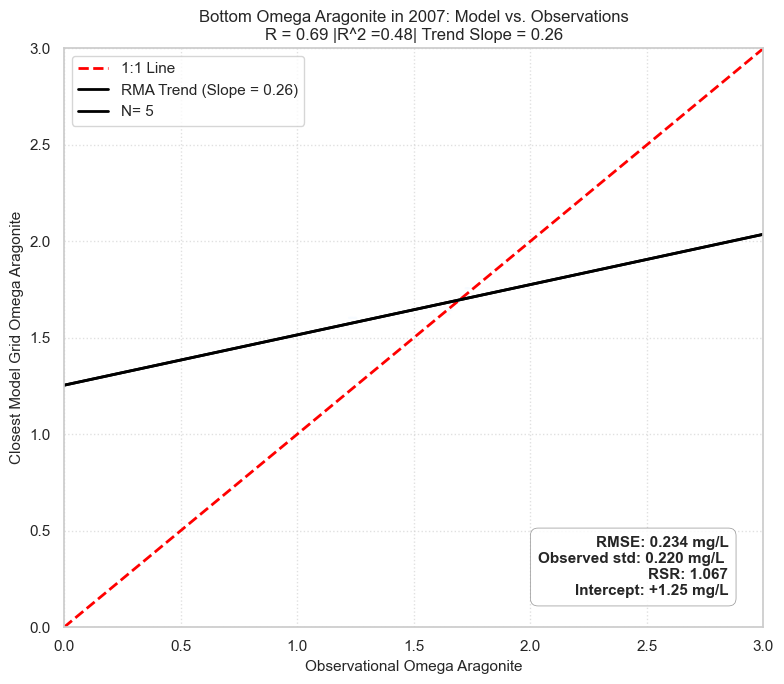


               RUNNING STATISTICS FOR YEAR: 2012        
Mean of delta difference between model 3x3x3 grid data and observational data in 2012 is: 0.1245
Mean of delta difference between model exact grid data and observational data in 2012 is: 0.1456
Global RMSE (3x3x3 grid vs obs) between model and observations in 2012 is: 0.2425
Global RMSE (Exact point vs Obs) between model and observations in 2012 is: 0.3230
-> Calculated using 35 valid exact points in 2012 (out of 35 total pairs).
Calculated Observational Mean: 1.4824
Calculated Model Global Mean: 1.6304
Calculated Global Std Dev: 0.4584
Model grid overestimates the data 77.14 percent of the time
Model grid underestimates the data 22.86 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.1795
When underestimating, the average deficit aragonite (Ω) is: -0.0609
Real-World Observational STD: 0.4093
Model Global STD: 0.4584
Model-to-Observation Variance Ratio: 1.12
Model Grid RSR: 0.5923

ARAGONITE STRESSE

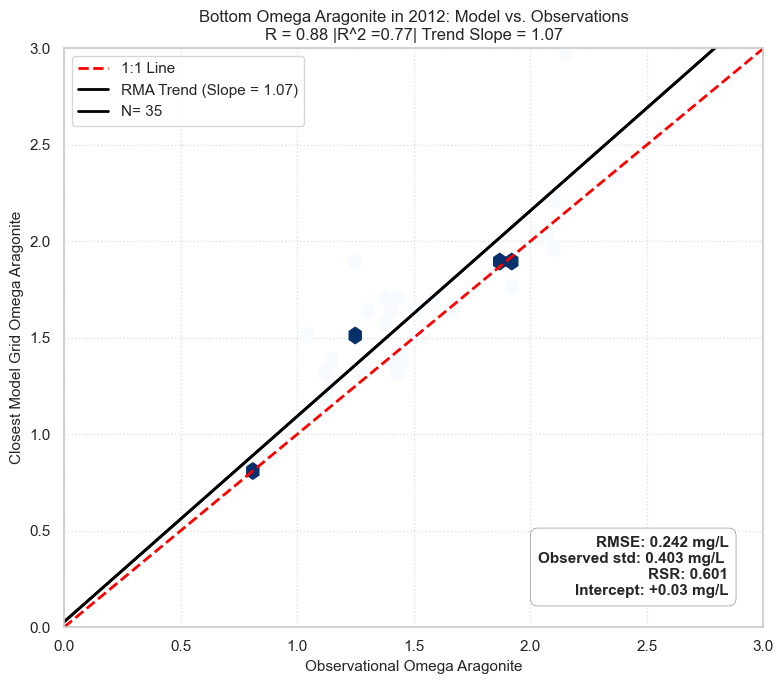


               RUNNING STATISTICS FOR YEAR: 2013        
Mean of delta difference between model 3x3x3 grid data and observational data in 2013 is: 0.1411
Mean of delta difference between model exact grid data and observational data in 2013 is: 0.1528
Global RMSE (3x3x3 grid vs obs) between model and observations in 2013 is: 0.2472
Global RMSE (Exact point vs Obs) between model and observations in 2013 is: 0.3135
-> Calculated using 29 valid exact points in 2013 (out of 29 total pairs).
Calculated Observational Mean: 1.5452
Calculated Model Global Mean: 1.6998
Calculated Global Std Dev: 0.2787
Model grid overestimates the data 79.31 percent of the time
Model grid underestimates the data 20.69 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.2072
When underestimating, the average deficit aragonite (Ω) is: -0.1122
Real-World Observational STD: 0.3353
Model Global STD: 0.2787
Model-to-Observation Variance Ratio: 0.83
Model Grid RSR: 0.7371

ARAGONITE STRESSE

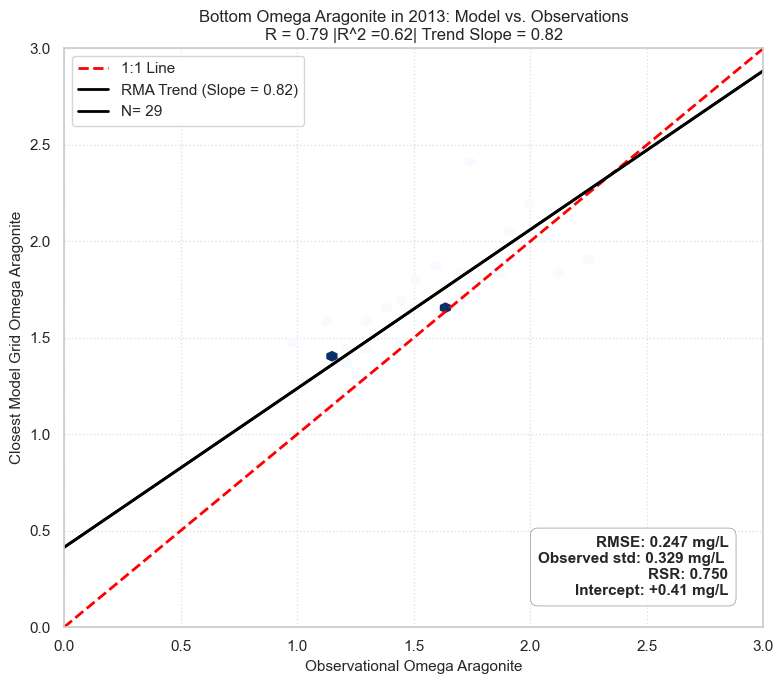


               RUNNING STATISTICS FOR YEAR: 2014        
Mean of delta difference between model 3x3x3 grid data and observational data in 2014 is: 0.2197
Mean of delta difference between model exact grid data and observational data in 2014 is: 0.2898
Global RMSE (3x3x3 grid vs obs) between model and observations in 2014 is: 0.2697
Global RMSE (Exact point vs Obs) between model and observations in 2014 is: 0.3304
-> Calculated using 22 valid exact points in 2014 (out of 22 total pairs).
Calculated Observational Mean: 1.4495
Calculated Model Global Mean: 1.7450
Calculated Global Std Dev: 0.1923
Model grid overestimates the data 90.91 percent of the time
Model grid underestimates the data 9.09 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.2453
When underestimating, the average deficit aragonite (Ω) is: -0.0362
Real-World Observational STD: 0.2305
Model Global STD: 0.1923
Model-to-Observation Variance Ratio: 0.83
Model Grid RSR: 1.1698

ARAGONITE STRESSED

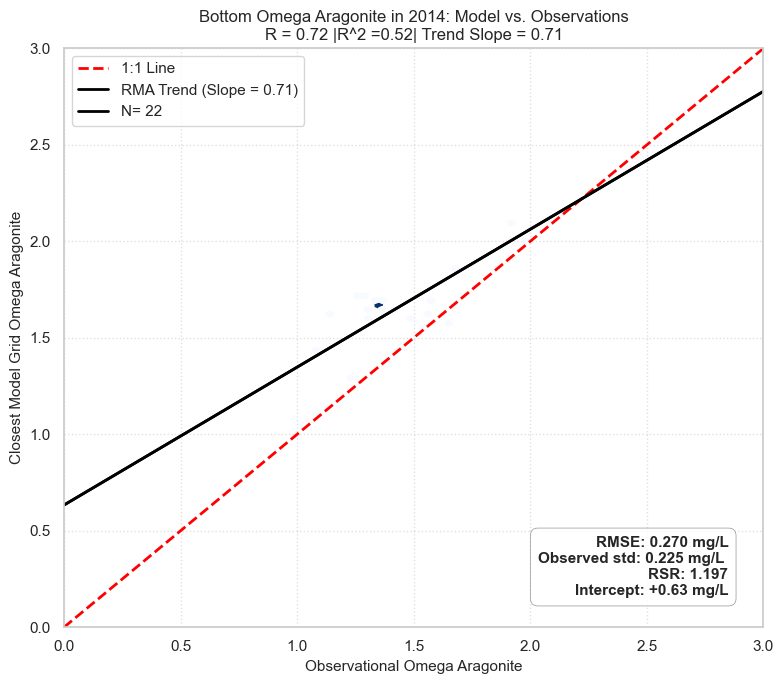


               RUNNING STATISTICS FOR YEAR: 2015        
Mean of delta difference between model 3x3x3 grid data and observational data in 2015 is: 0.1464
Mean of delta difference between model exact grid data and observational data in 2015 is: 0.1826
Global RMSE (3x3x3 grid vs obs) between model and observations in 2015 is: 0.2255
Global RMSE (Exact point vs Obs) between model and observations in 2015 is: 0.2943
-> Calculated using 62 valid exact points in 2015 (out of 62 total pairs).
Calculated Observational Mean: 1.6331
Calculated Model Global Mean: 1.8240
Calculated Global Std Dev: 0.3257
Model grid overestimates the data 82.26 percent of the time
Model grid underestimates the data 17.74 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.1873
When underestimating, the average deficit aragonite (Ω) is: -0.0428
Real-World Observational STD: 0.3195
Model Global STD: 0.3257
Model-to-Observation Variance Ratio: 1.02
Model Grid RSR: 0.7060

ARAGONITE STRESSE

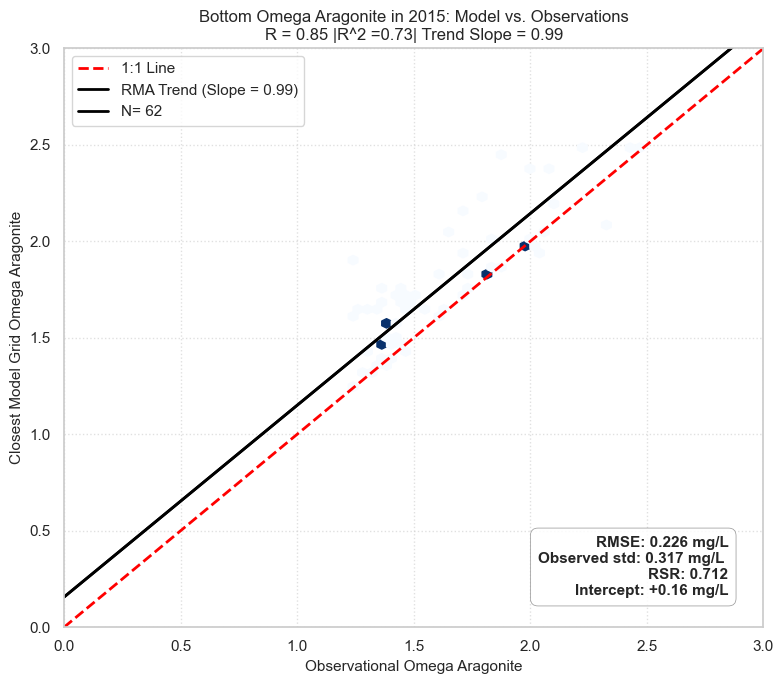


               RUNNING STATISTICS FOR YEAR: 2016        
Mean of delta difference between model 3x3x3 grid data and observational data in 2016 is: 0.3290
Mean of delta difference between model exact grid data and observational data in 2016 is: 0.3517
Global RMSE (3x3x3 grid vs obs) between model and observations in 2016 is: 0.4582
Global RMSE (Exact point vs Obs) between model and observations in 2016 is: 0.5812
-> Calculated using 39 valid exact points in 2016 (out of 39 total pairs).
Calculated Observational Mean: 1.5218
Calculated Model Global Mean: 1.8847
Calculated Global Std Dev: 0.3647
Model grid overestimates the data 84.62 percent of the time
Model grid underestimates the data 15.38 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.4020
When underestimating, the average deficit aragonite (Ω) is: -0.0725
Real-World Observational STD: 0.3898
Model Global STD: 0.3647
Model-to-Observation Variance Ratio: 0.94
Model Grid RSR: 1.1755

ARAGONITE STRESSE

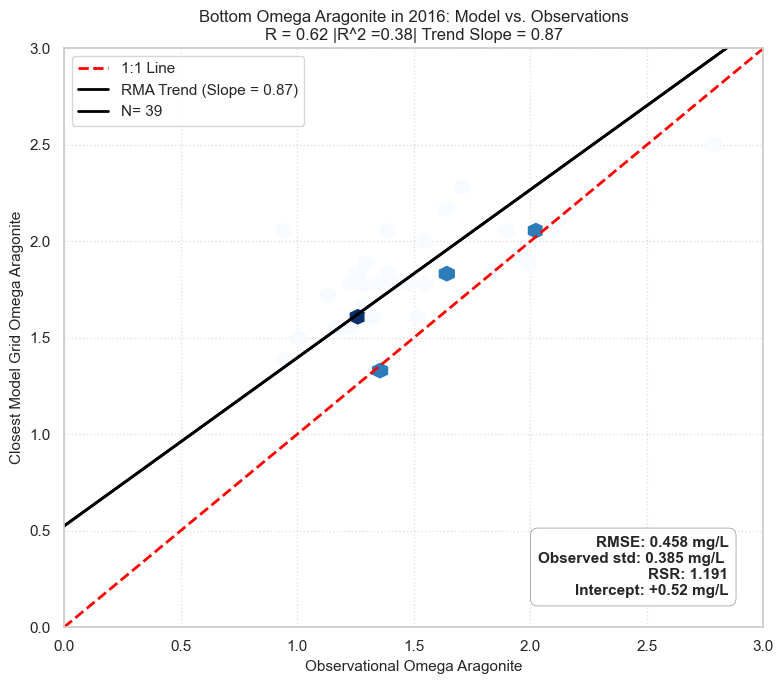


               RUNNING STATISTICS FOR YEAR: 2017        
Mean of delta difference between model 3x3x3 grid data and observational data in 2017 is: 0.2480
Mean of delta difference between model exact grid data and observational data in 2017 is: 0.3228
Global RMSE (3x3x3 grid vs obs) between model and observations in 2017 is: 0.3527
Global RMSE (Exact point vs Obs) between model and observations in 2017 is: 0.4348
-> Calculated using 37 valid exact points in 2017 (out of 37 total pairs).
Calculated Observational Mean: 1.5581
Calculated Model Global Mean: 1.9020
Calculated Global Std Dev: 0.3474
Model grid overestimates the data 86.49 percent of the time
Model grid underestimates the data 13.51 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.3129
When underestimating, the average deficit aragonite (Ω) is: -0.1676
Real-World Observational STD: 0.2761
Model Global STD: 0.3474
Model-to-Observation Variance Ratio: 1.26
Model Grid RSR: 1.2774

ARAGONITE STRESSE

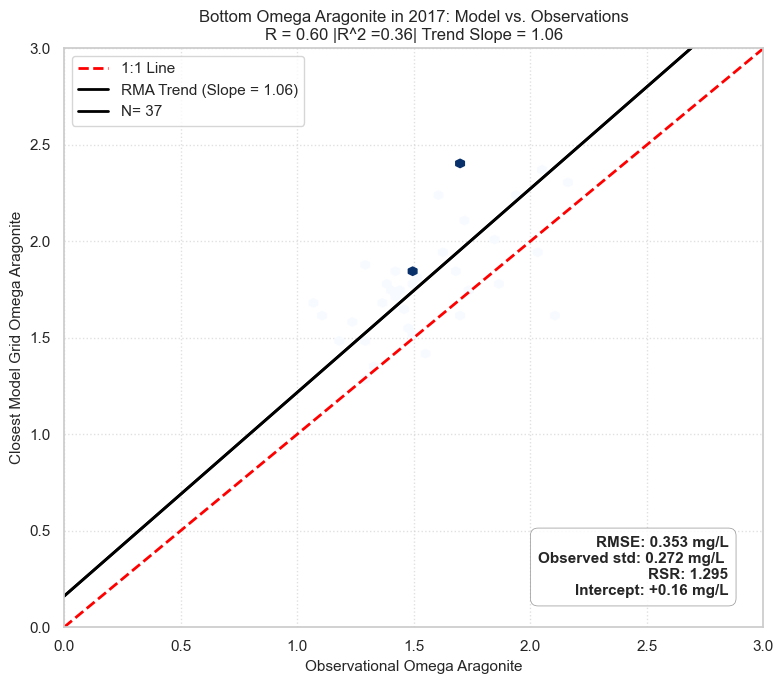


               RUNNING STATISTICS FOR YEAR: 2018        
Mean of delta difference between model 3x3x3 grid data and observational data in 2018 is: 0.2784
Mean of delta difference between model exact grid data and observational data in 2018 is: 0.3279
Global RMSE (3x3x3 grid vs obs) between model and observations in 2018 is: 0.3518
Global RMSE (Exact point vs Obs) between model and observations in 2018 is: 0.4427
-> Calculated using 107 valid exact points in 2018 (out of 108 total pairs).
Calculated Observational Mean: 1.5643
Calculated Model Global Mean: 1.8994
Calculated Global Std Dev: 0.3162
Model grid overestimates the data 93.52 percent of the time
Model grid underestimates the data 6.48 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.2982
When underestimating, the average deficit aragonite (Ω) is: -0.0073
Real-World Observational STD: 0.2466
Model Global STD: 0.3162
Model-to-Observation Variance Ratio: 1.28
Model Grid RSR: 1.4263

ARAGONITE STRESS

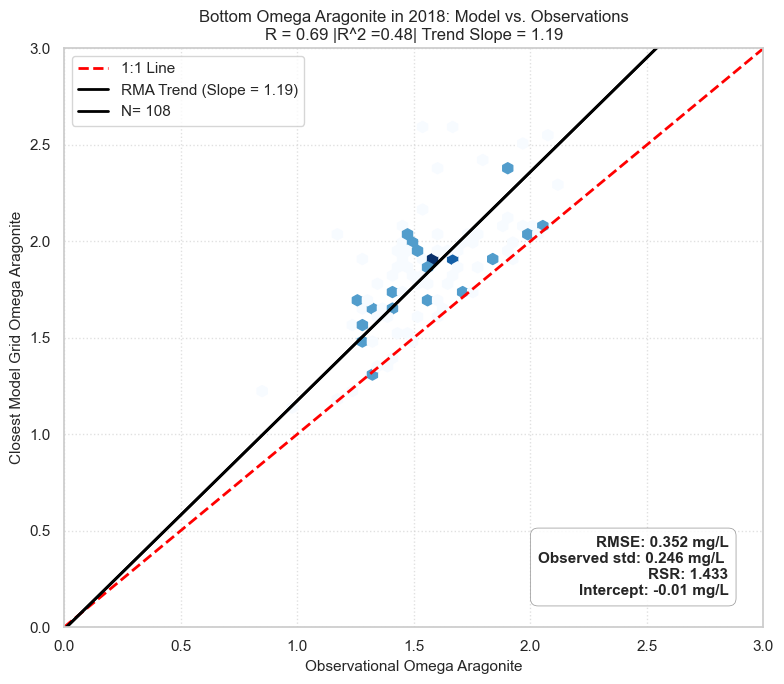


               RUNNING STATISTICS FOR YEAR: 2019        
Mean of delta difference between model 3x3x3 grid data and observational data in 2019 is: 0.2886
Mean of delta difference between model exact grid data and observational data in 2019 is: 0.3832
Global RMSE (3x3x3 grid vs obs) between model and observations in 2019 is: 0.4282
Global RMSE (Exact point vs Obs) between model and observations in 2019 is: 0.5343
-> Calculated using 85 valid exact points in 2019 (out of 85 total pairs).
Calculated Observational Mean: 1.4528
Calculated Model Global Mean: 1.8296
Calculated Global Std Dev: 0.4102
Model grid overestimates the data 77.65 percent of the time
Model grid underestimates the data 22.35 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.3880
When underestimating, the average deficit aragonite (Ω) is: -0.0566
Real-World Observational STD: 0.4097
Model Global STD: 0.4102
Model-to-Observation Variance Ratio: 1.00
Model Grid RSR: 1.0450

ARAGONITE STRESSE

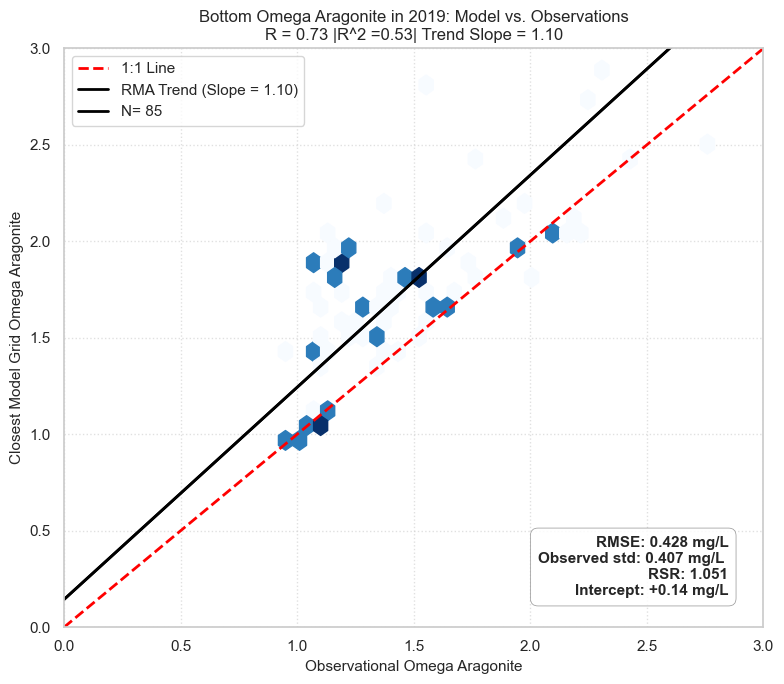


               RUNNING STATISTICS FOR YEAR: 2021        
Mean of delta difference between model 3x3x3 grid data and observational data in 2021 is: 0.0225
Mean of delta difference between model exact grid data and observational data in 2021 is: 0.0151
Global RMSE (3x3x3 grid vs obs) between model and observations in 2021 is: 0.2420
Global RMSE (Exact point vs Obs) between model and observations in 2021 is: 0.3064
-> Calculated using 1149 valid exact points in 2021 (out of 1149 total pairs).
Calculated Observational Mean: 1.7582
Calculated Model Global Mean: 1.7720
Calculated Global Std Dev: 0.2460
Model grid overestimates the data 58.83 percent of the time
Model grid underestimates the data 41.17 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.1518
When underestimating, the average deficit aragonite (Ω) is: -0.1622
Real-World Observational STD: 0.3535
Model Global STD: 0.2460
Model-to-Observation Variance Ratio: 0.70
Model Grid RSR: 0.6845

ARAGONITE STR

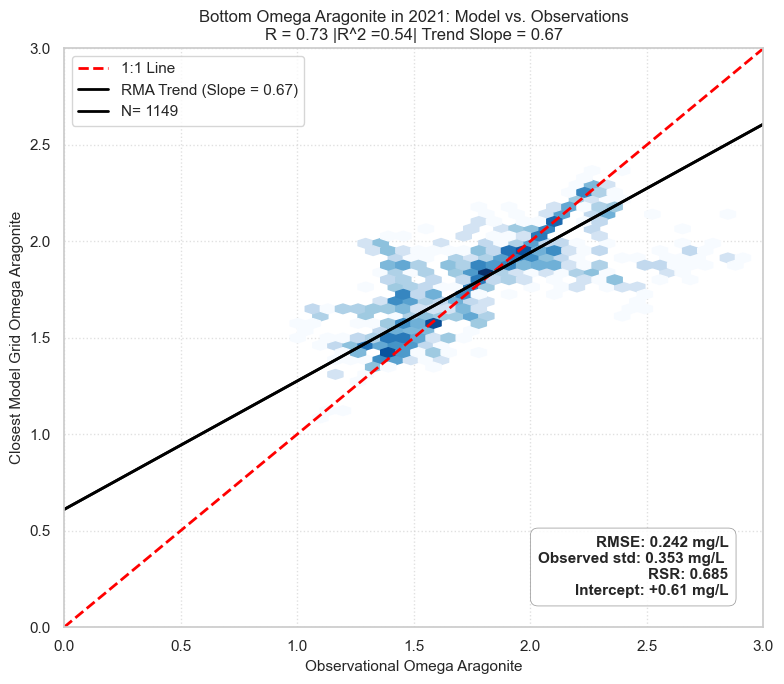


               RUNNING STATISTICS FOR YEAR: 2022        
Mean of delta difference between model 3x3x3 grid data and observational data in 2022 is: 0.1211
Mean of delta difference between model exact grid data and observational data in 2022 is: 0.1427
Global RMSE (3x3x3 grid vs obs) between model and observations in 2022 is: 0.2400
Global RMSE (Exact point vs Obs) between model and observations in 2022 is: 0.3139
-> Calculated using 1049 valid exact points in 2022 (out of 1051 total pairs).
Calculated Observational Mean: 1.5827
Calculated Model Global Mean: 1.7263
Calculated Global Std Dev: 0.2904
Model grid overestimates the data 76.97 percent of the time
Model grid underestimates the data 23.03 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.1857
When underestimating, the average deficit aragonite (Ω) is: -0.0949
Real-World Observational STD: 0.3340
Model Global STD: 0.2904
Model-to-Observation Variance Ratio: 0.87
Model Grid RSR: 0.7185

ARAGONITE STR

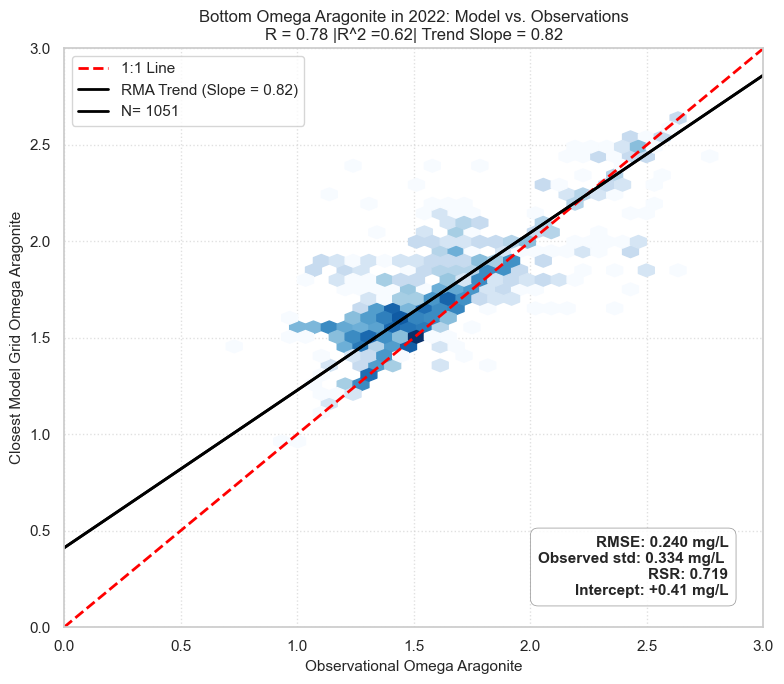


               RUNNING STATISTICS FOR YEAR: 2023        
Mean of delta difference between model 3x3x3 grid data and observational data in 2023 is: 0.3249
Mean of delta difference between model exact grid data and observational data in 2023 is: 0.3765
Global RMSE (3x3x3 grid vs obs) between model and observations in 2023 is: 0.4410
Global RMSE (Exact point vs Obs) between model and observations in 2023 is: 0.5076
-> Calculated using 1208 valid exact points in 2023 (out of 1208 total pairs).
Calculated Observational Mean: 1.4848
Calculated Model Global Mean: 1.8597
Calculated Global Std Dev: 0.2470
Model grid overestimates the data 87.17 percent of the time
Model grid underestimates the data 12.83 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.3865
When underestimating, the average deficit aragonite (Ω) is: -0.0937
Real-World Observational STD: 0.3821
Model Global STD: 0.2470
Model-to-Observation Variance Ratio: 0.65
Model Grid RSR: 1.1542

ARAGONITE STR

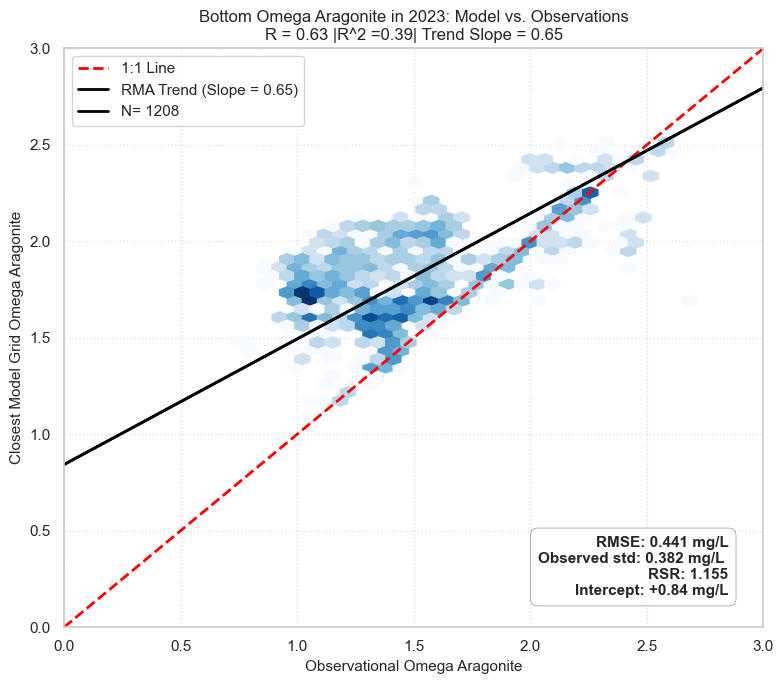


               RUNNING STATISTICS FOR YEAR: 2024        
Mean of delta difference between model 3x3x3 grid data and observational data in 2024 is: 0.7348
Mean of delta difference between model exact grid data and observational data in 2024 is: 0.8166
Global RMSE (3x3x3 grid vs obs) between model and observations in 2024 is: 0.8534
Global RMSE (Exact point vs Obs) between model and observations in 2024 is: 0.9252
-> Calculated using 916 valid exact points in 2024 (out of 917 total pairs).
Calculated Observational Mean: 1.3844
Calculated Model Global Mean: 2.1945
Calculated Global Std Dev: 0.2226
Model grid overestimates the data 95.31 percent of the time
Model grid underestimates the data 4.69 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.7732
When underestimating, the average deficit aragonite (Ω) is: -0.0452
Real-World Observational STD: 0.4143
Model Global STD: 0.2226
Model-to-Observation Variance Ratio: 0.54
Model Grid RSR: 2.0599

ARAGONITE STRESS

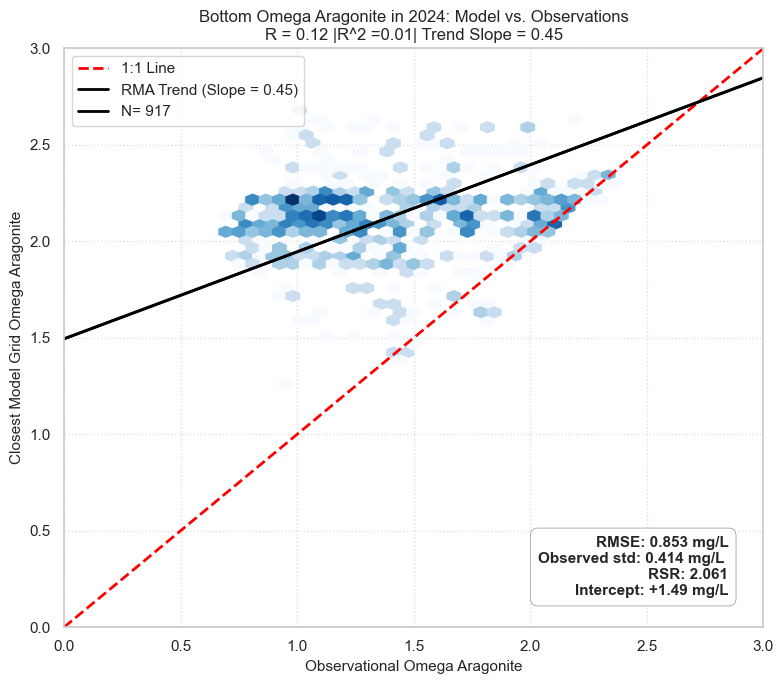


               RUNNING STATISTICS FOR YEAR: 2025        
Mean of delta difference between model 3x3x3 grid data and observational data in 2025 is: 0.6424
Mean of delta difference between model exact grid data and observational data in 2025 is: 0.7243
Global RMSE (3x3x3 grid vs obs) between model and observations in 2025 is: 0.7023
Global RMSE (Exact point vs Obs) between model and observations in 2025 is: 0.7854
-> Calculated using 479 valid exact points in 2025 (out of 479 total pairs).
Calculated Observational Mean: 1.4777
Calculated Model Global Mean: 2.1977
Calculated Global Std Dev: 0.1760
Model grid overestimates the data 97.08 percent of the time
Model grid underestimates the data 2.92 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.6700
When underestimating, the average deficit aragonite (Ω) is: -0.2732
Real-World Observational STD: 0.2492
Model Global STD: 0.1760
Model-to-Observation Variance Ratio: 0.71
Model Grid RSR: 2.8186

ARAGONITE STRESS

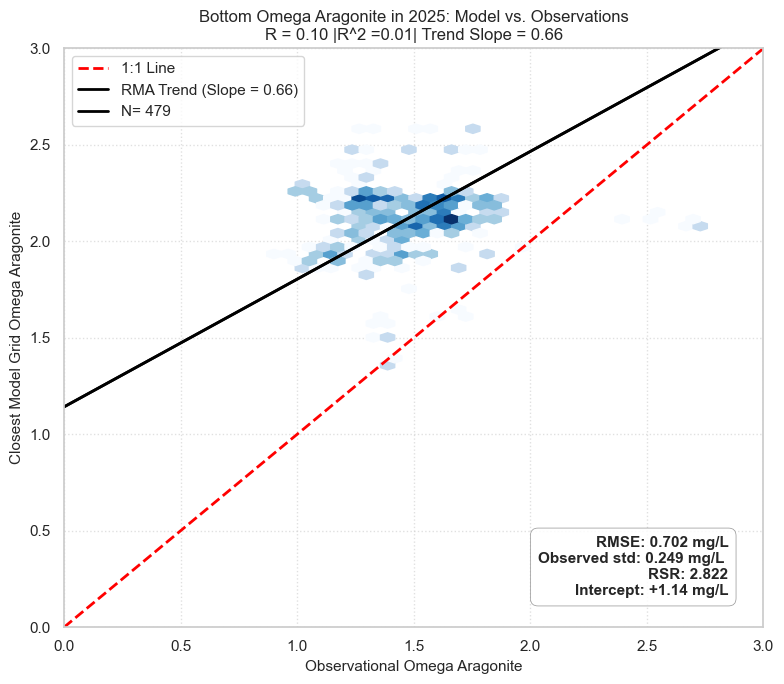


               RUNNING STATISTICS FOR SEASON: Spring     
Mean of delta difference between model 3x3x3 grid data and observational data in Season_Spring is: 0.3427
Mean of delta difference between model exact grid data and observational data in Season_Spring is: 0.4037
Global RMSE (3x3x3 grid vs obs) between model and observations in Season_Spring is: 0.4812
Global RMSE (Exact point vs Obs) between model and observations in Season_Spring is: 0.5534
-> Calculated using 1305 valid exact points in Season_Spring (out of 1305 total pairs).
Calculated Observational Mean: 1.6220
Calculated Model Global Mean: 2.0199
Calculated Global Std Dev: 0.2778
Model grid overestimates the data 88.43 percent of the time
Model grid underestimates the data 11.57 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.3914
When underestimating, the average deficit aragonite (Ω) is: -0.0296
Real-World Observational STD: 0.2641
Model Global STD: 0.2778
Model-to-Observation Variance Rat

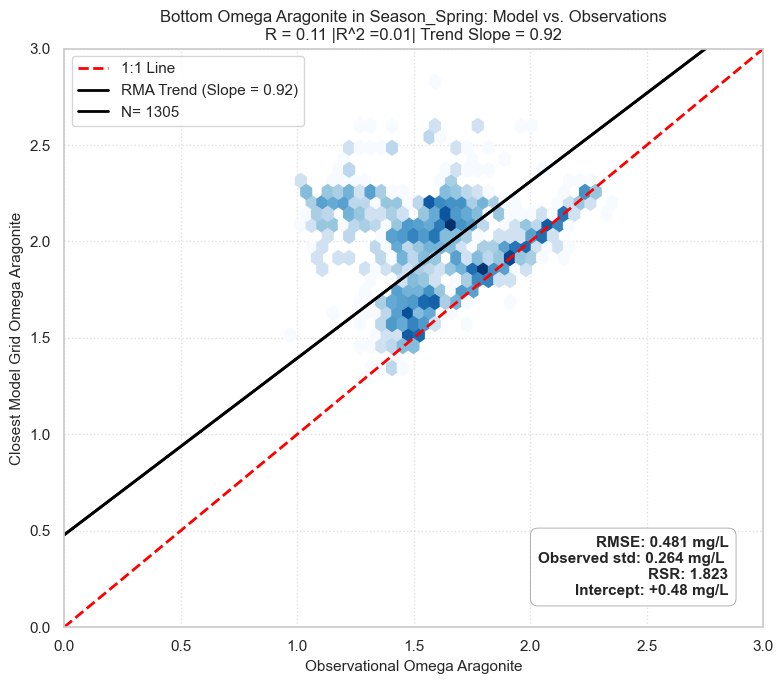


               RUNNING STATISTICS FOR SEASON: Summer     
Mean of delta difference between model 3x3x3 grid data and observational data in Season_Summer is: 0.4399
Mean of delta difference between model exact grid data and observational data in Season_Summer is: 0.4905
Global RMSE (3x3x3 grid vs obs) between model and observations in Season_Summer is: 0.5952
Global RMSE (Exact point vs Obs) between model and observations in Season_Summer is: 0.6526
-> Calculated using 1836 valid exact points in Season_Summer (out of 1840 total pairs).
Calculated Observational Mean: 1.3595
Calculated Model Global Mean: 1.8476
Calculated Global Std Dev: 0.2957
Model grid overestimates the data 86.47 percent of the time
Model grid underestimates the data 13.53 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.5208
When underestimating, the average deficit aragonite (Ω) is: -0.0768
Real-World Observational STD: 0.3086
Model Global STD: 0.2957
Model-to-Observation Variance Rat

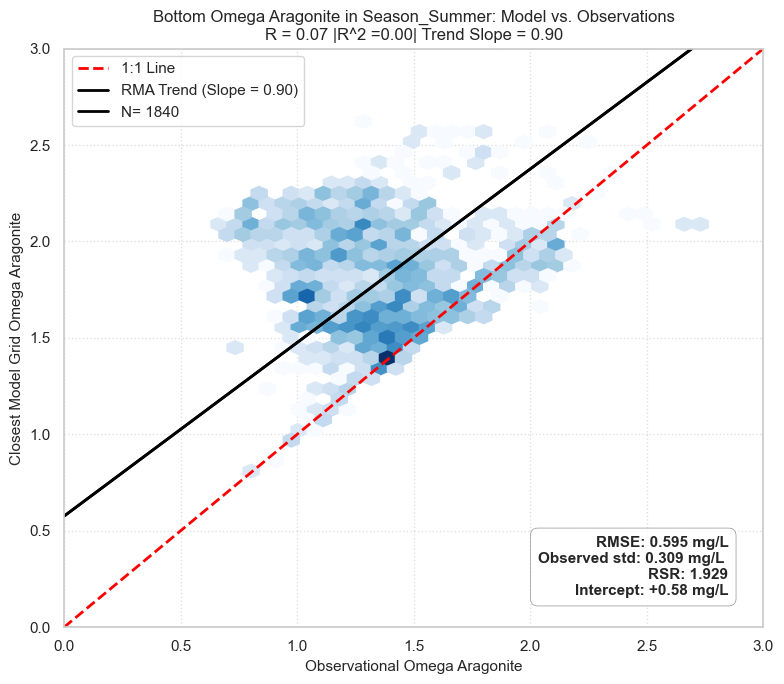


               RUNNING STATISTICS FOR SEASON: Fall     
Mean of delta difference between model 3x3x3 grid data and observational data in Season_Fall is: 0.1646
Mean of delta difference between model exact grid data and observational data in Season_Fall is: 0.1806
Global RMSE (3x3x3 grid vs obs) between model and observations in Season_Fall is: 0.4378
Global RMSE (Exact point vs Obs) between model and observations in Season_Fall is: 0.5180
-> Calculated using 1650 valid exact points in Season_Fall (out of 1650 total pairs).
Calculated Observational Mean: 1.7042
Calculated Model Global Mean: 1.8866
Calculated Global Std Dev: 0.3433
Model grid overestimates the data 67.58 percent of the time
Model grid underestimates the data 32.42 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.3316
When underestimating, the average deficit aragonite (Ω) is: -0.1834
Real-World Observational STD: 0.4592
Model Global STD: 0.3433
Model-to-Observation Variance Ratio: 0.75
Mod

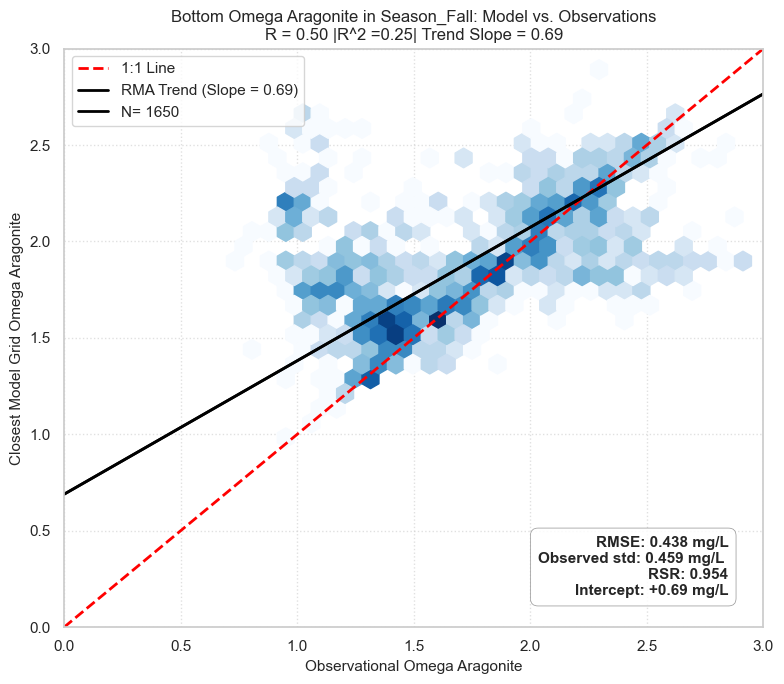


               RUNNING STATISTICS FOR SEASON: Winter     
Mean of delta difference between model 3x3x3 grid data and observational data in Season_Winter is: 0.2291
Mean of delta difference between model exact grid data and observational data in Season_Winter is: 0.2622
Global RMSE (3x3x3 grid vs obs) between model and observations in Season_Winter is: 0.3308
Global RMSE (Exact point vs Obs) between model and observations in Season_Winter is: 0.3660
-> Calculated using 431 valid exact points in Season_Winter (out of 431 total pairs).
Calculated Observational Mean: 1.5573
Calculated Model Global Mean: 1.8193
Calculated Global Std Dev: 0.3050
Model grid overestimates the data 86.54 percent of the time
Model grid underestimates the data 13.46 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.2711
When underestimating, the average deficit aragonite (Ω) is: -0.0411
Real-World Observational STD: 0.2555
Model Global STD: 0.3050
Model-to-Observation Variance Ratio

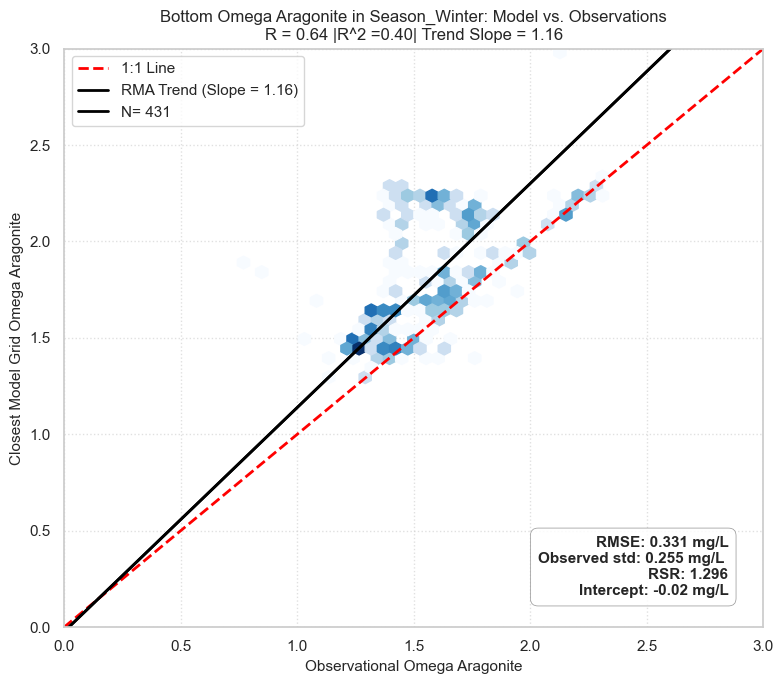


               RUNNING STATISTICS FOR REGION: MAB_south     
Mean of delta difference between model 3x3x3 grid data and observational data in MAB_south is: 0.3915
Mean of delta difference between model exact grid data and observational data in MAB_south is: 0.4552
Global RMSE (3x3x3 grid vs obs) between model and observations in MAB_south is: 0.5942
Global RMSE (Exact point vs Obs) between model and observations in MAB_south is: 0.6862
-> Calculated using 1792 valid exact points in MAB_south (out of 1792 total pairs).
Calculated Observational Mean: 1.6631
Calculated Model Global Mean: 2.1124
Calculated Global Std Dev: 0.2804
Model grid overestimates the data 82.09 percent of the time
Model grid underestimates the data 17.91 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.5100
When underestimating, the average deficit aragonite (Ω) is: -0.1516
Real-World Observational STD: 0.4429
Model Global STD: 0.2804
Model-to-Observation Variance Ratio: 0.63
Model Gr

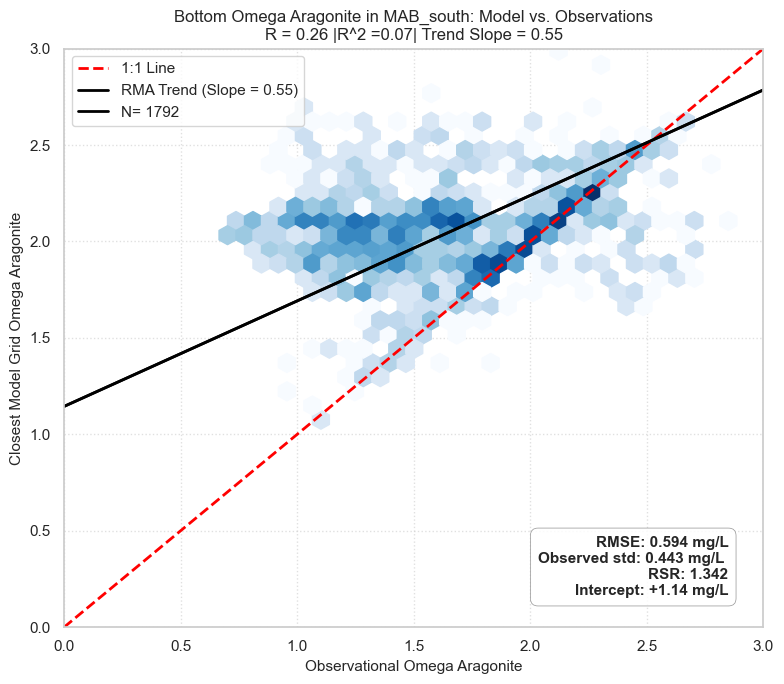


               RUNNING STATISTICS FOR REGION: MAB_north     
Mean of delta difference between model 3x3x3 grid data and observational data in MAB_north is: 0.3972
Mean of delta difference between model exact grid data and observational data in MAB_north is: 0.4385
Global RMSE (3x3x3 grid vs obs) between model and observations in MAB_north is: 0.5801
Global RMSE (Exact point vs Obs) between model and observations in MAB_north is: 0.6332
-> Calculated using 1806 valid exact points in MAB_north (out of 1806 total pairs).
Calculated Observational Mean: 1.4951
Calculated Model Global Mean: 1.9309
Calculated Global Std Dev: 0.2518
Model grid overestimates the data 83.06 percent of the time
Model grid underestimates the data 16.94 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.5120
When underestimating, the average deficit aragonite (Ω) is: -0.1659
Real-World Observational STD: 0.3870
Model Global STD: 0.2518
Model-to-Observation Variance Ratio: 0.65
Model Gr

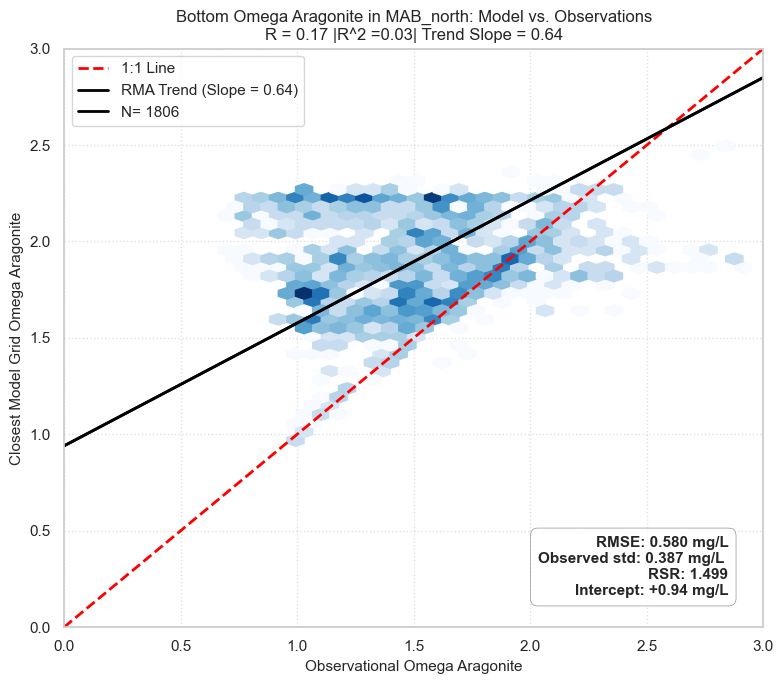


               RUNNING STATISTICS FOR REGION: GB     
Mean of delta difference between model 3x3x3 grid data and observational data in GB is: 0.2173
Mean of delta difference between model exact grid data and observational data in GB is: 0.2539
Global RMSE (3x3x3 grid vs obs) between model and observations in GB is: 0.2993
Global RMSE (Exact point vs Obs) between model and observations in GB is: 0.3572
-> Calculated using 82 valid exact points in GB (out of 82 total pairs).
Calculated Observational Mean: 1.6297
Calculated Model Global Mean: 1.9094
Calculated Global Std Dev: 0.2861
Model grid overestimates the data 87.80 percent of the time
Model grid underestimates the data 12.20 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.2532
When underestimating, the average deficit aragonite (Ω) is: -0.0418
Real-World Observational STD: 0.2429
Model Global STD: 0.2861
Model-to-Observation Variance Ratio: 1.18
Model Grid RSR: 1.2322

ARAGONITE STRESSED STATUS MATC

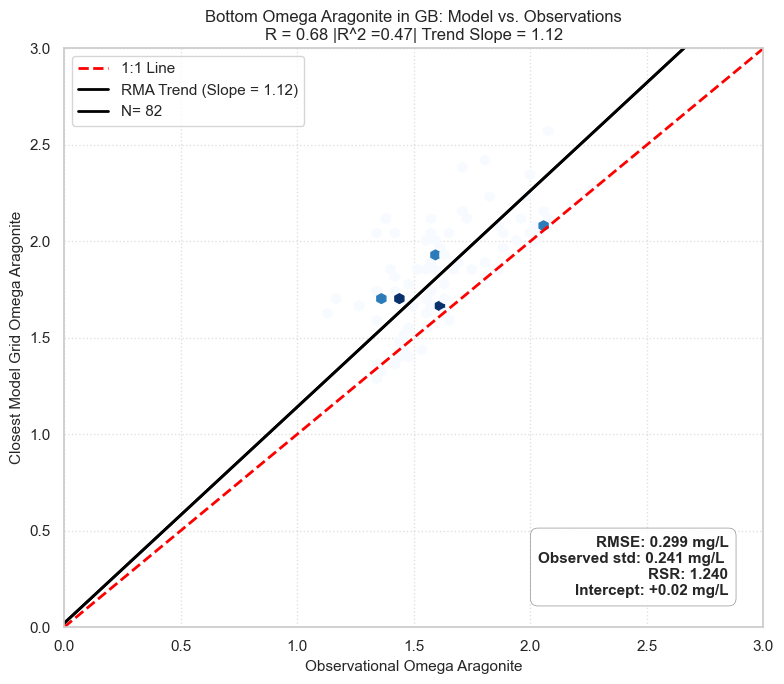


               RUNNING STATISTICS FOR REGION: GOM_west     
Mean of delta difference between model 3x3x3 grid data and observational data in GOM_west is: 0.1218
Mean of delta difference between model exact grid data and observational data in GOM_west is: 0.1446
Global RMSE (3x3x3 grid vs obs) between model and observations in GOM_west is: 0.2046
Global RMSE (Exact point vs Obs) between model and observations in GOM_west is: 0.2424
-> Calculated using 618 valid exact points in GOM_west (out of 618 total pairs).
Calculated Observational Mean: 1.3594
Calculated Model Global Mean: 1.5134
Calculated Global Std Dev: 0.1344
Model grid overestimates the data 78.64 percent of the time
Model grid underestimates the data 21.36 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.1666
When underestimating, the average deficit aragonite (Ω) is: -0.0431
Real-World Observational STD: 0.1540
Model Global STD: 0.1344
Model-to-Observation Variance Ratio: 0.87
Model Grid RSR: 

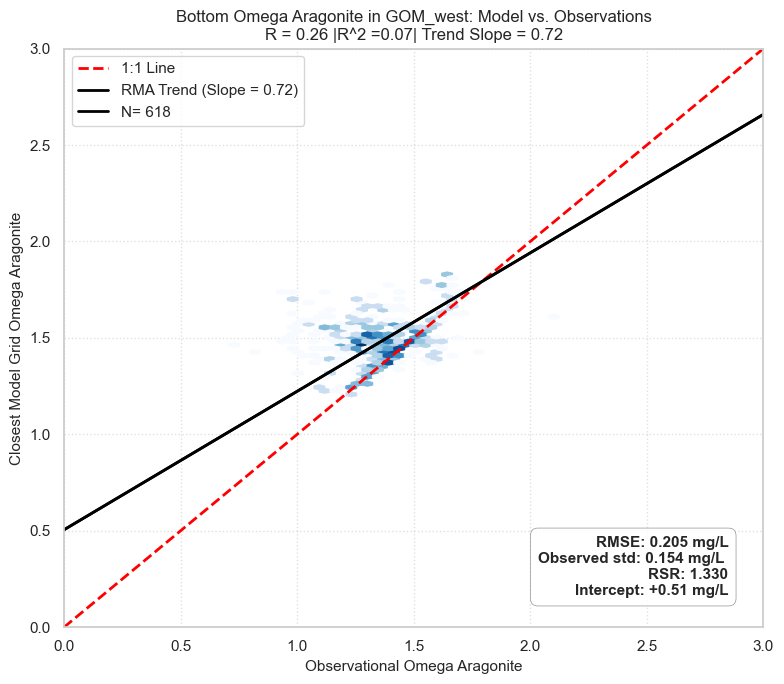


               RUNNING STATISTICS FOR REGION: GOM_east     
Mean of delta difference between model 3x3x3 grid data and observational data in GOM_east is: 0.1618
Mean of delta difference between model exact grid data and observational data in GOM_east is: 0.1836
Global RMSE (3x3x3 grid vs obs) between model and observations in GOM_east is: 0.2258
Global RMSE (Exact point vs Obs) between model and observations in GOM_east is: 0.2557
-> Calculated using 653 valid exact points in GOM_east (out of 653 total pairs).
Calculated Observational Mean: 1.4718
Calculated Model Global Mean: 1.6579
Calculated Global Std Dev: 0.1186
Model grid overestimates the data 88.51 percent of the time
Model grid underestimates the data 11.49 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.1947
When underestimating, the average deficit aragonite (Ω) is: -0.0916
Real-World Observational STD: 0.1522
Model Global STD: 0.1186
Model-to-Observation Variance Ratio: 0.78
Model Grid RSR: 

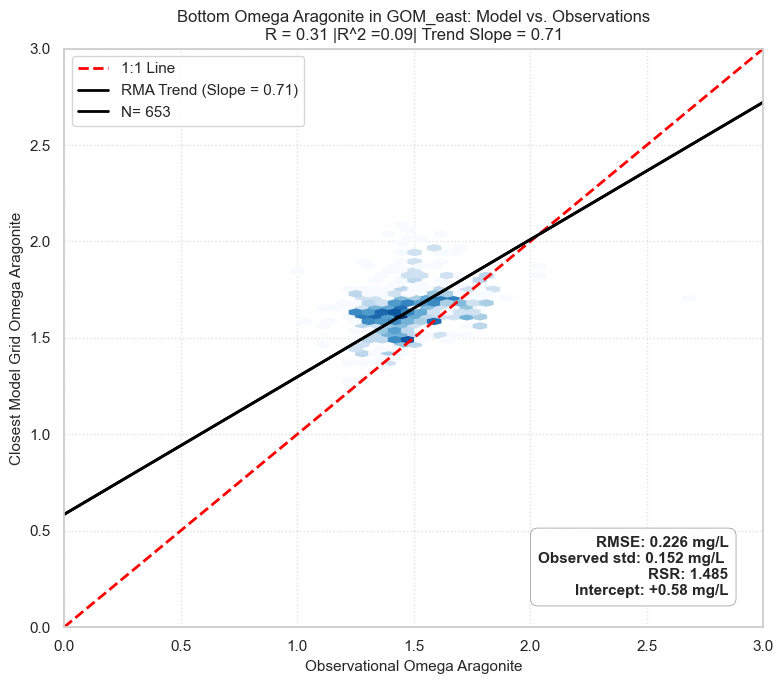


               RUNNING STATISTICS FOR DEPTH: Shallow(<25m)       
Mean of delta difference between model 3x3x3 grid data and observational data in Depth_Shallow(<25m) is: 0.3687
Mean of delta difference between model exact grid data and observational data in Depth_Shallow(<25m) is: 0.3968
Global RMSE (3x3x3 grid vs obs) between model and observations in Depth_Shallow(<25m) is: 0.5723
Global RMSE (Exact point vs Obs) between model and observations in Depth_Shallow(<25m) is: 0.6555
-> Calculated using 424 valid exact points in Depth_Shallow(<25m) (out of 425 total pairs).
Calculated Observational Mean: 1.6156
Calculated Model Global Mean: 2.0200
Calculated Global Std Dev: 0.2796
Model grid overestimates the data 77.41 percent of the time
Model grid underestimates the data 22.59 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.5171
When underestimating, the average deficit aragonite (Ω) is: -0.1396
Real-World Observational STD: 0.4873
Model Global STD: 0.27

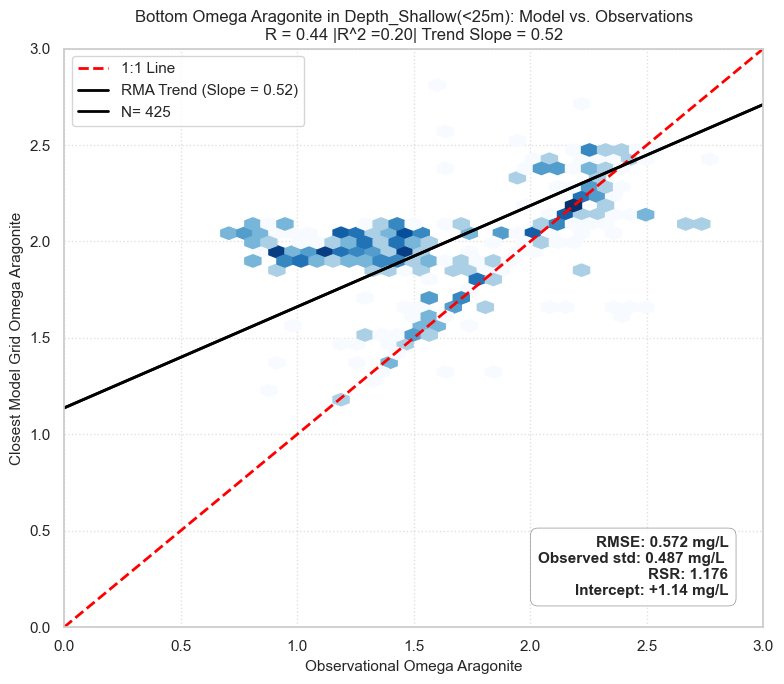


               RUNNING STATISTICS FOR DEPTH: Inner-midshelf(<150m)       
Mean of delta difference between model 3x3x3 grid data and observational data in Depth_Inner-midshelf(<150m) is: 0.3464
Mean of delta difference between model exact grid data and observational data in Depth_Inner-midshelf(<150m) is: 0.3956
Global RMSE (3x3x3 grid vs obs) between model and observations in Depth_Inner-midshelf(<150m) is: 0.5425
Global RMSE (Exact point vs Obs) between model and observations in Depth_Inner-midshelf(<150m) is: 0.6112
-> Calculated using 3868 valid exact points in Depth_Inner-midshelf(<150m) (out of 3871 total pairs).
Calculated Observational Mean: 1.5653
Calculated Model Global Mean: 1.9575
Calculated Global Std Dev: 0.3080
Model grid overestimates the data 80.73 percent of the time
Model grid underestimates the data 19.27 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.4614
When underestimating, the average deficit aragonite (Ω) is: -0.1351
Real-Worl

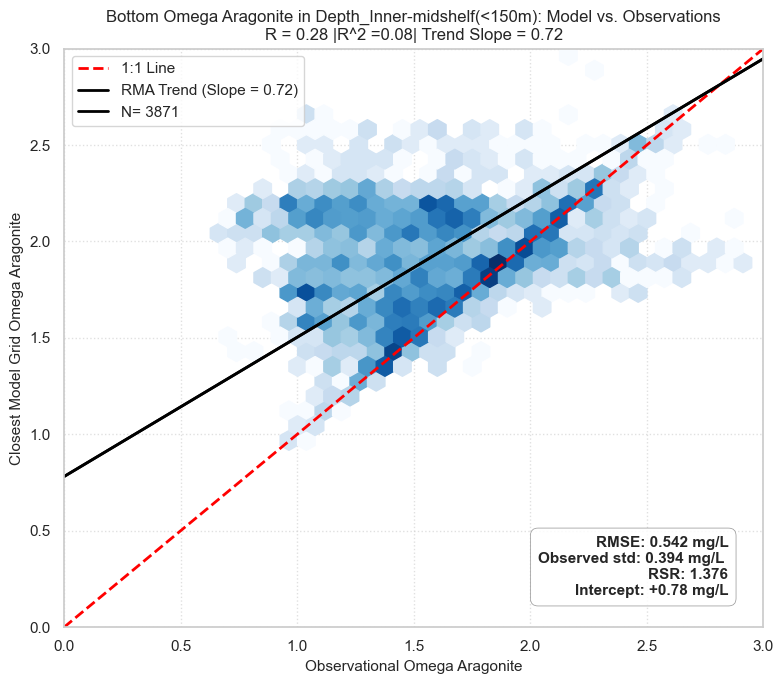


               RUNNING STATISTICS FOR DEPTH: Shelf_slope(<400m)       
Mean of delta difference between model 3x3x3 grid data and observational data in Depth_Shelf_slope(<400m) is: 0.1413
Mean of delta difference between model exact grid data and observational data in Depth_Shelf_slope(<400m) is: 0.1525
Global RMSE (3x3x3 grid vs obs) between model and observations in Depth_Shelf_slope(<400m) is: 0.2066
Global RMSE (Exact point vs Obs) between model and observations in Depth_Shelf_slope(<400m) is: 0.2451
-> Calculated using 915 valid exact points in Depth_Shelf_slope(<400m) (out of 915 total pairs).
Calculated Observational Mean: 1.4630
Calculated Model Global Mean: 1.6164
Calculated Global Std Dev: 0.1512
Model grid overestimates the data 84.59 percent of the time
Model grid underestimates the data 15.41 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.1798
When underestimating, the average deficit aragonite (Ω) is: -0.0700
Real-World Observational STD:

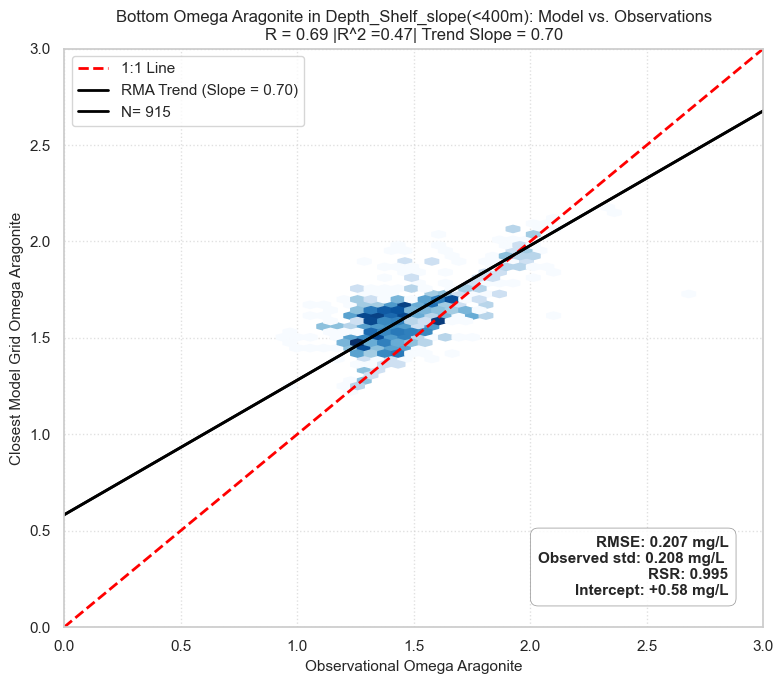


               RUNNING STATISTICS FOR DEPTH: Deep(>400m)       
Mean of delta difference between model 3x3x3 grid data and observational data in Depth_Deep(>400m) is: -0.0021
Mean of delta difference between model exact grid data and observational data in Depth_Deep(>400m) is: 0.0268
Global RMSE (3x3x3 grid vs obs) between model and observations in Depth_Deep(>400m) is: 0.0164
Global RMSE (Exact point vs Obs) between model and observations in Depth_Deep(>400m) is: 0.0666
-> Calculated using 15 valid exact points in Depth_Deep(>400m) (out of 15 total pairs).
Calculated Observational Mean: 1.1273
Calculated Model Global Mean: 1.1728
Calculated Global Std Dev: 0.2687
Model grid overestimates the data 33.33 percent of the time
Model grid underestimates the data 66.67 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.0125
When underestimating, the average deficit aragonite (Ω) is: -0.0094
Real-World Observational STD: 0.1978
Model Global STD: 0.2687
Model-to-O

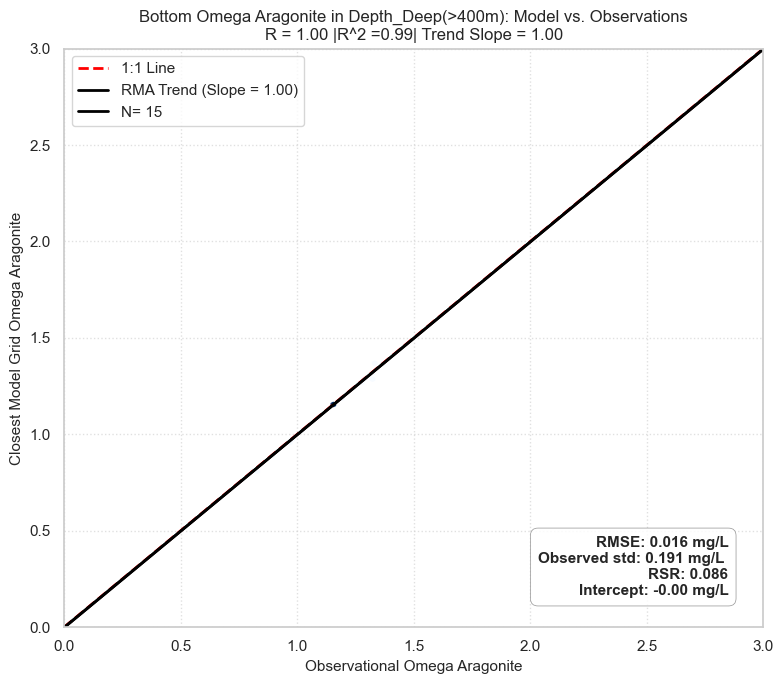


 Running Region x Year intersections...
Mean of delta difference between model 3x3x3 grid data and observational data in MAB_south_2012 is: 0.2396
Mean of delta difference between model exact grid data and observational data in MAB_south_2012 is: 0.3399
Global RMSE (3x3x3 grid vs obs) between model and observations in MAB_south_2012 is: 0.3876
Global RMSE (Exact point vs Obs) between model and observations in MAB_south_2012 is: 0.4799
-> Calculated using 8 valid exact points in MAB_south_2012 (out of 8 total pairs).
Calculated Observational Mean: 1.7894
Calculated Model Global Mean: 2.1229
Calculated Global Std Dev: 0.5439
Model grid overestimates the data 100.00 percent of the time
Model grid underestimates the data 0.00 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.2396
When underestimating, the average deficit aragonite (Ω) is: nan
Real-World Observational STD: 0.4281
Model Global STD: 0.5439
Model-to-Observation Variance Ratio: 1.27
Model Grid RSR

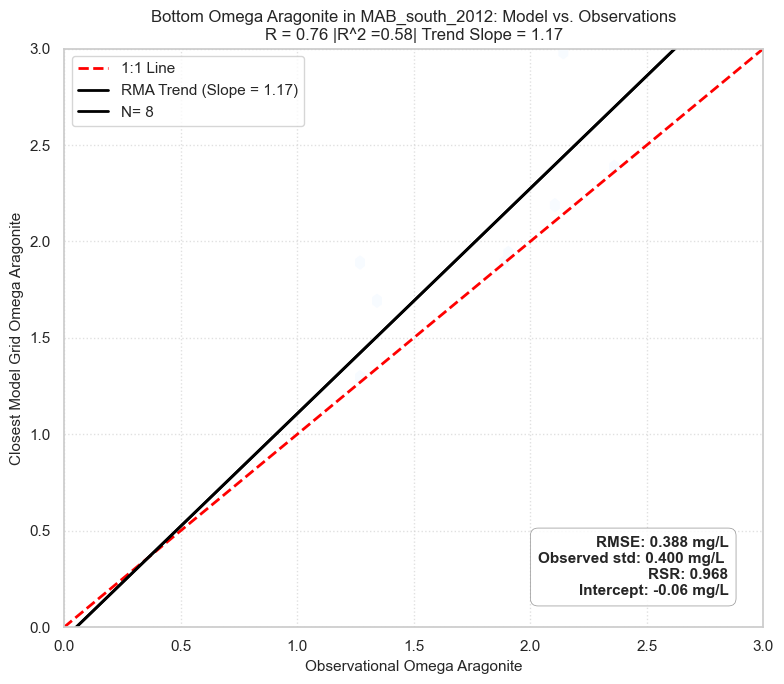

Mean of delta difference between model 3x3x3 grid data and observational data in MAB_south_2013 is: 0.1070
Mean of delta difference between model exact grid data and observational data in MAB_south_2013 is: 0.1420
Global RMSE (3x3x3 grid vs obs) between model and observations in MAB_south_2013 is: 0.3419
Global RMSE (Exact point vs Obs) between model and observations in MAB_south_2013 is: 0.3741
-> Calculated using 5 valid exact points in MAB_south_2013 (out of 5 total pairs).
Calculated Observational Mean: 1.8320
Calculated Model Global Mean: 1.9726
Calculated Global Std Dev: 0.3889
Model grid overestimates the data 80.00 percent of the time
Model grid underestimates the data 20.00 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.2203
When underestimating, the average deficit aragonite (Ω) is: -0.3460
Real-World Observational STD: 0.3663
Model Global STD: 0.3889
Model-to-Observation Variance Ratio: 1.06
Model Grid RSR: 0.9335

ARAGONITE STRESSED STATUS M

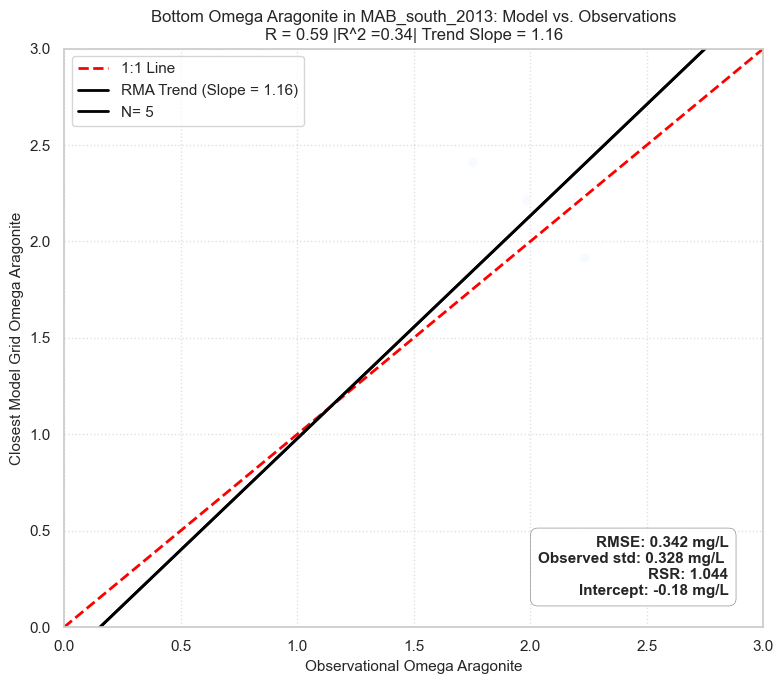

Mean of delta difference between model 3x3x3 grid data and observational data in MAB_south_2015 is: 0.1575
Mean of delta difference between model exact grid data and observational data in MAB_south_2015 is: 0.1725
Global RMSE (3x3x3 grid vs obs) between model and observations in MAB_south_2015 is: 0.2572
Global RMSE (Exact point vs Obs) between model and observations in MAB_south_2015 is: 0.3772
-> Calculated using 12 valid exact points in MAB_south_2015 (out of 12 total pairs).
Calculated Observational Mean: 1.9425
Calculated Model Global Mean: 2.1134
Calculated Global Std Dev: 0.3899
Model grid overestimates the data 66.67 percent of the time
Model grid underestimates the data 33.33 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.2579
When underestimating, the average deficit aragonite (Ω) is: -0.0431
Real-World Observational STD: 0.2623
Model Global STD: 0.3899
Model-to-Observation Variance Ratio: 1.49
Model Grid RSR: 0.9806


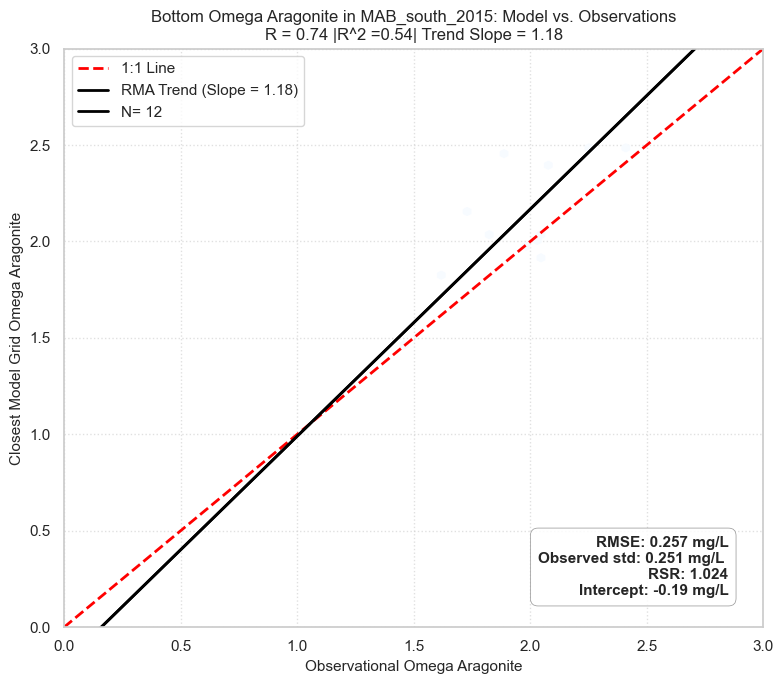

Mean of delta difference between model 3x3x3 grid data and observational data in MAB_south_2016 is: 0.4626
Mean of delta difference between model exact grid data and observational data in MAB_south_2016 is: 0.5390
Global RMSE (3x3x3 grid vs obs) between model and observations in MAB_south_2016 is: 0.6623
Global RMSE (Exact point vs Obs) between model and observations in MAB_south_2016 is: 0.8721
-> Calculated using 10 valid exact points in MAB_south_2016 (out of 10 total pairs).
Calculated Observational Mean: 1.5650
Calculated Model Global Mean: 2.1277
Calculated Global Std Dev: 0.5767
Model grid overestimates the data 80.00 percent of the time
Model grid underestimates the data 20.00 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.5815
When underestimating, the average deficit aragonite (Ω) is: -0.0131
Real-World Observational STD: 0.4336
Model Global STD: 0.5767
Model-to-Observation Variance Ratio: 1.33
Model Grid RSR: 1.5275

ARAGONITE STRESSED STATUS

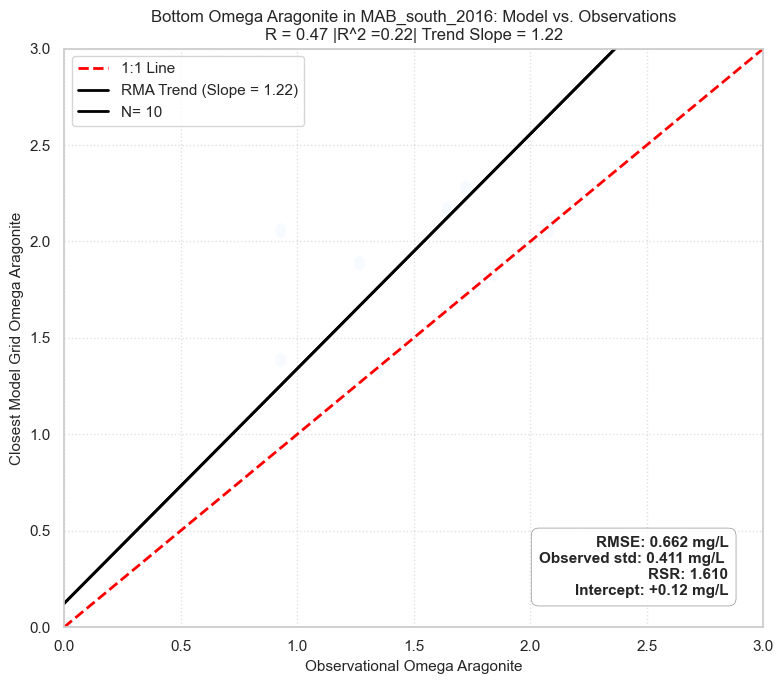

Mean of delta difference between model 3x3x3 grid data and observational data in MAB_south_2017 is: 0.2346
Mean of delta difference between model exact grid data and observational data in MAB_south_2017 is: 0.3950
Global RMSE (3x3x3 grid vs obs) between model and observations in MAB_south_2017 is: 0.3490
Global RMSE (Exact point vs Obs) between model and observations in MAB_south_2017 is: 0.4816
-> Calculated using 9 valid exact points in MAB_south_2017 (out of 9 total pairs).
Calculated Observational Mean: 1.7022
Calculated Model Global Mean: 2.1429
Calculated Global Std Dev: 0.4724
Model grid overestimates the data 100.00 percent of the time
Model grid underestimates the data 0.00 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.2346
When underestimating, the average deficit aragonite (Ω) is: nan
Real-World Observational STD: 0.3114
Model Global STD: 0.4724
Model-to-Observation Variance Ratio: 1.52
Model Grid RSR: 1.1206

ARAGONITE STRESSED STATUS MATCH

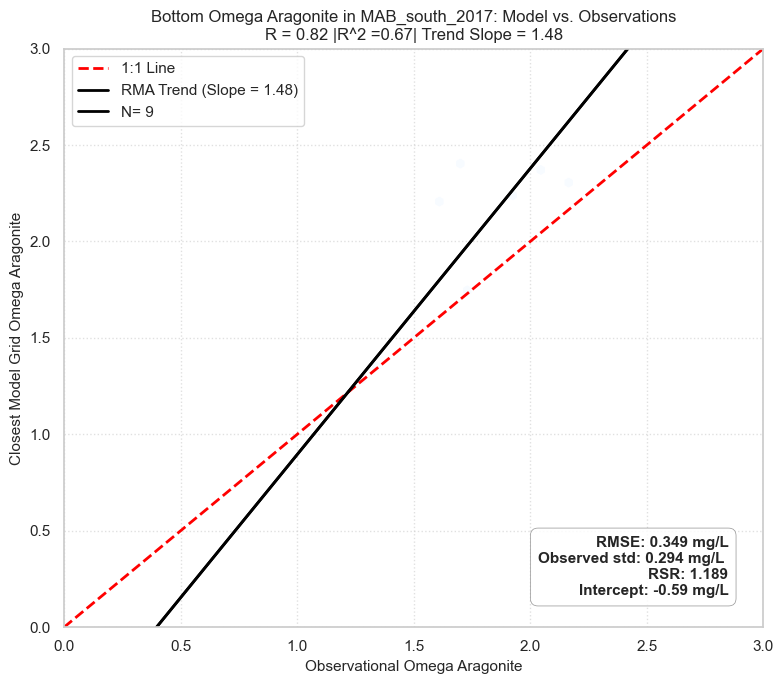

Mean of delta difference between model 3x3x3 grid data and observational data in MAB_south_2018 is: 0.3974
Mean of delta difference between model exact grid data and observational data in MAB_south_2018 is: 0.4317
Global RMSE (3x3x3 grid vs obs) between model and observations in MAB_south_2018 is: 0.5277
Global RMSE (Exact point vs Obs) between model and observations in MAB_south_2018 is: 0.6504
-> Calculated using 13 valid exact points in MAB_south_2018 (out of 13 total pairs).
Calculated Observational Mean: 1.7815
Calculated Model Global Mean: 2.1977
Calculated Global Std Dev: 0.4133
Model grid overestimates the data 92.31 percent of the time
Model grid underestimates the data 7.69 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.4310
When underestimating, the average deficit aragonite (Ω) is: -0.0060
Real-World Observational STD: 0.2180
Model Global STD: 0.4133
Model-to-Observation Variance Ratio: 1.90
Model Grid RSR: 2.4207


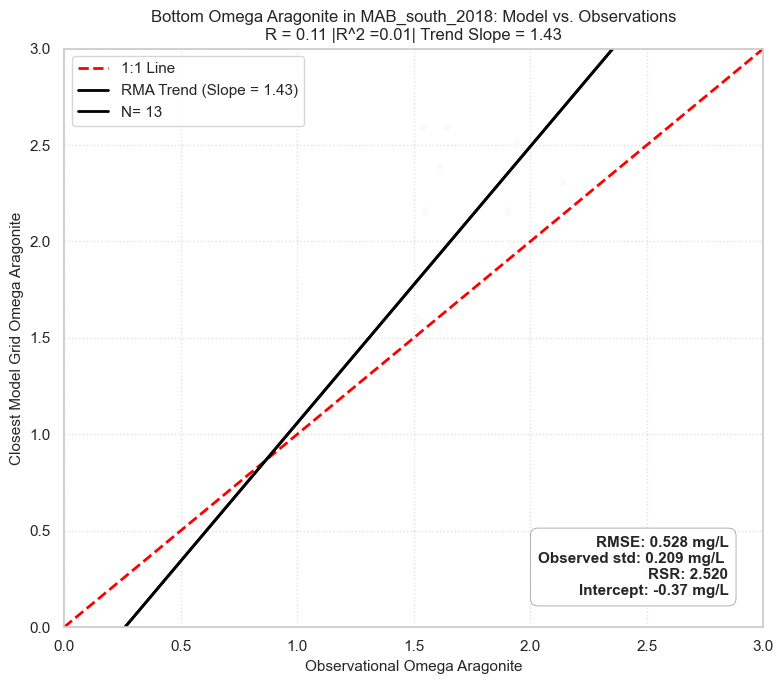

Mean of delta difference between model 3x3x3 grid data and observational data in MAB_south_2019 is: 0.4015
Mean of delta difference between model exact grid data and observational data in MAB_south_2019 is: 0.4995
Global RMSE (3x3x3 grid vs obs) between model and observations in MAB_south_2019 is: 0.5754
Global RMSE (Exact point vs Obs) between model and observations in MAB_south_2019 is: 0.7113
-> Calculated using 19 valid exact points in MAB_south_2019 (out of 19 total pairs).
Calculated Observational Mean: 1.6537
Calculated Model Global Mean: 2.1527
Calculated Global Std Dev: 0.6060
Model grid overestimates the data 68.42 percent of the time
Model grid underestimates the data 31.58 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.6164
When underestimating, the average deficit aragonite (Ω) is: -0.0640
Real-World Observational STD: 0.5433
Model Global STD: 0.6060
Model-to-Observation Variance Ratio: 1.12
Model Grid RSR: 1.0590

ARAGONITE STRESSED STATUS

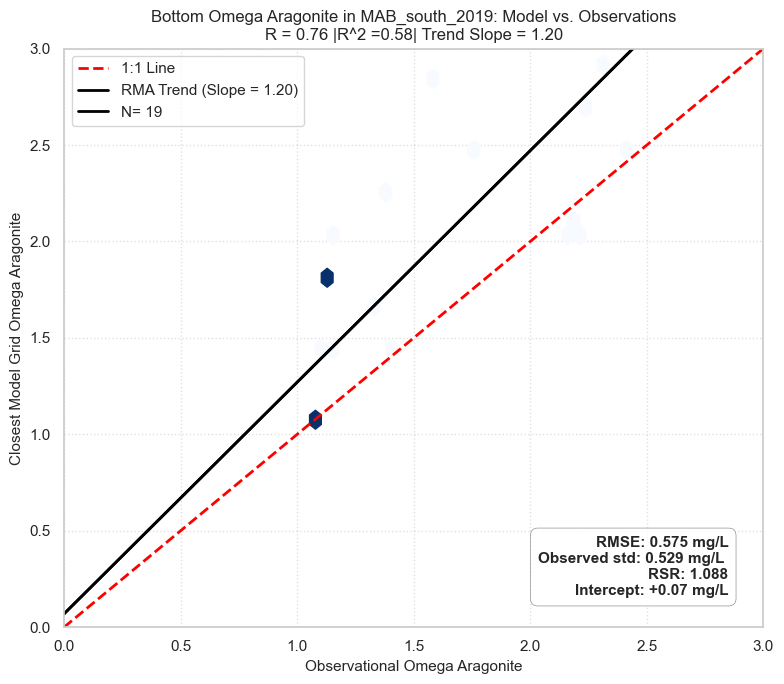

Mean of delta difference between model 3x3x3 grid data and observational data in MAB_south_2021 is: 0.0388
Mean of delta difference between model exact grid data and observational data in MAB_south_2021 is: 0.0432
Global RMSE (3x3x3 grid vs obs) between model and observations in MAB_south_2021 is: 0.2806
Global RMSE (Exact point vs Obs) between model and observations in MAB_south_2021 is: 0.3595
-> Calculated using 415 valid exact points in MAB_south_2021 (out of 415 total pairs).
Calculated Observational Mean: 1.8936
Calculated Model Global Mean: 1.9323
Calculated Global Std Dev: 0.2003
Model grid overestimates the data 65.54 percent of the time
Model grid underestimates the data 34.46 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.1650
When underestimating, the average deficit aragonite (Ω) is: -0.2014
Real-World Observational STD: 0.3300
Model Global STD: 0.2003
Model-to-Observation Variance Ratio: 0.61
Model Grid RSR: 0.8502

ARAGONITE STRESSED STAT

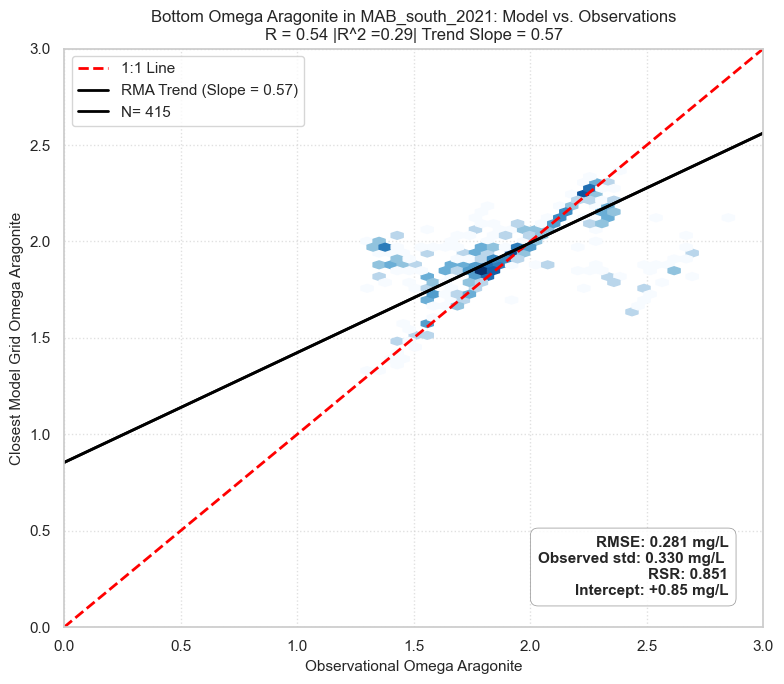

Mean of delta difference between model 3x3x3 grid data and observational data in MAB_south_2022 is: 0.0574
Mean of delta difference between model exact grid data and observational data in MAB_south_2022 is: 0.0611
Global RMSE (3x3x3 grid vs obs) between model and observations in MAB_south_2022 is: 0.2677
Global RMSE (Exact point vs Obs) between model and observations in MAB_south_2022 is: 0.4175
-> Calculated using 121 valid exact points in MAB_south_2022 (out of 121 total pairs).
Calculated Observational Mean: 2.0542
Calculated Model Global Mean: 2.0956
Calculated Global Std Dev: 0.4004
Model grid overestimates the data 63.64 percent of the time
Model grid underestimates the data 36.36 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.1613
When underestimating, the average deficit aragonite (Ω) is: -0.1244
Real-World Observational STD: 0.3766
Model Global STD: 0.4004
Model-to-Observation Variance Ratio: 1.06
Model Grid RSR: 0.7108

ARAGONITE STRESSED STAT

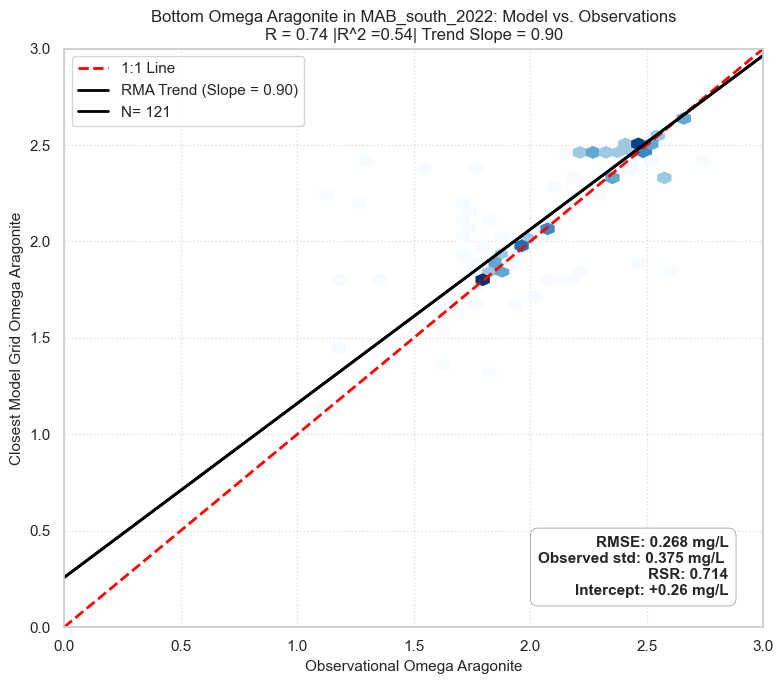

Mean of delta difference between model 3x3x3 grid data and observational data in MAB_south_2023 is: 0.3035
Mean of delta difference between model exact grid data and observational data in MAB_south_2023 is: 0.3597
Global RMSE (3x3x3 grid vs obs) between model and observations in MAB_south_2023 is: 0.4539
Global RMSE (Exact point vs Obs) between model and observations in MAB_south_2023 is: 0.5462
-> Calculated using 394 valid exact points in MAB_south_2023 (out of 394 total pairs).
Calculated Observational Mean: 1.7257
Calculated Model Global Mean: 2.0815
Calculated Global Std Dev: 0.2195
Model grid overestimates the data 79.70 percent of the time
Model grid underestimates the data 20.30 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.4072
When underestimating, the average deficit aragonite (Ω) is: -0.1035
Real-World Observational STD: 0.4513
Model Global STD: 0.2195
Model-to-Observation Variance Ratio: 0.49
Model Grid RSR: 1.0056

ARAGONITE STRESSED STAT

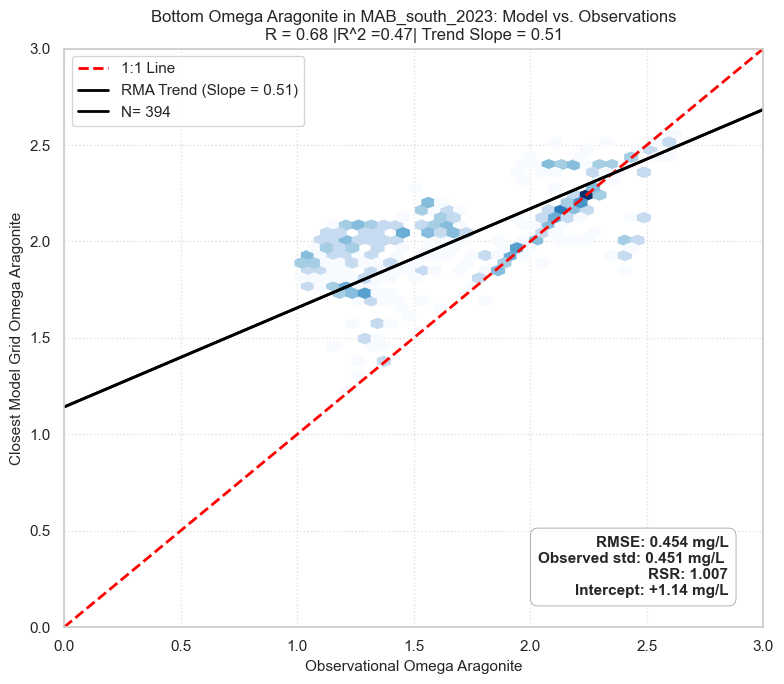

Mean of delta difference between model 3x3x3 grid data and observational data in MAB_south_2024 is: 0.7190
Mean of delta difference between model exact grid data and observational data in MAB_south_2024 is: 0.8330
Global RMSE (3x3x3 grid vs obs) between model and observations in MAB_south_2024 is: 0.8424
Global RMSE (Exact point vs Obs) between model and observations in MAB_south_2024 is: 0.9406
-> Calculated using 535 valid exact points in MAB_south_2024 (out of 535 total pairs).
Calculated Observational Mean: 1.4093
Calculated Model Global Mean: 2.2343
Calculated Global Std Dev: 0.2439
Model grid overestimates the data 94.77 percent of the time
Model grid underestimates the data 5.23 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.7616
When underestimating, the average deficit aragonite (Ω) is: -0.0517
Real-World Observational STD: 0.4268
Model Global STD: 0.2439
Model-to-Observation Variance Ratio: 0.57
Model Grid RSR: 1.9739

ARAGONITE STRESSED STATU

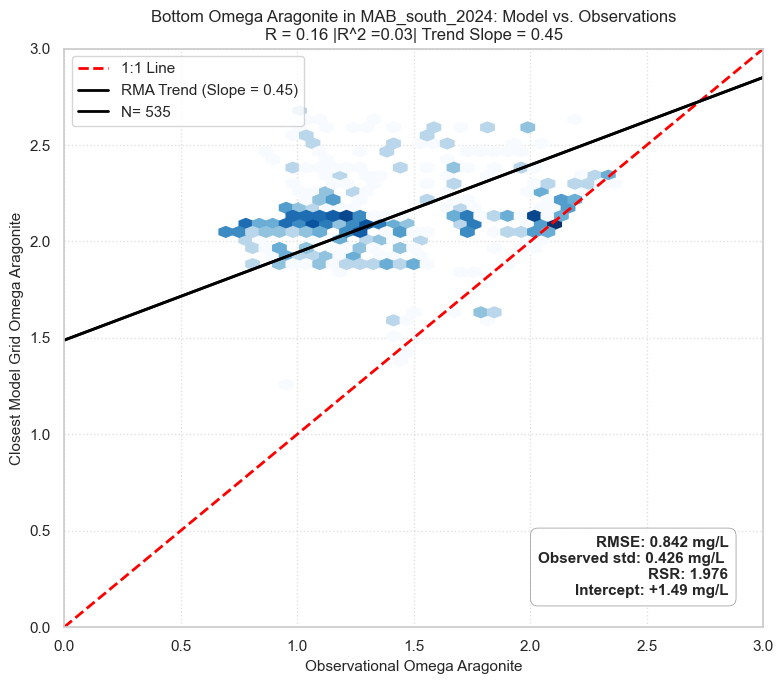

Mean of delta difference between model 3x3x3 grid data and observational data in MAB_south_2025 is: 0.6010
Mean of delta difference between model exact grid data and observational data in MAB_south_2025 is: 0.6931
Global RMSE (3x3x3 grid vs obs) between model and observations in MAB_south_2025 is: 0.6708
Global RMSE (Exact point vs Obs) between model and observations in MAB_south_2025 is: 0.7720
-> Calculated using 250 valid exact points in MAB_south_2025 (out of 250 total pairs).
Calculated Observational Mean: 1.5137
Calculated Model Global Mean: 2.2025
Calculated Global Std Dev: 0.2165
Model grid overestimates the data 95.20 percent of the time
Model grid underestimates the data 4.80 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.6470
When underestimating, the average deficit aragonite (Ω) is: -0.3103
Real-World Observational STD: 0.2622
Model Global STD: 0.2165
Model-to-Observation Variance Ratio: 0.83
Model Grid RSR: 2.5583

ARAGONITE STRESSED STATU

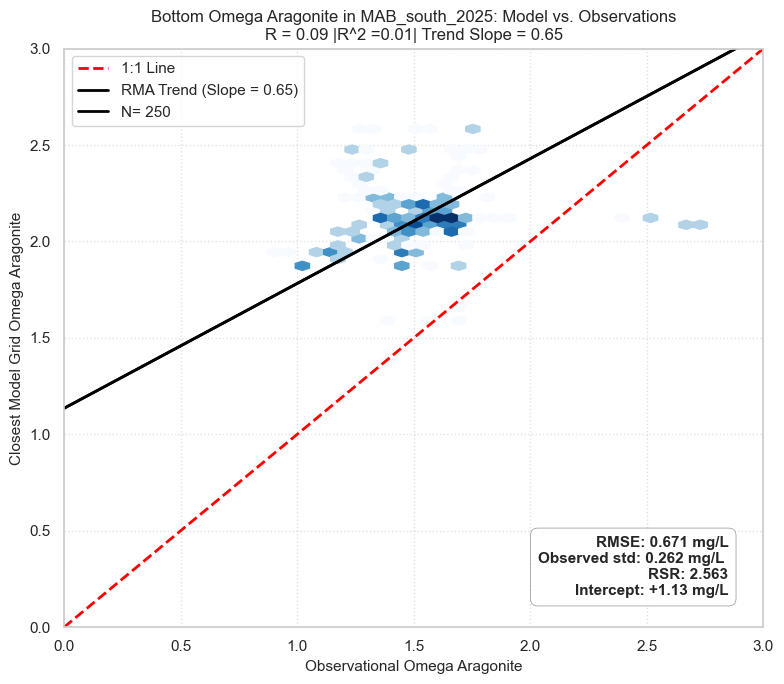

Mean of delta difference between model 3x3x3 grid data and observational data in MAB_north_2007 is: -0.0061
Mean of delta difference between model exact grid data and observational data in MAB_north_2007 is: 0.0866
Global RMSE (3x3x3 grid vs obs) between model and observations in MAB_north_2007 is: 0.0248
Global RMSE (Exact point vs Obs) between model and observations in MAB_north_2007 is: 0.2236
-> Calculated using 3 valid exact points in MAB_north_2007 (out of 3 total pairs).
Calculated Observational Mean: 1.6800
Calculated Model Global Mean: 1.7048
Calculated Global Std Dev: 0.2073
Model grid overestimates the data 33.33 percent of the time
Model grid underestimates the data 66.67 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.0267
When underestimating, the average deficit aragonite (Ω) is: -0.0226
Real-World Observational STD: 0.0436
Model Global STD: 0.2073
Model-to-Observation Variance Ratio: 4.76
Model Grid RSR: 0.5696


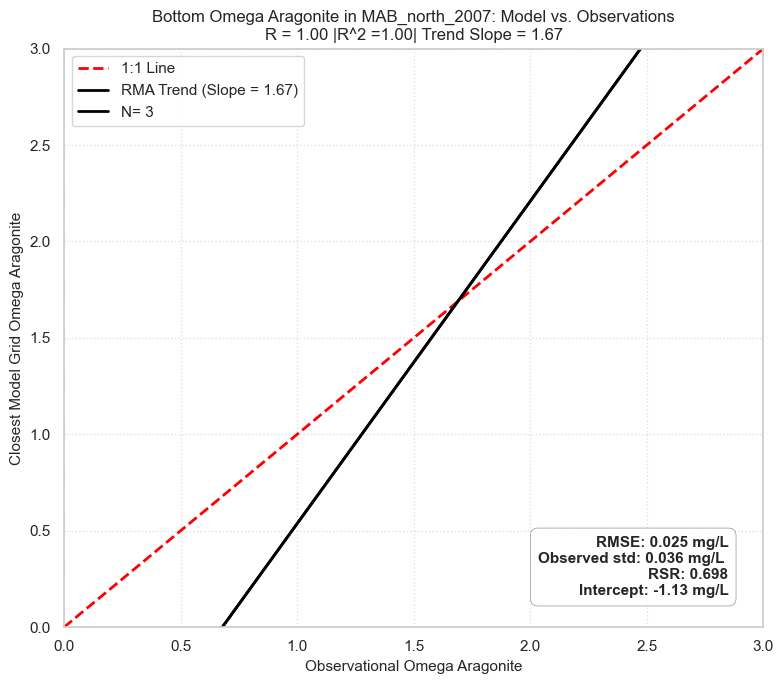

Mean of delta difference between model 3x3x3 grid data and observational data in MAB_north_2012 is: -0.0162
Mean of delta difference between model exact grid data and observational data in MAB_north_2012 is: -0.1202
Global RMSE (3x3x3 grid vs obs) between model and observations in MAB_north_2012 is: 0.0954
Global RMSE (Exact point vs Obs) between model and observations in MAB_north_2012 is: 0.2755
-> Calculated using 8 valid exact points in MAB_north_2012 (out of 8 total pairs).
Calculated Observational Mean: 1.8344
Calculated Model Global Mean: 1.7030
Calculated Global Std Dev: 0.1676
Model grid overestimates the data 62.50 percent of the time
Model grid underestimates the data 37.50 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.0445
When underestimating, the average deficit aragonite (Ω) is: -0.1173
Real-World Observational STD: 0.2230
Model Global STD: 0.1676
Model-to-Observation Variance Ratio: 0.75
Model Grid RSR: 0.4277


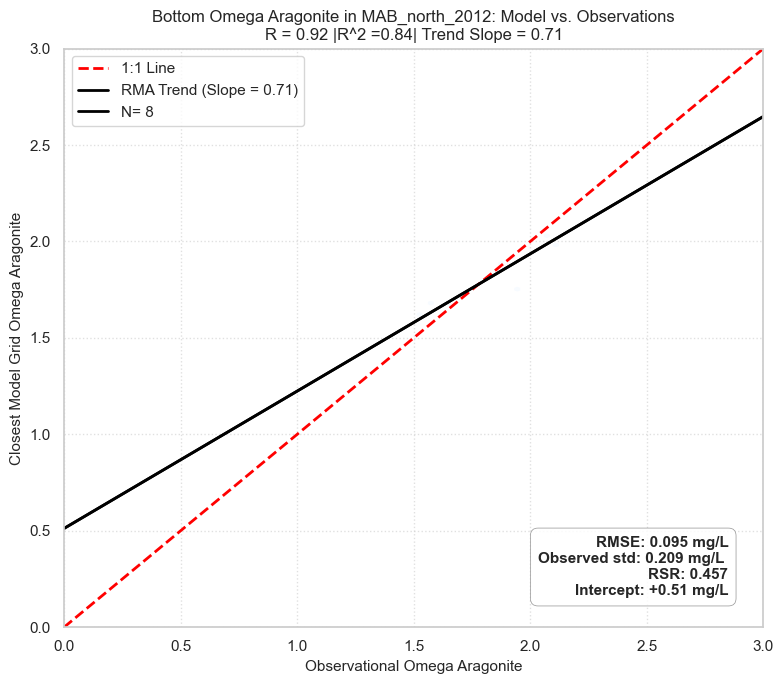

Mean of delta difference between model 3x3x3 grid data and observational data in MAB_north_2013 is: 0.0729
Mean of delta difference between model exact grid data and observational data in MAB_north_2013 is: 0.0833
Global RMSE (3x3x3 grid vs obs) between model and observations in MAB_north_2013 is: 0.1484
Global RMSE (Exact point vs Obs) between model and observations in MAB_north_2013 is: 0.1982
-> Calculated using 5 valid exact points in MAB_north_2013 (out of 5 total pairs).
Calculated Observational Mean: 1.7460
Calculated Model Global Mean: 1.7945
Calculated Global Std Dev: 0.1702
Model grid overestimates the data 40.00 percent of the time
Model grid underestimates the data 60.00 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.2150
When underestimating, the average deficit aragonite (Ω) is: -0.0218
Real-World Observational STD: 0.2192
Model Global STD: 0.1702
Model-to-Observation Variance Ratio: 0.78
Model Grid RSR: 0.6774


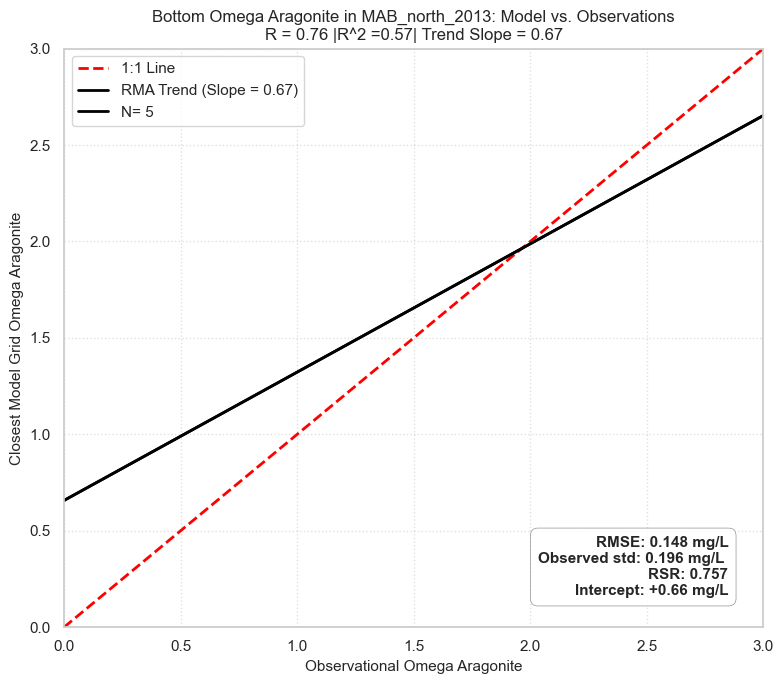

Mean of delta difference between model 3x3x3 grid data and observational data in MAB_north_2014 is: 0.1190
Mean of delta difference between model exact grid data and observational data in MAB_north_2014 is: 0.2080
Global RMSE (3x3x3 grid vs obs) between model and observations in MAB_north_2014 is: 0.1520
Global RMSE (Exact point vs Obs) between model and observations in MAB_north_2014 is: 0.2101
-> Calculated using 5 valid exact points in MAB_north_2014 (out of 5 total pairs).
Calculated Observational Mean: 1.7360
Calculated Model Global Mean: 1.9176
Calculated Global Std Dev: 0.2393
Model grid overestimates the data 80.00 percent of the time
Model grid underestimates the data 20.00 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.1519
When underestimating, the average deficit aragonite (Ω) is: -0.0123
Real-World Observational STD: 0.2261
Model Global STD: 0.2393
Model-to-Observation Variance Ratio: 1.06
Model Grid RSR: 0.6722


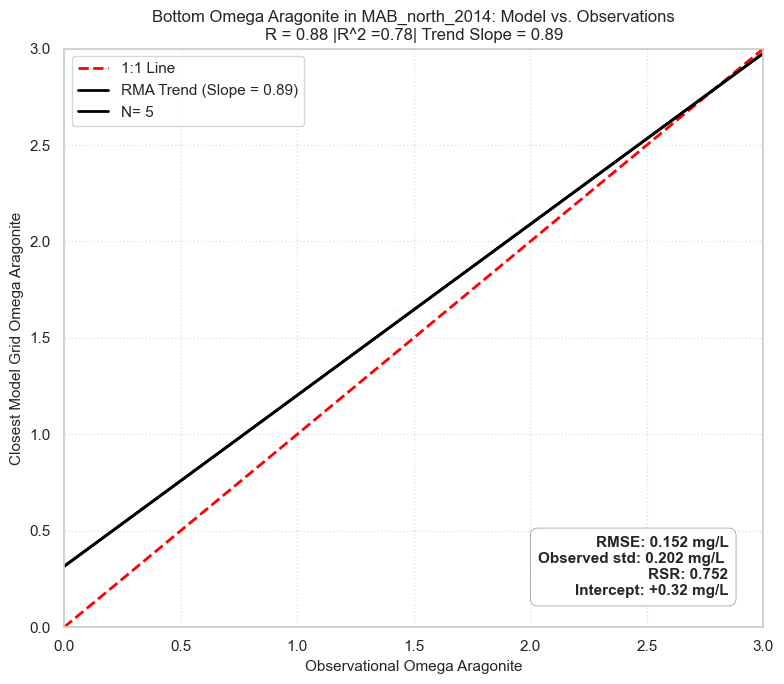

Mean of delta difference between model 3x3x3 grid data and observational data in MAB_north_2015 is: 0.1202
Mean of delta difference between model exact grid data and observational data in MAB_north_2015 is: 0.1310
Global RMSE (3x3x3 grid vs obs) between model and observations in MAB_north_2015 is: 0.2634
Global RMSE (Exact point vs Obs) between model and observations in MAB_north_2015 is: 0.2978
-> Calculated using 10 valid exact points in MAB_north_2015 (out of 10 total pairs).
Calculated Observational Mean: 1.8540
Calculated Model Global Mean: 1.9836
Calculated Global Std Dev: 0.2722
Model grid overestimates the data 80.00 percent of the time
Model grid underestimates the data 20.00 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.1802
When underestimating, the average deficit aragonite (Ω) is: -0.1199
Real-World Observational STD: 0.3840
Model Global STD: 0.2722
Model-to-Observation Variance Ratio: 0.71
Model Grid RSR: 0.6860

ARAGONITE STRESSED STATUS

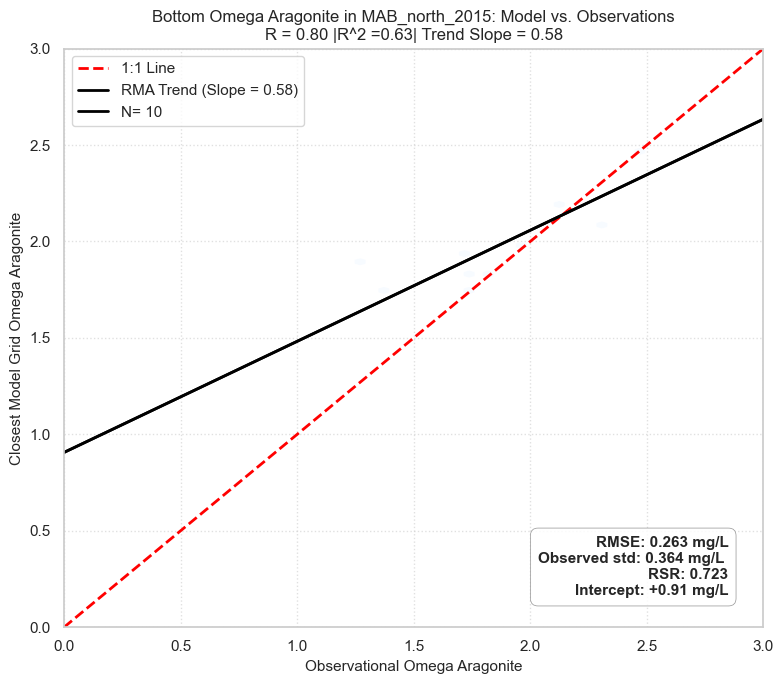

Mean of delta difference between model 3x3x3 grid data and observational data in MAB_north_2016 is: 0.1492
Mean of delta difference between model exact grid data and observational data in MAB_north_2016 is: 0.1001
Global RMSE (3x3x3 grid vs obs) between model and observations in MAB_north_2016 is: 0.2994
Global RMSE (Exact point vs Obs) between model and observations in MAB_north_2016 is: 0.3826
-> Calculated using 8 valid exact points in MAB_north_2016 (out of 8 total pairs).
Calculated Observational Mean: 1.7612
Calculated Model Global Mean: 1.8541
Calculated Global Std Dev: 0.2080
Model grid overestimates the data 62.50 percent of the time
Model grid underestimates the data 37.50 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.3204
When underestimating, the average deficit aragonite (Ω) is: -0.1361
Real-World Observational STD: 0.4929
Model Global STD: 0.2080
Model-to-Observation Variance Ratio: 0.42
Model Grid RSR: 0.6075

ARAGONITE STRESSED STATUS M

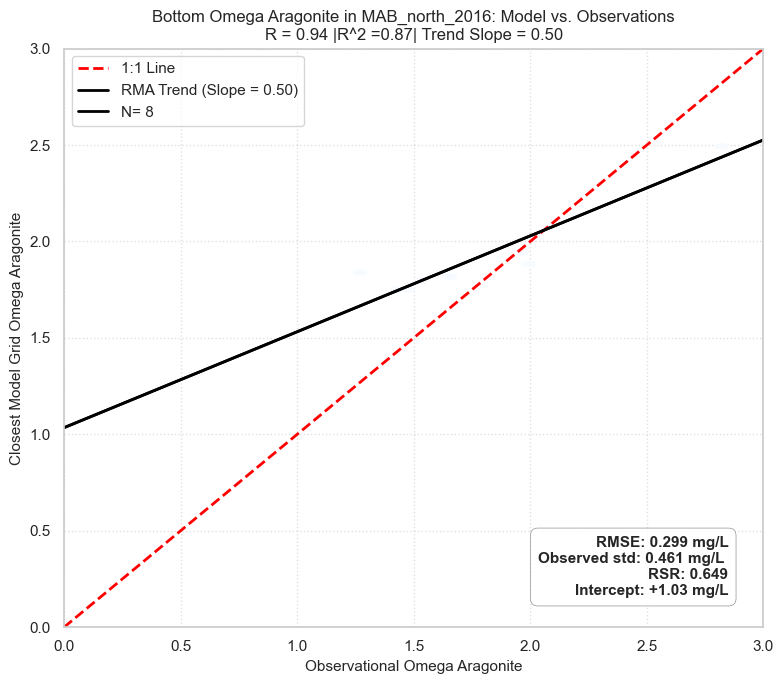

Mean of delta difference between model 3x3x3 grid data and observational data in MAB_north_2017 is: 0.0842
Mean of delta difference between model exact grid data and observational data in MAB_north_2017 is: 0.1817
Global RMSE (3x3x3 grid vs obs) between model and observations in MAB_north_2017 is: 0.1701
Global RMSE (Exact point vs Obs) between model and observations in MAB_north_2017 is: 0.3353
-> Calculated using 5 valid exact points in MAB_north_2017 (out of 5 total pairs).
Calculated Observational Mean: 1.7200
Calculated Model Global Mean: 1.8347
Calculated Global Std Dev: 0.2920
Model grid overestimates the data 60.00 percent of the time
Model grid underestimates the data 40.00 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.1978
When underestimating, the average deficit aragonite (Ω) is: -0.0863
Real-World Observational STD: 0.1498
Model Global STD: 0.2920
Model-to-Observation Variance Ratio: 1.95
Model Grid RSR: 1.1354


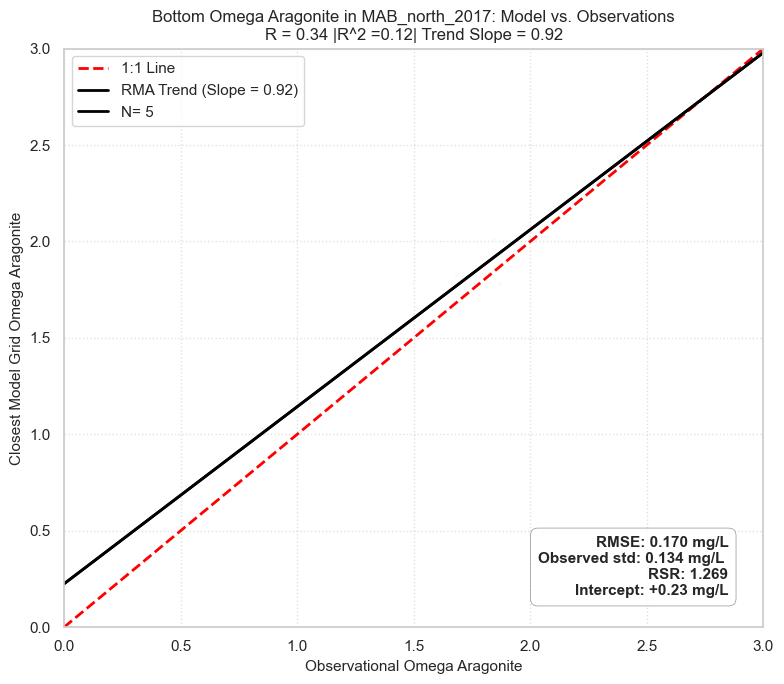

Mean of delta difference between model 3x3x3 grid data and observational data in MAB_north_2018 is: 0.2213
Mean of delta difference between model exact grid data and observational data in MAB_north_2018 is: 0.3010
Global RMSE (3x3x3 grid vs obs) between model and observations in MAB_north_2018 is: 0.3135
Global RMSE (Exact point vs Obs) between model and observations in MAB_north_2018 is: 0.4623
-> Calculated using 25 valid exact points in MAB_north_2018 (out of 25 total pairs).
Calculated Observational Mean: 1.5682
Calculated Model Global Mean: 1.8837
Calculated Global Std Dev: 0.3681
Model grid overestimates the data 88.00 percent of the time
Model grid underestimates the data 12.00 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.2520
When underestimating, the average deficit aragonite (Ω) is: -0.0038
Real-World Observational STD: 0.2329
Model Global STD: 0.3681
Model-to-Observation Variance Ratio: 1.58
Model Grid RSR: 1.3462

ARAGONITE STRESSED STATUS

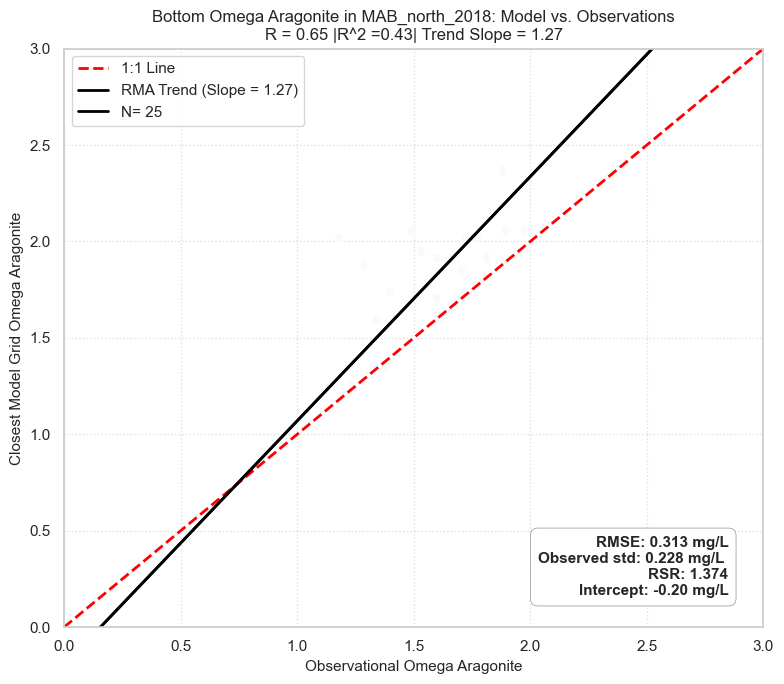

Mean of delta difference between model 3x3x3 grid data and observational data in MAB_north_2019 is: 0.2625
Mean of delta difference between model exact grid data and observational data in MAB_north_2019 is: 0.4212
Global RMSE (3x3x3 grid vs obs) between model and observations in MAB_north_2019 is: 0.4372
Global RMSE (Exact point vs Obs) between model and observations in MAB_north_2019 is: 0.5590
-> Calculated using 34 valid exact points in MAB_north_2019 (out of 34 total pairs).
Calculated Observational Mean: 1.3635
Calculated Model Global Mean: 1.7547
Calculated Global Std Dev: 0.3221
Model grid overestimates the data 67.65 percent of the time
Model grid underestimates the data 32.35 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.4166
When underestimating, the average deficit aragonite (Ω) is: -0.0598
Real-World Observational STD: 0.4188
Model Global STD: 0.3221
Model-to-Observation Variance Ratio: 0.77
Model Grid RSR: 1.0439

ARAGONITE STRESSED STATUS

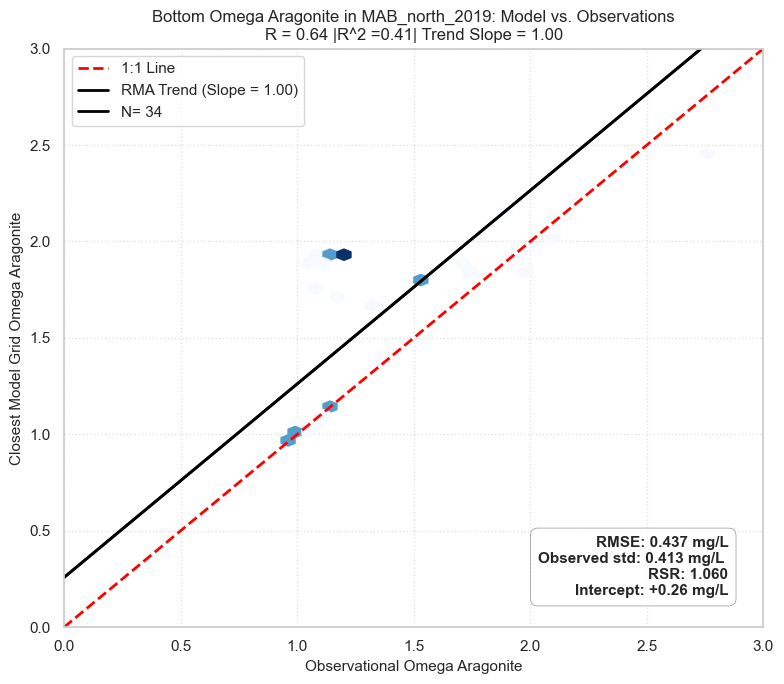

Mean of delta difference between model 3x3x3 grid data and observational data in MAB_north_2021 is: 0.0172
Mean of delta difference between model exact grid data and observational data in MAB_north_2021 is: 0.0174
Global RMSE (3x3x3 grid vs obs) between model and observations in MAB_north_2021 is: 0.2864
Global RMSE (Exact point vs Obs) between model and observations in MAB_north_2021 is: 0.3359
-> Calculated using 339 valid exact points in MAB_north_2021 (out of 339 total pairs).
Calculated Observational Mean: 1.7692
Calculated Model Global Mean: 1.7888
Calculated Global Std Dev: 0.1760
Model grid overestimates the data 57.23 percent of the time
Model grid underestimates the data 42.77 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.1891
When underestimating, the average deficit aragonite (Ω) is: -0.2128
Real-World Observational STD: 0.3846
Model Global STD: 0.1760
Model-to-Observation Variance Ratio: 0.46
Model Grid RSR: 0.7448

ARAGONITE STRESSED STAT

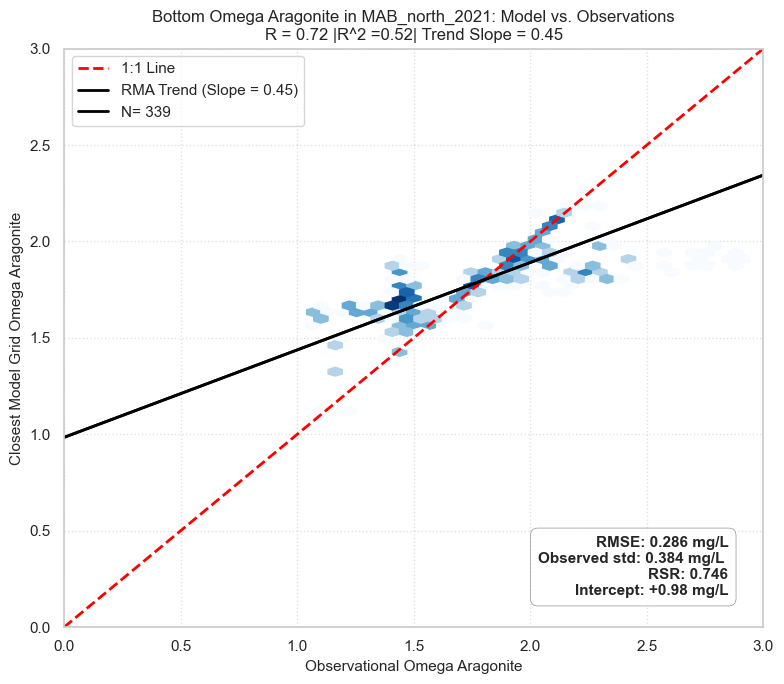

Mean of delta difference between model 3x3x3 grid data and observational data in MAB_north_2022 is: 0.1549
Mean of delta difference between model exact grid data and observational data in MAB_north_2022 is: 0.1846
Global RMSE (3x3x3 grid vs obs) between model and observations in MAB_north_2022 is: 0.3249
Global RMSE (Exact point vs Obs) between model and observations in MAB_north_2022 is: 0.4185
-> Calculated using 309 valid exact points in MAB_north_2022 (out of 309 total pairs).
Calculated Observational Mean: 1.6419
Calculated Model Global Mean: 1.8280
Calculated Global Std Dev: 0.2637
Model grid overestimates the data 73.46 percent of the time
Model grid underestimates the data 26.54 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.2735
When underestimating, the average deficit aragonite (Ω) is: -0.1734
Real-World Observational STD: 0.3559
Model Global STD: 0.2637
Model-to-Observation Variance Ratio: 0.74
Model Grid RSR: 0.9126

ARAGONITE STRESSED STAT

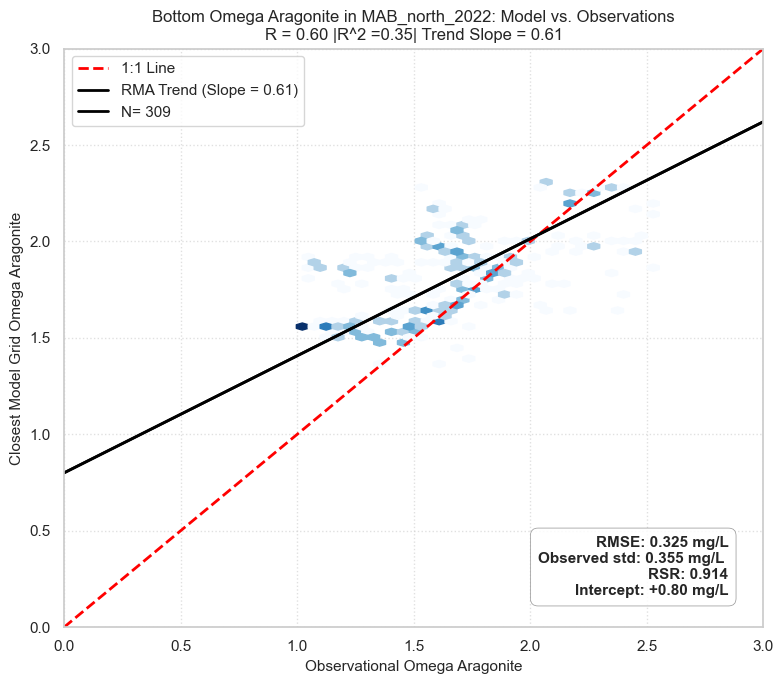

Mean of delta difference between model 3x3x3 grid data and observational data in MAB_north_2023 is: 0.4290
Mean of delta difference between model exact grid data and observational data in MAB_north_2023 is: 0.4923
Global RMSE (3x3x3 grid vs obs) between model and observations in MAB_north_2023 is: 0.5162
Global RMSE (Exact point vs Obs) between model and observations in MAB_north_2023 is: 0.5796
-> Calculated using 506 valid exact points in MAB_north_2023 (out of 506 total pairs).
Calculated Observational Mean: 1.3375
Calculated Model Global Mean: 1.8263
Calculated Global Std Dev: 0.1639
Model grid overestimates the data 90.71 percent of the time
Model grid underestimates the data 9.29 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.4810
When underestimating, the average deficit aragonite (Ω) is: -0.0786
Real-World Observational STD: 0.3124
Model Global STD: 0.1639
Model-to-Observation Variance Ratio: 0.52
Model Grid RSR: 1.6524

ARAGONITE STRESSED STATU

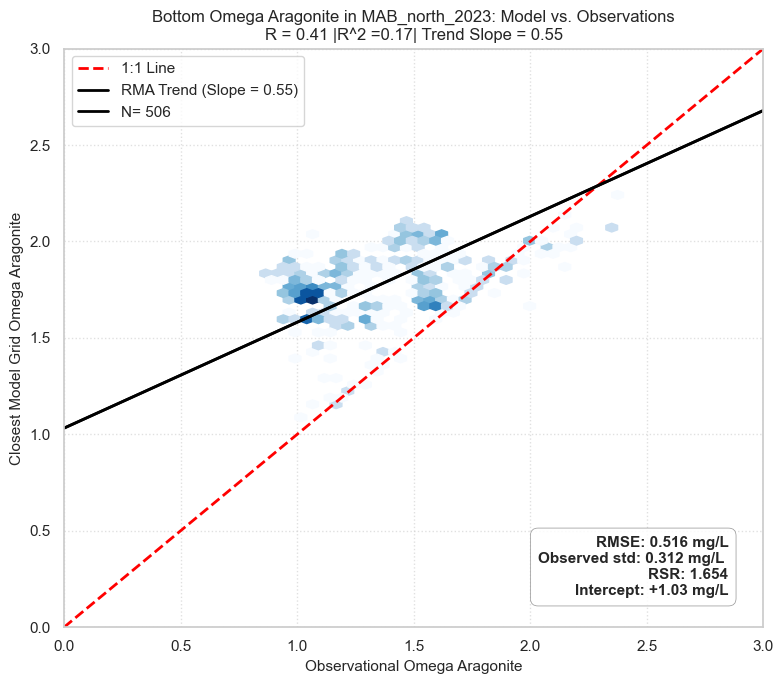

Mean of delta difference between model 3x3x3 grid data and observational data in MAB_north_2024 is: 0.8223
Mean of delta difference between model exact grid data and observational data in MAB_north_2024 is: 0.8643
Global RMSE (3x3x3 grid vs obs) between model and observations in MAB_north_2024 is: 0.9129
Global RMSE (Exact point vs Obs) between model and observations in MAB_north_2024 is: 0.9481
-> Calculated using 338 valid exact points in MAB_north_2024 (out of 338 total pairs).
Calculated Observational Mean: 1.3243
Calculated Model Global Mean: 2.1831
Calculated Global Std Dev: 0.1018
Model grid overestimates the data 99.41 percent of the time
Model grid underestimates the data 0.59 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.8273
When underestimating, the average deficit aragonite (Ω) is: -0.0166
Real-World Observational STD: 0.3844
Model Global STD: 0.1018
Model-to-Observation Variance Ratio: 0.26
Model Grid RSR: 2.3748

ARAGONITE STRESSED STATU

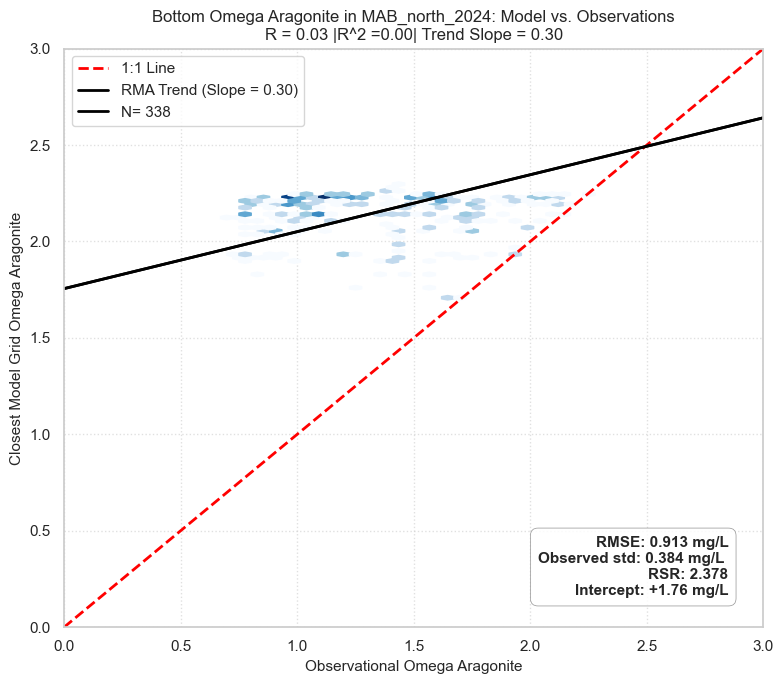

Mean of delta difference between model 3x3x3 grid data and observational data in MAB_north_2025 is: 0.7132
Mean of delta difference between model exact grid data and observational data in MAB_north_2025 is: 0.7686
Global RMSE (3x3x3 grid vs obs) between model and observations in MAB_north_2025 is: 0.7539
Global RMSE (Exact point vs Obs) between model and observations in MAB_north_2025 is: 0.8094
-> Calculated using 211 valid exact points in MAB_north_2025 (out of 211 total pairs).
Calculated Observational Mean: 1.4439
Calculated Model Global Mean: 2.2086
Calculated Global Std Dev: 0.0812
Model grid overestimates the data 100.00 percent of the time
Model grid underestimates the data 0.00 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.7132
When underestimating, the average deficit aragonite (Ω) is: nan
Real-World Observational STD: 0.2360
Model Global STD: 0.0812
Model-to-Observation Variance Ratio: 0.34
Model Grid RSR: 3.1939

ARAGONITE STRESSED STATUS M

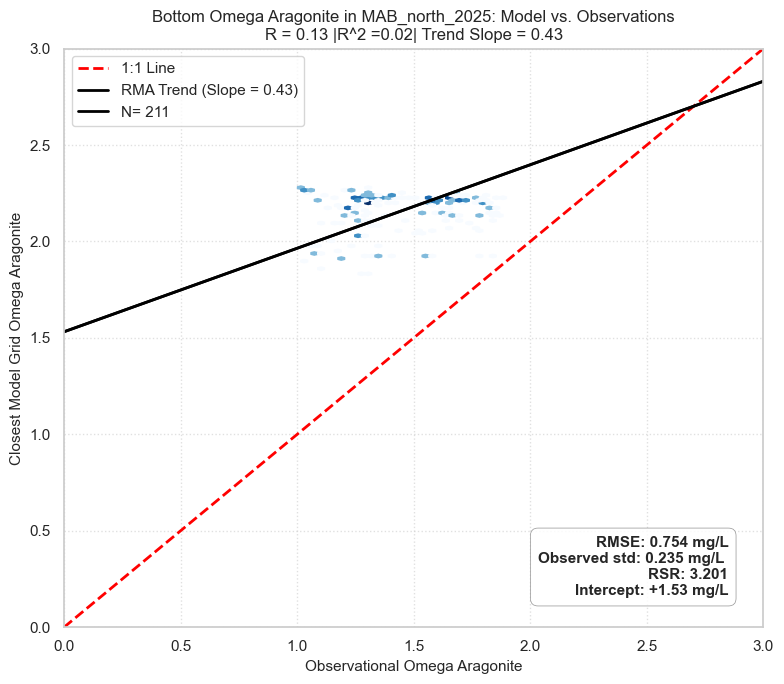

Mean of delta difference between model 3x3x3 grid data and observational data in GB_2013 is: 0.1438
Mean of delta difference between model exact grid data and observational data in GB_2013 is: 0.1164
Global RMSE (3x3x3 grid vs obs) between model and observations in GB_2013 is: 0.1785
Global RMSE (Exact point vs Obs) between model and observations in GB_2013 is: 0.2389
-> Calculated using 3 valid exact points in GB_2013 (out of 3 total pairs).
Calculated Observational Mean: 1.7067
Calculated Model Global Mean: 1.8550
Calculated Global Std Dev: 0.2888
Model grid overestimates the data 100.00 percent of the time
Model grid underestimates the data 0.00 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.1438
When underestimating, the average deficit aragonite (Ω) is: nan
Real-World Observational STD: 0.1686
Model Global STD: 0.2888
Model-to-Observation Variance Ratio: 1.71
Model Grid RSR: 1.0585


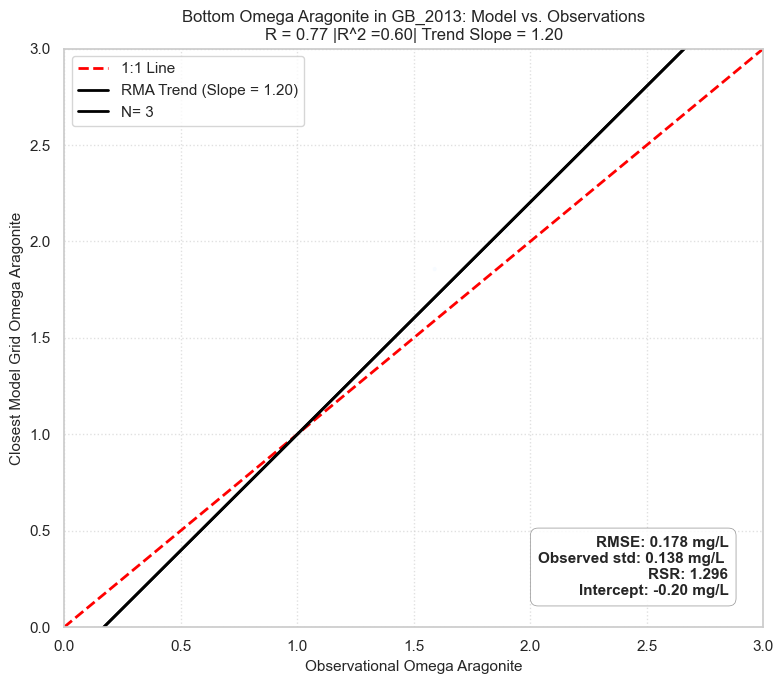

Mean of delta difference between model 3x3x3 grid data and observational data in GB_2014 is: 0.0969
Mean of delta difference between model exact grid data and observational data in GB_2014 is: 0.1081
Global RMSE (3x3x3 grid vs obs) between model and observations in GB_2014 is: 0.1939
Global RMSE (Exact point vs Obs) between model and observations in GB_2014 is: 0.2089
-> Calculated using 3 valid exact points in GB_2014 (out of 3 total pairs).
Calculated Observational Mean: 1.5167
Calculated Model Global Mean: 1.6791
Calculated Global Std Dev: 0.1921
Model grid overestimates the data 66.67 percent of the time
Model grid underestimates the data 33.33 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.1754
When underestimating, the average deficit aragonite (Ω) is: -0.0602
Real-World Observational STD: 0.1365
Model Global STD: 0.1921
Model-to-Observation Variance Ratio: 1.41
Model Grid RSR: 1.4205

ARAGONITE STRESSED STATUS MATCH METRICS (Numeric: Threshold < 

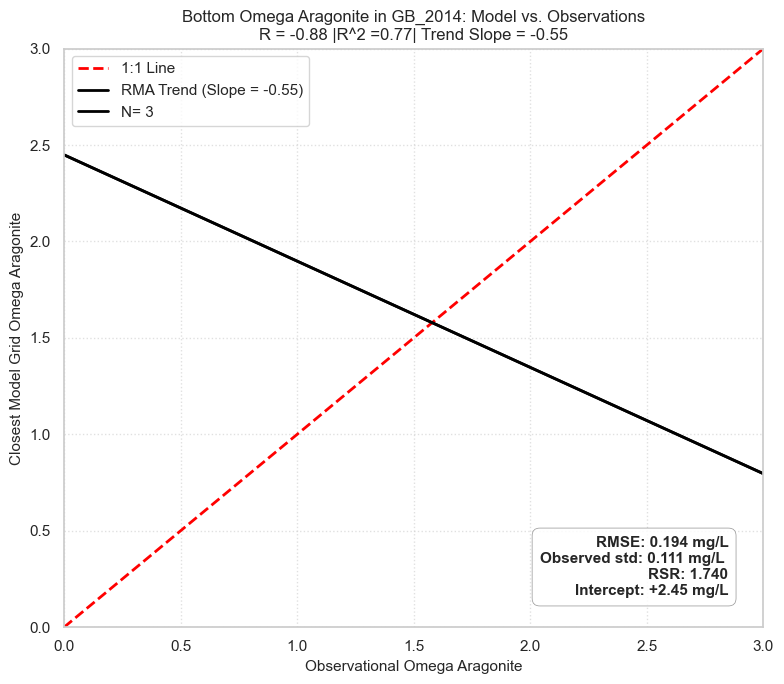

Mean of delta difference between model 3x3x3 grid data and observational data in GB_2015 is: 0.2007
Mean of delta difference between model exact grid data and observational data in GB_2015 is: 0.2440
Global RMSE (3x3x3 grid vs obs) between model and observations in GB_2015 is: 0.2664
Global RMSE (Exact point vs Obs) between model and observations in GB_2015 is: 0.3162
-> Calculated using 7 valid exact points in GB_2015 (out of 7 total pairs).
Calculated Observational Mean: 1.6914
Calculated Model Global Mean: 1.9661
Calculated Global Std Dev: 0.3302
Model grid overestimates the data 85.71 percent of the time
Model grid underestimates the data 14.29 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.2422
When underestimating, the average deficit aragonite (Ω) is: -0.0482
Real-World Observational STD: 0.2040
Model Global STD: 0.3302
Model-to-Observation Variance Ratio: 1.62
Model Grid RSR: 1.3059


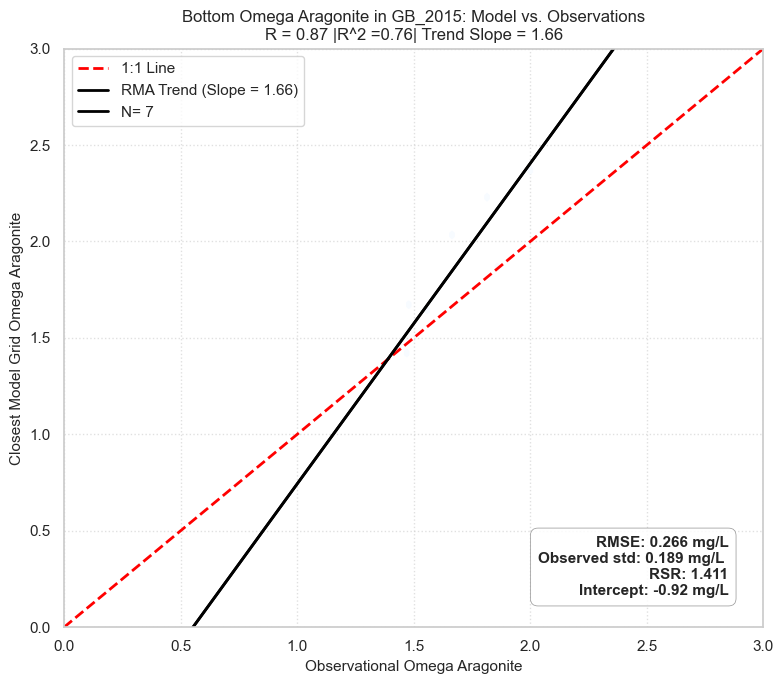

Mean of delta difference between model 3x3x3 grid data and observational data in GB_2016 is: 0.1664
Mean of delta difference between model exact grid data and observational data in GB_2016 is: 0.2392
Global RMSE (3x3x3 grid vs obs) between model and observations in GB_2016 is: 0.2326
Global RMSE (Exact point vs Obs) between model and observations in GB_2016 is: 0.2793
-> Calculated using 5 valid exact points in GB_2016 (out of 5 total pairs).
Calculated Observational Mean: 1.7000
Calculated Model Global Mean: 1.9575
Calculated Global Std Dev: 0.2247
Model grid overestimates the data 80.00 percent of the time
Model grid underestimates the data 20.00 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.2081
When underestimating, the average deficit aragonite (Ω) is: -0.0006
Real-World Observational STD: 0.2684
Model Global STD: 0.2247
Model-to-Observation Variance Ratio: 0.84
Model Grid RSR: 0.8667

ARAGONITE STRESSED STATUS MATCH METRICS (Numeric: Threshold < 

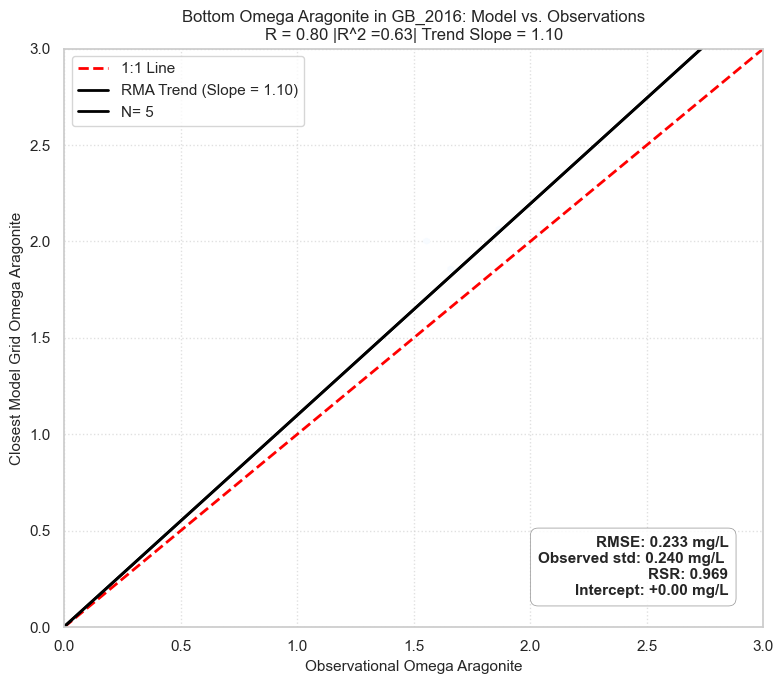

Mean of delta difference between model 3x3x3 grid data and observational data in GB_2017 is: 0.3036
Mean of delta difference between model exact grid data and observational data in GB_2017 is: 0.3916
Global RMSE (3x3x3 grid vs obs) between model and observations in GB_2017 is: 0.3891
Global RMSE (Exact point vs Obs) between model and observations in GB_2017 is: 0.4493
-> Calculated using 7 valid exact points in GB_2017 (out of 7 total pairs).
Calculated Observational Mean: 1.5471
Calculated Model Global Mean: 1.9845
Calculated Global Std Dev: 0.3473
Model grid overestimates the data 85.71 percent of the time
Model grid underestimates the data 14.29 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.3728
When underestimating, the average deficit aragonite (Ω) is: -0.1114
Real-World Observational STD: 0.1440
Model Global STD: 0.3473
Model-to-Observation Variance Ratio: 2.41
Model Grid RSR: 2.7031

ARAGONITE STRESSED STATUS MATCH METRICS (Numeric: Threshold < 

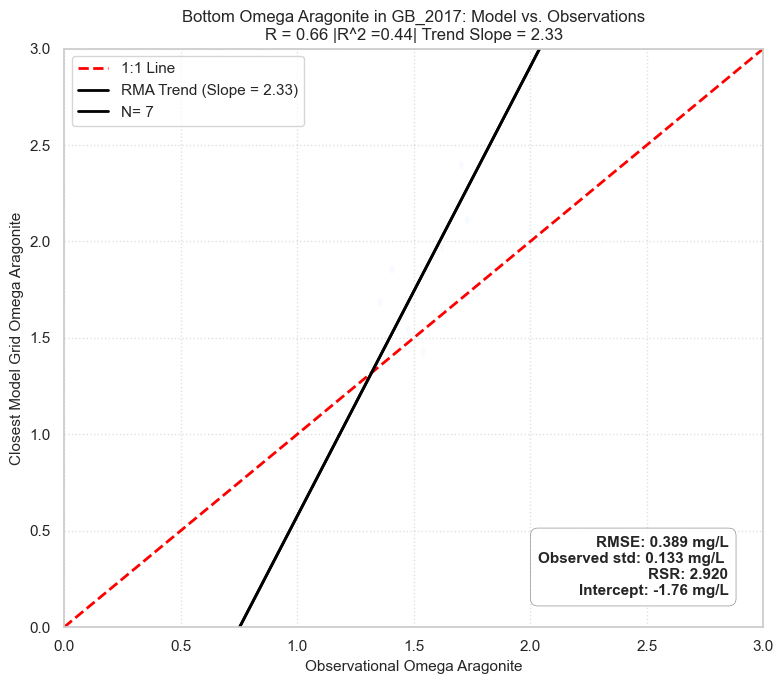

Mean of delta difference between model 3x3x3 grid data and observational data in GB_2018 is: 0.2184
Mean of delta difference between model exact grid data and observational data in GB_2018 is: 0.2097
Global RMSE (3x3x3 grid vs obs) between model and observations in GB_2018 is: 0.2859
Global RMSE (Exact point vs Obs) between model and observations in GB_2018 is: 0.3465
-> Calculated using 13 valid exact points in GB_2018 (out of 13 total pairs).
Calculated Observational Mean: 1.7812
Calculated Model Global Mean: 2.0158
Calculated Global Std Dev: 0.3115
Model grid overestimates the data 100.00 percent of the time
Model grid underestimates the data 0.00 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.2184
When underestimating, the average deficit aragonite (Ω) is: nan
Real-World Observational STD: 0.2262
Model Global STD: 0.3115
Model-to-Observation Variance Ratio: 1.38
Model Grid RSR: 1.2638


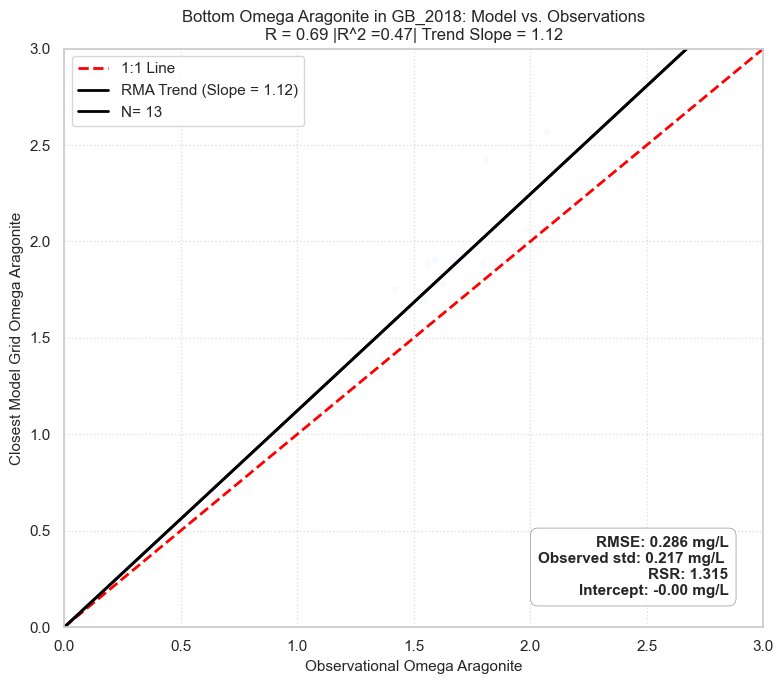

Mean of delta difference between model 3x3x3 grid data and observational data in GB_2019 is: 0.2079
Mean of delta difference between model exact grid data and observational data in GB_2019 is: 0.2382
Global RMSE (3x3x3 grid vs obs) between model and observations in GB_2019 is: 0.2563
Global RMSE (Exact point vs Obs) between model and observations in GB_2019 is: 0.3398
-> Calculated using 7 valid exact points in GB_2019 (out of 7 total pairs).
Calculated Observational Mean: 1.6386
Calculated Model Global Mean: 1.9137
Calculated Global Std Dev: 0.2884
Model grid overestimates the data 100.00 percent of the time
Model grid underestimates the data 0.00 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.2079
When underestimating, the average deficit aragonite (Ω) is: nan
Real-World Observational STD: 0.1632
Model Global STD: 0.2884
Model-to-Observation Variance Ratio: 1.77
Model Grid RSR: 1.5703


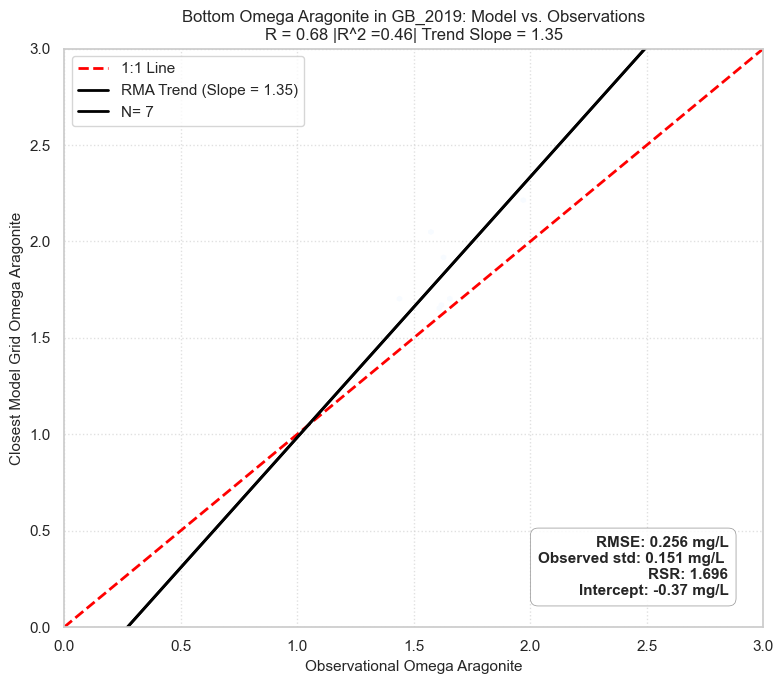

Mean of delta difference between model 3x3x3 grid data and observational data in GB_2021 is: 0.1580
Mean of delta difference between model exact grid data and observational data in GB_2021 is: 0.2150
Global RMSE (3x3x3 grid vs obs) between model and observations in GB_2021 is: 0.2023
Global RMSE (Exact point vs Obs) between model and observations in GB_2021 is: 0.2679
-> Calculated using 7 valid exact points in GB_2021 (out of 7 total pairs).
Calculated Observational Mean: 1.5700
Calculated Model Global Mean: 1.8160
Calculated Global Std Dev: 0.2537
Model grid overestimates the data 100.00 percent of the time
Model grid underestimates the data 0.00 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.1580
When underestimating, the average deficit aragonite (Ω) is: nan
Real-World Observational STD: 0.2276
Model Global STD: 0.2537
Model-to-Observation Variance Ratio: 1.11
Model Grid RSR: 0.8890

ARAGONITE STRESSED STATUS MATCH METRICS (Numeric: Threshold < 1.4)

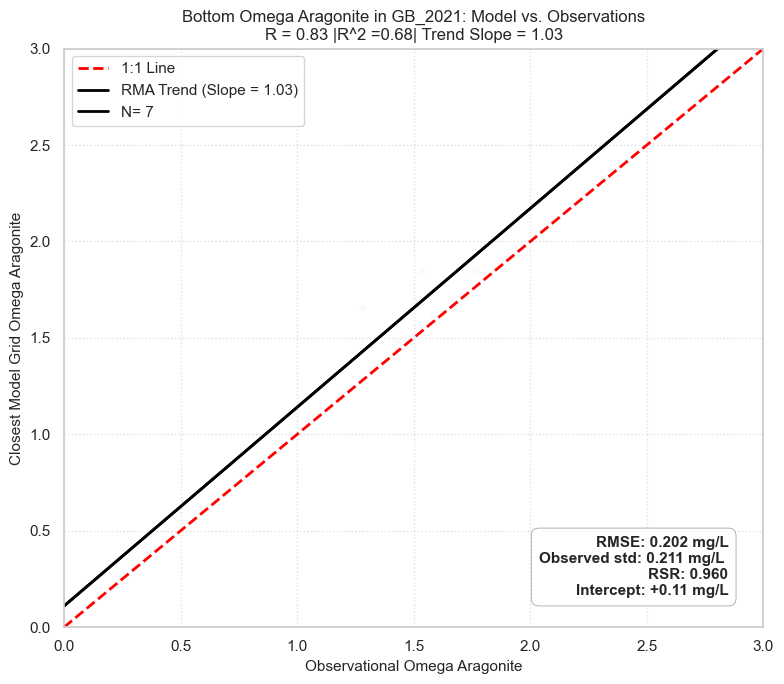

Mean of delta difference between model 3x3x3 grid data and observational data in GB_2022 is: 0.2193
Mean of delta difference between model exact grid data and observational data in GB_2022 is: 0.2697
Global RMSE (3x3x3 grid vs obs) between model and observations in GB_2022 is: 0.2985
Global RMSE (Exact point vs Obs) between model and observations in GB_2022 is: 0.3910
-> Calculated using 12 valid exact points in GB_2022 (out of 12 total pairs).
Calculated Observational Mean: 1.6283
Calculated Model Global Mean: 1.8934
Calculated Global Std Dev: 0.2769
Model grid overestimates the data 91.67 percent of the time
Model grid underestimates the data 8.33 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.2431
When underestimating, the average deficit aragonite (Ω) is: -0.0422
Real-World Observational STD: 0.3156
Model Global STD: 0.2769
Model-to-Observation Variance Ratio: 0.88
Model Grid RSR: 0.9459

ARAGONITE STRESSED STATUS MATCH METRICS (Numeric: Threshold <

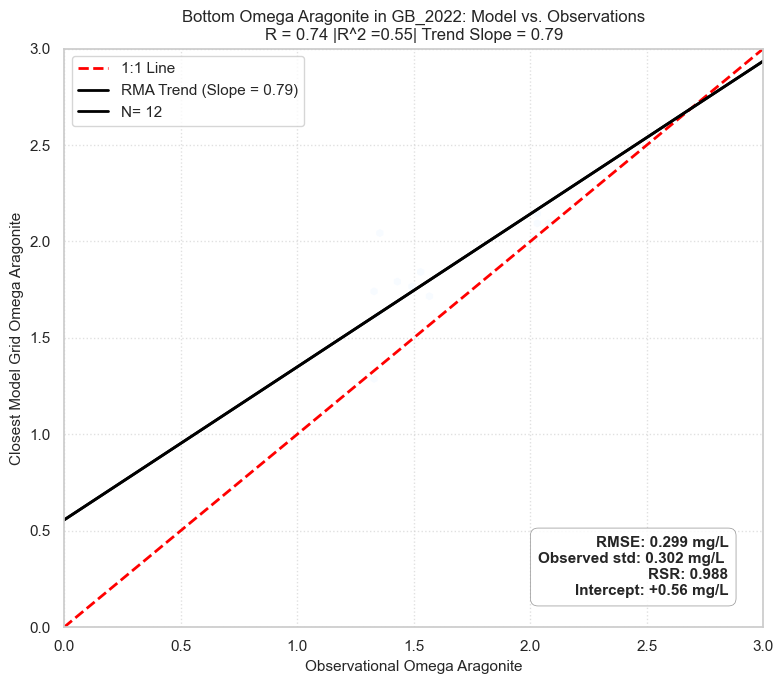

Mean of delta difference between model 3x3x3 grid data and observational data in GB_2023 is: 0.2255
Mean of delta difference between model exact grid data and observational data in GB_2023 is: 0.2534
Global RMSE (3x3x3 grid vs obs) between model and observations in GB_2023 is: 0.3235
Global RMSE (Exact point vs Obs) between model and observations in GB_2023 is: 0.3727
-> Calculated using 12 valid exact points in GB_2023 (out of 12 total pairs).
Calculated Observational Mean: 1.6042
Calculated Model Global Mean: 1.8811
Calculated Global Std Dev: 0.2751
Model grid overestimates the data 75.00 percent of the time
Model grid underestimates the data 25.00 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.3100
When underestimating, the average deficit aragonite (Ω) is: -0.0279
Real-World Observational STD: 0.2877
Model Global STD: 0.2751
Model-to-Observation Variance Ratio: 0.96
Model Grid RSR: 1.1245

ARAGONITE STRESSED STATUS MATCH METRICS (Numeric: Threshold 

KeyboardInterrupt: 

In [20]:
# 1. Load your 3x3x3 grid comparison CSV data
csv_path = r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Processed_Data\comparison\complete\OA_MOM6_3x3x3_comparison_classified.csv"
df=pd.read_csv(csv_path)
# Convert time column to datetime 
df['matched_time'] = pd.to_datetime(df['matched_time'])

    
# 2. Convert DataFrame into a GeoDataFrame (Points)
gdf_points = gpd.GeoDataFrame(
    df, 
    geometry=gpd.points_from_xy(df['matched_lon'], df['matched_lat']),
    crs="epsg:4326"
)

# 3. Load Bathymetry grid file & sample depths using closest-neighbor lookup
bathymetry_path = r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Bathymetry\MOM6_hindcast_ocean_static_deptho.nc"
ds = xr.open_dataset(bathymetry_path)

lon_da = xr.DataArray(gdf_points['matched_lon'].values, dims="point")
lat_da = xr.DataArray(gdf_points['matched_lat'].values, dims="point")
sampled_depths = ds['deptho'].sel(lon=lon_da, lat=lat_da, method='nearest').values

# 4. Load the 5-region Northeast Shelf shapefile & map the names
shapefile_url = 'https://github.com/hsynan/READ-EDAB-Synan_hydrographic_climatologies/raw/refs/heads/main/data/shapefiles/NES_5REGIONS.zip'
gdf_shapes = gpd.read_file(shapefile_url)

region_names = {
    0: "MAB_south",
    1: "MAB_north",
    2: "GB",
    3: "GOM_west",
    4: "GOM_east"
}
# Reset the polygon index to guarantee the 0-4 dictionary keys map correctly
gdf_shapes = gdf_shapes.reset_index(drop=True)
gdf_shapes['Region_Name'] = gdf_shapes.index.map(region_names)

# Coordinate Reference System (CRS) alignment check / assign to World Geodetic System 84
if gdf_shapes.crs is None:
    gdf_shapes.set_crs("epsg:4326", inplace=True)

if gdf_shapes.crs != gdf_points.crs:
    gdf_shapes = gdf_shapes.to_crs(gdf_points.crs)

# 5. Spatial Join to attach Region Names to your prepared points
analyzable_gdf = gpd.sjoin(
    gdf_points, 
    gdf_shapes[['geometry', 'Region_Name']], 
    how='left', 
    predicate='intersects'
)

# Drop the temporary index column added automatically by GeoPandas
if 'index_right' in analyzable_gdf.columns:
    analyzable_gdf = analyzable_gdf.drop(columns=['index_right'])

# Quick verification check to prove both attributes exist side-by-side
print("\n--- Processed Dataset Verification ---")
#print(analyzable_gdf[['matched_lat', 'matched_lon', 'Region_Name', 'model_deptho', 'depth_bin']].head(10))

# 6. Execute full spatiotemporal summary function
output_csv = r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Processed_Data\comparison\complete\OA_spatiotemporal_summary.csv"
analyze_spatiotemporal_data(analyzable_gdf, output_csv)


--- Processed Dataset Verification ---
   matched_lat  matched_lon Region_Name  model_deptho              depth_bin
0    42.476232   -68.995650    GOM_west    210.779709     Shelf_slope(<400m)
1    42.727184   -69.721731    GOM_west    249.519257     Shelf_slope(<400m)
2    40.029446   -69.963758   MAB_north    163.648331     Shelf_slope(<400m)
3    40.154922   -70.125109   MAB_north    119.166885  Inner-midshelf(<150m)
4    40.280399   -70.205785   MAB_north     91.210602  Inner-midshelf(<150m)
5    41.472422   -67.704840          GB     32.688156  Inner-midshelf(<150m)
6    43.417303   -67.704840    GOM_east    239.003464     Shelf_slope(<400m)
7    43.668256   -69.076326    GOM_west    100.878372  Inner-midshelf(<150m)
8    43.856470   -69.076326         NaN     39.566200  Inner-midshelf(<150m)
9    43.040875   -66.333354    GOM_east    107.324745  Inner-midshelf(<150m)

               RUNNING STATISTICS FOR YEAR: 2007        
Mean of delta difference between model 3x3x3 grid data 

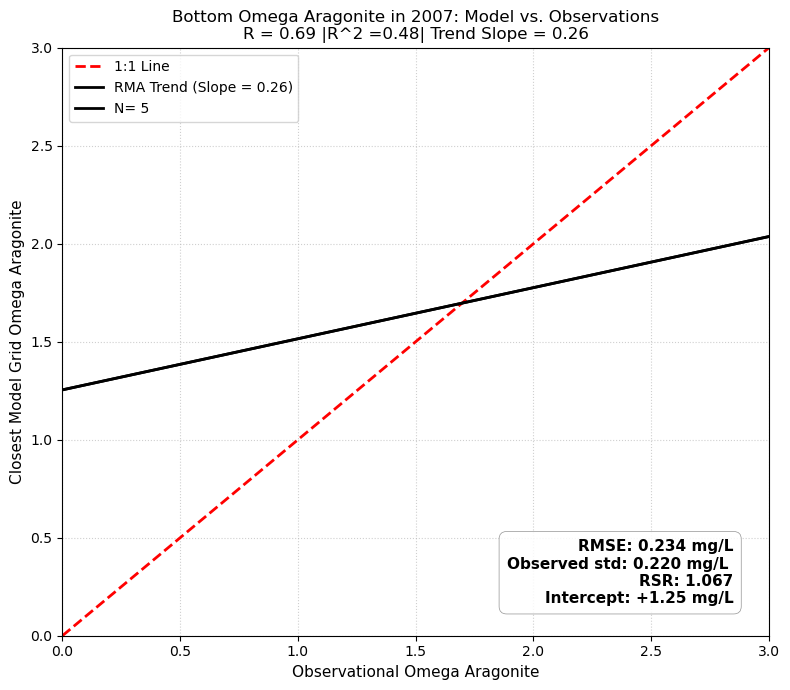


               RUNNING STATISTICS FOR YEAR: 2012        
Mean of delta difference between model 3x3x3 grid data and observational data in 2012 is: 0.1245
Mean of delta difference between model exact grid data and observational data in 2012 is: 0.1456
Global RMSE (3x3x3 grid vs obs) between model and observations in 2012 is: 0.2425
Global RMSE (Exact point vs Obs) between model and observations in 2012 is: 0.3230
-> Calculated using 35 valid exact points in 2012 (out of 35 total pairs).
Calculated Observational Mean: 1.4824
Calculated Model Global Mean: 1.6304
Calculated Global Std Dev: 0.4584
Model grid overestimates the data 77.14 percent of the time
Model grid underestimates the data 22.86 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.1795
When underestimating, the average deficit aragonite (Ω) is: -0.0609
Real-World Observational STD: 0.4093
Model Global STD: 0.4584
Model-to-Observation Variance Ratio: 1.12
Model Grid RSR: 0.7666

ARAGONITE STRESSE

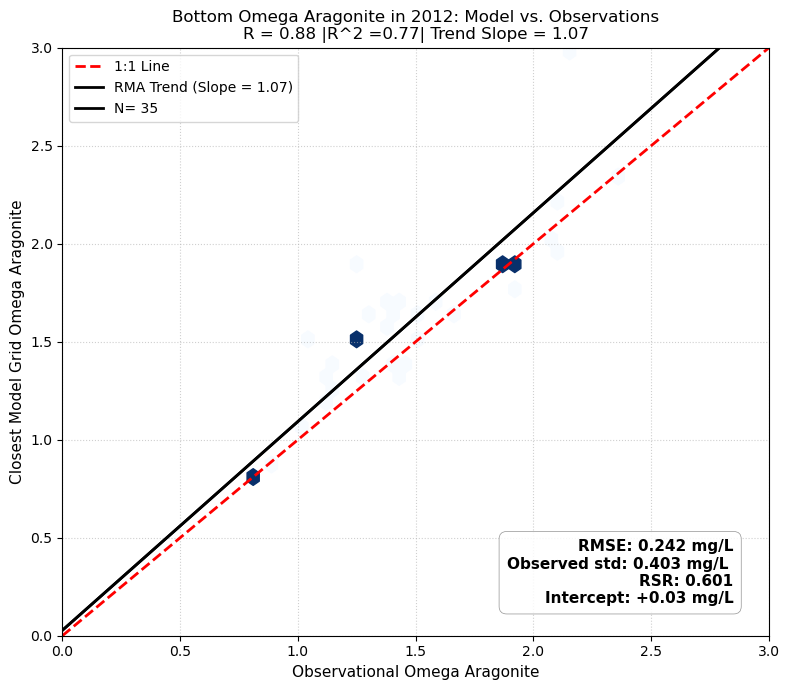


               RUNNING STATISTICS FOR YEAR: 2013        
Mean of delta difference between model 3x3x3 grid data and observational data in 2013 is: 0.1411
Mean of delta difference between model exact grid data and observational data in 2013 is: 0.1528
Global RMSE (3x3x3 grid vs obs) between model and observations in 2013 is: 0.2472
Global RMSE (Exact point vs Obs) between model and observations in 2013 is: 0.3135
-> Calculated using 29 valid exact points in 2013 (out of 29 total pairs).
Calculated Observational Mean: 1.5452
Calculated Model Global Mean: 1.6998
Calculated Global Std Dev: 0.2787
Model grid overestimates the data 79.31 percent of the time
Model grid underestimates the data 20.69 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.2072
When underestimating, the average deficit aragonite (Ω) is: -0.1122
Real-World Observational STD: 0.3353
Model Global STD: 0.2787
Model-to-Observation Variance Ratio: 0.83
Model Grid RSR: 0.7814

ARAGONITE STRESSE

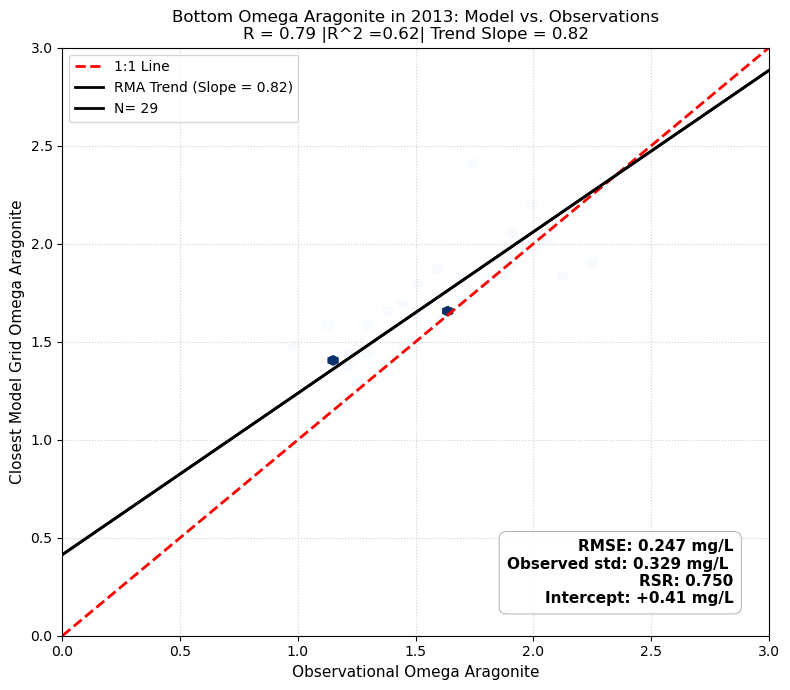


               RUNNING STATISTICS FOR YEAR: 2014        
Mean of delta difference between model 3x3x3 grid data and observational data in 2014 is: 0.2197
Mean of delta difference between model exact grid data and observational data in 2014 is: 0.2898
Global RMSE (3x3x3 grid vs obs) between model and observations in 2014 is: 0.2697
Global RMSE (Exact point vs Obs) between model and observations in 2014 is: 0.3304
-> Calculated using 22 valid exact points in 2014 (out of 22 total pairs).
Calculated Observational Mean: 1.4495
Calculated Model Global Mean: 1.7450
Calculated Global Std Dev: 0.1923
Model grid overestimates the data 90.91 percent of the time
Model grid underestimates the data 9.09 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.2453
When underestimating, the average deficit aragonite (Ω) is: -0.0362
Real-World Observational STD: 0.2305
Model Global STD: 0.1923
Model-to-Observation Variance Ratio: 0.83
Model Grid RSR: 0.8525

ARAGONITE STRESSED

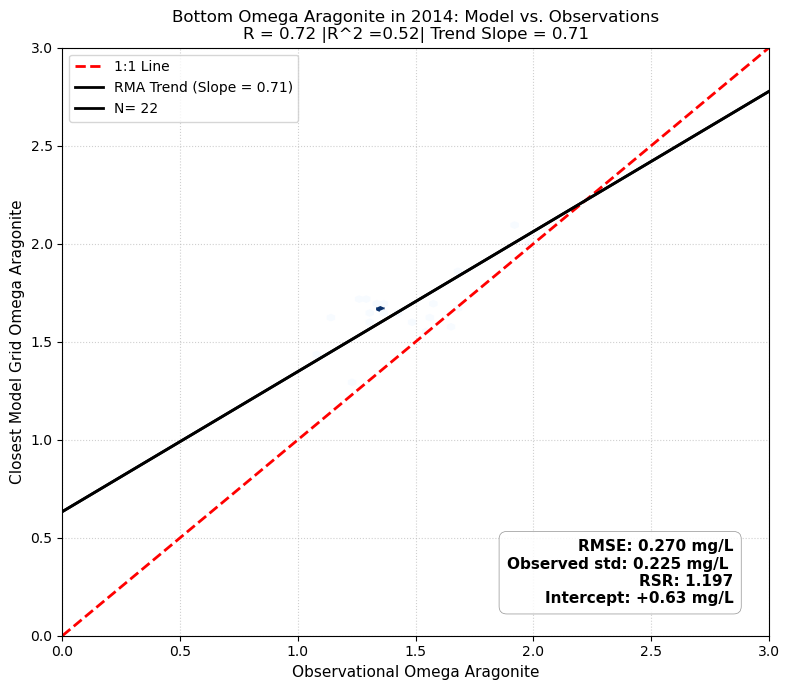


               RUNNING STATISTICS FOR YEAR: 2015        
Mean of delta difference between model 3x3x3 grid data and observational data in 2015 is: 0.1464
Mean of delta difference between model exact grid data and observational data in 2015 is: 0.1826
Global RMSE (3x3x3 grid vs obs) between model and observations in 2015 is: 0.2255
Global RMSE (Exact point vs Obs) between model and observations in 2015 is: 0.2943
-> Calculated using 62 valid exact points in 2015 (out of 62 total pairs).
Calculated Observational Mean: 1.6331
Calculated Model Global Mean: 1.8240
Calculated Global Std Dev: 0.3257
Model grid overestimates the data 82.26 percent of the time
Model grid underestimates the data 17.74 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.1873
When underestimating, the average deficit aragonite (Ω) is: -0.0428
Real-World Observational STD: 0.3195
Model Global STD: 0.3257
Model-to-Observation Variance Ratio: 1.02
Model Grid RSR: 0.7131

ARAGONITE STRESSE

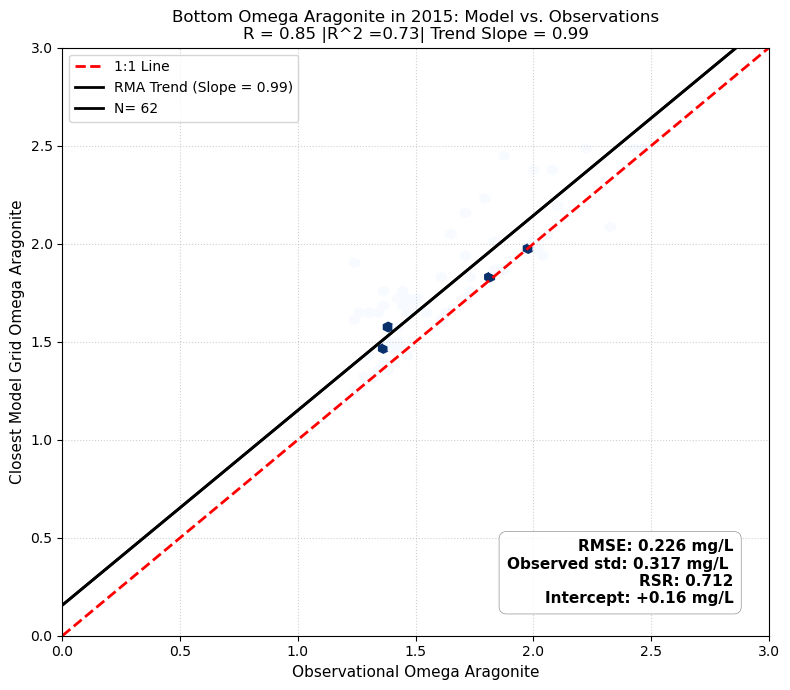


               RUNNING STATISTICS FOR YEAR: 2016        
Mean of delta difference between model 3x3x3 grid data and observational data in 2016 is: 0.3290
Mean of delta difference between model exact grid data and observational data in 2016 is: 0.3517
Global RMSE (3x3x3 grid vs obs) between model and observations in 2016 is: 0.4582
Global RMSE (Exact point vs Obs) between model and observations in 2016 is: 0.5812
-> Calculated using 39 valid exact points in 2016 (out of 39 total pairs).
Calculated Observational Mean: 1.5218
Calculated Model Global Mean: 1.8847
Calculated Global Std Dev: 0.3647
Model grid overestimates the data 84.62 percent of the time
Model grid underestimates the data 15.38 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.4020
When underestimating, the average deficit aragonite (Ω) is: -0.0725
Real-World Observational STD: 0.3898
Model Global STD: 0.3647
Model-to-Observation Variance Ratio: 0.94
Model Grid RSR: 1.4486

ARAGONITE STRESSE

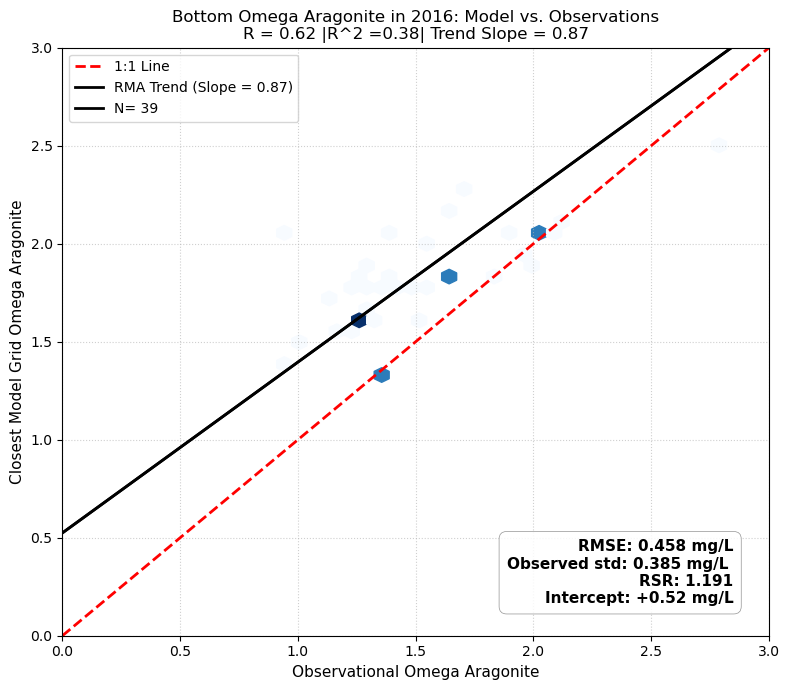


               RUNNING STATISTICS FOR YEAR: 2017        
Mean of delta difference between model 3x3x3 grid data and observational data in 2017 is: 0.2480
Mean of delta difference between model exact grid data and observational data in 2017 is: 0.3228
Global RMSE (3x3x3 grid vs obs) between model and observations in 2017 is: 0.3527
Global RMSE (Exact point vs Obs) between model and observations in 2017 is: 0.4348
-> Calculated using 37 valid exact points in 2017 (out of 37 total pairs).
Calculated Observational Mean: 1.5581
Calculated Model Global Mean: 1.9020
Calculated Global Std Dev: 0.3474
Model grid overestimates the data 86.49 percent of the time
Model grid underestimates the data 13.51 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.3129
When underestimating, the average deficit aragonite (Ω) is: -0.1676
Real-World Observational STD: 0.2761
Model Global STD: 0.3474
Model-to-Observation Variance Ratio: 1.26
Model Grid RSR: 1.1151

ARAGONITE STRESSE

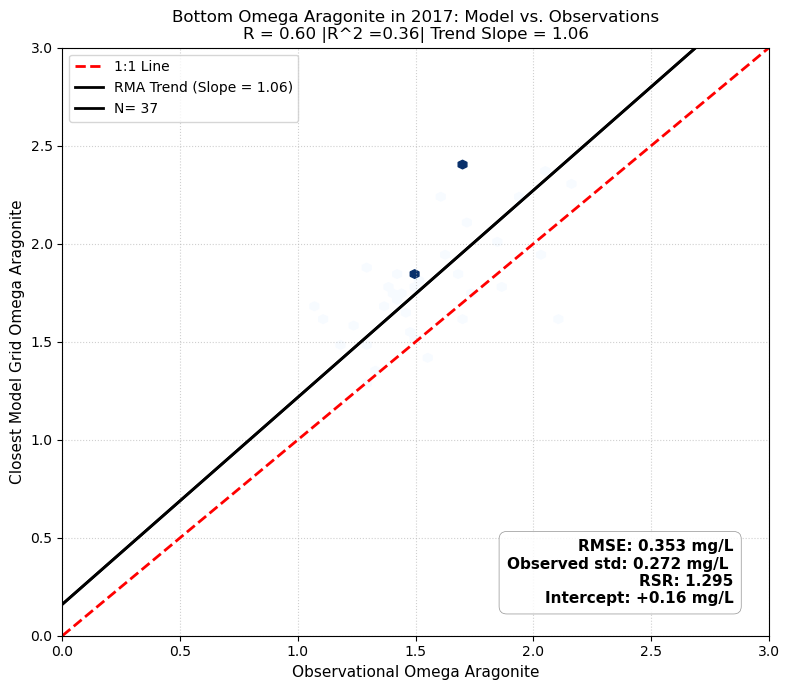


               RUNNING STATISTICS FOR YEAR: 2018        
Mean of delta difference between model 3x3x3 grid data and observational data in 2018 is: 0.2784
Mean of delta difference between model exact grid data and observational data in 2018 is: 0.3279
Global RMSE (3x3x3 grid vs obs) between model and observations in 2018 is: 0.3518
Global RMSE (Exact point vs Obs) between model and observations in 2018 is: 0.4427
-> Calculated using 107 valid exact points in 2018 (out of 108 total pairs).
Calculated Observational Mean: 1.5643
Calculated Model Global Mean: 1.8994
Calculated Global Std Dev: 0.3162
Model grid overestimates the data 93.52 percent of the time
Model grid underestimates the data 6.48 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.2982
When underestimating, the average deficit aragonite (Ω) is: -0.0073
Real-World Observational STD: 0.2466
Model Global STD: 0.3162
Model-to-Observation Variance Ratio: 1.28
Model Grid RSR: 1.1122

ARAGONITE STRESS

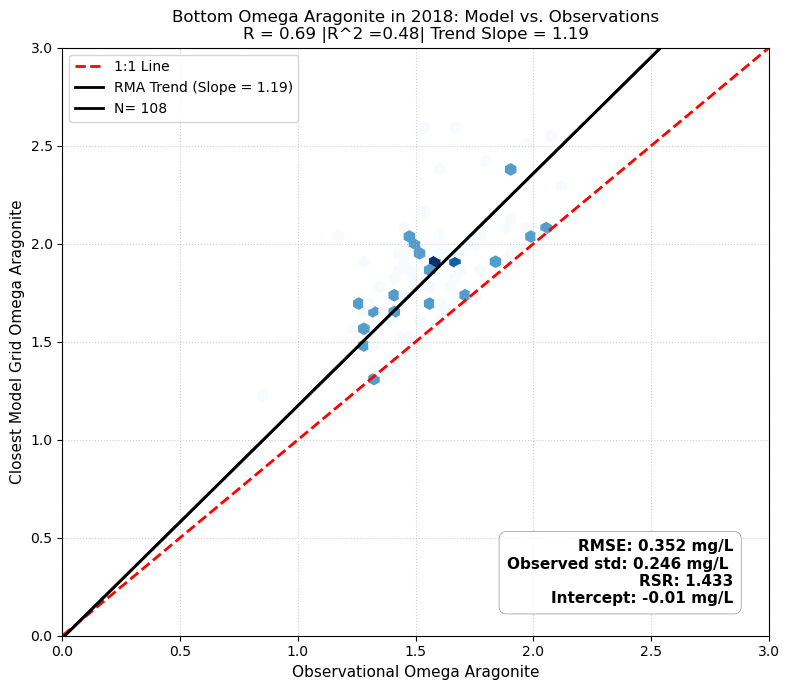


               RUNNING STATISTICS FOR YEAR: 2019        
Mean of delta difference between model 3x3x3 grid data and observational data in 2019 is: 0.2886
Mean of delta difference between model exact grid data and observational data in 2019 is: 0.3832
Global RMSE (3x3x3 grid vs obs) between model and observations in 2019 is: 0.4282
Global RMSE (Exact point vs Obs) between model and observations in 2019 is: 0.5343
-> Calculated using 85 valid exact points in 2019 (out of 85 total pairs).
Calculated Observational Mean: 1.4528
Calculated Model Global Mean: 1.8296
Calculated Global Std Dev: 0.4102
Model grid overestimates the data 77.65 percent of the time
Model grid underestimates the data 22.35 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.3880
When underestimating, the average deficit aragonite (Ω) is: -0.0566
Real-World Observational STD: 0.4097
Model Global STD: 0.4102
Model-to-Observation Variance Ratio: 1.00
Model Grid RSR: 1.3536

ARAGONITE STRESSE

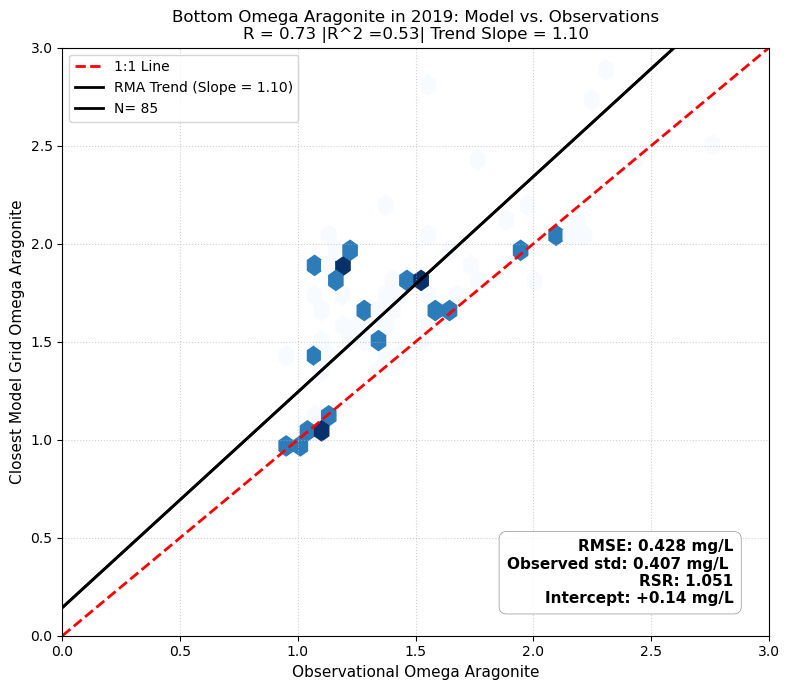


               RUNNING STATISTICS FOR YEAR: 2021        
Mean of delta difference between model 3x3x3 grid data and observational data in 2021 is: 0.0225
Mean of delta difference between model exact grid data and observational data in 2021 is: 0.0151
Global RMSE (3x3x3 grid vs obs) between model and observations in 2021 is: 0.2420
Global RMSE (Exact point vs Obs) between model and observations in 2021 is: 0.3064
-> Calculated using 1149 valid exact points in 2021 (out of 1149 total pairs).
Calculated Observational Mean: 1.7582
Calculated Model Global Mean: 1.7720
Calculated Global Std Dev: 0.2460
Model grid overestimates the data 58.83 percent of the time
Model grid underestimates the data 41.17 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.1518
When underestimating, the average deficit aragonite (Ω) is: -0.1622
Real-World Observational STD: 0.3535
Model Global STD: 0.2460
Model-to-Observation Variance Ratio: 0.70
Model Grid RSR: 0.7650

ARAGONITE STR

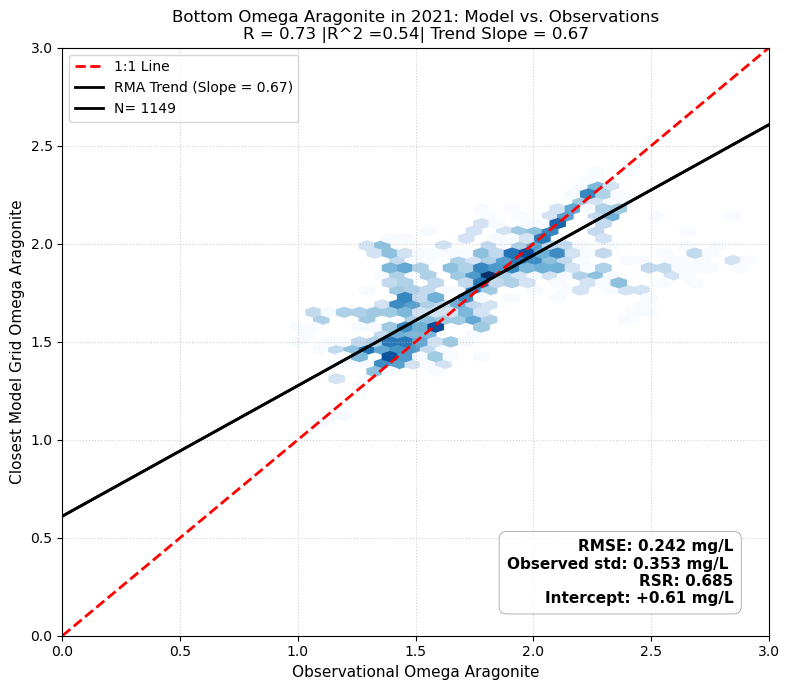


               RUNNING STATISTICS FOR YEAR: 2022        
Mean of delta difference between model 3x3x3 grid data and observational data in 2022 is: 0.1211
Mean of delta difference between model exact grid data and observational data in 2022 is: 0.1427
Global RMSE (3x3x3 grid vs obs) between model and observations in 2022 is: 0.2400
Global RMSE (Exact point vs Obs) between model and observations in 2022 is: 0.3139
-> Calculated using 1049 valid exact points in 2022 (out of 1051 total pairs).
Calculated Observational Mean: 1.5827
Calculated Model Global Mean: 1.7263
Calculated Global Std Dev: 0.2904
Model grid overestimates the data 76.97 percent of the time
Model grid underestimates the data 23.03 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.1857
When underestimating, the average deficit aragonite (Ω) is: -0.0949
Real-World Observational STD: 0.3340
Model Global STD: 0.2904
Model-to-Observation Variance Ratio: 0.87
Model Grid RSR: 0.7587

ARAGONITE STR

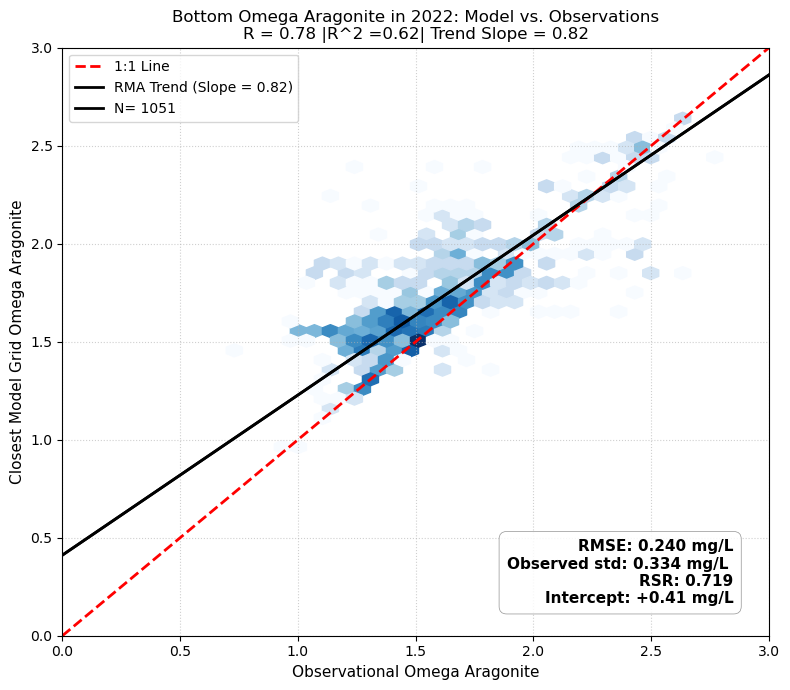


               RUNNING STATISTICS FOR YEAR: 2023        
Mean of delta difference between model 3x3x3 grid data and observational data in 2023 is: 0.3249
Mean of delta difference between model exact grid data and observational data in 2023 is: 0.3765
Global RMSE (3x3x3 grid vs obs) between model and observations in 2023 is: 0.4410
Global RMSE (Exact point vs Obs) between model and observations in 2023 is: 0.5076
-> Calculated using 1208 valid exact points in 2023 (out of 1208 total pairs).
Calculated Observational Mean: 1.4848
Calculated Model Global Mean: 1.8597
Calculated Global Std Dev: 0.2470
Model grid overestimates the data 87.17 percent of the time
Model grid underestimates the data 12.83 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.3865
When underestimating, the average deficit aragonite (Ω) is: -0.0937
Real-World Observational STD: 0.3821
Model Global STD: 0.2470
Model-to-Observation Variance Ratio: 0.65
Model Grid RSR: 1.3943

ARAGONITE STR

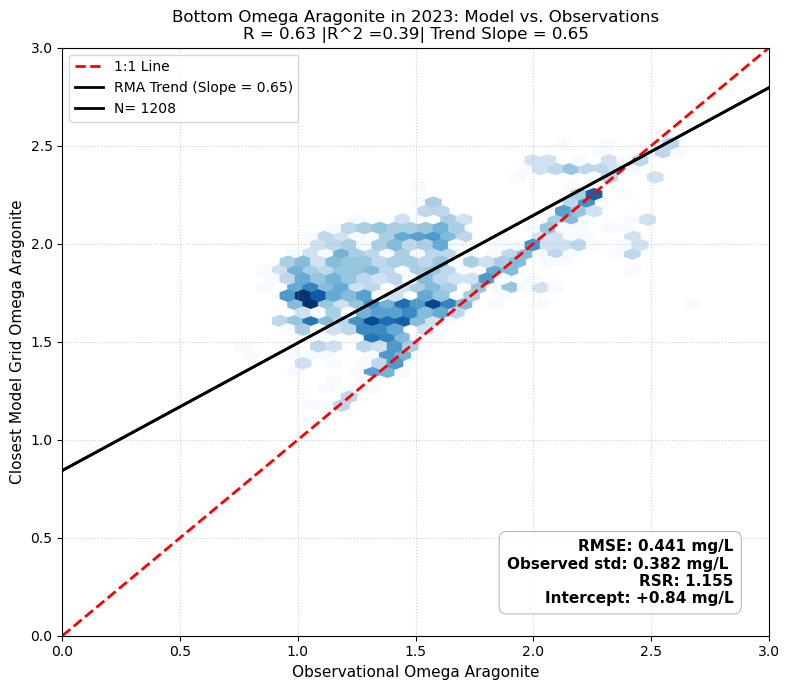


               RUNNING STATISTICS FOR YEAR: 2024        
Mean of delta difference between model 3x3x3 grid data and observational data in 2024 is: 0.7348
Mean of delta difference between model exact grid data and observational data in 2024 is: 0.8166
Global RMSE (3x3x3 grid vs obs) between model and observations in 2024 is: 0.8534
Global RMSE (Exact point vs Obs) between model and observations in 2024 is: 0.9252
-> Calculated using 916 valid exact points in 2024 (out of 917 total pairs).
Calculated Observational Mean: 1.3844
Calculated Model Global Mean: 2.1945
Calculated Global Std Dev: 0.2226
Model grid overestimates the data 95.31 percent of the time
Model grid underestimates the data 4.69 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.7732
When underestimating, the average deficit aragonite (Ω) is: -0.0452
Real-World Observational STD: 0.4143
Model Global STD: 0.2226
Model-to-Observation Variance Ratio: 0.54
Model Grid RSR: 2.6981

ARAGONITE STRESS

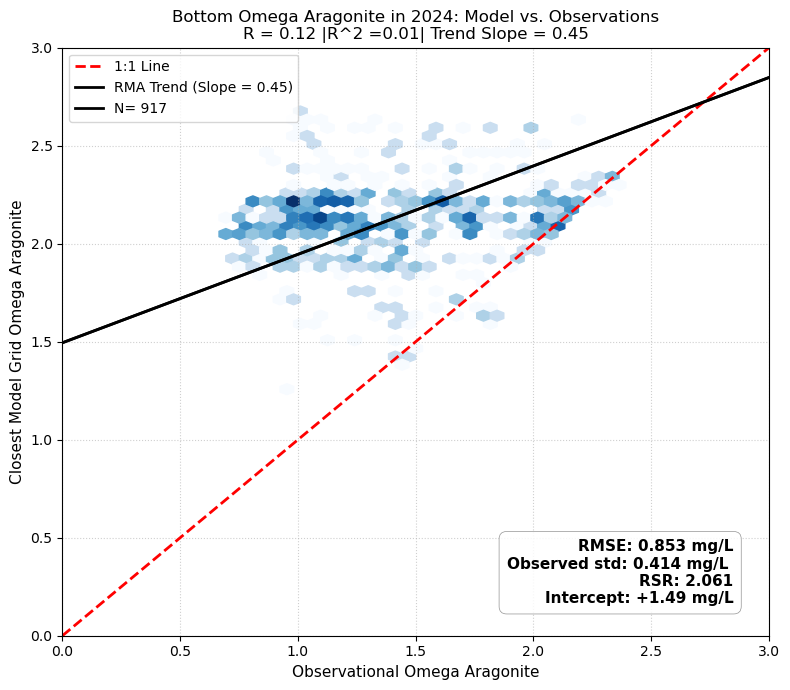


               RUNNING STATISTICS FOR YEAR: 2025        
Mean of delta difference between model 3x3x3 grid data and observational data in 2025 is: 0.6424
Mean of delta difference between model exact grid data and observational data in 2025 is: 0.7243
Global RMSE (3x3x3 grid vs obs) between model and observations in 2025 is: 0.7023
Global RMSE (Exact point vs Obs) between model and observations in 2025 is: 0.7854
-> Calculated using 479 valid exact points in 2025 (out of 479 total pairs).
Calculated Observational Mean: 1.4777
Calculated Model Global Mean: 2.1977
Calculated Global Std Dev: 0.1760
Model grid overestimates the data 97.08 percent of the time
Model grid underestimates the data 2.92 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.6700
When underestimating, the average deficit aragonite (Ω) is: -0.2732
Real-World Observational STD: 0.2492
Model Global STD: 0.1760
Model-to-Observation Variance Ratio: 0.71
Model Grid RSR: 2.2204

ARAGONITE STRESS

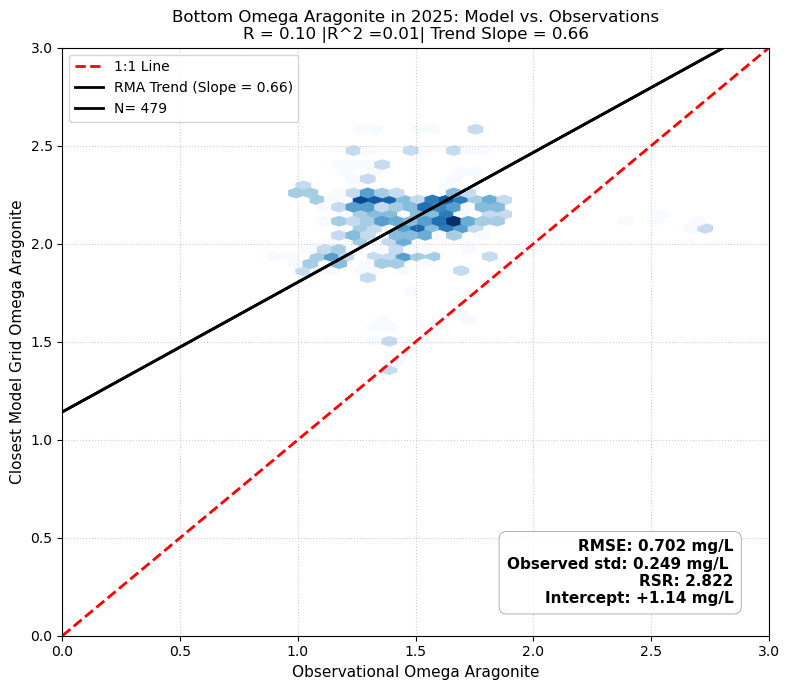


               RUNNING STATISTICS FOR SEASON: Spring     
Mean of delta difference between model 3x3x3 grid data and observational data in Season_Spring is: 0.3427
Mean of delta difference between model exact grid data and observational data in Season_Spring is: 0.4037
Global RMSE (3x3x3 grid vs obs) between model and observations in Season_Spring is: 0.4812
Global RMSE (Exact point vs Obs) between model and observations in Season_Spring is: 0.5534
-> Calculated using 1305 valid exact points in Season_Spring (out of 1305 total pairs).
Calculated Observational Mean: 1.6220
Calculated Model Global Mean: 2.0199
Calculated Global Std Dev: 0.2778
Model grid overestimates the data 88.43 percent of the time
Model grid underestimates the data 11.57 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.3914
When underestimating, the average deficit aragonite (Ω) is: -0.0296
Real-World Observational STD: 0.2641
Model Global STD: 0.2778
Model-to-Observation Variance Rat

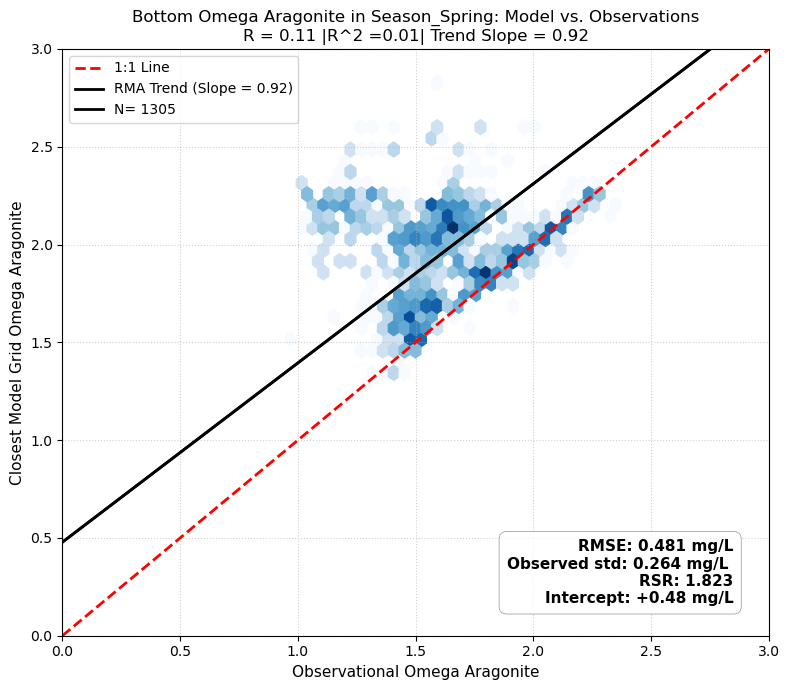


               RUNNING STATISTICS FOR SEASON: Summer     
Mean of delta difference between model 3x3x3 grid data and observational data in Season_Summer is: 0.4399
Mean of delta difference between model exact grid data and observational data in Season_Summer is: 0.4905
Global RMSE (3x3x3 grid vs obs) between model and observations in Season_Summer is: 0.5952
Global RMSE (Exact point vs Obs) between model and observations in Season_Summer is: 0.6526
-> Calculated using 1836 valid exact points in Season_Summer (out of 1840 total pairs).
Calculated Observational Mean: 1.3595
Calculated Model Global Mean: 1.8476
Calculated Global Std Dev: 0.2957
Model grid overestimates the data 86.47 percent of the time
Model grid underestimates the data 13.53 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.5208
When underestimating, the average deficit aragonite (Ω) is: -0.0768
Real-World Observational STD: 0.3086
Model Global STD: 0.2957
Model-to-Observation Variance Rat

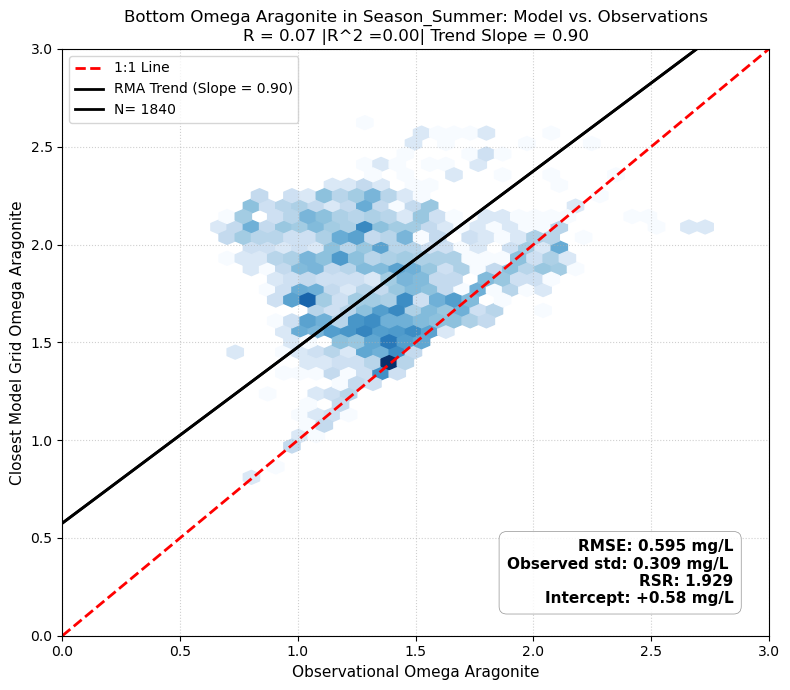


               RUNNING STATISTICS FOR SEASON: Fall     
Mean of delta difference between model 3x3x3 grid data and observational data in Season_Fall is: 0.1646
Mean of delta difference between model exact grid data and observational data in Season_Fall is: 0.1806
Global RMSE (3x3x3 grid vs obs) between model and observations in Season_Fall is: 0.4378
Global RMSE (Exact point vs Obs) between model and observations in Season_Fall is: 0.5180
-> Calculated using 1650 valid exact points in Season_Fall (out of 1650 total pairs).
Calculated Observational Mean: 1.7042
Calculated Model Global Mean: 1.8866
Calculated Global Std Dev: 0.3433
Model grid overestimates the data 67.58 percent of the time
Model grid underestimates the data 32.42 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.3316
When underestimating, the average deficit aragonite (Ω) is: -0.1834
Real-World Observational STD: 0.4592
Model Global STD: 0.3433
Model-to-Observation Variance Ratio: 0.75
Mod

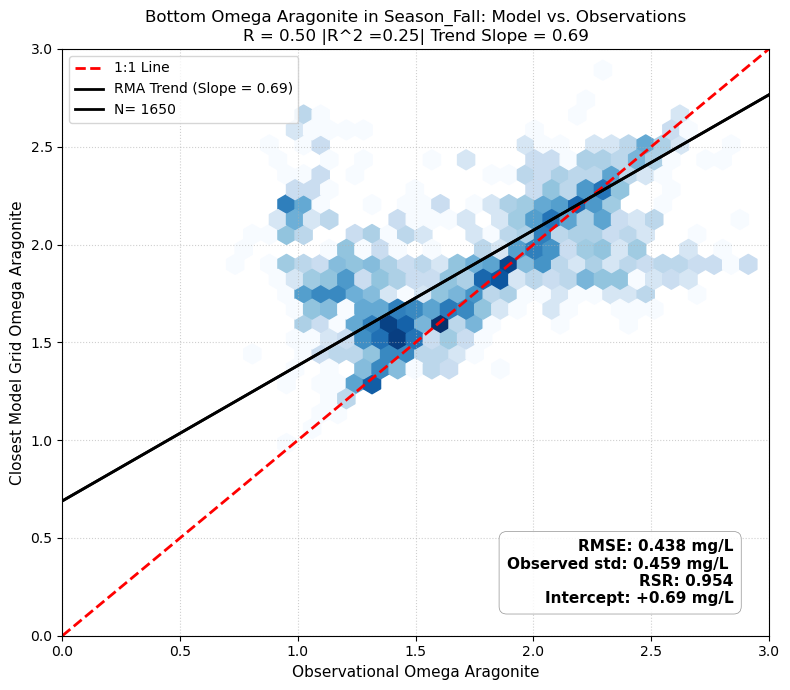


               RUNNING STATISTICS FOR SEASON: Winter     
Mean of delta difference between model 3x3x3 grid data and observational data in Season_Winter is: 0.2291
Mean of delta difference between model exact grid data and observational data in Season_Winter is: 0.2622
Global RMSE (3x3x3 grid vs obs) between model and observations in Season_Winter is: 0.3308
Global RMSE (Exact point vs Obs) between model and observations in Season_Winter is: 0.3660
-> Calculated using 431 valid exact points in Season_Winter (out of 431 total pairs).
Calculated Observational Mean: 1.5573
Calculated Model Global Mean: 1.8193
Calculated Global Std Dev: 0.3050
Model grid overestimates the data 86.54 percent of the time
Model grid underestimates the data 13.46 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.2711
When underestimating, the average deficit aragonite (Ω) is: -0.0411
Real-World Observational STD: 0.2555
Model Global STD: 0.3050
Model-to-Observation Variance Ratio

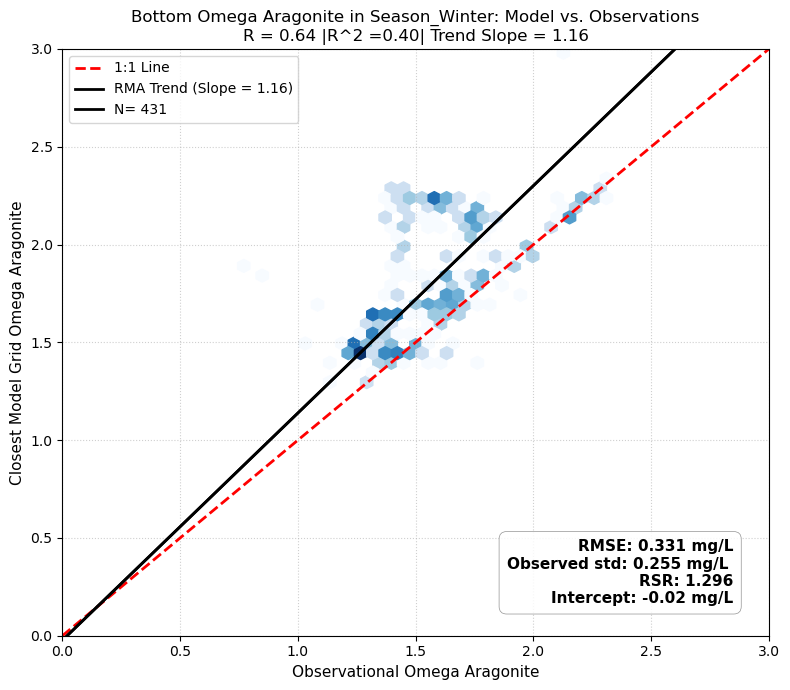


               RUNNING STATISTICS FOR REGION: MAB_south     
Mean of delta difference between model 3x3x3 grid data and observational data in MAB_south is: 0.3915
Mean of delta difference between model exact grid data and observational data in MAB_south is: 0.4552
Global RMSE (3x3x3 grid vs obs) between model and observations in MAB_south is: 0.5942
Global RMSE (Exact point vs Obs) between model and observations in MAB_south is: 0.6862
-> Calculated using 1792 valid exact points in MAB_south (out of 1792 total pairs).
Calculated Observational Mean: 1.6631
Calculated Model Global Mean: 2.1124
Calculated Global Std Dev: 0.2804
Model grid overestimates the data 82.09 percent of the time
Model grid underestimates the data 17.91 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.5100
When underestimating, the average deficit aragonite (Ω) is: -0.1516
Real-World Observational STD: 0.4429
Model Global STD: 0.2804
Model-to-Observation Variance Ratio: 0.63
Model Gr

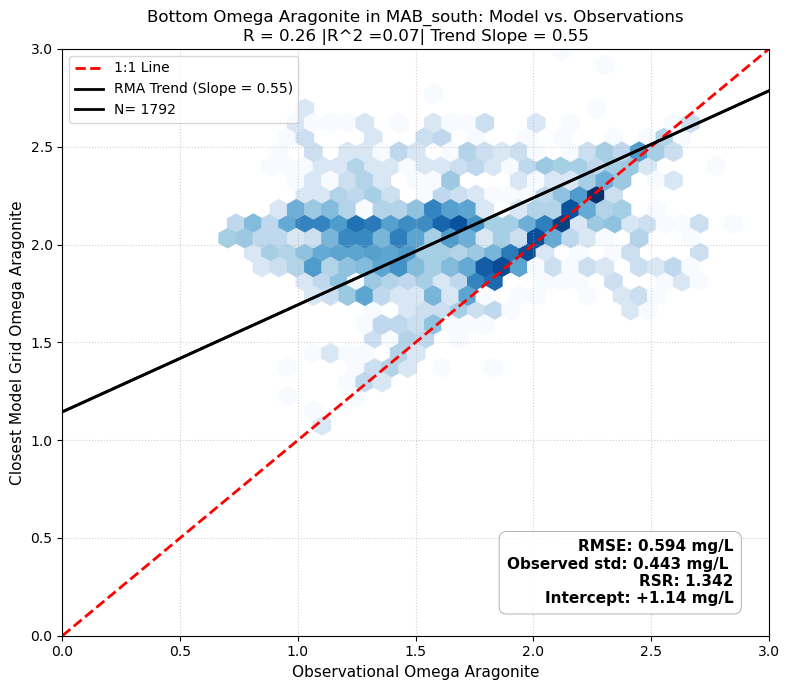


               RUNNING STATISTICS FOR REGION: MAB_north     
Mean of delta difference between model 3x3x3 grid data and observational data in MAB_north is: 0.3972
Mean of delta difference between model exact grid data and observational data in MAB_north is: 0.4385
Global RMSE (3x3x3 grid vs obs) between model and observations in MAB_north is: 0.5801
Global RMSE (Exact point vs Obs) between model and observations in MAB_north is: 0.6332
-> Calculated using 1806 valid exact points in MAB_north (out of 1806 total pairs).
Calculated Observational Mean: 1.4951
Calculated Model Global Mean: 1.9309
Calculated Global Std Dev: 0.2518
Model grid overestimates the data 83.06 percent of the time
Model grid underestimates the data 16.94 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.5120
When underestimating, the average deficit aragonite (Ω) is: -0.1659
Real-World Observational STD: 0.3870
Model Global STD: 0.2518
Model-to-Observation Variance Ratio: 0.65
Model Gr

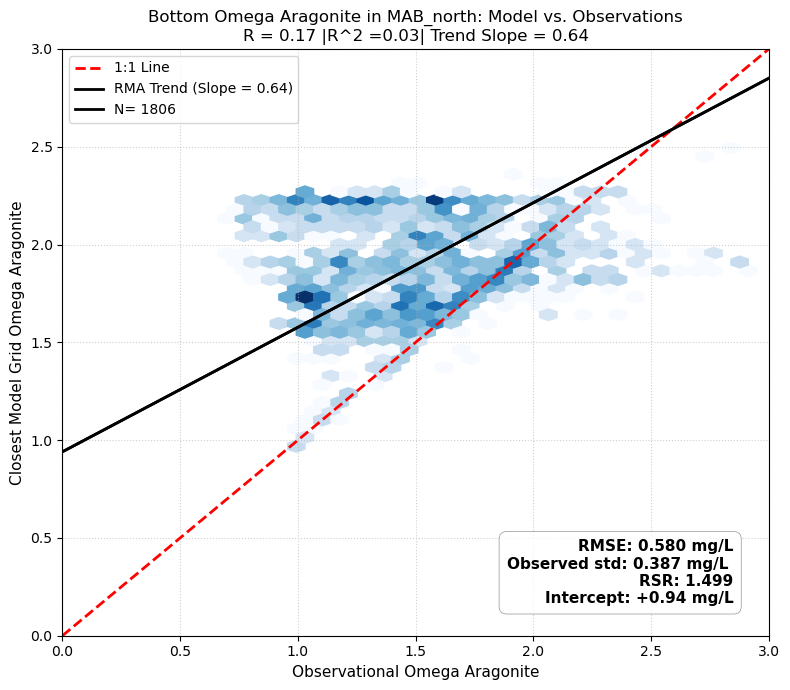


               RUNNING STATISTICS FOR REGION: GB     
Mean of delta difference between model 3x3x3 grid data and observational data in GB is: 0.2173
Mean of delta difference between model exact grid data and observational data in GB is: 0.2539
Global RMSE (3x3x3 grid vs obs) between model and observations in GB is: 0.2993
Global RMSE (Exact point vs Obs) between model and observations in GB is: 0.3572
-> Calculated using 82 valid exact points in GB (out of 82 total pairs).
Calculated Observational Mean: 1.6297
Calculated Model Global Mean: 1.9094
Calculated Global Std Dev: 0.2861
Model grid overestimates the data 87.80 percent of the time
Model grid underestimates the data 12.20 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.2532
When underestimating, the average deficit aragonite (Ω) is: -0.0418
Real-World Observational STD: 0.2429
Model Global STD: 0.2861
Model-to-Observation Variance Ratio: 1.18
Model Grid RSR: 0.9462

ARAGONITE STRESSED STATUS MATC

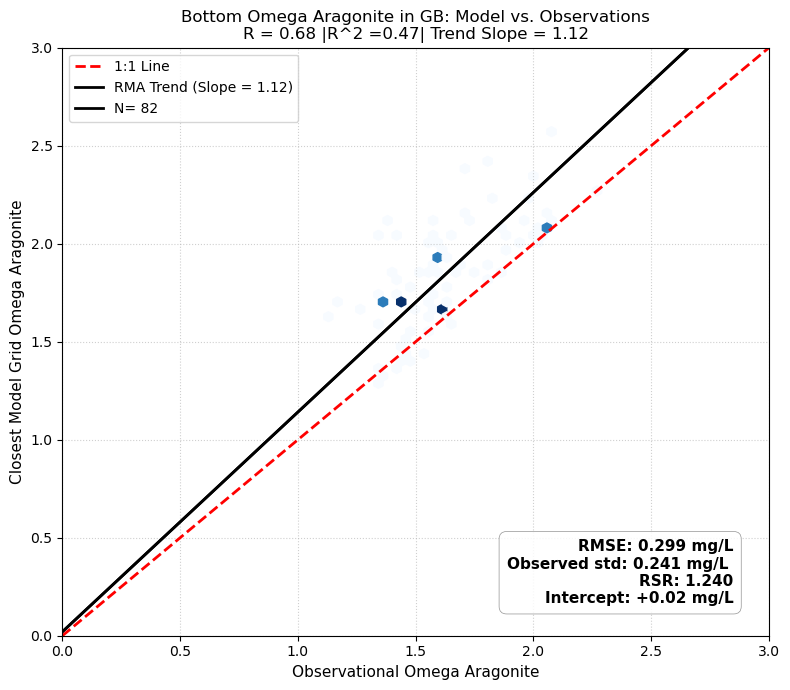


               RUNNING STATISTICS FOR REGION: GOM_west     
Mean of delta difference between model 3x3x3 grid data and observational data in GOM_west is: 0.1218
Mean of delta difference between model exact grid data and observational data in GOM_west is: 0.1446
Global RMSE (3x3x3 grid vs obs) between model and observations in GOM_west is: 0.2046
Global RMSE (Exact point vs Obs) between model and observations in GOM_west is: 0.2424
-> Calculated using 618 valid exact points in GOM_west (out of 618 total pairs).
Calculated Observational Mean: 1.3594
Calculated Model Global Mean: 1.5134
Calculated Global Std Dev: 0.1344
Model grid overestimates the data 78.64 percent of the time
Model grid underestimates the data 21.36 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.1666
When underestimating, the average deficit aragonite (Ω) is: -0.0431
Real-World Observational STD: 0.1540
Model Global STD: 0.1344
Model-to-Observation Variance Ratio: 0.87
Model Grid RSR: 

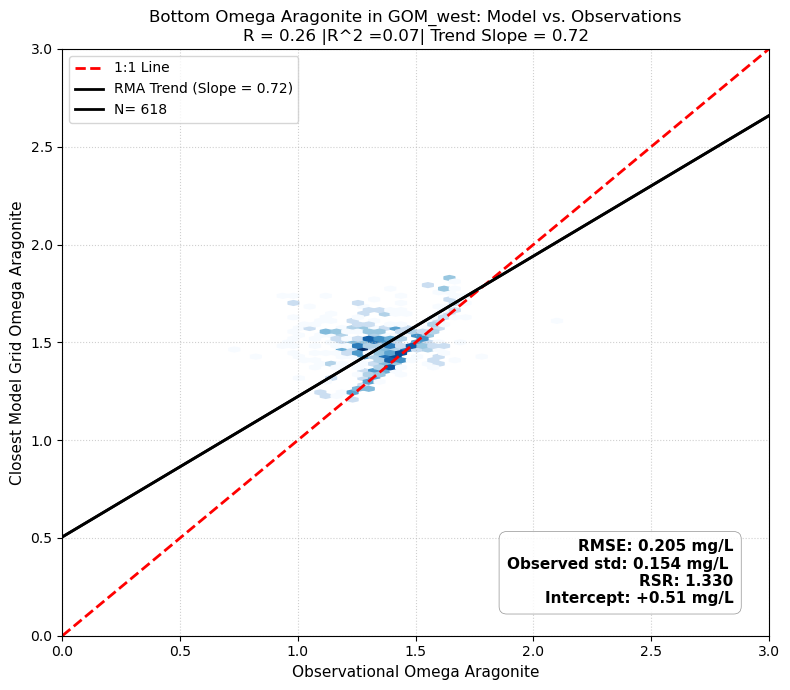


               RUNNING STATISTICS FOR REGION: GOM_east     
Mean of delta difference between model 3x3x3 grid data and observational data in GOM_east is: 0.1618
Mean of delta difference between model exact grid data and observational data in GOM_east is: 0.1836
Global RMSE (3x3x3 grid vs obs) between model and observations in GOM_east is: 0.2258
Global RMSE (Exact point vs Obs) between model and observations in GOM_east is: 0.2557
-> Calculated using 653 valid exact points in GOM_east (out of 653 total pairs).
Calculated Observational Mean: 1.4718
Calculated Model Global Mean: 1.6579
Calculated Global Std Dev: 0.1186
Model grid overestimates the data 88.51 percent of the time
Model grid underestimates the data 11.49 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.1947
When underestimating, the average deficit aragonite (Ω) is: -0.0916
Real-World Observational STD: 0.1522
Model Global STD: 0.1186
Model-to-Observation Variance Ratio: 0.78
Model Grid RSR: 

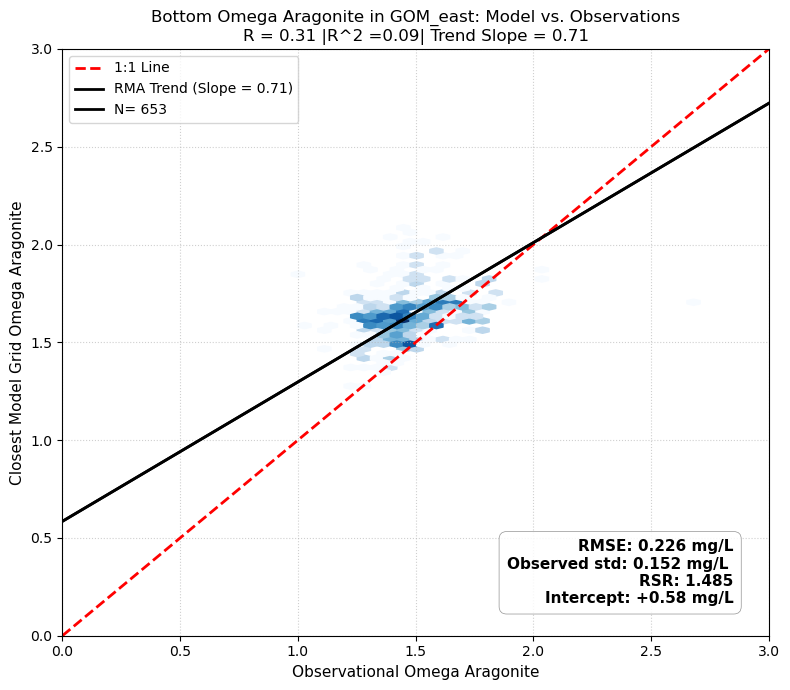


               RUNNING STATISTICS FOR DEPTH: Shallow(<25m)       
Mean of delta difference between model 3x3x3 grid data and observational data in Depth_Shallow(<25m) is: 0.3687
Mean of delta difference between model exact grid data and observational data in Depth_Shallow(<25m) is: 0.3968
Global RMSE (3x3x3 grid vs obs) between model and observations in Depth_Shallow(<25m) is: 0.5723
Global RMSE (Exact point vs Obs) between model and observations in Depth_Shallow(<25m) is: 0.6555
-> Calculated using 424 valid exact points in Depth_Shallow(<25m) (out of 425 total pairs).
Calculated Observational Mean: 1.6156
Calculated Model Global Mean: 2.0200
Calculated Global Std Dev: 0.2796
Model grid overestimates the data 77.41 percent of the time
Model grid underestimates the data 22.59 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.5171
When underestimating, the average deficit aragonite (Ω) is: -0.1396
Real-World Observational STD: 0.4873
Model Global STD: 0.27

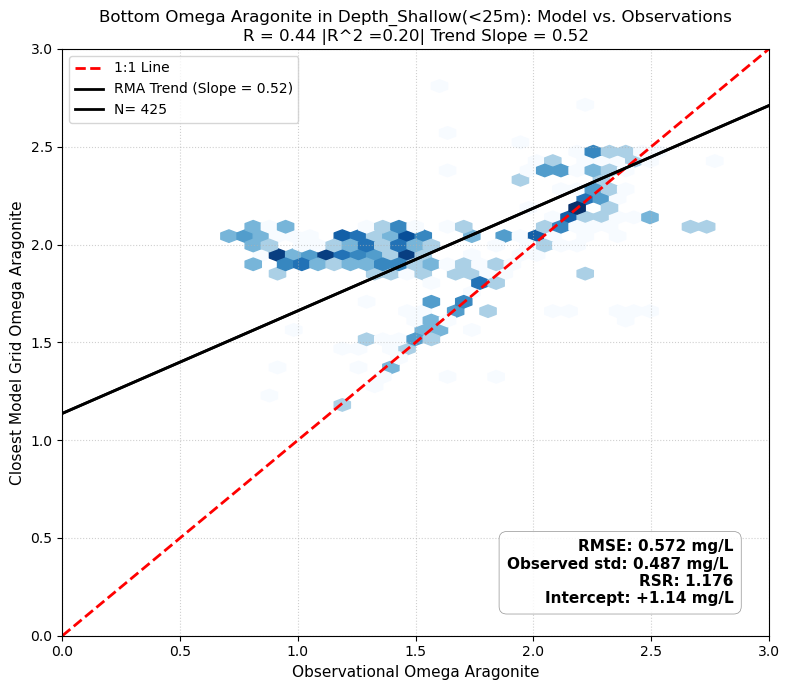


               RUNNING STATISTICS FOR DEPTH: Inner-midshelf(<150m)       
Mean of delta difference between model 3x3x3 grid data and observational data in Depth_Inner-midshelf(<150m) is: 0.3464
Mean of delta difference between model exact grid data and observational data in Depth_Inner-midshelf(<150m) is: 0.3956
Global RMSE (3x3x3 grid vs obs) between model and observations in Depth_Inner-midshelf(<150m) is: 0.5425
Global RMSE (Exact point vs Obs) between model and observations in Depth_Inner-midshelf(<150m) is: 0.6112
-> Calculated using 3868 valid exact points in Depth_Inner-midshelf(<150m) (out of 3871 total pairs).
Calculated Observational Mean: 1.5653
Calculated Model Global Mean: 1.9575
Calculated Global Std Dev: 0.3080
Model grid overestimates the data 80.73 percent of the time
Model grid underestimates the data 19.27 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.4614
When underestimating, the average deficit aragonite (Ω) is: -0.1351
Real-Worl

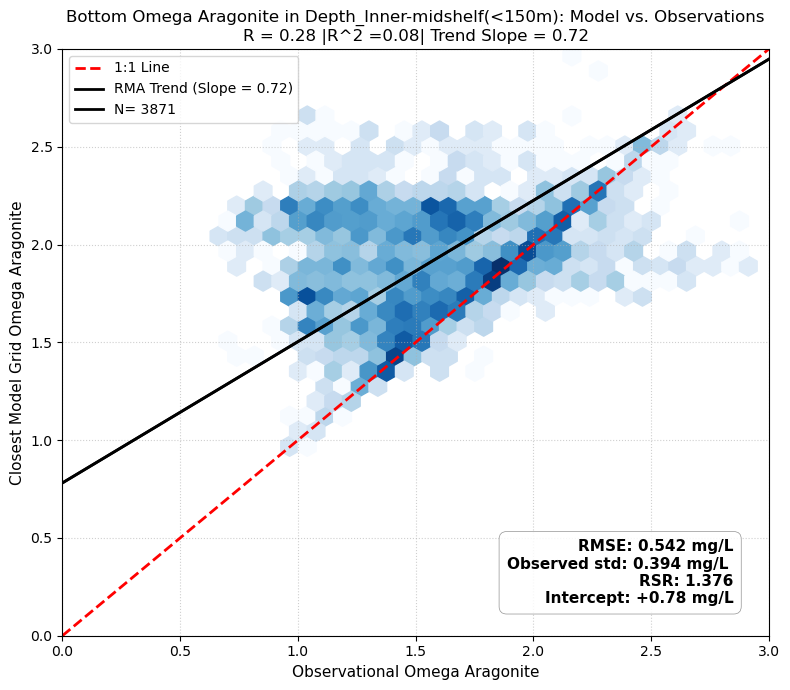


               RUNNING STATISTICS FOR DEPTH: Shelf_slope(<400m)       
Mean of delta difference between model 3x3x3 grid data and observational data in Depth_Shelf_slope(<400m) is: 0.1413
Mean of delta difference between model exact grid data and observational data in Depth_Shelf_slope(<400m) is: 0.1525
Global RMSE (3x3x3 grid vs obs) between model and observations in Depth_Shelf_slope(<400m) is: 0.2066
Global RMSE (Exact point vs Obs) between model and observations in Depth_Shelf_slope(<400m) is: 0.2451
-> Calculated using 915 valid exact points in Depth_Shelf_slope(<400m) (out of 915 total pairs).
Calculated Observational Mean: 1.4630
Calculated Model Global Mean: 1.6164
Calculated Global Std Dev: 0.1512
Model grid overestimates the data 84.59 percent of the time
Model grid underestimates the data 15.41 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.1798
When underestimating, the average deficit aragonite (Ω) is: -0.0700
Real-World Observational STD:

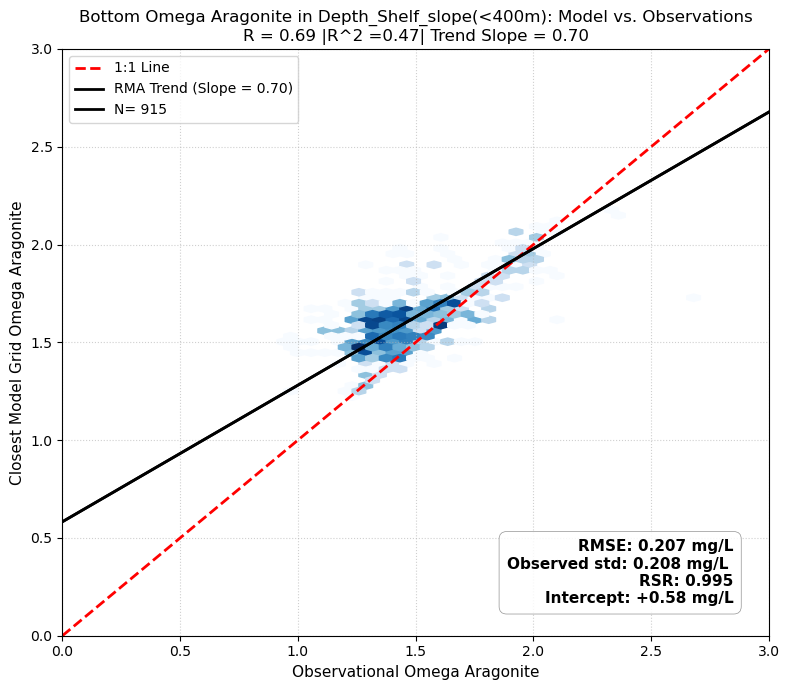


               RUNNING STATISTICS FOR DEPTH: Deep(>400m)       
Mean of delta difference between model 3x3x3 grid data and observational data in Depth_Deep(>400m) is: -0.0021
Mean of delta difference between model exact grid data and observational data in Depth_Deep(>400m) is: 0.0268
Global RMSE (3x3x3 grid vs obs) between model and observations in Depth_Deep(>400m) is: 0.0164
Global RMSE (Exact point vs Obs) between model and observations in Depth_Deep(>400m) is: 0.0666
-> Calculated using 15 valid exact points in Depth_Deep(>400m) (out of 15 total pairs).
Calculated Observational Mean: 1.1273
Calculated Model Global Mean: 1.1728
Calculated Global Std Dev: 0.2687
Model grid overestimates the data 33.33 percent of the time
Model grid underestimates the data 66.67 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.0125
When underestimating, the average deficit aragonite (Ω) is: -0.0094
Real-World Observational STD: 0.1978
Model Global STD: 0.2687
Model-to-O

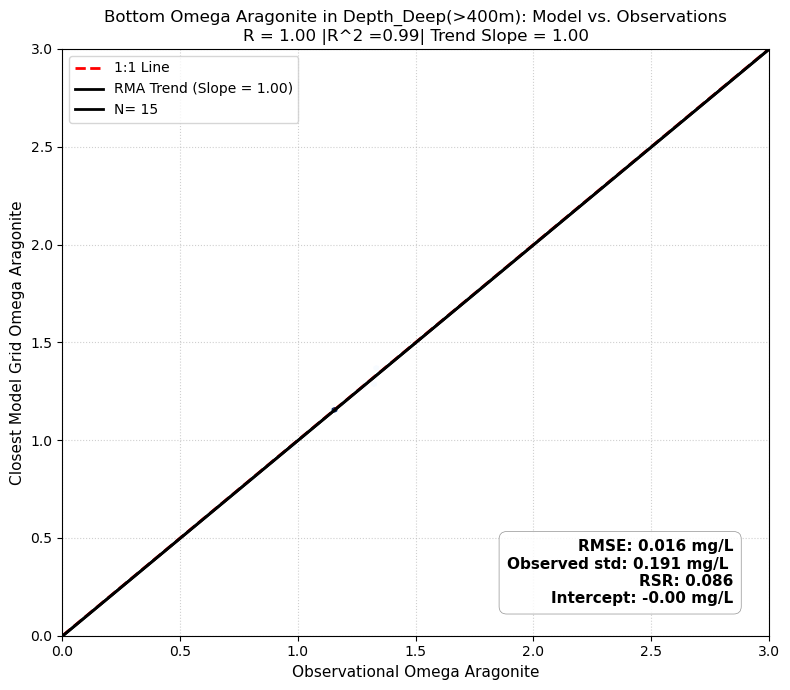


 Running Region x Year intersections...
Mean of delta difference between model 3x3x3 grid data and observational data in MAB_south_2012 is: 0.2396
Mean of delta difference between model exact grid data and observational data in MAB_south_2012 is: 0.3399
Global RMSE (3x3x3 grid vs obs) between model and observations in MAB_south_2012 is: 0.3876
Global RMSE (Exact point vs Obs) between model and observations in MAB_south_2012 is: 0.4799
-> Calculated using 8 valid exact points in MAB_south_2012 (out of 8 total pairs).
Calculated Observational Mean: 1.7894
Calculated Model Global Mean: 2.1229
Calculated Global Std Dev: 0.5439
Model grid overestimates the data 100.00 percent of the time
Model grid underestimates the data 0.00 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.2396
When underestimating, the average deficit aragonite (Ω) is: nan
Real-World Observational STD: 0.4281
Model Global STD: 0.5439
Model-to-Observation Variance Ratio: 1.27
Model Grid RSR

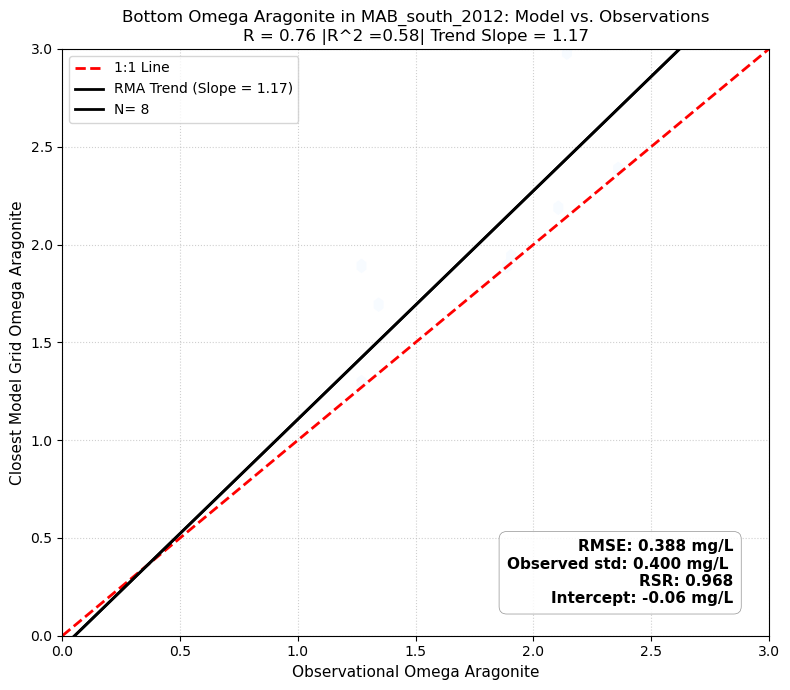

Mean of delta difference between model 3x3x3 grid data and observational data in MAB_south_2013 is: 0.1070
Mean of delta difference between model exact grid data and observational data in MAB_south_2013 is: 0.1420
Global RMSE (3x3x3 grid vs obs) between model and observations in MAB_south_2013 is: 0.3419
Global RMSE (Exact point vs Obs) between model and observations in MAB_south_2013 is: 0.3741
-> Calculated using 5 valid exact points in MAB_south_2013 (out of 5 total pairs).
Calculated Observational Mean: 1.8320
Calculated Model Global Mean: 1.9726
Calculated Global Std Dev: 0.3889
Model grid overestimates the data 80.00 percent of the time
Model grid underestimates the data 20.00 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.2203
When underestimating, the average deficit aragonite (Ω) is: -0.3460
Real-World Observational STD: 0.3663
Model Global STD: 0.3889
Model-to-Observation Variance Ratio: 1.06
Model Grid RSR: 1.0811

ARAGONITE STRESSED STATUS M

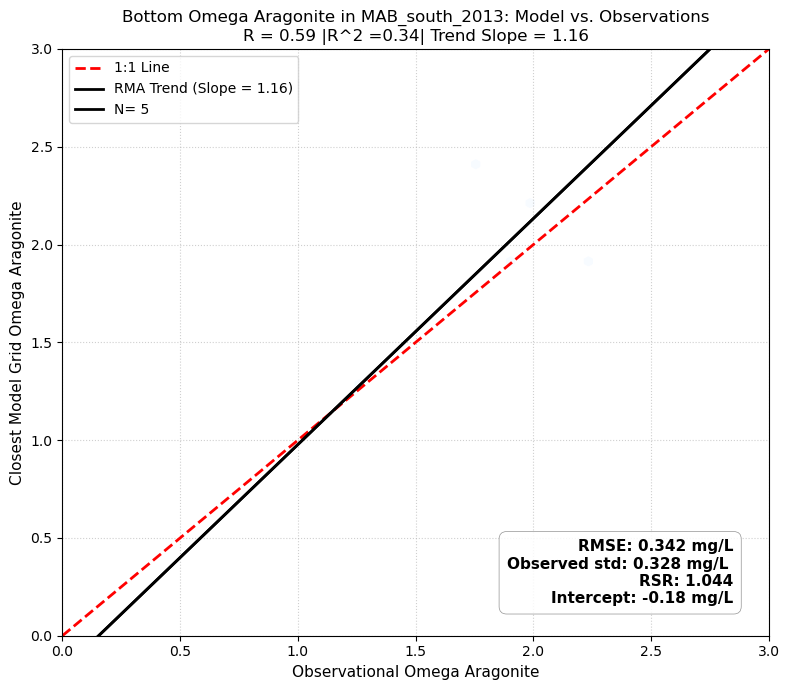

Mean of delta difference between model 3x3x3 grid data and observational data in MAB_south_2015 is: 0.1575
Mean of delta difference between model exact grid data and observational data in MAB_south_2015 is: 0.1725
Global RMSE (3x3x3 grid vs obs) between model and observations in MAB_south_2015 is: 0.2572
Global RMSE (Exact point vs Obs) between model and observations in MAB_south_2015 is: 0.3772
-> Calculated using 12 valid exact points in MAB_south_2015 (out of 12 total pairs).
Calculated Observational Mean: 1.9425
Calculated Model Global Mean: 2.1134
Calculated Global Std Dev: 0.3899
Model grid overestimates the data 66.67 percent of the time
Model grid underestimates the data 33.33 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.2579
When underestimating, the average deficit aragonite (Ω) is: -0.0431
Real-World Observational STD: 0.2623
Model Global STD: 0.3899
Model-to-Observation Variance Ratio: 1.49
Model Grid RSR: 0.8131


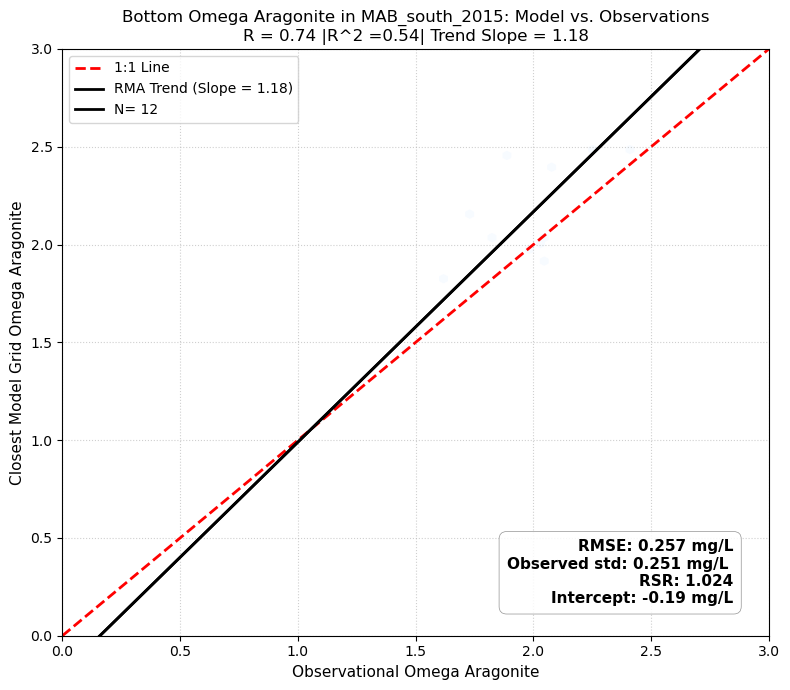

Mean of delta difference between model 3x3x3 grid data and observational data in MAB_south_2016 is: 0.4626
Mean of delta difference between model exact grid data and observational data in MAB_south_2016 is: 0.5390
Global RMSE (3x3x3 grid vs obs) between model and observations in MAB_south_2016 is: 0.6623
Global RMSE (Exact point vs Obs) between model and observations in MAB_south_2016 is: 0.8721
-> Calculated using 10 valid exact points in MAB_south_2016 (out of 10 total pairs).
Calculated Observational Mean: 1.5650
Calculated Model Global Mean: 2.1277
Calculated Global Std Dev: 0.5767
Model grid overestimates the data 80.00 percent of the time
Model grid underestimates the data 20.00 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.5815
When underestimating, the average deficit aragonite (Ω) is: -0.0131
Real-World Observational STD: 0.4336
Model Global STD: 0.5767
Model-to-Observation Variance Ratio: 1.33
Model Grid RSR: 2.0939

ARAGONITE STRESSED STATUS

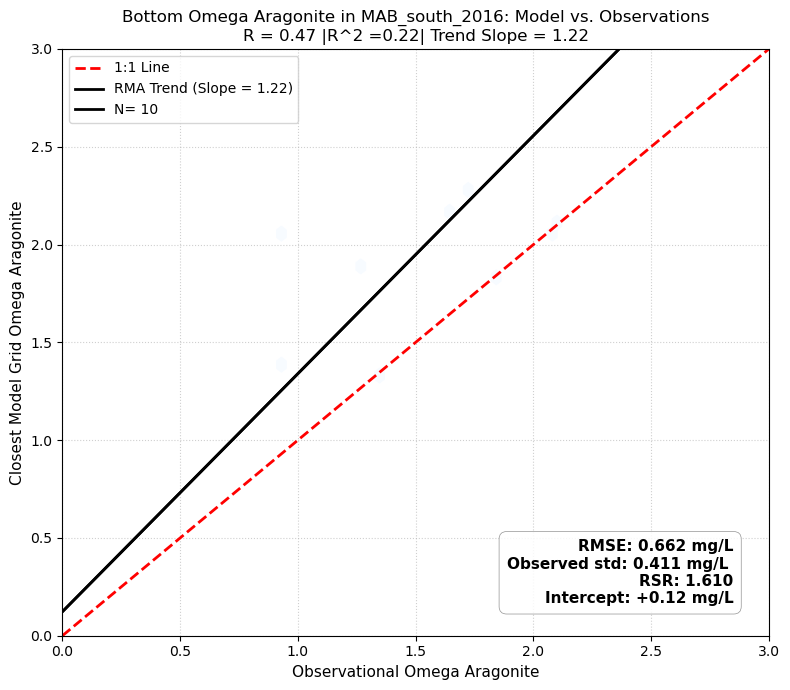

Mean of delta difference between model 3x3x3 grid data and observational data in MAB_south_2017 is: 0.2346
Mean of delta difference between model exact grid data and observational data in MAB_south_2017 is: 0.3950
Global RMSE (3x3x3 grid vs obs) between model and observations in MAB_south_2017 is: 0.3490
Global RMSE (Exact point vs Obs) between model and observations in MAB_south_2017 is: 0.4816
-> Calculated using 9 valid exact points in MAB_south_2017 (out of 9 total pairs).
Calculated Observational Mean: 1.7022
Calculated Model Global Mean: 2.1429
Calculated Global Std Dev: 0.4724
Model grid overestimates the data 100.00 percent of the time
Model grid underestimates the data 0.00 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.2346
When underestimating, the average deficit aragonite (Ω) is: nan
Real-World Observational STD: 0.3114
Model Global STD: 0.4724
Model-to-Observation Variance Ratio: 1.52
Model Grid RSR: 1.1034

ARAGONITE STRESSED STATUS MATCH

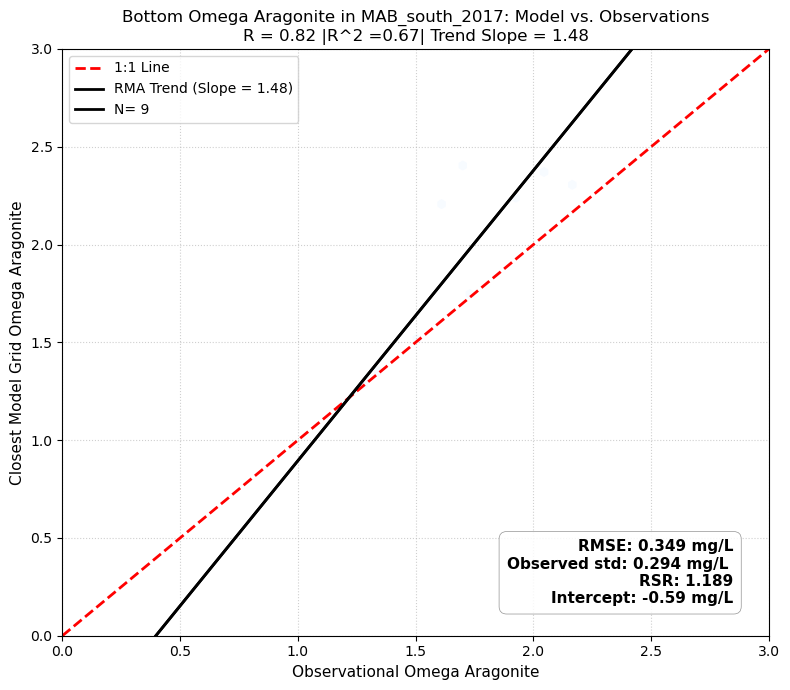

Mean of delta difference between model 3x3x3 grid data and observational data in MAB_south_2018 is: 0.3974
Mean of delta difference between model exact grid data and observational data in MAB_south_2018 is: 0.4317
Global RMSE (3x3x3 grid vs obs) between model and observations in MAB_south_2018 is: 0.5277
Global RMSE (Exact point vs Obs) between model and observations in MAB_south_2018 is: 0.6504
-> Calculated using 13 valid exact points in MAB_south_2018 (out of 13 total pairs).
Calculated Observational Mean: 1.7815
Calculated Model Global Mean: 2.1977
Calculated Global Std Dev: 0.4133
Model grid overestimates the data 92.31 percent of the time
Model grid underestimates the data 7.69 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.4310
When underestimating, the average deficit aragonite (Ω) is: -0.0060
Real-World Observational STD: 0.2180
Model Global STD: 0.4133
Model-to-Observation Variance Ratio: 1.90
Model Grid RSR: 1.6682


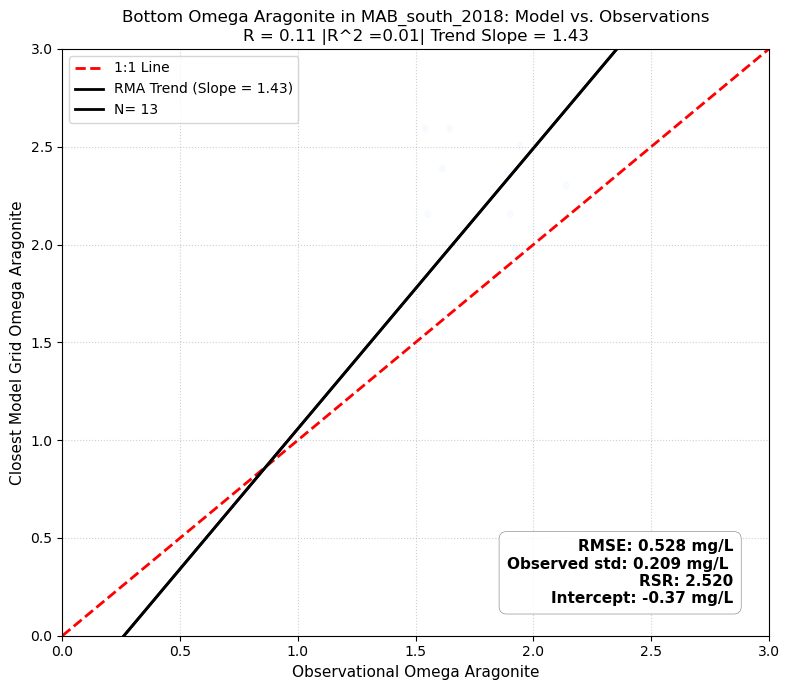

Mean of delta difference between model 3x3x3 grid data and observational data in MAB_south_2019 is: 0.4015
Mean of delta difference between model exact grid data and observational data in MAB_south_2019 is: 0.4995
Global RMSE (3x3x3 grid vs obs) between model and observations in MAB_south_2019 is: 0.5754
Global RMSE (Exact point vs Obs) between model and observations in MAB_south_2019 is: 0.7113
-> Calculated using 19 valid exact points in MAB_south_2019 (out of 19 total pairs).
Calculated Observational Mean: 1.6537
Calculated Model Global Mean: 2.1527
Calculated Global Std Dev: 0.6060
Model grid overestimates the data 68.42 percent of the time
Model grid underestimates the data 31.58 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.6164
When underestimating, the average deficit aragonite (Ω) is: -0.0640
Real-World Observational STD: 0.5433
Model Global STD: 0.6060
Model-to-Observation Variance Ratio: 1.12
Model Grid RSR: 1.8190

ARAGONITE STRESSED STATUS

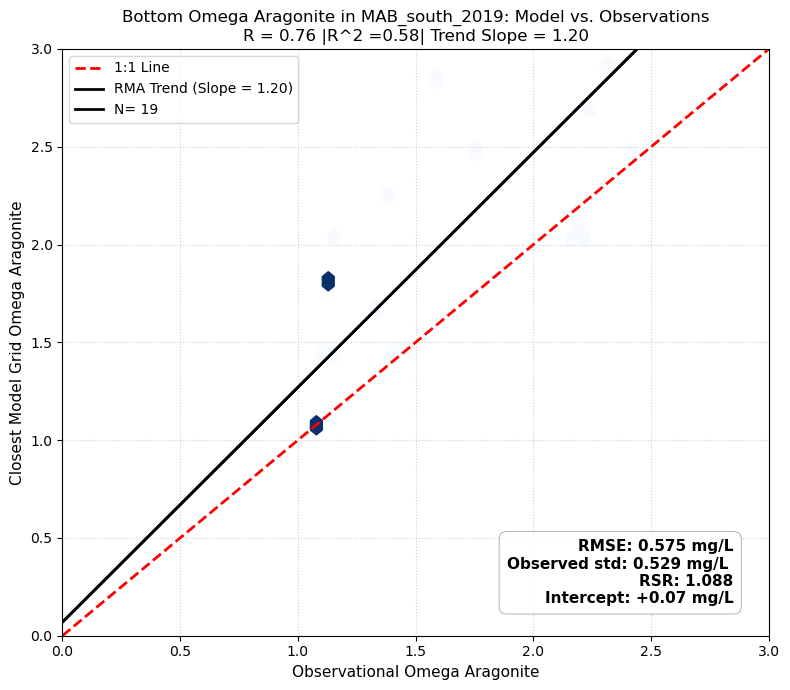

Mean of delta difference between model 3x3x3 grid data and observational data in MAB_south_2021 is: 0.0388
Mean of delta difference between model exact grid data and observational data in MAB_south_2021 is: 0.0432
Global RMSE (3x3x3 grid vs obs) between model and observations in MAB_south_2021 is: 0.2806
Global RMSE (Exact point vs Obs) between model and observations in MAB_south_2021 is: 0.3595
-> Calculated using 415 valid exact points in MAB_south_2021 (out of 415 total pairs).
Calculated Observational Mean: 1.8936
Calculated Model Global Mean: 1.9323
Calculated Global Std Dev: 0.2003
Model grid overestimates the data 65.54 percent of the time
Model grid underestimates the data 34.46 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.1650
When underestimating, the average deficit aragonite (Ω) is: -0.2014
Real-World Observational STD: 0.3300
Model Global STD: 0.2003
Model-to-Observation Variance Ratio: 0.61
Model Grid RSR: 0.8871

ARAGONITE STRESSED STAT

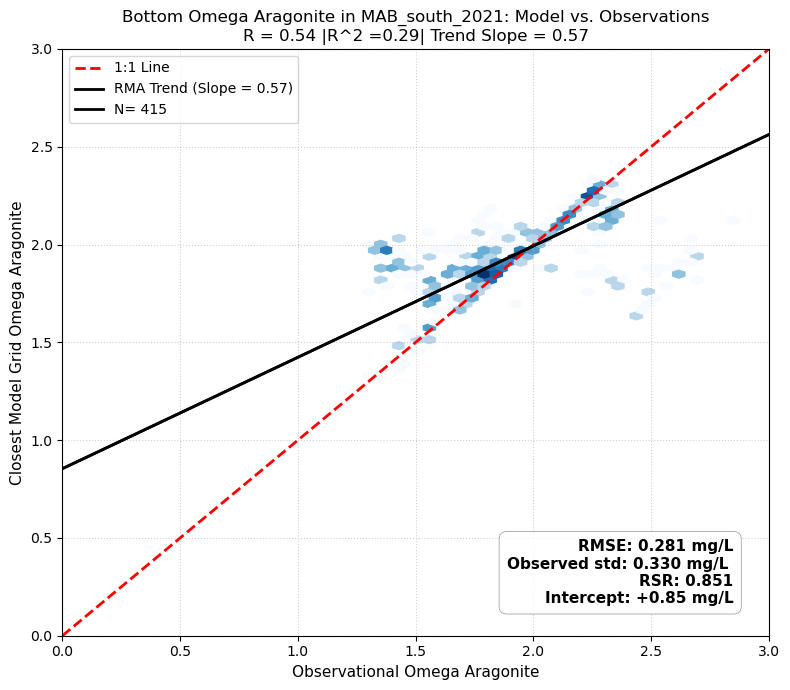

Mean of delta difference between model 3x3x3 grid data and observational data in MAB_south_2022 is: 0.0574
Mean of delta difference between model exact grid data and observational data in MAB_south_2022 is: 0.0611
Global RMSE (3x3x3 grid vs obs) between model and observations in MAB_south_2022 is: 0.2677
Global RMSE (Exact point vs Obs) between model and observations in MAB_south_2022 is: 0.4175
-> Calculated using 121 valid exact points in MAB_south_2022 (out of 121 total pairs).
Calculated Observational Mean: 2.0542
Calculated Model Global Mean: 2.0956
Calculated Global Std Dev: 0.4004
Model grid overestimates the data 63.64 percent of the time
Model grid underestimates the data 36.36 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.1613
When underestimating, the average deficit aragonite (Ω) is: -0.1244
Real-World Observational STD: 0.3766
Model Global STD: 0.4004
Model-to-Observation Variance Ratio: 1.06
Model Grid RSR: 0.8464

ARAGONITE STRESSED STAT

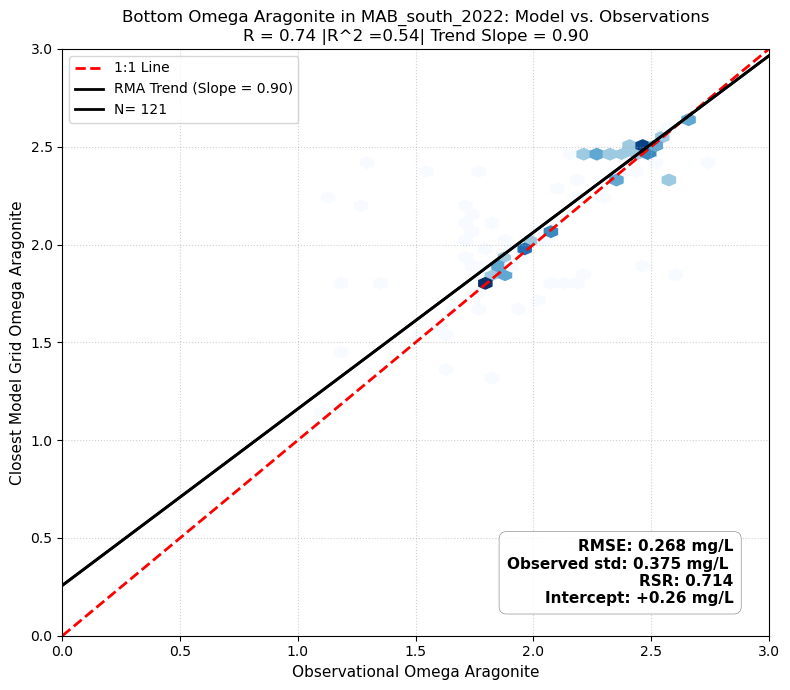

Mean of delta difference between model 3x3x3 grid data and observational data in MAB_south_2023 is: 0.3035
Mean of delta difference between model exact grid data and observational data in MAB_south_2023 is: 0.3597
Global RMSE (3x3x3 grid vs obs) between model and observations in MAB_south_2023 is: 0.4539
Global RMSE (Exact point vs Obs) between model and observations in MAB_south_2023 is: 0.5462
-> Calculated using 394 valid exact points in MAB_south_2023 (out of 394 total pairs).
Calculated Observational Mean: 1.7257
Calculated Model Global Mean: 2.0815
Calculated Global Std Dev: 0.2195
Model grid overestimates the data 79.70 percent of the time
Model grid underestimates the data 20.30 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.4072
When underestimating, the average deficit aragonite (Ω) is: -0.1035
Real-World Observational STD: 0.4513
Model Global STD: 0.2195
Model-to-Observation Variance Ratio: 0.49
Model Grid RSR: 1.4349

ARAGONITE STRESSED STAT

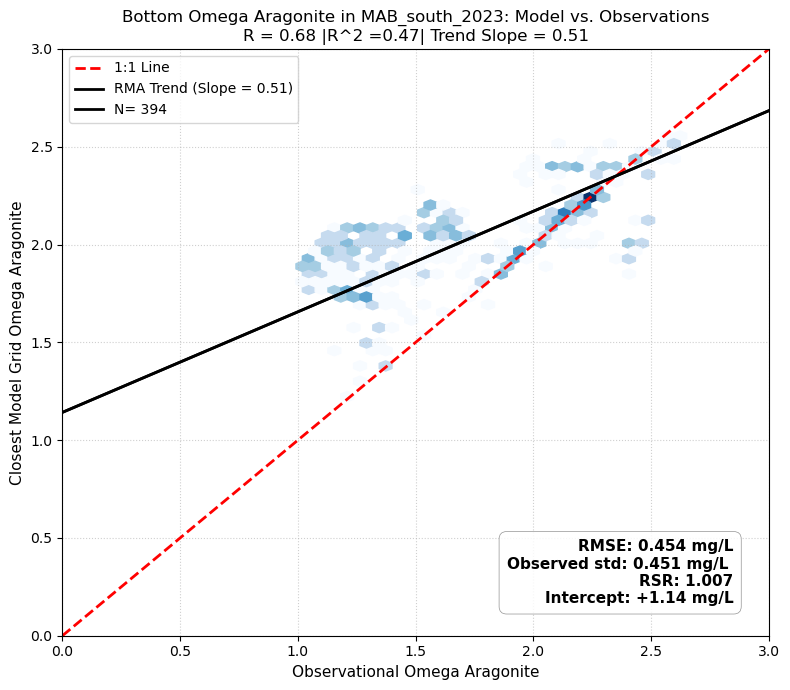

Mean of delta difference between model 3x3x3 grid data and observational data in MAB_south_2024 is: 0.7190
Mean of delta difference between model exact grid data and observational data in MAB_south_2024 is: 0.8330
Global RMSE (3x3x3 grid vs obs) between model and observations in MAB_south_2024 is: 0.8424
Global RMSE (Exact point vs Obs) between model and observations in MAB_south_2024 is: 0.9406
-> Calculated using 535 valid exact points in MAB_south_2024 (out of 535 total pairs).
Calculated Observational Mean: 1.4093
Calculated Model Global Mean: 2.2343
Calculated Global Std Dev: 0.2439
Model grid overestimates the data 94.77 percent of the time
Model grid underestimates the data 5.23 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.7616
When underestimating, the average deficit aragonite (Ω) is: -0.0517
Real-World Observational STD: 0.4268
Model Global STD: 0.2439
Model-to-Observation Variance Ratio: 0.57
Model Grid RSR: 2.6632

ARAGONITE STRESSED STATU

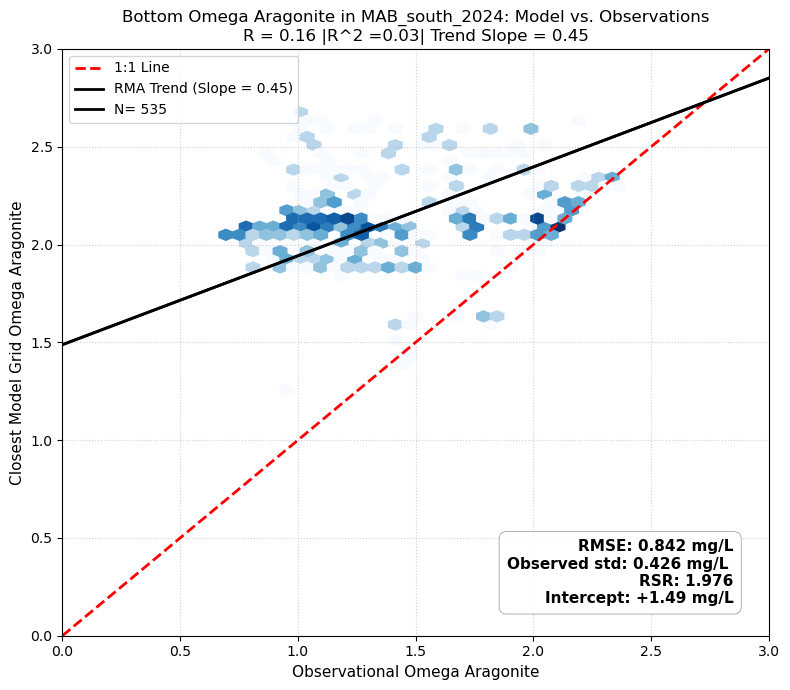

Mean of delta difference between model 3x3x3 grid data and observational data in MAB_south_2025 is: 0.6010
Mean of delta difference between model exact grid data and observational data in MAB_south_2025 is: 0.6931
Global RMSE (3x3x3 grid vs obs) between model and observations in MAB_south_2025 is: 0.6708
Global RMSE (Exact point vs Obs) between model and observations in MAB_south_2025 is: 0.7720
-> Calculated using 250 valid exact points in MAB_south_2025 (out of 250 total pairs).
Calculated Observational Mean: 1.5137
Calculated Model Global Mean: 2.2025
Calculated Global Std Dev: 0.2165
Model grid overestimates the data 95.20 percent of the time
Model grid underestimates the data 4.80 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.6470
When underestimating, the average deficit aragonite (Ω) is: -0.3103
Real-World Observational STD: 0.2622
Model Global STD: 0.2165
Model-to-Observation Variance Ratio: 0.83
Model Grid RSR: 2.1209

ARAGONITE STRESSED STATU

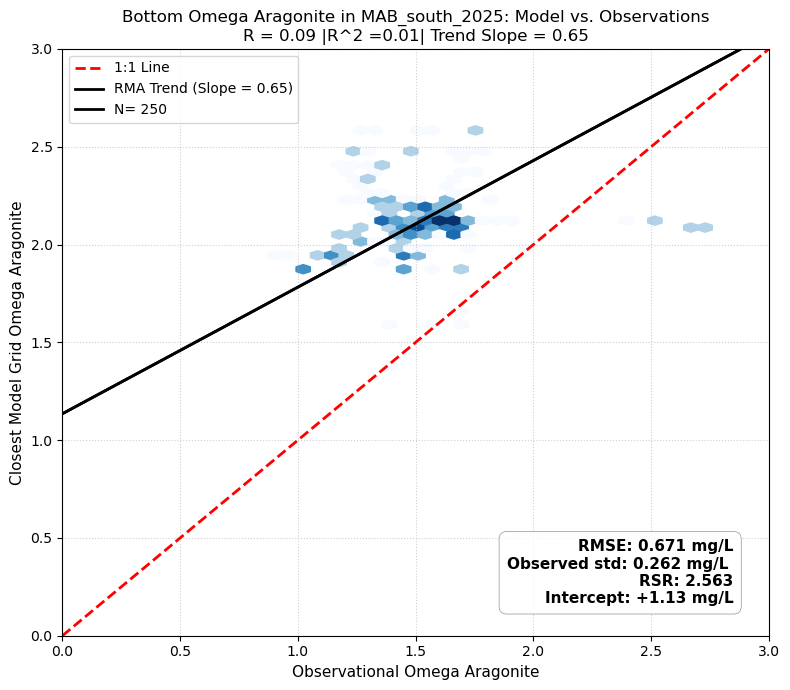

Mean of delta difference between model 3x3x3 grid data and observational data in MAB_north_2007 is: -0.0061
Mean of delta difference between model exact grid data and observational data in MAB_north_2007 is: 0.0866
Global RMSE (3x3x3 grid vs obs) between model and observations in MAB_north_2007 is: 0.0248
Global RMSE (Exact point vs Obs) between model and observations in MAB_north_2007 is: 0.2236
-> Calculated using 3 valid exact points in MAB_north_2007 (out of 3 total pairs).
Calculated Observational Mean: 1.6800
Calculated Model Global Mean: 1.7048
Calculated Global Std Dev: 0.2073
Model grid overestimates the data 33.33 percent of the time
Model grid underestimates the data 66.67 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.0267
When underestimating, the average deficit aragonite (Ω) is: -0.0226
Real-World Observational STD: 0.0436
Model Global STD: 0.2073
Model-to-Observation Variance Ratio: 4.76
Model Grid RSR: 0.0785


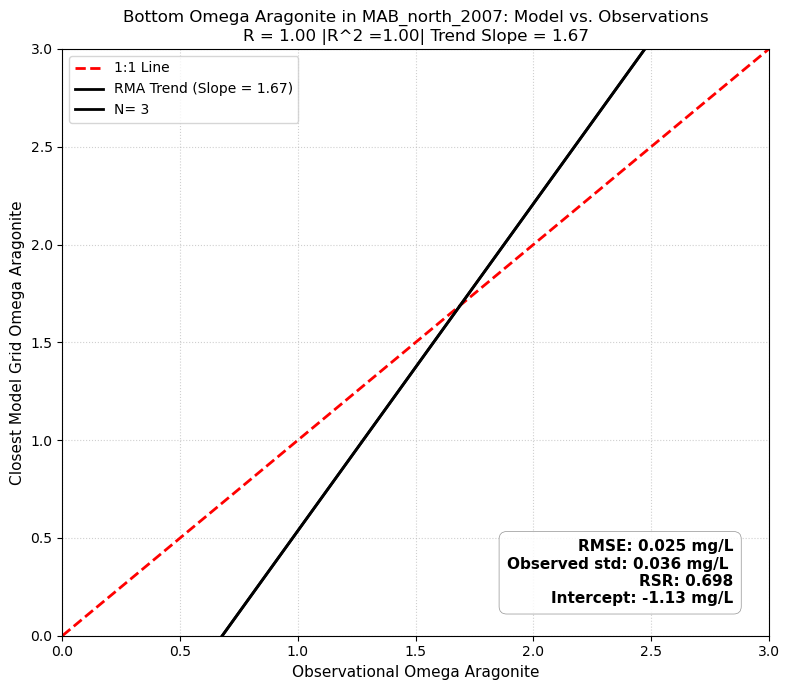

Mean of delta difference between model 3x3x3 grid data and observational data in MAB_north_2012 is: -0.0162
Mean of delta difference between model exact grid data and observational data in MAB_north_2012 is: -0.1202
Global RMSE (3x3x3 grid vs obs) between model and observations in MAB_north_2012 is: 0.0954
Global RMSE (Exact point vs Obs) between model and observations in MAB_north_2012 is: 0.2755
-> Calculated using 8 valid exact points in MAB_north_2012 (out of 8 total pairs).
Calculated Observational Mean: 1.8344
Calculated Model Global Mean: 1.7030
Calculated Global Std Dev: 0.1676
Model grid overestimates the data 62.50 percent of the time
Model grid underestimates the data 37.50 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.0445
When underestimating, the average deficit aragonite (Ω) is: -0.1173
Real-World Observational STD: 0.2230
Model Global STD: 0.1676
Model-to-Observation Variance Ratio: 0.75
Model Grid RSR: 0.3015


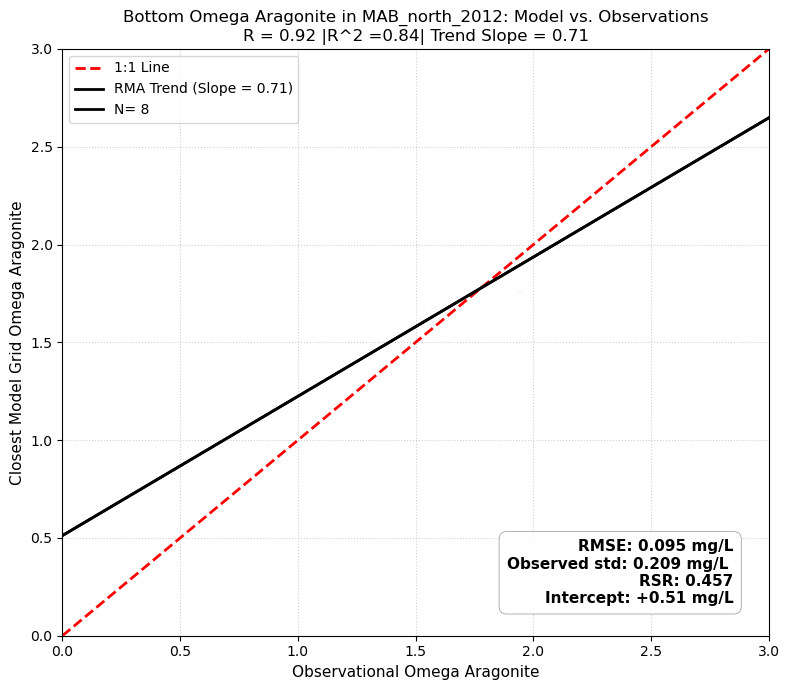

Mean of delta difference between model 3x3x3 grid data and observational data in MAB_north_2013 is: 0.0729
Mean of delta difference between model exact grid data and observational data in MAB_north_2013 is: 0.0833
Global RMSE (3x3x3 grid vs obs) between model and observations in MAB_north_2013 is: 0.1484
Global RMSE (Exact point vs Obs) between model and observations in MAB_north_2013 is: 0.1982
-> Calculated using 5 valid exact points in MAB_north_2013 (out of 5 total pairs).
Calculated Observational Mean: 1.7460
Calculated Model Global Mean: 1.7945
Calculated Global Std Dev: 0.1702
Model grid overestimates the data 40.00 percent of the time
Model grid underestimates the data 60.00 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.2150
When underestimating, the average deficit aragonite (Ω) is: -0.0218
Real-World Observational STD: 0.2192
Model Global STD: 0.1702
Model-to-Observation Variance Ratio: 0.78
Model Grid RSR: 0.4693


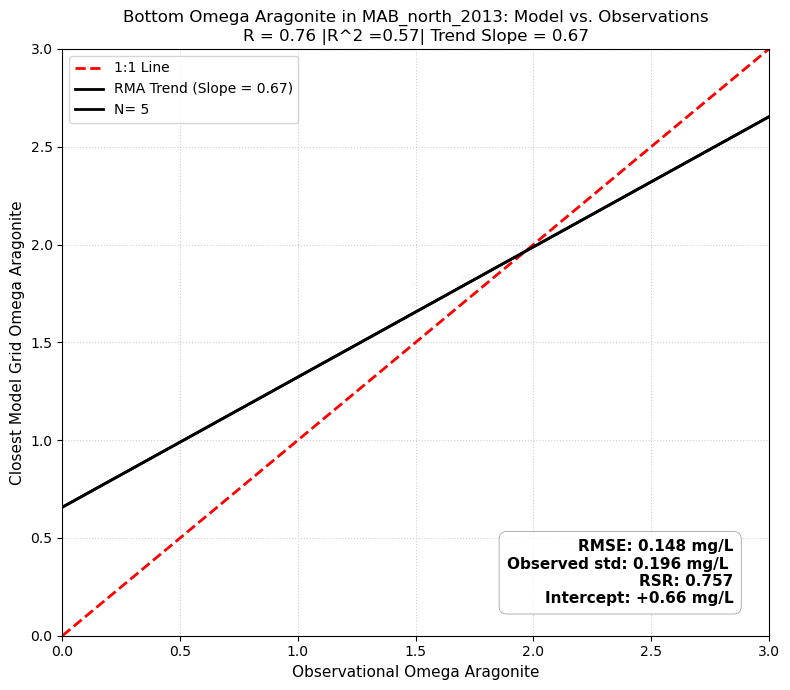

Mean of delta difference between model 3x3x3 grid data and observational data in MAB_north_2014 is: 0.1190
Mean of delta difference between model exact grid data and observational data in MAB_north_2014 is: 0.2080
Global RMSE (3x3x3 grid vs obs) between model and observations in MAB_north_2014 is: 0.1520
Global RMSE (Exact point vs Obs) between model and observations in MAB_north_2014 is: 0.2101
-> Calculated using 5 valid exact points in MAB_north_2014 (out of 5 total pairs).
Calculated Observational Mean: 1.7360
Calculated Model Global Mean: 1.9176
Calculated Global Std Dev: 0.2393
Model grid overestimates the data 80.00 percent of the time
Model grid underestimates the data 20.00 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.1519
When underestimating, the average deficit aragonite (Ω) is: -0.0123
Real-World Observational STD: 0.2261
Model Global STD: 0.2393
Model-to-Observation Variance Ratio: 1.06
Model Grid RSR: 0.4805


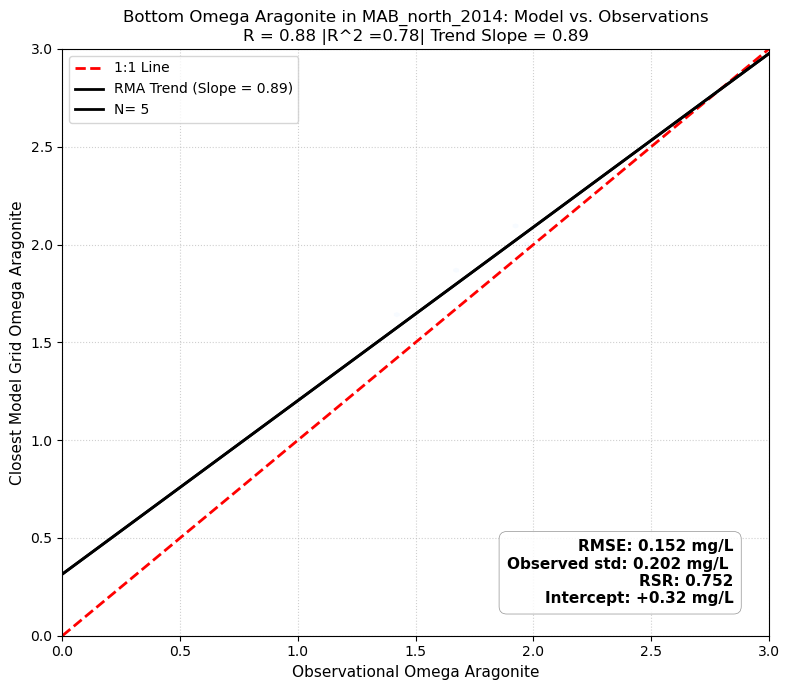

Mean of delta difference between model 3x3x3 grid data and observational data in MAB_north_2015 is: 0.1202
Mean of delta difference between model exact grid data and observational data in MAB_north_2015 is: 0.1310
Global RMSE (3x3x3 grid vs obs) between model and observations in MAB_north_2015 is: 0.2634
Global RMSE (Exact point vs Obs) between model and observations in MAB_north_2015 is: 0.2978
-> Calculated using 10 valid exact points in MAB_north_2015 (out of 10 total pairs).
Calculated Observational Mean: 1.8540
Calculated Model Global Mean: 1.9836
Calculated Global Std Dev: 0.2722
Model grid overestimates the data 80.00 percent of the time
Model grid underestimates the data 20.00 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.1802
When underestimating, the average deficit aragonite (Ω) is: -0.1199
Real-World Observational STD: 0.3840
Model Global STD: 0.2722
Model-to-Observation Variance Ratio: 0.71
Model Grid RSR: 0.8328

ARAGONITE STRESSED STATUS

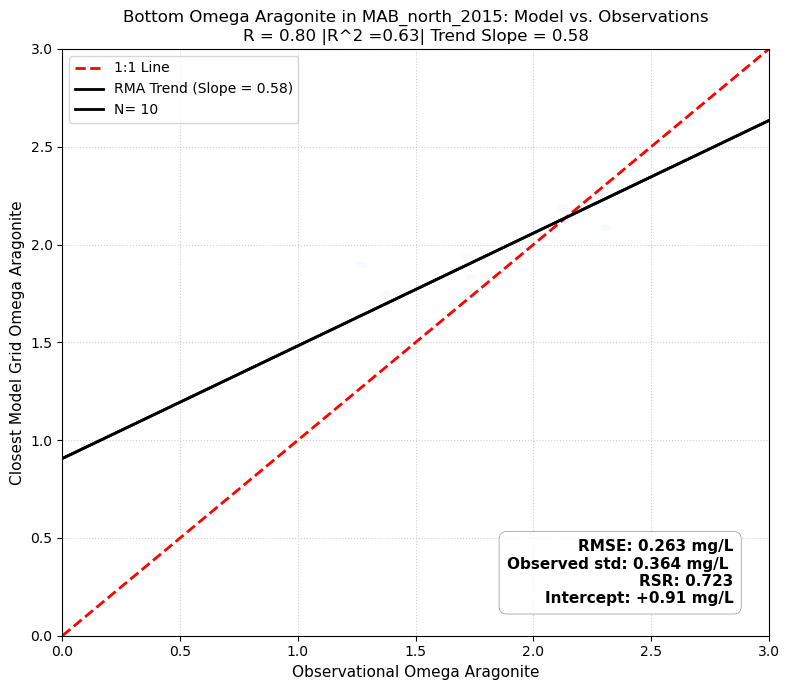

Mean of delta difference between model 3x3x3 grid data and observational data in MAB_north_2016 is: 0.1492
Mean of delta difference between model exact grid data and observational data in MAB_north_2016 is: 0.1001
Global RMSE (3x3x3 grid vs obs) between model and observations in MAB_north_2016 is: 0.2994
Global RMSE (Exact point vs Obs) between model and observations in MAB_north_2016 is: 0.3826
-> Calculated using 8 valid exact points in MAB_north_2016 (out of 8 total pairs).
Calculated Observational Mean: 1.7612
Calculated Model Global Mean: 1.8541
Calculated Global Std Dev: 0.2080
Model grid overestimates the data 62.50 percent of the time
Model grid underestimates the data 37.50 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.3204
When underestimating, the average deficit aragonite (Ω) is: -0.1361
Real-World Observational STD: 0.4929
Model Global STD: 0.2080
Model-to-Observation Variance Ratio: 0.42
Model Grid RSR: 0.9467

ARAGONITE STRESSED STATUS M

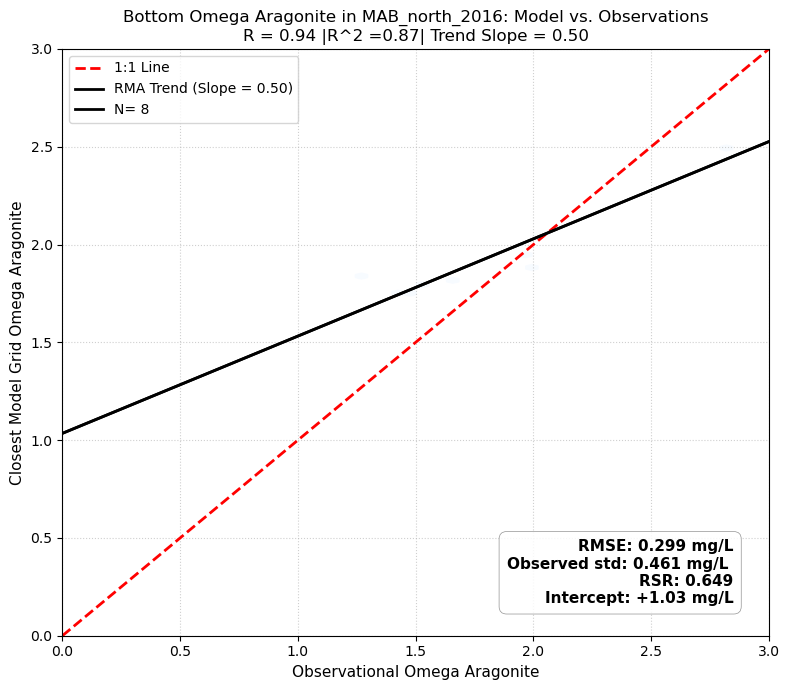

Mean of delta difference between model 3x3x3 grid data and observational data in MAB_north_2017 is: 0.0842
Mean of delta difference between model exact grid data and observational data in MAB_north_2017 is: 0.1817
Global RMSE (3x3x3 grid vs obs) between model and observations in MAB_north_2017 is: 0.1701
Global RMSE (Exact point vs Obs) between model and observations in MAB_north_2017 is: 0.3353
-> Calculated using 5 valid exact points in MAB_north_2017 (out of 5 total pairs).
Calculated Observational Mean: 1.7200
Calculated Model Global Mean: 1.8347
Calculated Global Std Dev: 0.2920
Model grid overestimates the data 60.00 percent of the time
Model grid underestimates the data 40.00 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.1978
When underestimating, the average deficit aragonite (Ω) is: -0.0863
Real-World Observational STD: 0.1498
Model Global STD: 0.2920
Model-to-Observation Variance Ratio: 1.95
Model Grid RSR: 0.5379


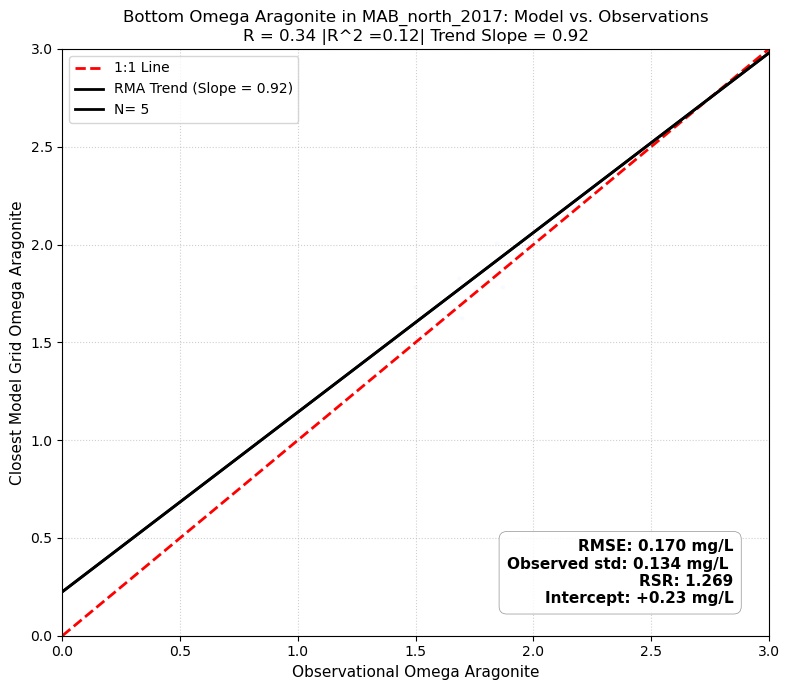

Mean of delta difference between model 3x3x3 grid data and observational data in MAB_north_2018 is: 0.2213
Mean of delta difference between model exact grid data and observational data in MAB_north_2018 is: 0.3010
Global RMSE (3x3x3 grid vs obs) between model and observations in MAB_north_2018 is: 0.3135
Global RMSE (Exact point vs Obs) between model and observations in MAB_north_2018 is: 0.4623
-> Calculated using 25 valid exact points in MAB_north_2018 (out of 25 total pairs).
Calculated Observational Mean: 1.5682
Calculated Model Global Mean: 1.8837
Calculated Global Std Dev: 0.3681
Model grid overestimates the data 88.00 percent of the time
Model grid underestimates the data 12.00 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.2520
When underestimating, the average deficit aragonite (Ω) is: -0.0038
Real-World Observational STD: 0.2329
Model Global STD: 0.3681
Model-to-Observation Variance Ratio: 1.58
Model Grid RSR: 0.9910

ARAGONITE STRESSED STATUS

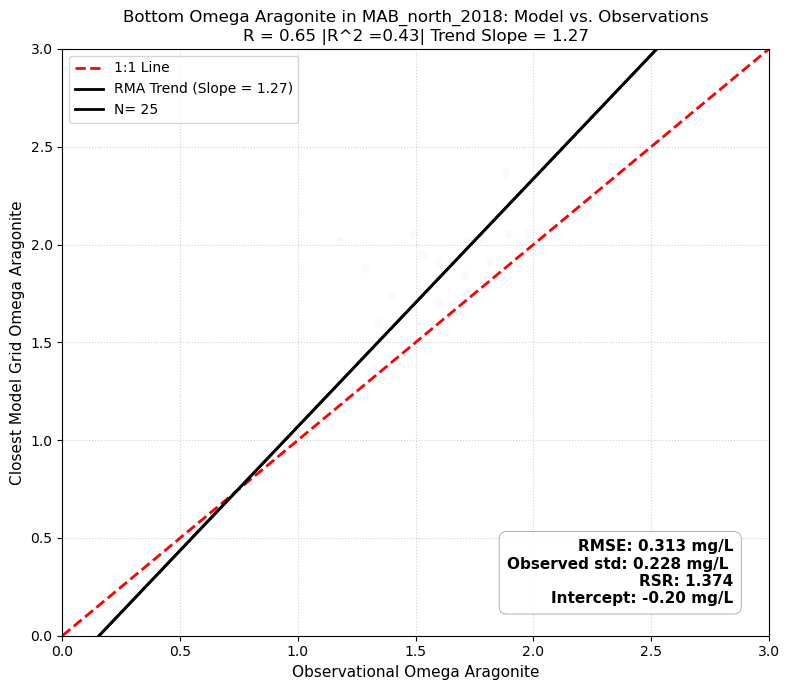

Mean of delta difference between model 3x3x3 grid data and observational data in MAB_north_2019 is: 0.2625
Mean of delta difference between model exact grid data and observational data in MAB_north_2019 is: 0.4212
Global RMSE (3x3x3 grid vs obs) between model and observations in MAB_north_2019 is: 0.4372
Global RMSE (Exact point vs Obs) between model and observations in MAB_north_2019 is: 0.5590
-> Calculated using 34 valid exact points in MAB_north_2019 (out of 34 total pairs).
Calculated Observational Mean: 1.3635
Calculated Model Global Mean: 1.7547
Calculated Global Std Dev: 0.3221
Model grid overestimates the data 67.65 percent of the time
Model grid underestimates the data 32.35 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.4166
When underestimating, the average deficit aragonite (Ω) is: -0.0598
Real-World Observational STD: 0.4188
Model Global STD: 0.3221
Model-to-Observation Variance Ratio: 0.77
Model Grid RSR: 1.3822

ARAGONITE STRESSED STATUS

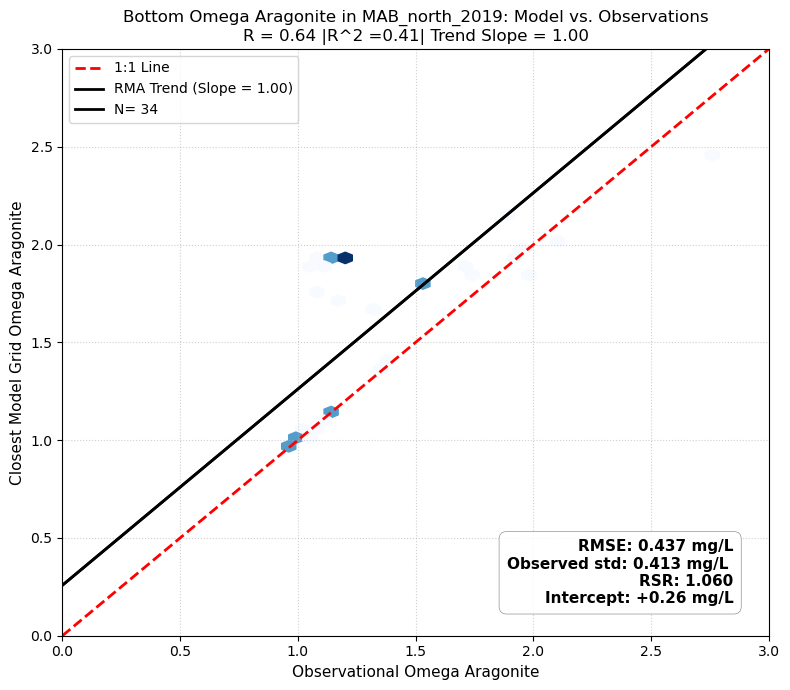

Mean of delta difference between model 3x3x3 grid data and observational data in MAB_north_2021 is: 0.0172
Mean of delta difference between model exact grid data and observational data in MAB_north_2021 is: 0.0174
Global RMSE (3x3x3 grid vs obs) between model and observations in MAB_north_2021 is: 0.2864
Global RMSE (Exact point vs Obs) between model and observations in MAB_north_2021 is: 0.3359
-> Calculated using 339 valid exact points in MAB_north_2021 (out of 339 total pairs).
Calculated Observational Mean: 1.7692
Calculated Model Global Mean: 1.7888
Calculated Global Std Dev: 0.1760
Model grid overestimates the data 57.23 percent of the time
Model grid underestimates the data 42.77 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.1891
When underestimating, the average deficit aragonite (Ω) is: -0.2128
Real-World Observational STD: 0.3846
Model Global STD: 0.1760
Model-to-Observation Variance Ratio: 0.46
Model Grid RSR: 0.9055

ARAGONITE STRESSED STAT

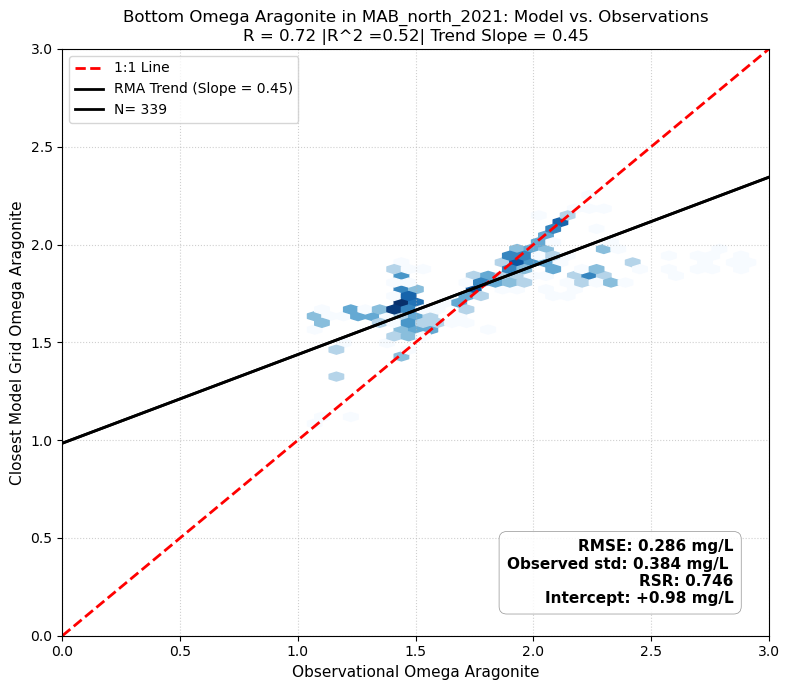

Mean of delta difference between model 3x3x3 grid data and observational data in MAB_north_2022 is: 0.1549
Mean of delta difference between model exact grid data and observational data in MAB_north_2022 is: 0.1846
Global RMSE (3x3x3 grid vs obs) between model and observations in MAB_north_2022 is: 0.3249
Global RMSE (Exact point vs Obs) between model and observations in MAB_north_2022 is: 0.4185
-> Calculated using 309 valid exact points in MAB_north_2022 (out of 309 total pairs).
Calculated Observational Mean: 1.6419
Calculated Model Global Mean: 1.8280
Calculated Global Std Dev: 0.2637
Model grid overestimates the data 73.46 percent of the time
Model grid underestimates the data 26.54 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.2735
When underestimating, the average deficit aragonite (Ω) is: -0.1734
Real-World Observational STD: 0.3559
Model Global STD: 0.2637
Model-to-Observation Variance Ratio: 0.74
Model Grid RSR: 1.0270

ARAGONITE STRESSED STAT

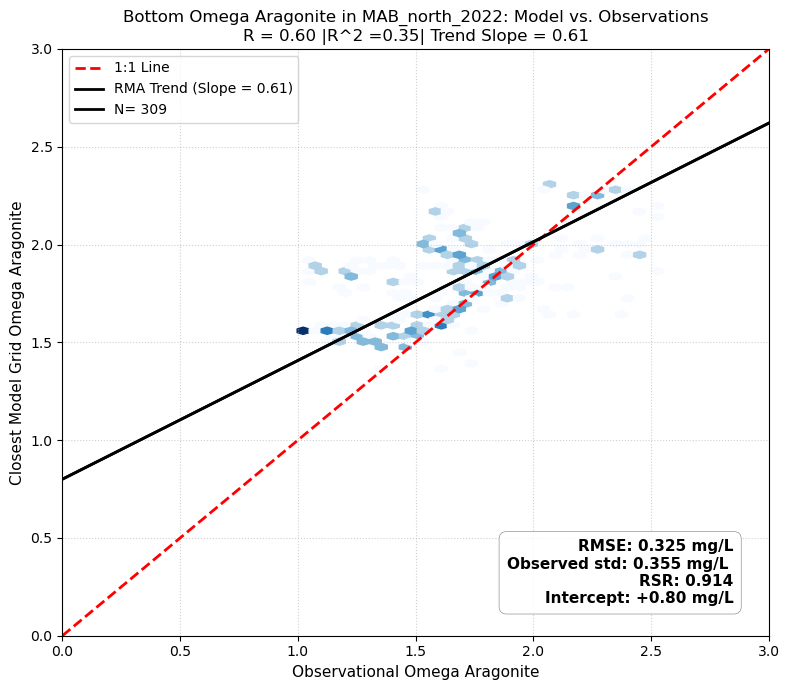

Mean of delta difference between model 3x3x3 grid data and observational data in MAB_north_2023 is: 0.4290
Mean of delta difference between model exact grid data and observational data in MAB_north_2023 is: 0.4923
Global RMSE (3x3x3 grid vs obs) between model and observations in MAB_north_2023 is: 0.5162
Global RMSE (Exact point vs Obs) between model and observations in MAB_north_2023 is: 0.5796
-> Calculated using 506 valid exact points in MAB_north_2023 (out of 506 total pairs).
Calculated Observational Mean: 1.3375
Calculated Model Global Mean: 1.8263
Calculated Global Std Dev: 0.1639
Model grid overestimates the data 90.71 percent of the time
Model grid underestimates the data 9.29 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.4810
When underestimating, the average deficit aragonite (Ω) is: -0.0786
Real-World Observational STD: 0.3124
Model Global STD: 0.1639
Model-to-Observation Variance Ratio: 0.52
Model Grid RSR: 1.6320

ARAGONITE STRESSED STATU

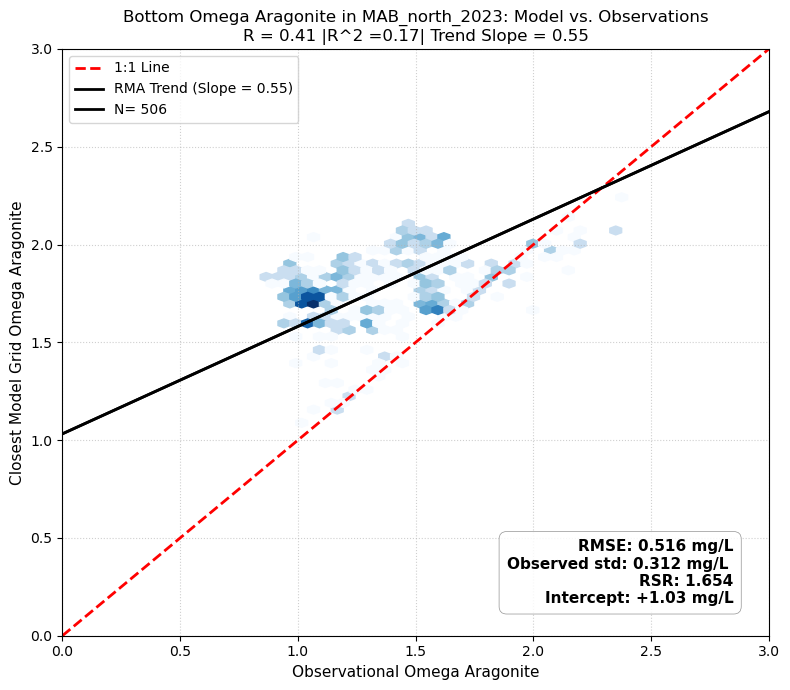

Mean of delta difference between model 3x3x3 grid data and observational data in MAB_north_2024 is: 0.8223
Mean of delta difference between model exact grid data and observational data in MAB_north_2024 is: 0.8643
Global RMSE (3x3x3 grid vs obs) between model and observations in MAB_north_2024 is: 0.9129
Global RMSE (Exact point vs Obs) between model and observations in MAB_north_2024 is: 0.9481
-> Calculated using 338 valid exact points in MAB_north_2024 (out of 338 total pairs).
Calculated Observational Mean: 1.3243
Calculated Model Global Mean: 2.1831
Calculated Global Std Dev: 0.1018
Model grid overestimates the data 99.41 percent of the time
Model grid underestimates the data 0.59 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.8273
When underestimating, the average deficit aragonite (Ω) is: -0.0166
Real-World Observational STD: 0.3844
Model Global STD: 0.1018
Model-to-Observation Variance Ratio: 0.26
Model Grid RSR: 2.8863

ARAGONITE STRESSED STATU

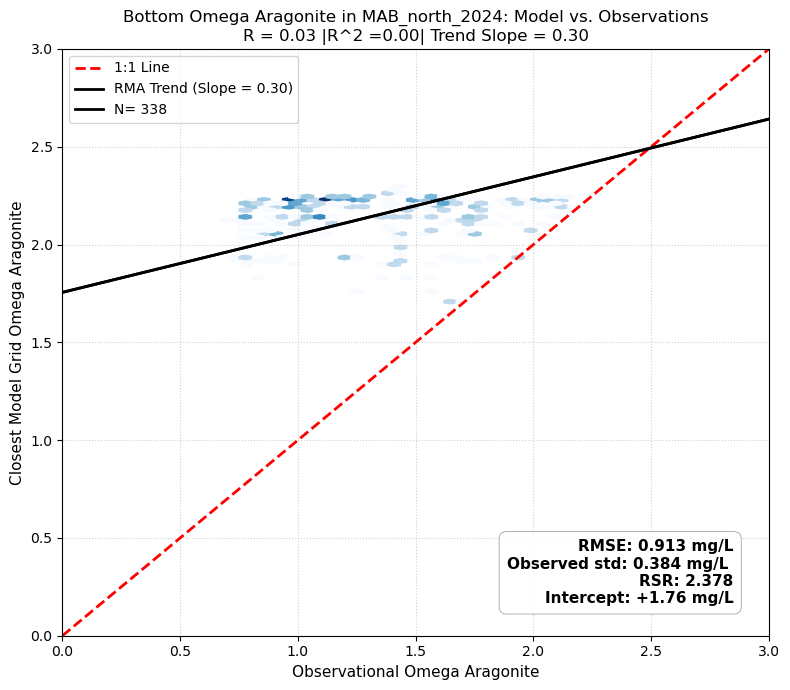

Mean of delta difference between model 3x3x3 grid data and observational data in MAB_north_2025 is: 0.7132
Mean of delta difference between model exact grid data and observational data in MAB_north_2025 is: 0.7686
Global RMSE (3x3x3 grid vs obs) between model and observations in MAB_north_2025 is: 0.7539
Global RMSE (Exact point vs Obs) between model and observations in MAB_north_2025 is: 0.8094
-> Calculated using 211 valid exact points in MAB_north_2025 (out of 211 total pairs).
Calculated Observational Mean: 1.4439
Calculated Model Global Mean: 2.2086
Calculated Global Std Dev: 0.0812
Model grid overestimates the data 100.00 percent of the time
Model grid underestimates the data 0.00 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.7132
When underestimating, the average deficit aragonite (Ω) is: nan
Real-World Observational STD: 0.2360
Model Global STD: 0.0812
Model-to-Observation Variance Ratio: 0.34
Model Grid RSR: 2.3834

ARAGONITE STRESSED STATUS M

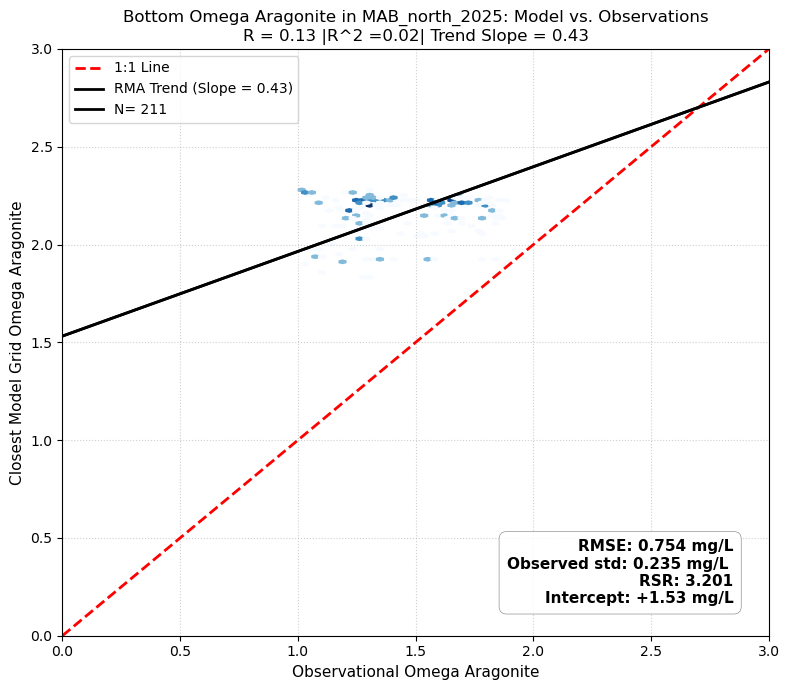

Mean of delta difference between model 3x3x3 grid data and observational data in GB_2013 is: 0.1438
Mean of delta difference between model exact grid data and observational data in GB_2013 is: 0.1164
Global RMSE (3x3x3 grid vs obs) between model and observations in GB_2013 is: 0.1785
Global RMSE (Exact point vs Obs) between model and observations in GB_2013 is: 0.2389
-> Calculated using 3 valid exact points in GB_2013 (out of 3 total pairs).
Calculated Observational Mean: 1.7067
Calculated Model Global Mean: 1.8550
Calculated Global Std Dev: 0.2888
Model grid overestimates the data 100.00 percent of the time
Model grid underestimates the data 0.00 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.1438
When underestimating, the average deficit aragonite (Ω) is: nan
Real-World Observational STD: 0.1686
Model Global STD: 0.2888
Model-to-Observation Variance Ratio: 1.71
Model Grid RSR: 0.5643


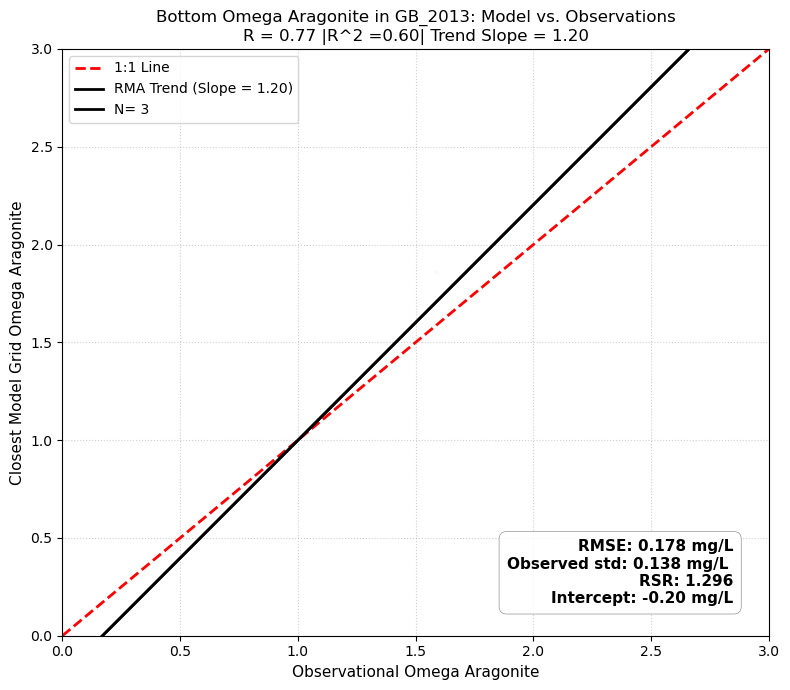

Mean of delta difference between model 3x3x3 grid data and observational data in GB_2014 is: 0.0969
Mean of delta difference between model exact grid data and observational data in GB_2014 is: 0.1081
Global RMSE (3x3x3 grid vs obs) between model and observations in GB_2014 is: 0.1939
Global RMSE (Exact point vs Obs) between model and observations in GB_2014 is: 0.2089
-> Calculated using 3 valid exact points in GB_2014 (out of 3 total pairs).
Calculated Observational Mean: 1.5167
Calculated Model Global Mean: 1.6791
Calculated Global Std Dev: 0.1921
Model grid overestimates the data 66.67 percent of the time
Model grid underestimates the data 33.33 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.1754
When underestimating, the average deficit aragonite (Ω) is: -0.0602
Real-World Observational STD: 0.1365
Model Global STD: 0.1921
Model-to-Observation Variance Ratio: 1.41
Model Grid RSR: 0.6130

ARAGONITE STRESSED STATUS MATCH METRICS (Numeric: Threshold < 

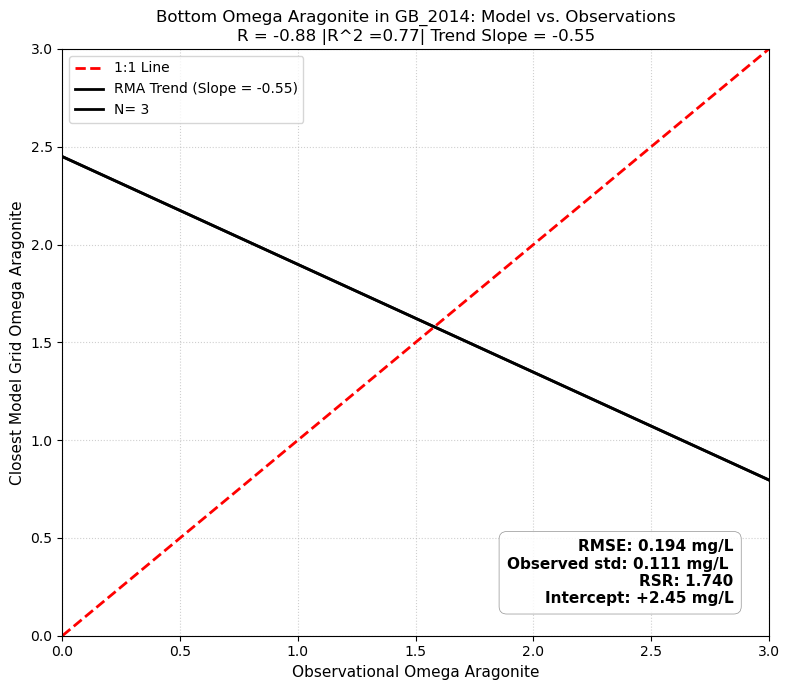

Mean of delta difference between model 3x3x3 grid data and observational data in GB_2015 is: 0.2007
Mean of delta difference between model exact grid data and observational data in GB_2015 is: 0.2440
Global RMSE (3x3x3 grid vs obs) between model and observations in GB_2015 is: 0.2664
Global RMSE (Exact point vs Obs) between model and observations in GB_2015 is: 0.3162
-> Calculated using 7 valid exact points in GB_2015 (out of 7 total pairs).
Calculated Observational Mean: 1.6914
Calculated Model Global Mean: 1.9661
Calculated Global Std Dev: 0.3302
Model grid overestimates the data 85.71 percent of the time
Model grid underestimates the data 14.29 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.2422
When underestimating, the average deficit aragonite (Ω) is: -0.0482
Real-World Observational STD: 0.2040
Model Global STD: 0.3302
Model-to-Observation Variance Ratio: 1.62
Model Grid RSR: 0.8423


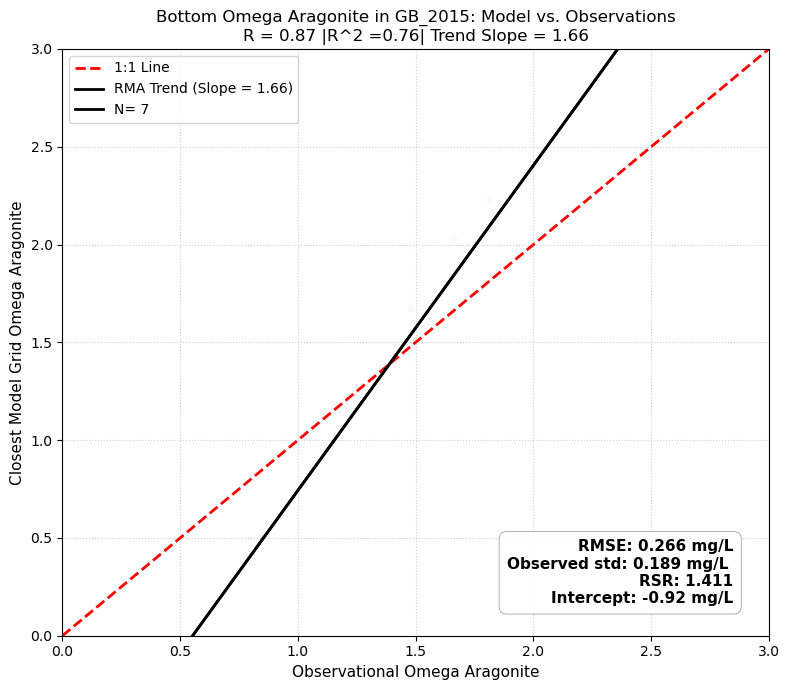

Mean of delta difference between model 3x3x3 grid data and observational data in GB_2016 is: 0.1664
Mean of delta difference between model exact grid data and observational data in GB_2016 is: 0.2392
Global RMSE (3x3x3 grid vs obs) between model and observations in GB_2016 is: 0.2326
Global RMSE (Exact point vs Obs) between model and observations in GB_2016 is: 0.2793
-> Calculated using 5 valid exact points in GB_2016 (out of 5 total pairs).
Calculated Observational Mean: 1.7000
Calculated Model Global Mean: 1.9575
Calculated Global Std Dev: 0.2247
Model grid overestimates the data 80.00 percent of the time
Model grid underestimates the data 20.00 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.2081
When underestimating, the average deficit aragonite (Ω) is: -0.0006
Real-World Observational STD: 0.2684
Model Global STD: 0.2247
Model-to-Observation Variance Ratio: 0.84
Model Grid RSR: 0.7355

ARAGONITE STRESSED STATUS MATCH METRICS (Numeric: Threshold < 

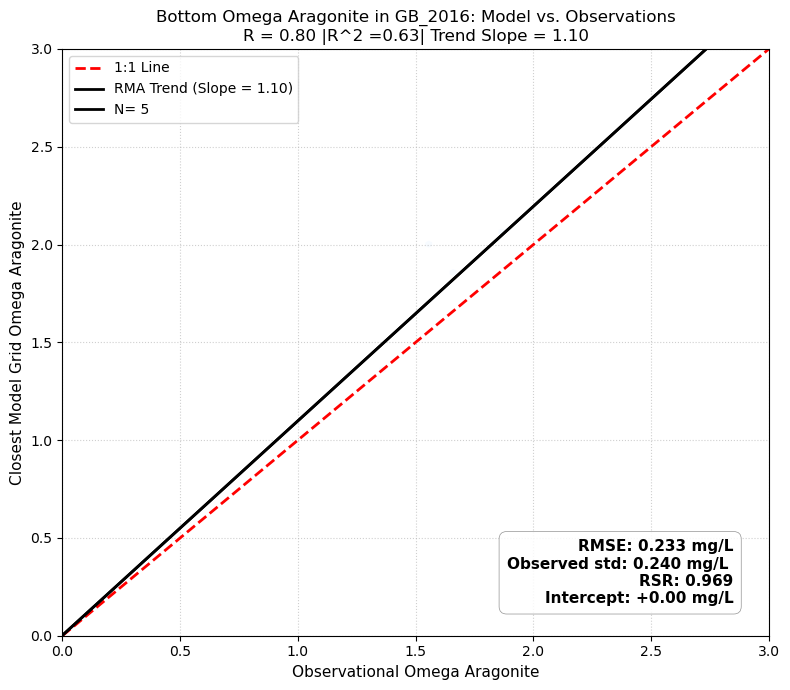

Mean of delta difference between model 3x3x3 grid data and observational data in GB_2017 is: 0.3036
Mean of delta difference between model exact grid data and observational data in GB_2017 is: 0.3916
Global RMSE (3x3x3 grid vs obs) between model and observations in GB_2017 is: 0.3891
Global RMSE (Exact point vs Obs) between model and observations in GB_2017 is: 0.4493
-> Calculated using 7 valid exact points in GB_2017 (out of 7 total pairs).
Calculated Observational Mean: 1.5471
Calculated Model Global Mean: 1.9845
Calculated Global Std Dev: 0.3473
Model grid overestimates the data 85.71 percent of the time
Model grid underestimates the data 14.29 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.3728
When underestimating, the average deficit aragonite (Ω) is: -0.1114
Real-World Observational STD: 0.1440
Model Global STD: 0.3473
Model-to-Observation Variance Ratio: 2.41
Model Grid RSR: 1.2303

ARAGONITE STRESSED STATUS MATCH METRICS (Numeric: Threshold < 

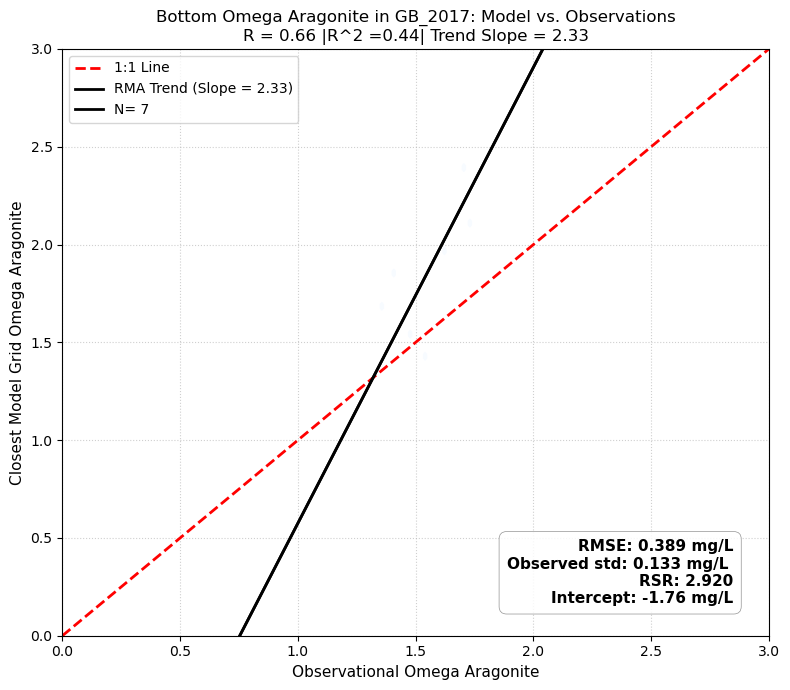

Mean of delta difference between model 3x3x3 grid data and observational data in GB_2018 is: 0.2184
Mean of delta difference between model exact grid data and observational data in GB_2018 is: 0.2097
Global RMSE (3x3x3 grid vs obs) between model and observations in GB_2018 is: 0.2859
Global RMSE (Exact point vs Obs) between model and observations in GB_2018 is: 0.3465
-> Calculated using 13 valid exact points in GB_2018 (out of 13 total pairs).
Calculated Observational Mean: 1.7812
Calculated Model Global Mean: 2.0158
Calculated Global Std Dev: 0.3115
Model grid overestimates the data 100.00 percent of the time
Model grid underestimates the data 0.00 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.2184
When underestimating, the average deficit aragonite (Ω) is: nan
Real-World Observational STD: 0.2262
Model Global STD: 0.3115
Model-to-Observation Variance Ratio: 1.38
Model Grid RSR: 0.9038


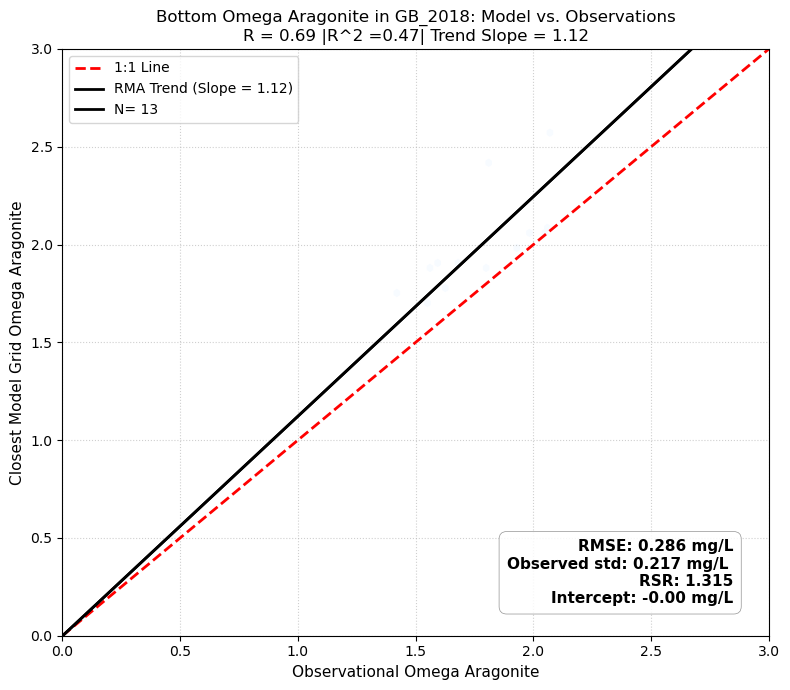

Mean of delta difference between model 3x3x3 grid data and observational data in GB_2019 is: 0.2079
Mean of delta difference between model exact grid data and observational data in GB_2019 is: 0.2382
Global RMSE (3x3x3 grid vs obs) between model and observations in GB_2019 is: 0.2563
Global RMSE (Exact point vs Obs) between model and observations in GB_2019 is: 0.3398
-> Calculated using 7 valid exact points in GB_2019 (out of 7 total pairs).
Calculated Observational Mean: 1.6386
Calculated Model Global Mean: 1.9137
Calculated Global Std Dev: 0.2884
Model grid overestimates the data 100.00 percent of the time
Model grid underestimates the data 0.00 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.2079
When underestimating, the average deficit aragonite (Ω) is: nan
Real-World Observational STD: 0.1632
Model Global STD: 0.2884
Model-to-Observation Variance Ratio: 1.77
Model Grid RSR: 0.8104


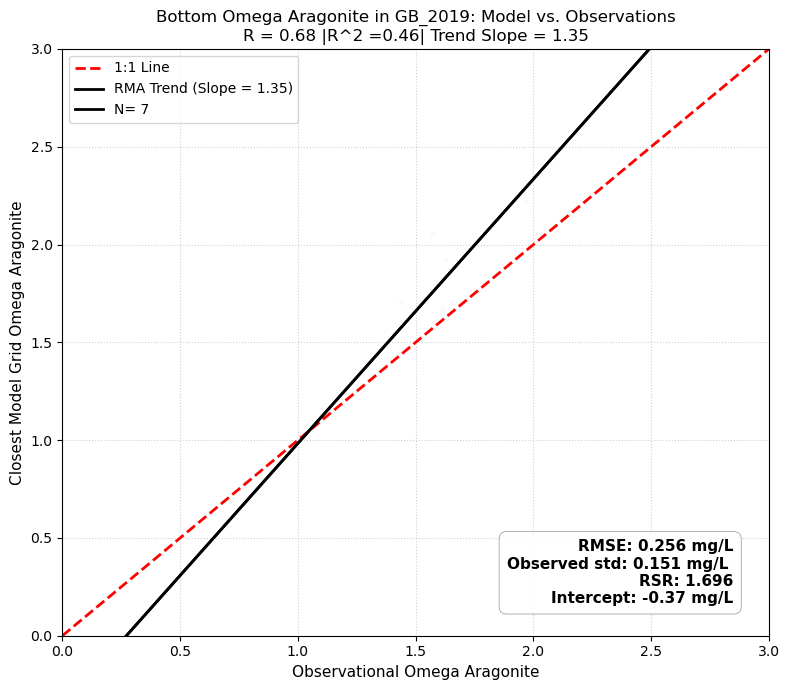

Mean of delta difference between model 3x3x3 grid data and observational data in GB_2021 is: 0.1580
Mean of delta difference between model exact grid data and observational data in GB_2021 is: 0.2150
Global RMSE (3x3x3 grid vs obs) between model and observations in GB_2021 is: 0.2023
Global RMSE (Exact point vs Obs) between model and observations in GB_2021 is: 0.2679
-> Calculated using 7 valid exact points in GB_2021 (out of 7 total pairs).
Calculated Observational Mean: 1.5700
Calculated Model Global Mean: 1.8160
Calculated Global Std Dev: 0.2537
Model grid overestimates the data 100.00 percent of the time
Model grid underestimates the data 0.00 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.1580
When underestimating, the average deficit aragonite (Ω) is: nan
Real-World Observational STD: 0.2276
Model Global STD: 0.2537
Model-to-Observation Variance Ratio: 1.11
Model Grid RSR: 0.6397

ARAGONITE STRESSED STATUS MATCH METRICS (Numeric: Threshold < 1.4)

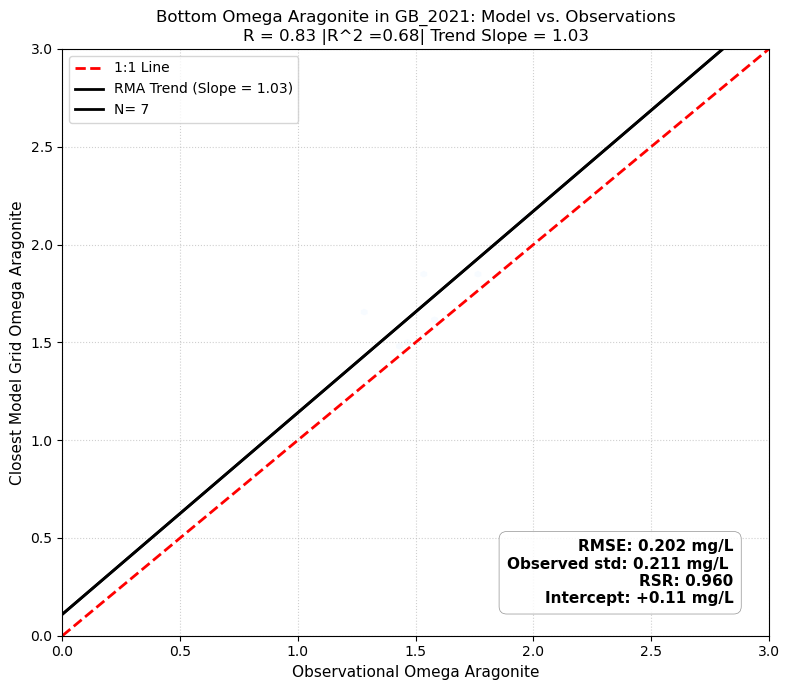

Mean of delta difference between model 3x3x3 grid data and observational data in GB_2022 is: 0.2193
Mean of delta difference between model exact grid data and observational data in GB_2022 is: 0.2697
Global RMSE (3x3x3 grid vs obs) between model and observations in GB_2022 is: 0.2985
Global RMSE (Exact point vs Obs) between model and observations in GB_2022 is: 0.3910
-> Calculated using 12 valid exact points in GB_2022 (out of 12 total pairs).
Calculated Observational Mean: 1.6283
Calculated Model Global Mean: 1.8934
Calculated Global Std Dev: 0.2769
Model grid overestimates the data 91.67 percent of the time
Model grid underestimates the data 8.33 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.2431
When underestimating, the average deficit aragonite (Ω) is: -0.0422
Real-World Observational STD: 0.3156
Model Global STD: 0.2769
Model-to-Observation Variance Ratio: 0.88
Model Grid RSR: 0.9438

ARAGONITE STRESSED STATUS MATCH METRICS (Numeric: Threshold <

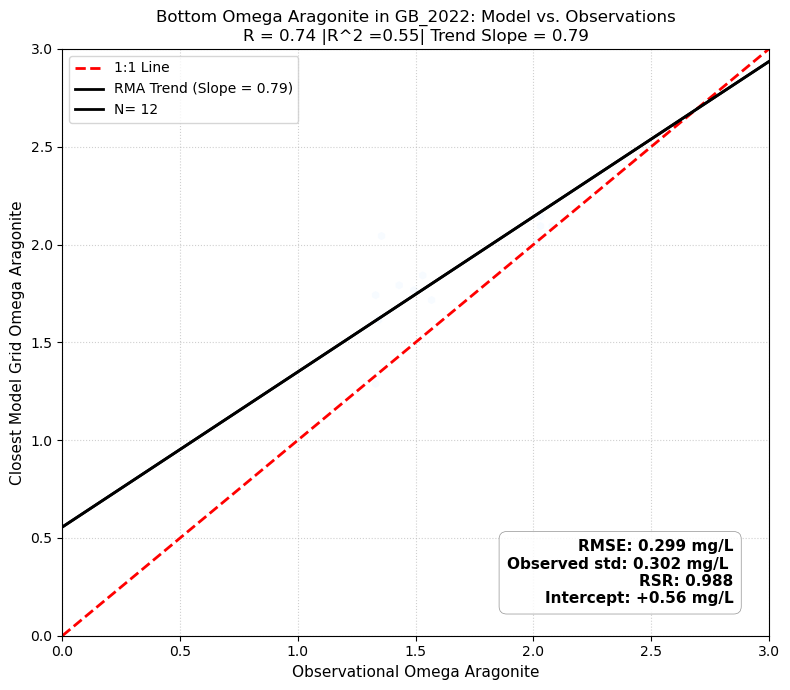

Mean of delta difference between model 3x3x3 grid data and observational data in GB_2023 is: 0.2255
Mean of delta difference between model exact grid data and observational data in GB_2023 is: 0.2534
Global RMSE (3x3x3 grid vs obs) between model and observations in GB_2023 is: 0.3235
Global RMSE (Exact point vs Obs) between model and observations in GB_2023 is: 0.3727
-> Calculated using 12 valid exact points in GB_2023 (out of 12 total pairs).
Calculated Observational Mean: 1.6042
Calculated Model Global Mean: 1.8811
Calculated Global Std Dev: 0.2751
Model grid overestimates the data 75.00 percent of the time
Model grid underestimates the data 25.00 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.3100
When underestimating, the average deficit aragonite (Ω) is: -0.0279
Real-World Observational STD: 0.2877
Model Global STD: 0.2751
Model-to-Observation Variance Ratio: 0.96
Model Grid RSR: 1.0229

ARAGONITE STRESSED STATUS MATCH METRICS (Numeric: Threshold 

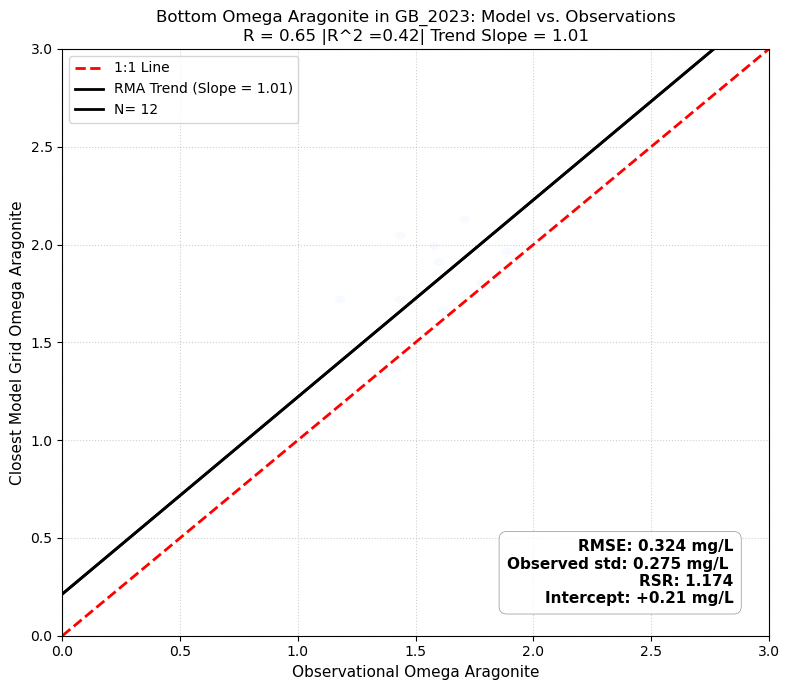

Mean of delta difference between model 3x3x3 grid data and observational data in GB_2024 is: 0.3426
Mean of delta difference between model exact grid data and observational data in GB_2024 is: 0.4045
Global RMSE (3x3x3 grid vs obs) between model and observations in GB_2024 is: 0.4679
Global RMSE (Exact point vs Obs) between model and observations in GB_2024 is: 0.4893
-> Calculated using 5 valid exact points in GB_2024 (out of 5 total pairs).
Calculated Observational Mean: 1.3900
Calculated Model Global Mean: 1.8340
Calculated Global Std Dev: 0.3089
Model grid overestimates the data 60.00 percent of the time
Model grid underestimates the data 40.00 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.5948
When underestimating, the average deficit aragonite (Ω) is: -0.0358
Real-World Observational STD: 0.1735
Model Global STD: 0.3089
Model-to-Observation Variance Ratio: 1.78
Model Grid RSR: 1.4792

ARAGONITE STRESSED STATUS MATCH METRICS (Numeric: Threshold < 

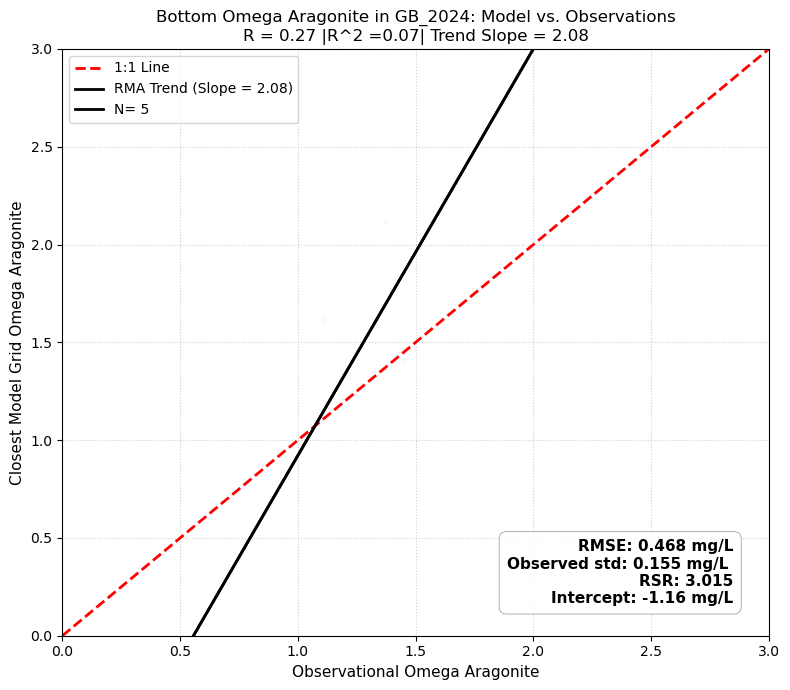

Mean of delta difference between model 3x3x3 grid data and observational data in GOM_west_2012 is: 0.1180
Mean of delta difference between model exact grid data and observational data in GOM_west_2012 is: 0.2143
Global RMSE (3x3x3 grid vs obs) between model and observations in GOM_west_2012 is: 0.1683
Global RMSE (Exact point vs Obs) between model and observations in GOM_west_2012 is: 0.2586
-> Calculated using 7 valid exact points in GOM_west_2012 (out of 7 total pairs).
Calculated Observational Mean: 1.2271
Calculated Model Global Mean: 1.4381
Calculated Global Std Dev: 0.1699
Model grid overestimates the data 85.71 percent of the time
Model grid underestimates the data 14.29 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.1512
When underestimating, the average deficit aragonite (Ω) is: -0.0815
Real-World Observational STD: 0.1301
Model Global STD: 0.1699
Model-to-Observation Variance Ratio: 1.31
Model Grid RSR: 0.5321

ARAGONITE STRESSED STATUS MATCH 

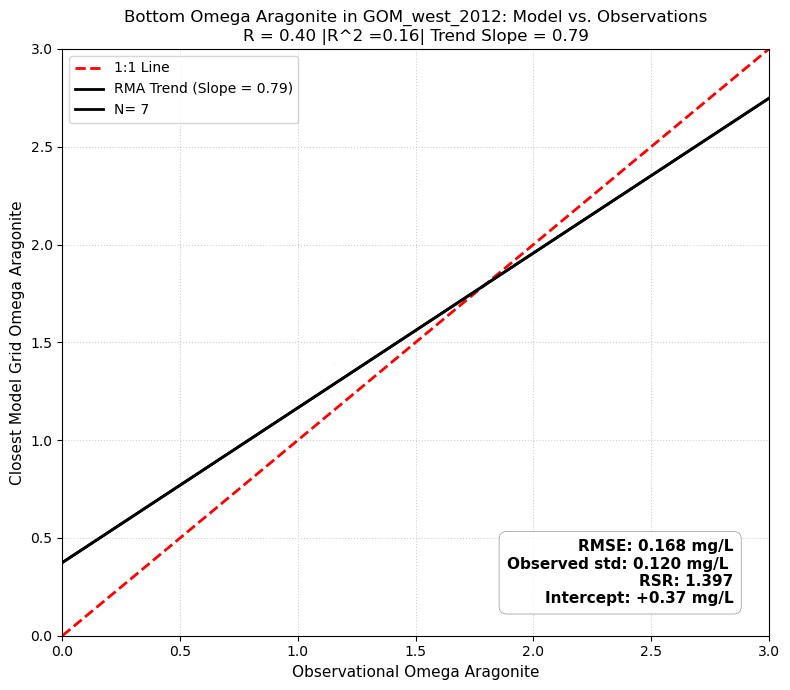

Mean of delta difference between model 3x3x3 grid data and observational data in GOM_west_2013 is: 0.2339
Mean of delta difference between model exact grid data and observational data in GOM_west_2013 is: 0.2972
Global RMSE (3x3x3 grid vs obs) between model and observations in GOM_west_2013 is: 0.2672
Global RMSE (Exact point vs Obs) between model and observations in GOM_west_2013 is: 0.3123
-> Calculated using 7 valid exact points in GOM_west_2013 (out of 7 total pairs).
Calculated Observational Mean: 1.2486
Calculated Model Global Mean: 1.5505
Calculated Global Std Dev: 0.1392
Model grid overestimates the data 100.00 percent of the time
Model grid underestimates the data 0.00 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.2339
When underestimating, the average deficit aragonite (Ω) is: nan
Real-World Observational STD: 0.2029
Model Global STD: 0.1392
Model-to-Observation Variance Ratio: 0.69
Model Grid RSR: 0.8447

ARAGONITE STRESSED STATUS MATCH METR

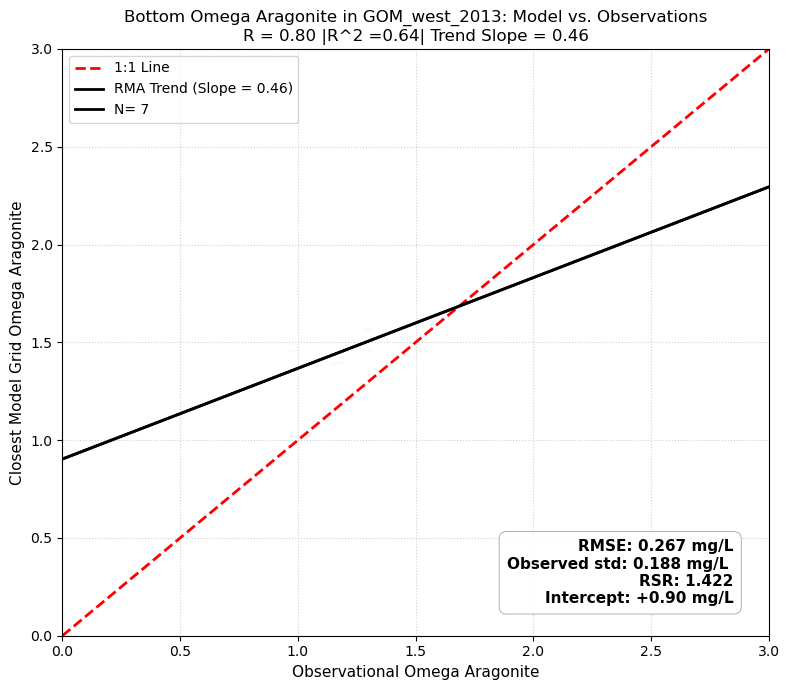

Mean of delta difference between model 3x3x3 grid data and observational data in GOM_west_2014 is: 0.3564
Mean of delta difference between model exact grid data and observational data in GOM_west_2014 is: 0.4487
Global RMSE (3x3x3 grid vs obs) between model and observations in GOM_west_2014 is: 0.3635
Global RMSE (Exact point vs Obs) between model and observations in GOM_west_2014 is: 0.4583
-> Calculated using 4 valid exact points in GOM_west_2014 (out of 4 total pairs).
Calculated Observational Mean: 1.2200
Calculated Model Global Mean: 1.6561
Calculated Global Std Dev: 0.1899
Model grid overestimates the data 100.00 percent of the time
Model grid underestimates the data 0.00 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.3564
When underestimating, the average deficit aragonite (Ω) is: nan
Real-World Observational STD: 0.1334
Model Global STD: 0.1899
Model-to-Observation Variance Ratio: 1.42
Model Grid RSR: 1.1493

ARAGONITE STRESSED STATUS MATCH METR

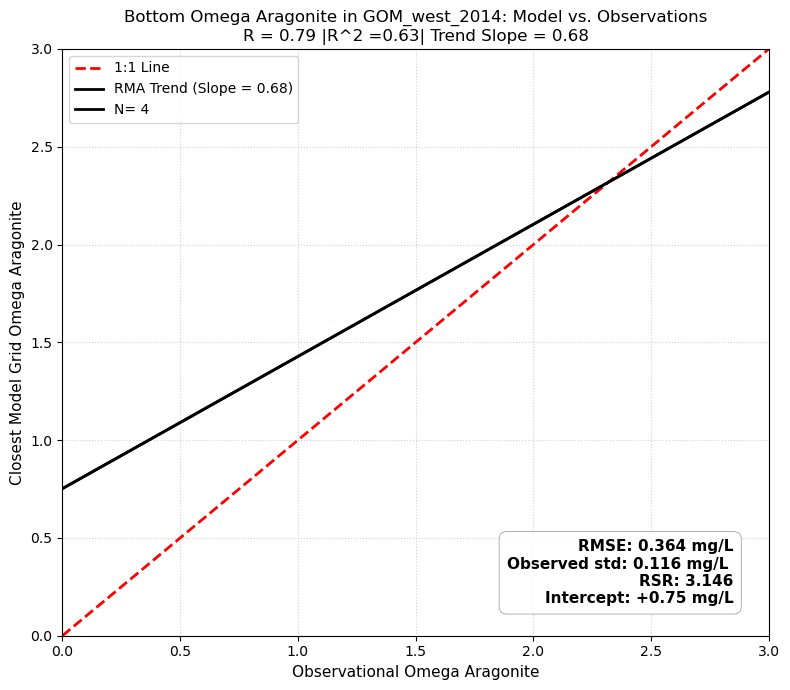

Mean of delta difference between model 3x3x3 grid data and observational data in GOM_west_2015 is: 0.1297
Mean of delta difference between model exact grid data and observational data in GOM_west_2015 is: 0.1881
Global RMSE (3x3x3 grid vs obs) between model and observations in GOM_west_2015 is: 0.1882
Global RMSE (Exact point vs Obs) between model and observations in GOM_west_2015 is: 0.2346
-> Calculated using 14 valid exact points in GOM_west_2015 (out of 14 total pairs).
Calculated Observational Mean: 1.3571
Calculated Model Global Mean: 1.5685
Calculated Global Std Dev: 0.1432
Model grid overestimates the data 85.71 percent of the time
Model grid underestimates the data 14.29 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.1517
When underestimating, the average deficit aragonite (Ω) is: -0.0022
Real-World Observational STD: 0.1186
Model Global STD: 0.1432
Model-to-Observation Variance Ratio: 1.21
Model Grid RSR: 0.5949

ARAGONITE STRESSED STATUS MATC

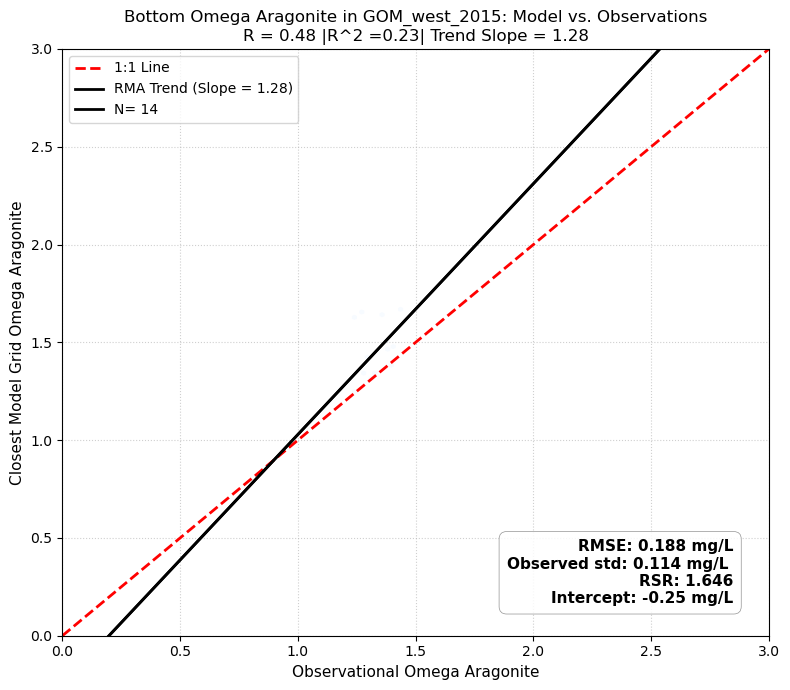

Mean of delta difference between model 3x3x3 grid data and observational data in GOM_west_2016 is: 0.4419
Mean of delta difference between model exact grid data and observational data in GOM_west_2016 is: 0.4822
Global RMSE (3x3x3 grid vs obs) between model and observations in GOM_west_2016 is: 0.4531
Global RMSE (Exact point vs Obs) between model and observations in GOM_west_2016 is: 0.4910
-> Calculated using 5 valid exact points in GOM_west_2016 (out of 5 total pairs).
Calculated Observational Mean: 1.1680
Calculated Model Global Mean: 1.6637
Calculated Global Std Dev: 0.1235
Model grid overestimates the data 100.00 percent of the time
Model grid underestimates the data 0.00 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.4419
When underestimating, the average deficit aragonite (Ω) is: nan
Real-World Observational STD: 0.1276
Model Global STD: 0.1235
Model-to-Observation Variance Ratio: 0.97
Model Grid RSR: 1.4325

ARAGONITE STRESSED STATUS MATCH METR

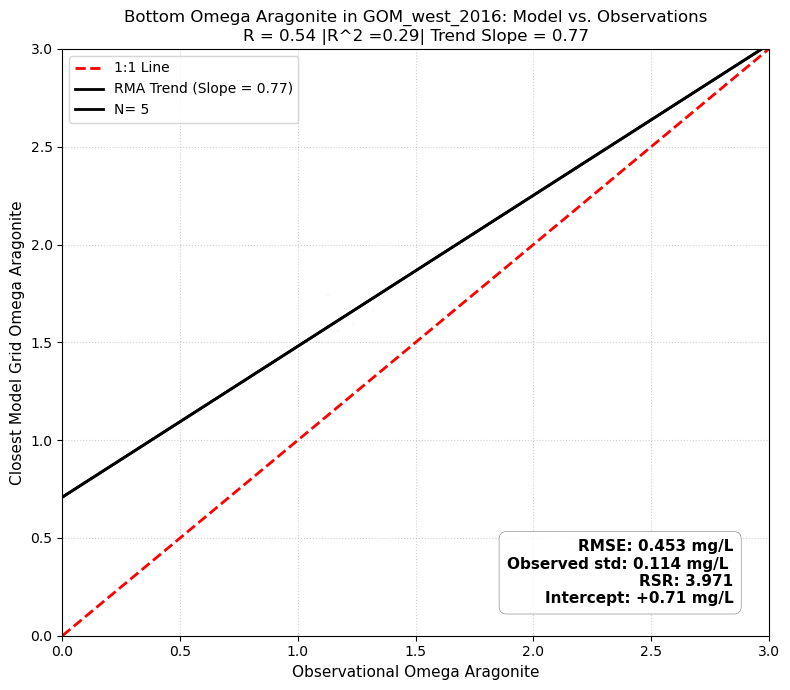

Mean of delta difference between model 3x3x3 grid data and observational data in GOM_west_2017 is: 0.2673
Mean of delta difference between model exact grid data and observational data in GOM_west_2017 is: 0.2940
Global RMSE (3x3x3 grid vs obs) between model and observations in GOM_west_2017 is: 0.3966
Global RMSE (Exact point vs Obs) between model and observations in GOM_west_2017 is: 0.4202
-> Calculated using 9 valid exact points in GOM_west_2017 (out of 9 total pairs).
Calculated Observational Mean: 1.3800
Calculated Model Global Mean: 1.6869
Calculated Global Std Dev: 0.0826
Model grid overestimates the data 88.89 percent of the time
Model grid underestimates the data 11.11 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.3621
When underestimating, the average deficit aragonite (Ω) is: -0.4908
Real-World Observational STD: 0.3075
Model Global STD: 0.0826
Model-to-Observation Variance Ratio: 0.27
Model Grid RSR: 1.2538

ARAGONITE STRESSED STATUS MATCH 

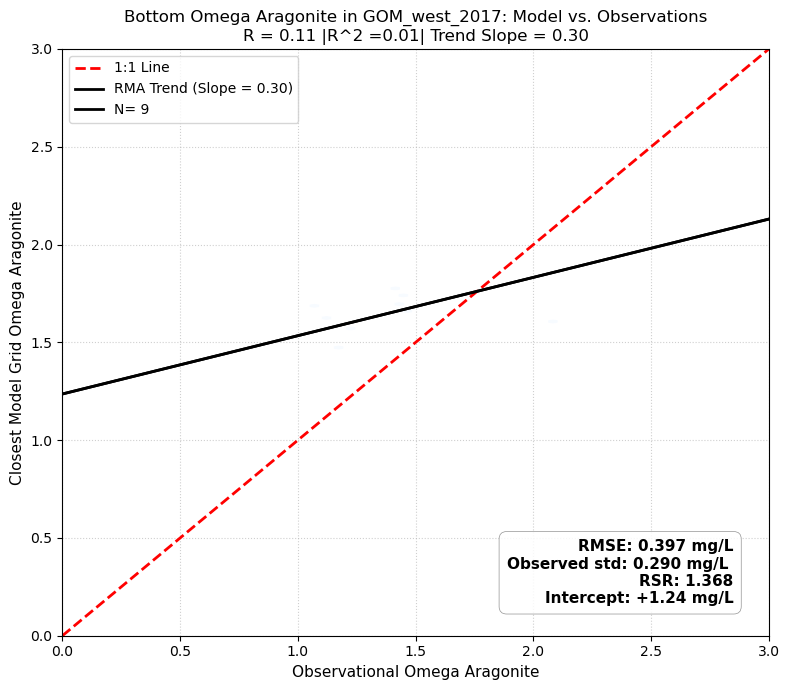

Mean of delta difference between model 3x3x3 grid data and observational data in GOM_west_2018 is: 0.2881
Mean of delta difference between model exact grid data and observational data in GOM_west_2018 is: 0.3746
Global RMSE (3x3x3 grid vs obs) between model and observations in GOM_west_2018 is: 0.3110
Global RMSE (Exact point vs Obs) between model and observations in GOM_west_2018 is: 0.3888
-> Calculated using 15 valid exact points in GOM_west_2018 (out of 15 total pairs).
Calculated Observational Mean: 1.3067
Calculated Model Global Mean: 1.6955
Calculated Global Std Dev: 0.1269
Model grid overestimates the data 93.33 percent of the time
Model grid underestimates the data 6.67 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.3103
When underestimating, the average deficit aragonite (Ω) is: -0.0221
Real-World Observational STD: 0.0511
Model Global STD: 0.1269
Model-to-Observation Variance Ratio: 2.48
Model Grid RSR: 0.9832

ARAGONITE STRESSED STATUS MATCH

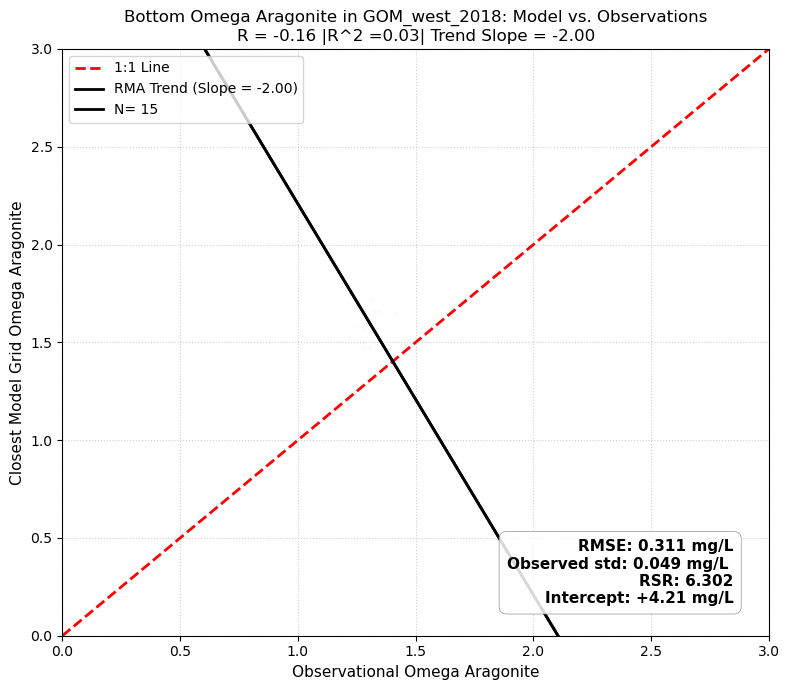

Mean of delta difference between model 3x3x3 grid data and observational data in GOM_west_2019 is: 0.3798
Mean of delta difference between model exact grid data and observational data in GOM_west_2019 is: 0.4240
Global RMSE (3x3x3 grid vs obs) between model and observations in GOM_west_2019 is: 0.3920
Global RMSE (Exact point vs Obs) between model and observations in GOM_west_2019 is: 0.4331
-> Calculated using 10 valid exact points in GOM_west_2019 (out of 10 total pairs).
Calculated Observational Mean: 1.1500
Calculated Model Global Mean: 1.5927
Calculated Global Std Dev: 0.0807
Model grid overestimates the data 100.00 percent of the time
Model grid underestimates the data 0.00 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.3798
When underestimating, the average deficit aragonite (Ω) is: nan
Real-World Observational STD: 0.1084
Model Global STD: 0.0807
Model-to-Observation Variance Ratio: 0.74
Model Grid RSR: 1.2392

ARAGONITE STRESSED STATUS MATCH ME

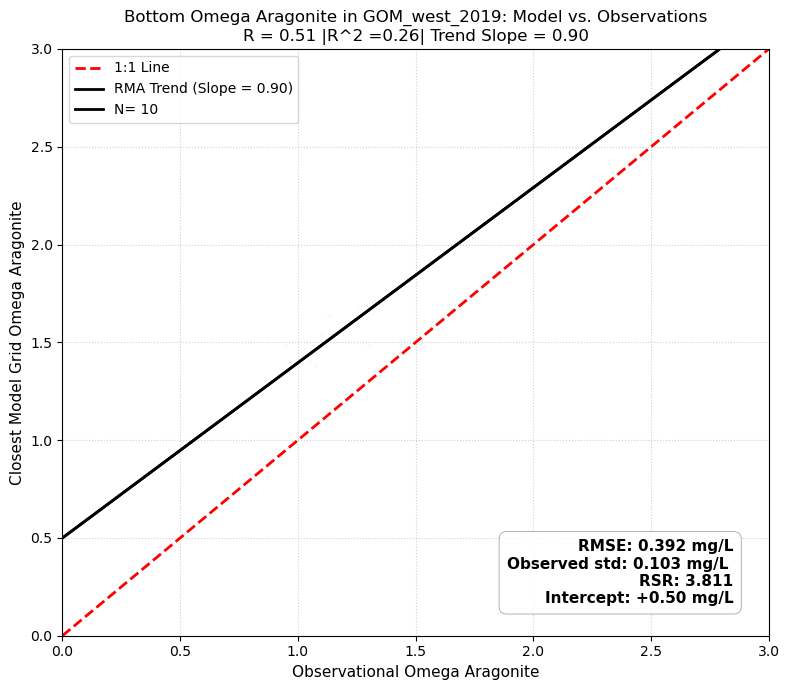

Mean of delta difference between model 3x3x3 grid data and observational data in GOM_west_2021 is: 0.0454
Mean of delta difference between model exact grid data and observational data in GOM_west_2021 is: 0.0319
Global RMSE (3x3x3 grid vs obs) between model and observations in GOM_west_2021 is: 0.1444
Global RMSE (Exact point vs Obs) between model and observations in GOM_west_2021 is: 0.1823
-> Calculated using 152 valid exact points in GOM_west_2021 (out of 152 total pairs).
Calculated Observational Mean: 1.4063
Calculated Model Global Mean: 1.4501
Calculated Global Std Dev: 0.0768
Model grid overestimates the data 60.53 percent of the time
Model grid underestimates the data 39.47 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.1184
When underestimating, the average deficit aragonite (Ω) is: -0.0665
Real-World Observational STD: 0.1352
Model Global STD: 0.0768
Model-to-Observation Variance Ratio: 0.57
Model Grid RSR: 0.4566

ARAGONITE STRESSED STATUS MA

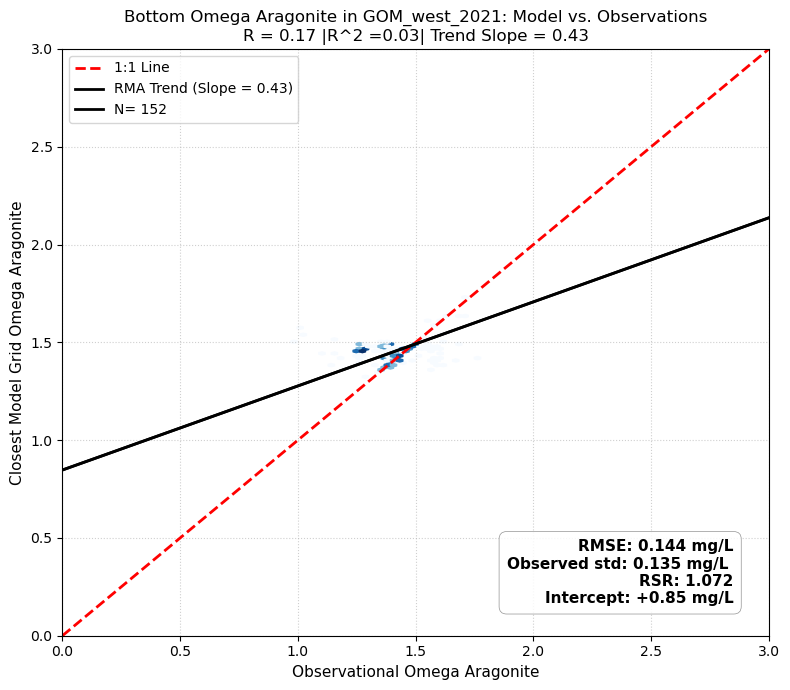

Mean of delta difference between model 3x3x3 grid data and observational data in GOM_west_2022 is: 0.1042
Mean of delta difference between model exact grid data and observational data in GOM_west_2022 is: 0.1270
Global RMSE (3x3x3 grid vs obs) between model and observations in GOM_west_2022 is: 0.1629
Global RMSE (Exact point vs Obs) between model and observations in GOM_west_2022 is: 0.1997
-> Calculated using 284 valid exact points in GOM_west_2022 (out of 284 total pairs).
Calculated Observational Mean: 1.3679
Calculated Model Global Mean: 1.5039
Calculated Global Std Dev: 0.1394
Model grid overestimates the data 79.23 percent of the time
Model grid underestimates the data 20.77 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.1363
When underestimating, the average deficit aragonite (Ω) is: -0.0181
Real-World Observational STD: 0.1407
Model Global STD: 0.1394
Model-to-Observation Variance Ratio: 0.99
Model Grid RSR: 0.5150

ARAGONITE STRESSED STATUS MA

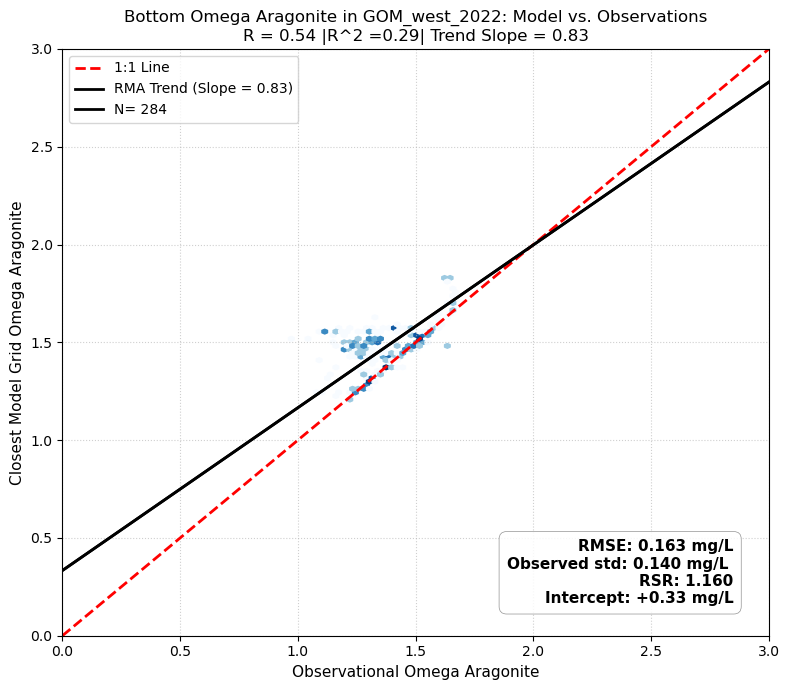

Mean of delta difference between model 3x3x3 grid data and observational data in GOM_west_2023 is: 0.1472
Mean of delta difference between model exact grid data and observational data in GOM_west_2023 is: 0.1956
Global RMSE (3x3x3 grid vs obs) between model and observations in GOM_west_2023 is: 0.2146
Global RMSE (Exact point vs Obs) between model and observations in GOM_west_2023 is: 0.2533
-> Calculated using 101 valid exact points in GOM_west_2023 (out of 101 total pairs).
Calculated Observational Mean: 1.3514
Calculated Model Global Mean: 1.5530
Calculated Global Std Dev: 0.1204
Model grid overestimates the data 92.08 percent of the time
Model grid underestimates the data 7.92 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.1602
When underestimating, the average deficit aragonite (Ω) is: -0.0042
Real-World Observational STD: 0.1575
Model Global STD: 0.1204
Model-to-Observation Variance Ratio: 0.76
Model Grid RSR: 0.6786

ARAGONITE STRESSED STATUS MAT

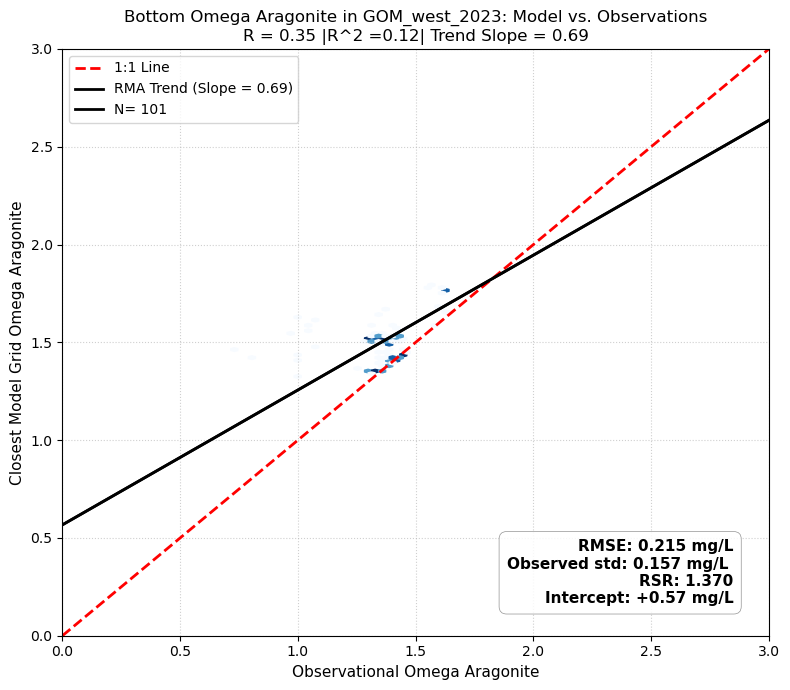

Mean of delta difference between model 3x3x3 grid data and observational data in GOM_west_2024 is: 0.5902
Mean of delta difference between model exact grid data and observational data in GOM_west_2024 is: 0.6289
Global RMSE (3x3x3 grid vs obs) between model and observations in GOM_west_2024 is: 0.6210
Global RMSE (Exact point vs Obs) between model and observations in GOM_west_2024 is: 0.6576
-> Calculated using 8 valid exact points in GOM_west_2024 (out of 8 total pairs).
Calculated Observational Mean: 1.0413
Calculated Model Global Mean: 1.6686
Calculated Global Std Dev: 0.1043
Model grid overestimates the data 100.00 percent of the time
Model grid underestimates the data 0.00 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.5902
When underestimating, the average deficit aragonite (Ω) is: nan
Real-World Observational STD: 0.1058
Model Global STD: 0.1043
Model-to-Observation Variance Ratio: 0.99
Model Grid RSR: 1.9635

ARAGONITE STRESSED STATUS MATCH METR

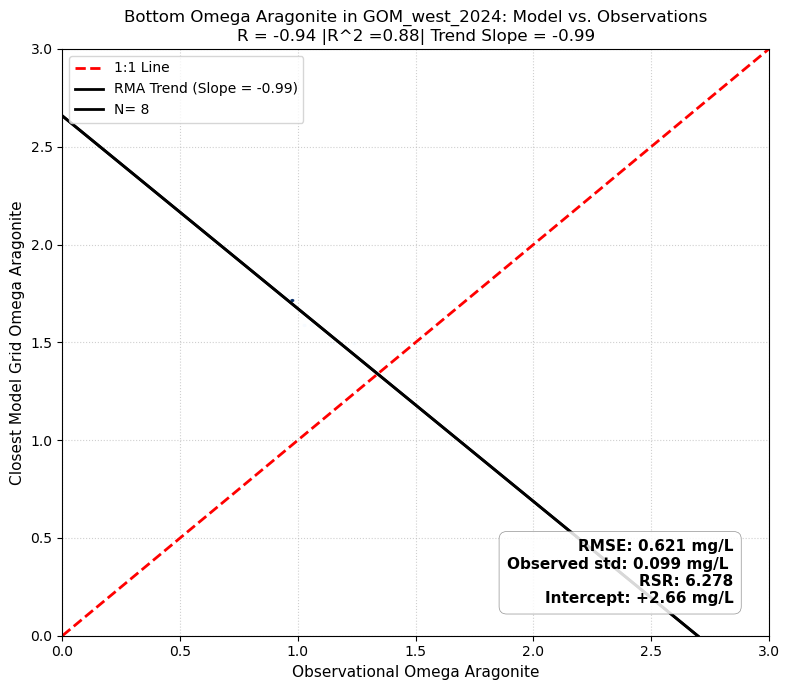

Mean of delta difference between model 3x3x3 grid data and observational data in GOM_east_2012 is: 0.2453
Mean of delta difference between model exact grid data and observational data in GOM_east_2012 is: 0.2808
Global RMSE (3x3x3 grid vs obs) between model and observations in GOM_east_2012 is: 0.2554
Global RMSE (Exact point vs Obs) between model and observations in GOM_east_2012 is: 0.2875
-> Calculated using 4 valid exact points in GOM_east_2012 (out of 4 total pairs).
Calculated Observational Mean: 1.3387
Calculated Model Global Mean: 1.6277
Calculated Global Std Dev: 0.1064
Model grid overestimates the data 100.00 percent of the time
Model grid underestimates the data 0.00 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.2453
When underestimating, the average deficit aragonite (Ω) is: nan
Real-World Observational STD: 0.0766
Model Global STD: 0.1064
Model-to-Observation Variance Ratio: 1.39
Model Grid RSR: 0.8074

ARAGONITE STRESSED STATUS MATCH METR

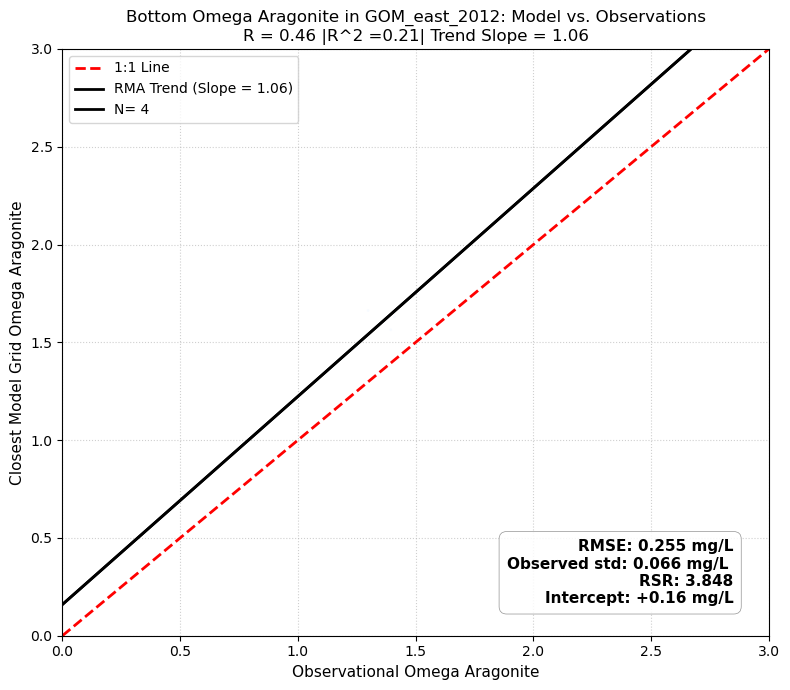

Mean of delta difference between model 3x3x3 grid data and observational data in GOM_east_2013 is: 0.2295
Mean of delta difference between model exact grid data and observational data in GOM_east_2013 is: 0.2699
Global RMSE (3x3x3 grid vs obs) between model and observations in GOM_east_2013 is: 0.2625
Global RMSE (Exact point vs Obs) between model and observations in GOM_east_2013 is: 0.2969
-> Calculated using 6 valid exact points in GOM_east_2013 (out of 6 total pairs).
Calculated Observational Mean: 1.3467
Calculated Model Global Mean: 1.6256
Calculated Global Std Dev: 0.1154
Model grid overestimates the data 100.00 percent of the time
Model grid underestimates the data 0.00 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.2295
When underestimating, the average deficit aragonite (Ω) is: nan
Real-World Observational STD: 0.1475
Model Global STD: 0.1154
Model-to-Observation Variance Ratio: 0.78
Model Grid RSR: 0.8300

ARAGONITE STRESSED STATUS MATCH METR

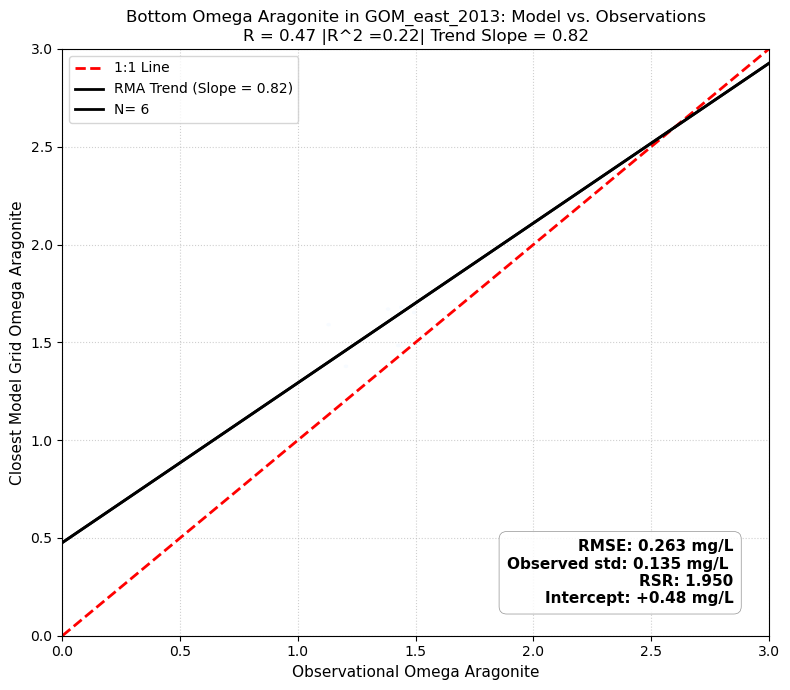

Mean of delta difference between model 3x3x3 grid data and observational data in GOM_east_2014 is: 0.2744
Mean of delta difference between model exact grid data and observational data in GOM_east_2014 is: 0.3305
Global RMSE (3x3x3 grid vs obs) between model and observations in GOM_east_2014 is: 0.3055
Global RMSE (Exact point vs Obs) between model and observations in GOM_east_2014 is: 0.3577
-> Calculated using 9 valid exact points in GOM_east_2014 (out of 9 total pairs).
Calculated Observational Mean: 1.3933
Calculated Model Global Mean: 1.7291
Calculated Global Std Dev: 0.0624
Model grid overestimates the data 100.00 percent of the time
Model grid underestimates the data 0.00 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.2744
When underestimating, the average deficit aragonite (Ω) is: nan
Real-World Observational STD: 0.1193
Model Global STD: 0.0624
Model-to-Observation Variance Ratio: 0.52
Model Grid RSR: 0.9659

ARAGONITE STRESSED STATUS MATCH METR

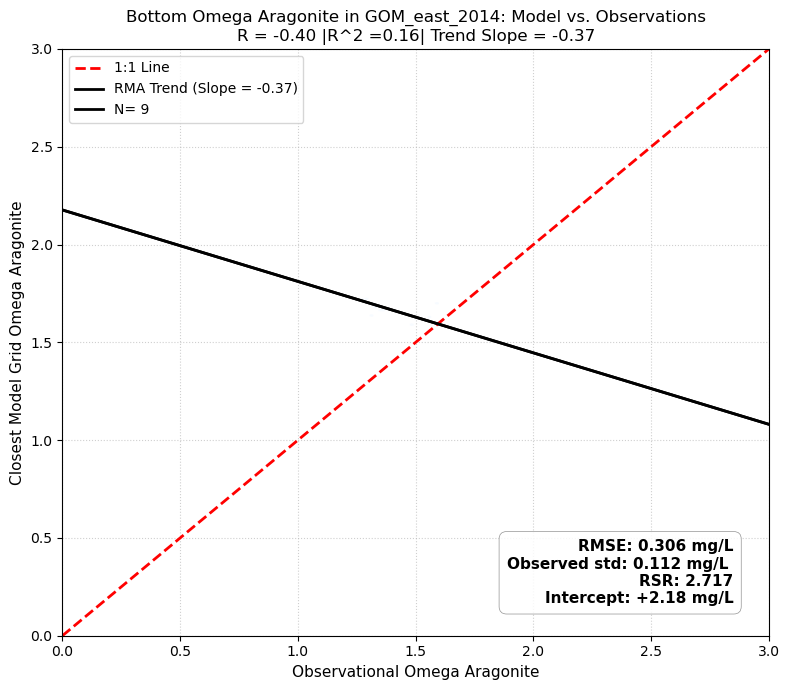

Mean of delta difference between model 3x3x3 grid data and observational data in GOM_east_2015 is: 0.1685
Mean of delta difference between model exact grid data and observational data in GOM_east_2015 is: 0.2356
Global RMSE (3x3x3 grid vs obs) between model and observations in GOM_east_2015 is: 0.2029
Global RMSE (Exact point vs Obs) between model and observations in GOM_east_2015 is: 0.2665
-> Calculated using 13 valid exact points in GOM_east_2015 (out of 13 total pairs).
Calculated Observational Mean: 1.4454
Calculated Model Global Mean: 1.6800
Calculated Global Std Dev: 0.1137
Model grid overestimates the data 92.31 percent of the time
Model grid underestimates the data 7.69 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.1826
When underestimating, the average deficit aragonite (Ω) is: -0.0006
Real-World Observational STD: 0.0889
Model Global STD: 0.1137
Model-to-Observation Variance Ratio: 1.28
Model Grid RSR: 0.6415

ARAGONITE STRESSED STATUS MATCH

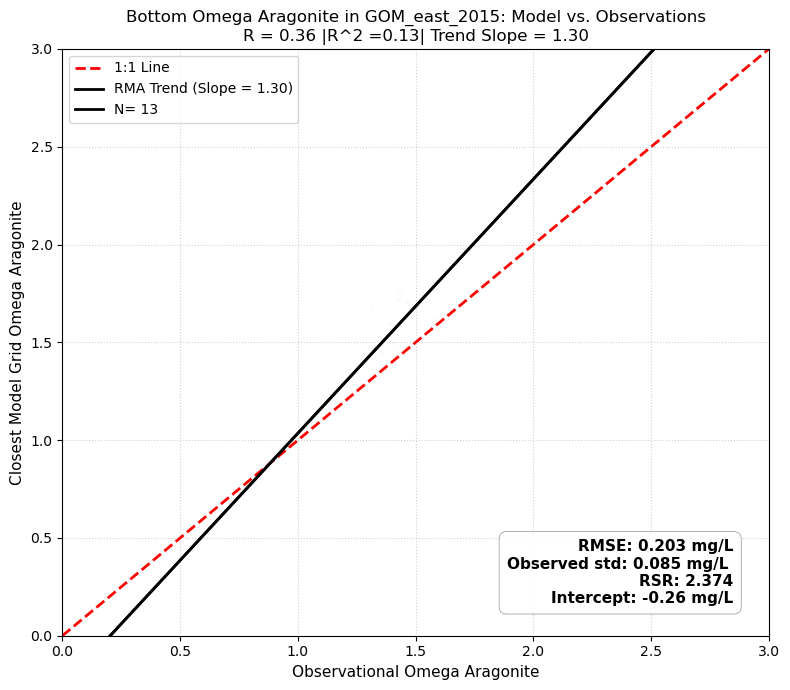

Mean of delta difference between model 3x3x3 grid data and observational data in GOM_east_2016 is: 0.3896
Mean of delta difference between model exact grid data and observational data in GOM_east_2016 is: 0.4516
Global RMSE (3x3x3 grid vs obs) between model and observations in GOM_east_2016 is: 0.4192
Global RMSE (Exact point vs Obs) between model and observations in GOM_east_2016 is: 0.4769
-> Calculated using 9 valid exact points in GOM_east_2016 (out of 9 total pairs).
Calculated Observational Mean: 1.3211
Calculated Model Global Mean: 1.7726
Calculated Global Std Dev: 0.1723
Model grid overestimates the data 100.00 percent of the time
Model grid underestimates the data 0.00 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.3896
When underestimating, the average deficit aragonite (Ω) is: nan
Real-World Observational STD: 0.1042
Model Global STD: 0.1723
Model-to-Observation Variance Ratio: 1.65
Model Grid RSR: 1.3253

ARAGONITE STRESSED STATUS MATCH METR

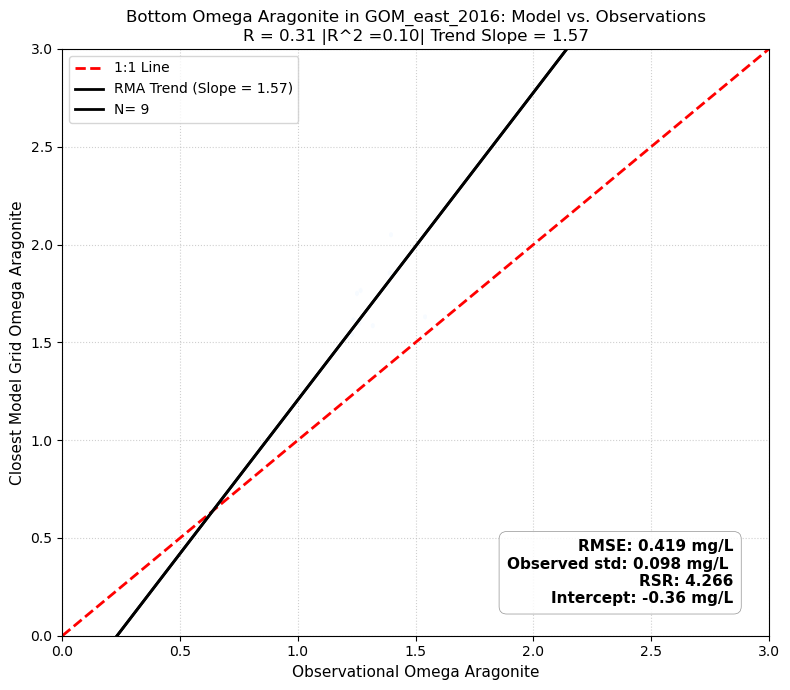

Mean of delta difference between model 3x3x3 grid data and observational data in GOM_east_2017 is: 0.3624
Mean of delta difference between model exact grid data and observational data in GOM_east_2017 is: 0.4204
Global RMSE (3x3x3 grid vs obs) between model and observations in GOM_east_2017 is: 0.3836
Global RMSE (Exact point vs Obs) between model and observations in GOM_east_2017 is: 0.4393
-> Calculated using 6 valid exact points in GOM_east_2017 (out of 6 total pairs).
Calculated Observational Mean: 1.4100
Calculated Model Global Mean: 1.8442
Calculated Global Std Dev: 0.1526
Model grid overestimates the data 100.00 percent of the time
Model grid underestimates the data 0.00 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.3624
When underestimating, the average deficit aragonite (Ω) is: nan
Real-World Observational STD: 0.0988
Model Global STD: 0.1526
Model-to-Observation Variance Ratio: 1.55
Model Grid RSR: 1.2128

ARAGONITE STRESSED STATUS MATCH METR

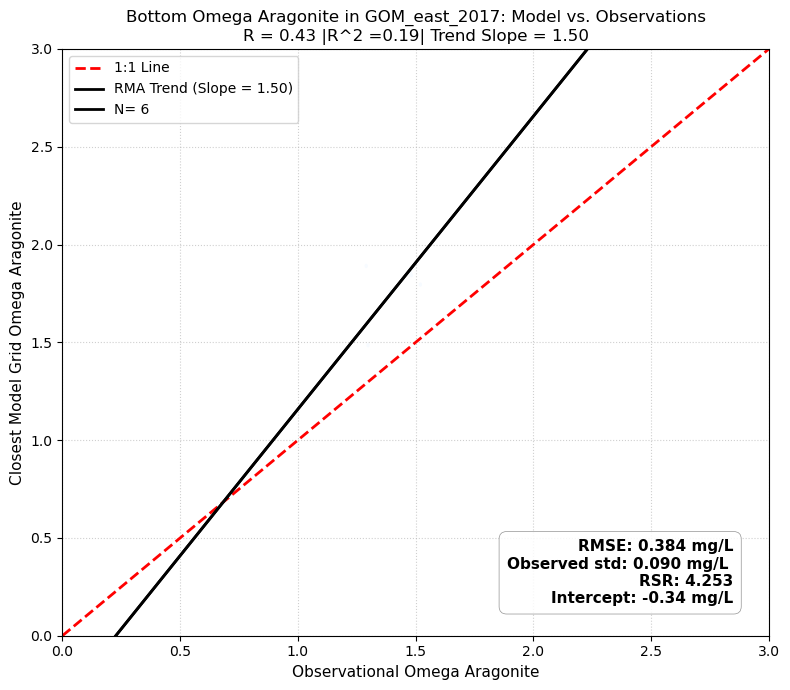

Mean of delta difference between model 3x3x3 grid data and observational data in GOM_east_2018 is: 0.3398
Mean of delta difference between model exact grid data and observational data in GOM_east_2018 is: 0.3889
Global RMSE (3x3x3 grid vs obs) between model and observations in GOM_east_2018 is: 0.3744
Global RMSE (Exact point vs Obs) between model and observations in GOM_east_2018 is: 0.4160
-> Calculated using 28 valid exact points in GOM_east_2018 (out of 28 total pairs).
Calculated Observational Mean: 1.5300
Calculated Model Global Mean: 1.9187
Calculated Global Std Dev: 0.1309
Model grid overestimates the data 100.00 percent of the time
Model grid underestimates the data 0.00 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.3398
When underestimating, the average deficit aragonite (Ω) is: nan
Real-World Observational STD: 0.0974
Model Global STD: 0.1309
Model-to-Observation Variance Ratio: 1.34
Model Grid RSR: 1.1837

ARAGONITE STRESSED STATUS MATCH ME

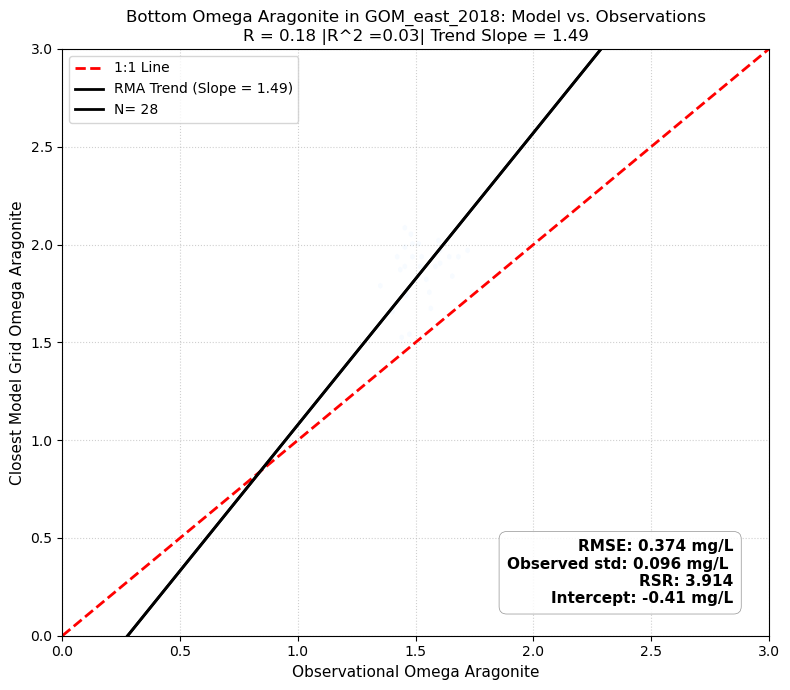

Mean of delta difference between model 3x3x3 grid data and observational data in GOM_east_2019 is: 0.2391
Mean of delta difference between model exact grid data and observational data in GOM_east_2019 is: 0.2958
Global RMSE (3x3x3 grid vs obs) between model and observations in GOM_east_2019 is: 0.2664
Global RMSE (Exact point vs Obs) between model and observations in GOM_east_2019 is: 0.3217
-> Calculated using 11 valid exact points in GOM_east_2019 (out of 11 total pairs).
Calculated Observational Mean: 1.4682
Calculated Model Global Mean: 1.7597
Calculated Global Std Dev: 0.1085
Model grid overestimates the data 100.00 percent of the time
Model grid underestimates the data 0.00 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.2391
When underestimating, the average deficit aragonite (Ω) is: nan
Real-World Observational STD: 0.0985
Model Global STD: 0.1085
Model-to-Observation Variance Ratio: 1.10
Model Grid RSR: 0.8422

ARAGONITE STRESSED STATUS MATCH ME

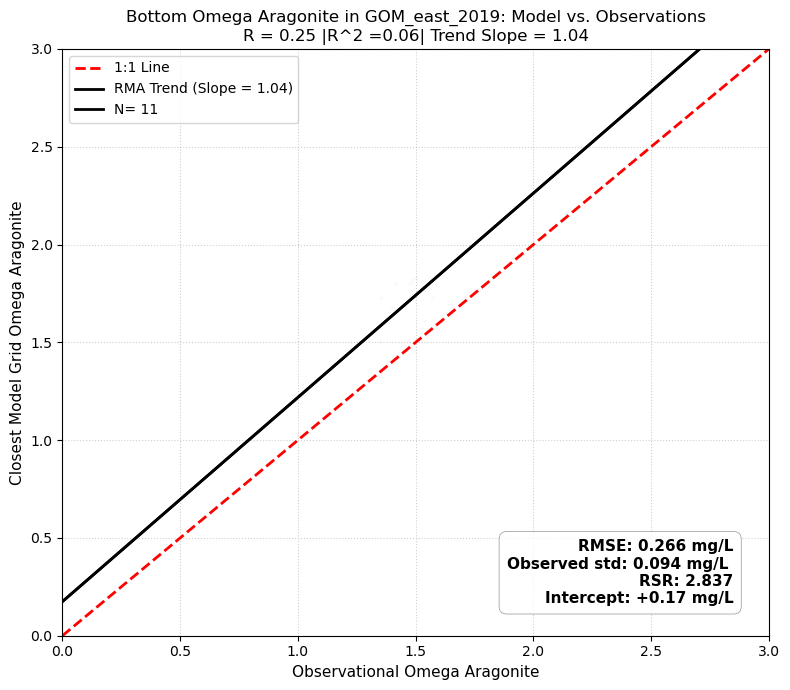

Mean of delta difference between model 3x3x3 grid data and observational data in GOM_east_2021 is: 0.0189
Mean of delta difference between model exact grid data and observational data in GOM_east_2021 is: 0.0063
Global RMSE (3x3x3 grid vs obs) between model and observations in GOM_east_2021 is: 0.1156
Global RMSE (Exact point vs Obs) between model and observations in GOM_east_2021 is: 0.1622
-> Calculated using 139 valid exact points in GOM_east_2021 (out of 139 total pairs).
Calculated Observational Mean: 1.5427
Calculated Model Global Mean: 1.5548
Calculated Global Std Dev: 0.1013
Model grid overestimates the data 61.15 percent of the time
Model grid underestimates the data 38.85 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.0887
When underestimating, the average deficit aragonite (Ω) is: -0.0909
Real-World Observational STD: 0.1664
Model Global STD: 0.1013
Model-to-Observation Variance Ratio: 0.61
Model Grid RSR: 0.3654

ARAGONITE STRESSED STATUS MA

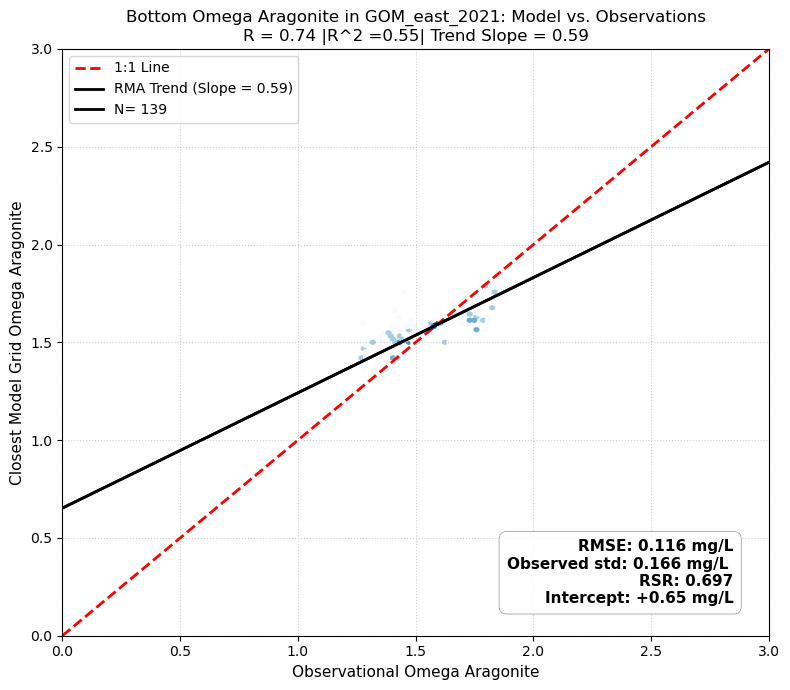

Mean of delta difference between model 3x3x3 grid data and observational data in GOM_east_2022 is: 0.1463
Mean of delta difference between model exact grid data and observational data in GOM_east_2022 is: 0.1762
Global RMSE (3x3x3 grid vs obs) between model and observations in GOM_east_2022 is: 0.1844
Global RMSE (Exact point vs Obs) between model and observations in GOM_east_2022 is: 0.2116
-> Calculated using 242 valid exact points in GOM_east_2022 (out of 242 total pairs).
Calculated Observational Mean: 1.4930
Calculated Model Global Mean: 1.6706
Calculated Global Std Dev: 0.0888
Model grid overestimates the data 92.56 percent of the time
Model grid underestimates the data 7.44 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.1625
When underestimating, the average deficit aragonite (Ω) is: -0.0548
Real-World Observational STD: 0.1290
Model Global STD: 0.0888
Model-to-Observation Variance Ratio: 0.69
Model Grid RSR: 0.5829

ARAGONITE STRESSED STATUS MAT

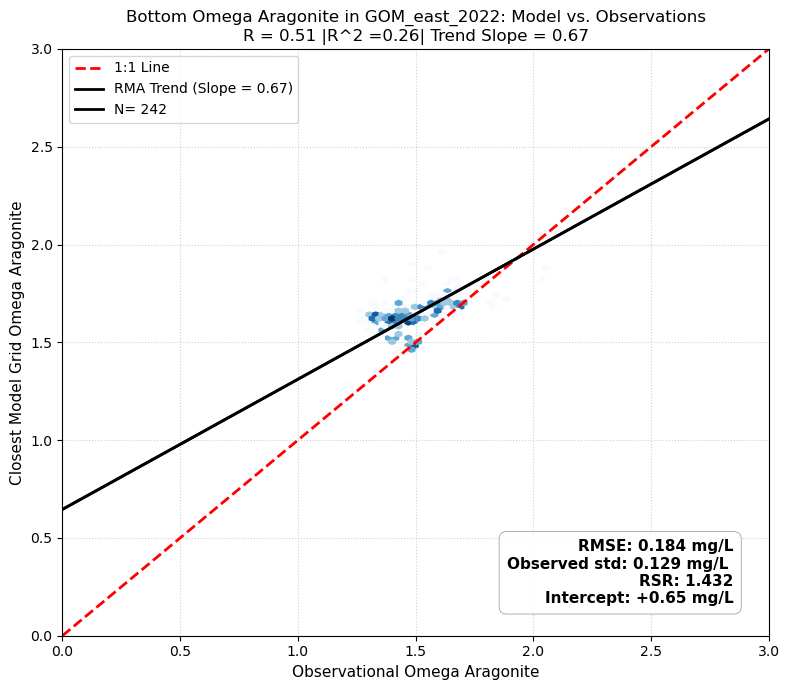

Mean of delta difference between model 3x3x3 grid data and observational data in GOM_east_2023 is: 0.2245
Mean of delta difference between model exact grid data and observational data in GOM_east_2023 is: 0.2457
Global RMSE (3x3x3 grid vs obs) between model and observations in GOM_east_2023 is: 0.2697
Global RMSE (Exact point vs Obs) between model and observations in GOM_east_2023 is: 0.2885
-> Calculated using 174 valid exact points in GOM_east_2023 (out of 174 total pairs).
Calculated Observational Mean: 1.4057
Calculated Model Global Mean: 1.6534
Calculated Global Std Dev: 0.0580
Model grid overestimates the data 98.85 percent of the time
Model grid underestimates the data 1.15 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.2328
When underestimating, the average deficit aragonite (Ω) is: -0.4871
Real-World Observational STD: 0.1547
Model Global STD: 0.0580
Model-to-Observation Variance Ratio: 0.37
Model Grid RSR: 0.8525

ARAGONITE STRESSED STATUS MAT

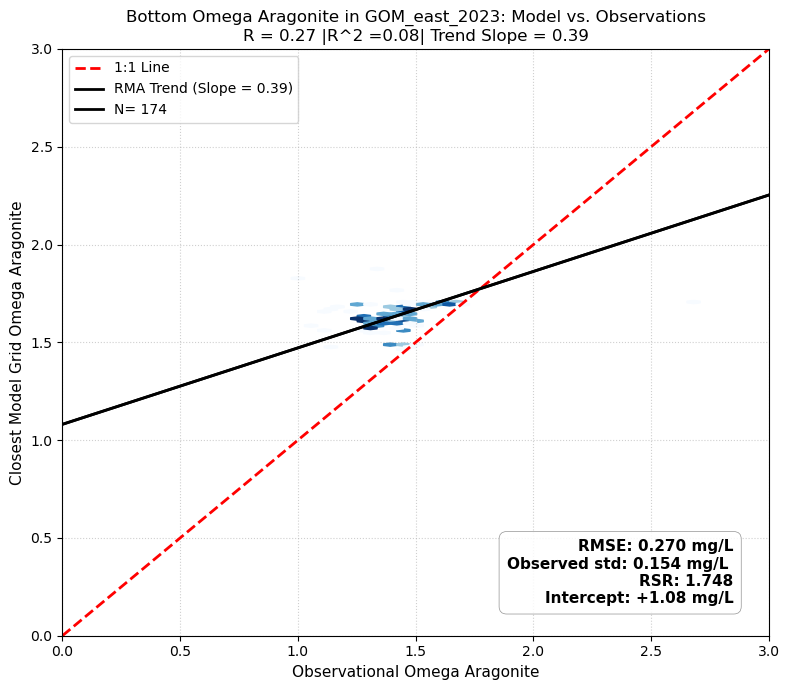

Mean of delta difference between model 3x3x3 grid data and observational data in GOM_east_2024 is: 0.3089
Mean of delta difference between model exact grid data and observational data in GOM_east_2024 is: 0.3428
Global RMSE (3x3x3 grid vs obs) between model and observations in GOM_east_2024 is: 0.3324
Global RMSE (Exact point vs Obs) between model and observations in GOM_east_2024 is: 0.3632
-> Calculated using 12 valid exact points in GOM_east_2024 (out of 12 total pairs).
Calculated Observational Mean: 1.3858
Calculated Model Global Mean: 1.7293
Calculated Global Std Dev: 0.0655
Model grid overestimates the data 100.00 percent of the time
Model grid underestimates the data 0.00 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.3089
When underestimating, the average deficit aragonite (Ω) is: nan
Real-World Observational STD: 0.0926
Model Global STD: 0.0655
Model-to-Observation Variance Ratio: 0.71
Model Grid RSR: 1.0509

ARAGONITE STRESSED STATUS MATCH ME

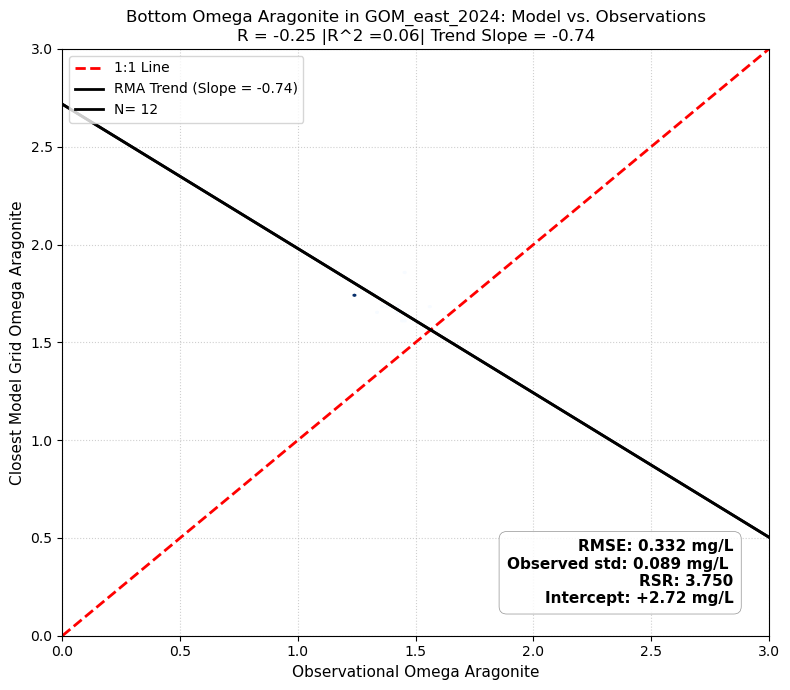


Running Region x Season intersections...
Mean of delta difference between model 3x3x3 grid data and observational data in MAB_south_Spring is: 0.3767
Mean of delta difference between model exact grid data and observational data in MAB_south_Spring is: 0.4629
Global RMSE (3x3x3 grid vs obs) between model and observations in MAB_south_Spring is: 0.5101
Global RMSE (Exact point vs Obs) between model and observations in MAB_south_Spring is: 0.6069
-> Calculated using 556 valid exact points in MAB_south_Spring (out of 556 total pairs).
Calculated Observational Mean: 1.6831
Calculated Model Global Mean: 2.1363
Calculated Global Std Dev: 0.2586
Model grid overestimates the data 89.57 percent of the time
Model grid underestimates the data 10.43 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.4228
When underestimating, the average deficit aragonite (Ω) is: -0.0194
Real-World Observational STD: 0.2637
Model Global STD: 0.2586
Model-to-Observation Variance Ratio: 

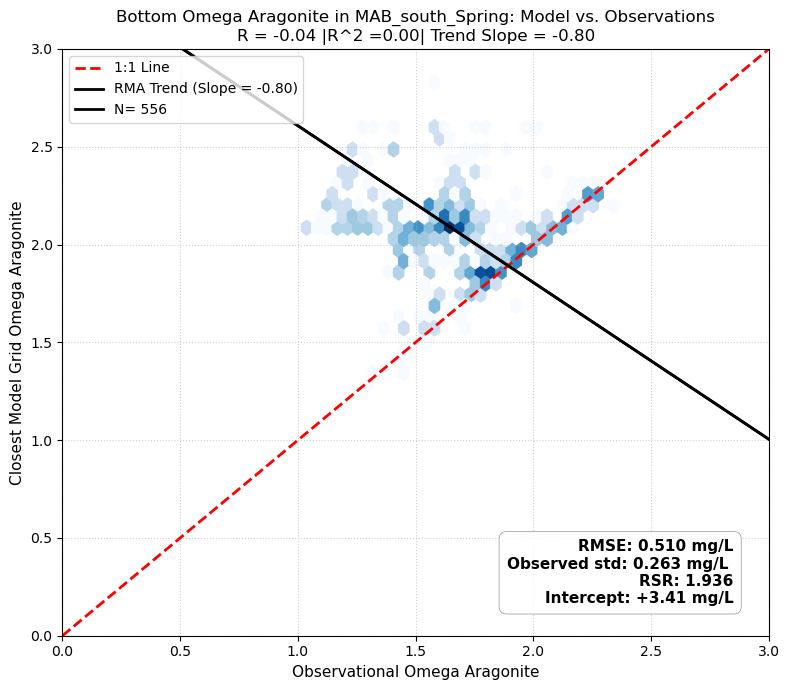

Mean of delta difference between model 3x3x3 grid data and observational data in MAB_south_Summer is: 0.6615
Mean of delta difference between model exact grid data and observational data in MAB_south_Summer is: 0.7460
Global RMSE (3x3x3 grid vs obs) between model and observations in MAB_south_Summer is: 0.7656
Global RMSE (Exact point vs Obs) between model and observations in MAB_south_Summer is: 0.8434
-> Calculated using 574 valid exact points in MAB_south_Summer (out of 574 total pairs).
Calculated Observational Mean: 1.3462
Calculated Model Global Mean: 2.0838
Calculated Global Std Dev: 0.2380
Model grid overestimates the data 93.03 percent of the time
Model grid underestimates the data 6.97 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.7210
When underestimating, the average deficit aragonite (Ω) is: -0.1334
Real-World Observational STD: 0.3384
Model Global STD: 0.2380
Model-to-Observation Variance Ratio: 0.70
Model Grid RSR: 2.4205

ARAGONITE STRE

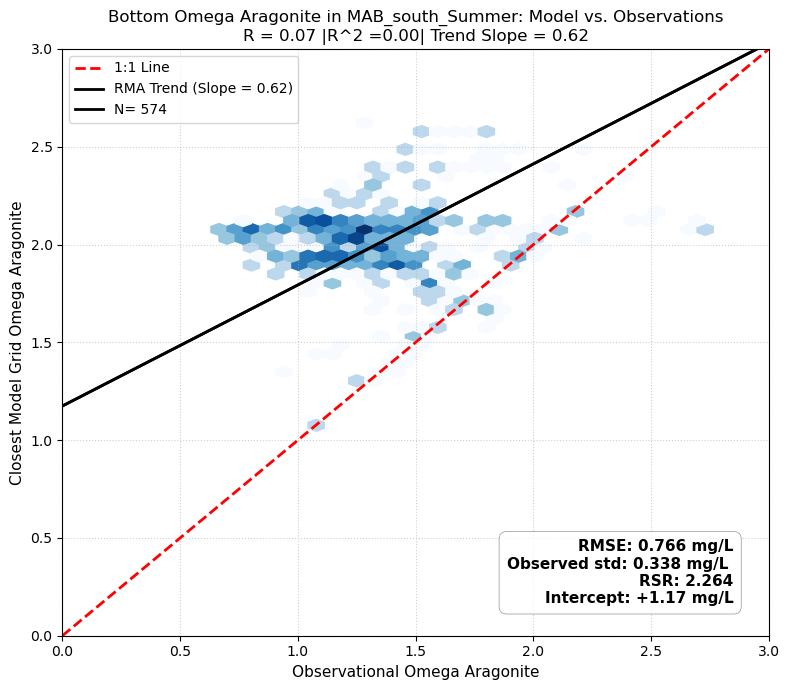

Mean of delta difference between model 3x3x3 grid data and observational data in MAB_south_Fall is: 0.1745
Mean of delta difference between model exact grid data and observational data in MAB_south_Fall is: 0.1994
Global RMSE (3x3x3 grid vs obs) between model and observations in MAB_south_Fall is: 0.4910
Global RMSE (Exact point vs Obs) between model and observations in MAB_south_Fall is: 0.6056
-> Calculated using 621 valid exact points in MAB_south_Fall (out of 621 total pairs).
Calculated Observational Mean: 1.9191
Calculated Model Global Mean: 2.1178
Calculated Global Std Dev: 0.3296
Model grid overestimates the data 65.86 percent of the time
Model grid underestimates the data 34.14 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.3679
When underestimating, the average deficit aragonite (Ω) is: -0.1986
Real-World Observational STD: 0.4797
Model Global STD: 0.3296
Model-to-Observation Variance Ratio: 0.69
Model Grid RSR: 1.5525

ARAGONITE STRESSED STAT

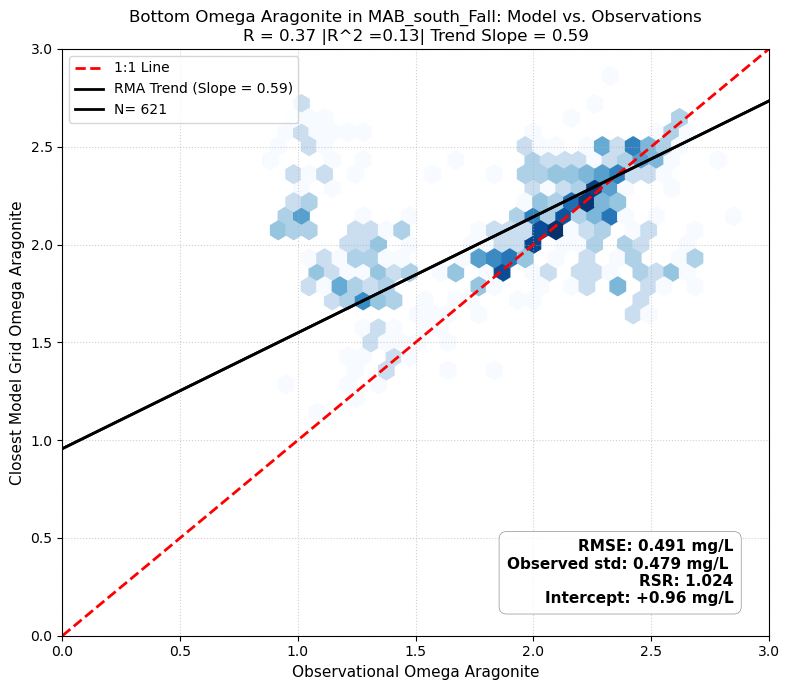

Mean of delta difference between model 3x3x3 grid data and observational data in MAB_south_Winter is: 0.0976
Mean of delta difference between model exact grid data and observational data in MAB_south_Winter is: 0.1558
Global RMSE (3x3x3 grid vs obs) between model and observations in MAB_south_Winter is: 0.2075
Global RMSE (Exact point vs Obs) between model and observations in MAB_south_Winter is: 0.2657
-> Calculated using 41 valid exact points in MAB_south_Winter (out of 41 total pairs).
Calculated Observational Mean: 1.9520
Calculated Model Global Mean: 2.1055
Calculated Global Std Dev: 0.2739
Model grid overestimates the data 73.17 percent of the time
Model grid underestimates the data 26.83 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.1366
When underestimating, the average deficit aragonite (Ω) is: -0.0086
Real-World Observational STD: 0.2454
Model Global STD: 0.2739
Model-to-Observation Variance Ratio: 1.12
Model Grid RSR: 0.6559

ARAGONITE STRES

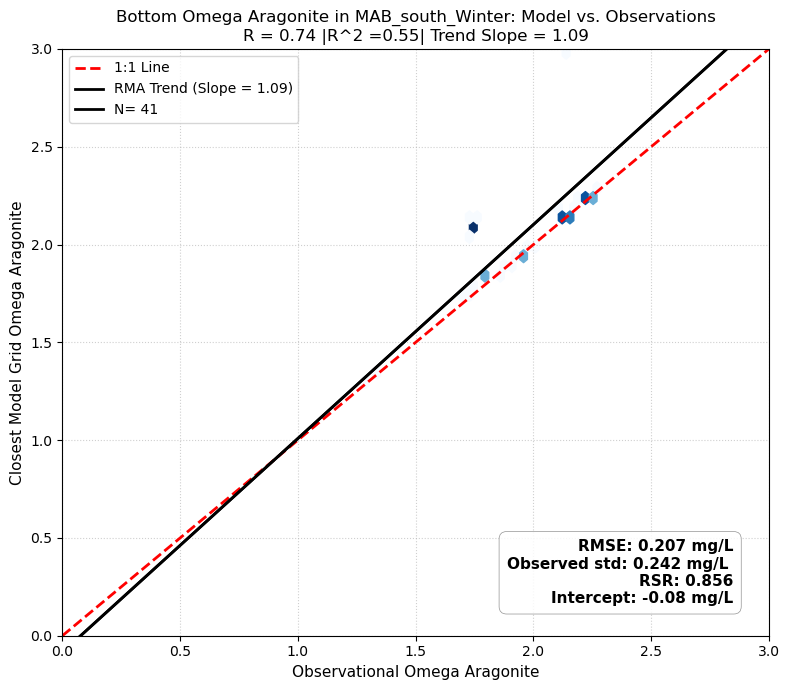

Mean of delta difference between model 3x3x3 grid data and observational data in MAB_north_Spring is: 0.3907
Mean of delta difference between model exact grid data and observational data in MAB_north_Spring is: 0.4394
Global RMSE (3x3x3 grid vs obs) between model and observations in MAB_north_Spring is: 0.5226
Global RMSE (Exact point vs Obs) between model and observations in MAB_north_Spring is: 0.5676
-> Calculated using 546 valid exact points in MAB_north_Spring (out of 546 total pairs).
Calculated Observational Mean: 1.5733
Calculated Model Global Mean: 2.0084
Calculated Global Std Dev: 0.2161
Model grid overestimates the data 89.93 percent of the time
Model grid underestimates the data 10.07 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.4385
When underestimating, the average deficit aragonite (Ω) is: -0.0359
Real-World Observational STD: 0.2582
Model Global STD: 0.2161
Model-to-Observation Variance Ratio: 0.84
Model Grid RSR: 1.6521

ARAGONITE STR

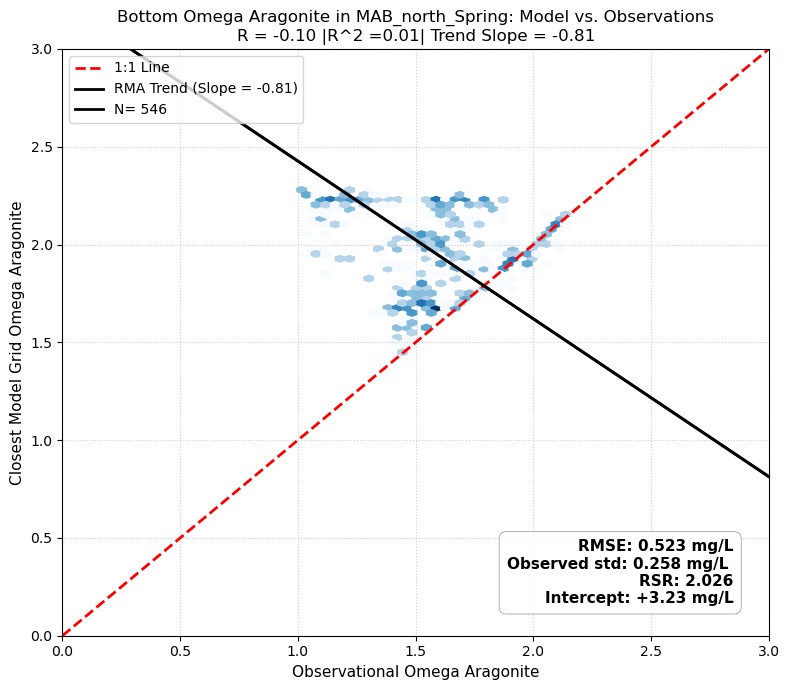

Mean of delta difference between model 3x3x3 grid data and observational data in MAB_north_Summer is: 0.5306
Mean of delta difference between model exact grid data and observational data in MAB_north_Summer is: 0.5822
Global RMSE (3x3x3 grid vs obs) between model and observations in MAB_north_Summer is: 0.6684
Global RMSE (Exact point vs Obs) between model and observations in MAB_north_Summer is: 0.7202
-> Calculated using 611 valid exact points in MAB_north_Summer (out of 611 total pairs).
Calculated Observational Mean: 1.2611
Calculated Model Global Mean: 1.8410
Calculated Global Std Dev: 0.2632
Model grid overestimates the data 88.71 percent of the time
Model grid underestimates the data 11.29 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.6055
When underestimating, the average deficit aragonite (Ω) is: -0.0572
Real-World Observational STD: 0.2890
Model Global STD: 0.2632
Model-to-Observation Variance Ratio: 0.91
Model Grid RSR: 2.1132

ARAGONITE STR

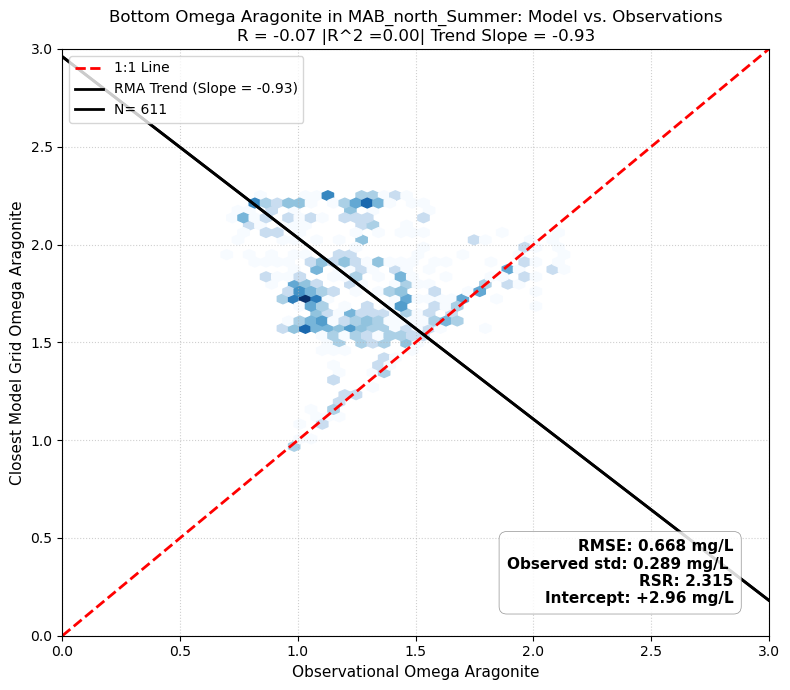

Mean of delta difference between model 3x3x3 grid data and observational data in MAB_north_Fall is: 0.2295
Mean of delta difference between model exact grid data and observational data in MAB_north_Fall is: 0.2493
Global RMSE (3x3x3 grid vs obs) between model and observations in MAB_north_Fall is: 0.5328
Global RMSE (Exact point vs Obs) between model and observations in MAB_north_Fall is: 0.5999
-> Calculated using 526 valid exact points in MAB_north_Fall (out of 526 total pairs).
Calculated Observational Mean: 1.6556
Calculated Model Global Mean: 1.9051
Calculated Global Std Dev: 0.2379
Model grid overestimates the data 66.16 percent of the time
Model grid underestimates the data 33.84 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.4749
When underestimating, the average deficit aragonite (Ω) is: -0.2504
Real-World Observational STD: 0.4901
Model Global STD: 0.2379
Model-to-Observation Variance Ratio: 0.49
Model Grid RSR: 1.6844

ARAGONITE STRESSED STAT

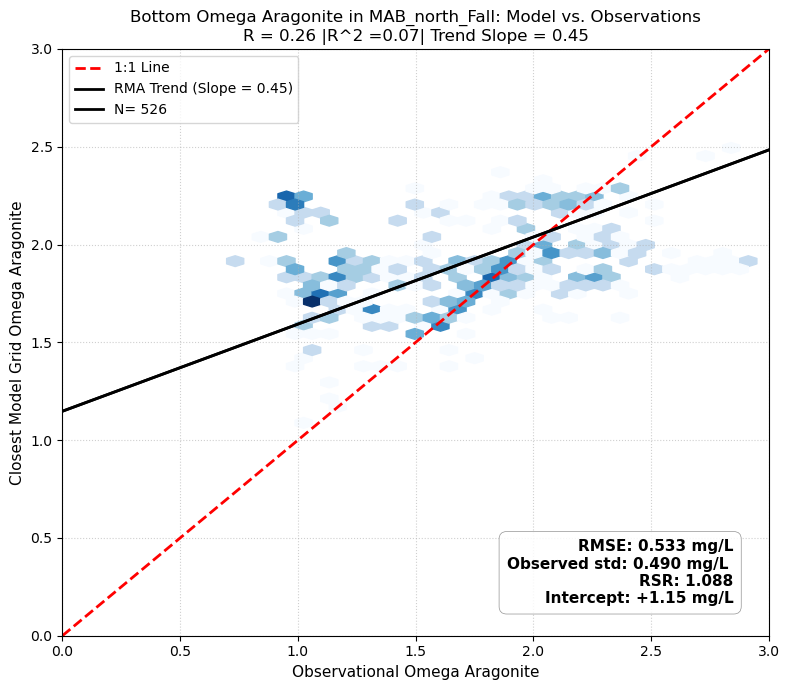

Mean of delta difference between model 3x3x3 grid data and observational data in MAB_north_Winter is: 0.4800
Mean of delta difference between model exact grid data and observational data in MAB_north_Winter is: 0.5297
Global RMSE (3x3x3 grid vs obs) between model and observations in MAB_north_Winter is: 0.5433
Global RMSE (Exact point vs Obs) between model and observations in MAB_north_Winter is: 0.5847
-> Calculated using 123 valid exact points in MAB_north_Winter (out of 123 total pairs).
Calculated Observational Mean: 1.6234
Calculated Model Global Mean: 2.1433
Calculated Global Std Dev: 0.1537
Model grid overestimates the data 96.75 percent of the time
Model grid underestimates the data 3.25 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.4985
When underestimating, the average deficit aragonite (Ω) is: -0.0723
Real-World Observational STD: 0.1931
Model Global STD: 0.1537
Model-to-Observation Variance Ratio: 0.80
Model Grid RSR: 1.7178

ARAGONITE STRE

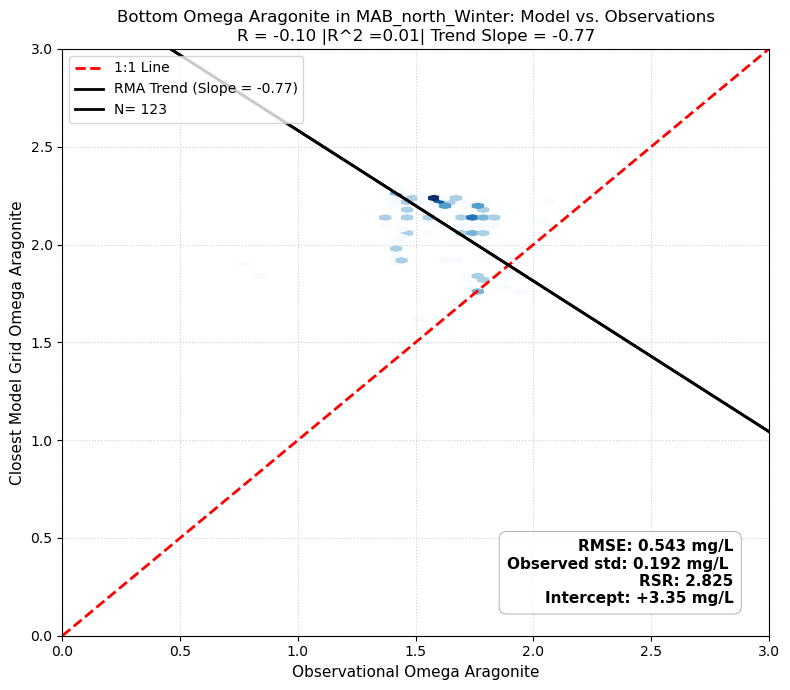

Mean of delta difference between model 3x3x3 grid data and observational data in GB_Spring is: 0.1754
Mean of delta difference between model exact grid data and observational data in GB_Spring is: 0.2180
Global RMSE (3x3x3 grid vs obs) between model and observations in GB_Spring is: 0.2432
Global RMSE (Exact point vs Obs) between model and observations in GB_Spring is: 0.3211
-> Calculated using 16 valid exact points in GB_Spring (out of 16 total pairs).
Calculated Observational Mean: 1.6394
Calculated Model Global Mean: 1.8978
Calculated Global Std Dev: 0.2908
Model grid overestimates the data 100.00 percent of the time
Model grid underestimates the data 0.00 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.1754
When underestimating, the average deficit aragonite (Ω) is: nan
Real-World Observational STD: 0.2127
Model Global STD: 0.2908
Model-to-Observation Variance Ratio: 1.37
Model Grid RSR: 0.7690

ARAGONITE STRESSED STATUS MATCH METRICS (Numeric: Thre

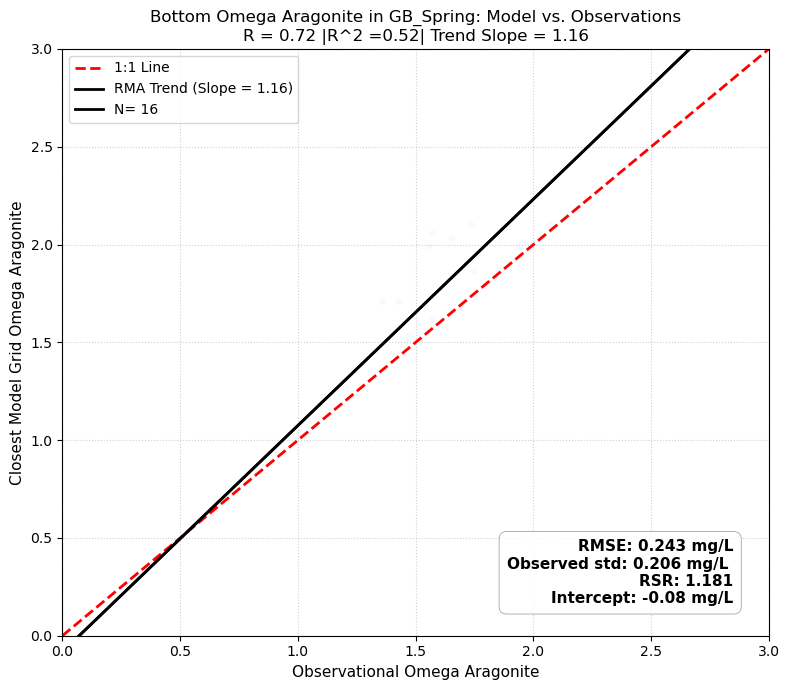

Mean of delta difference between model 3x3x3 grid data and observational data in GB_Summer is: 0.2292
Mean of delta difference between model exact grid data and observational data in GB_Summer is: 0.2571
Global RMSE (3x3x3 grid vs obs) between model and observations in GB_Summer is: 0.3070
Global RMSE (Exact point vs Obs) between model and observations in GB_Summer is: 0.3648
-> Calculated using 48 valid exact points in GB_Summer (out of 48 total pairs).
Calculated Observational Mean: 1.6255
Calculated Model Global Mean: 1.9011
Calculated Global Std Dev: 0.2717
Model grid overestimates the data 87.50 percent of the time
Model grid underestimates the data 12.50 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.2663
When underestimating, the average deficit aragonite (Ω) is: -0.0309
Real-World Observational STD: 0.2723
Model Global STD: 0.2717
Model-to-Observation Variance Ratio: 1.00
Model Grid RSR: 0.9706

ARAGONITE STRESSED STATUS MATCH METRICS (Numeric: 

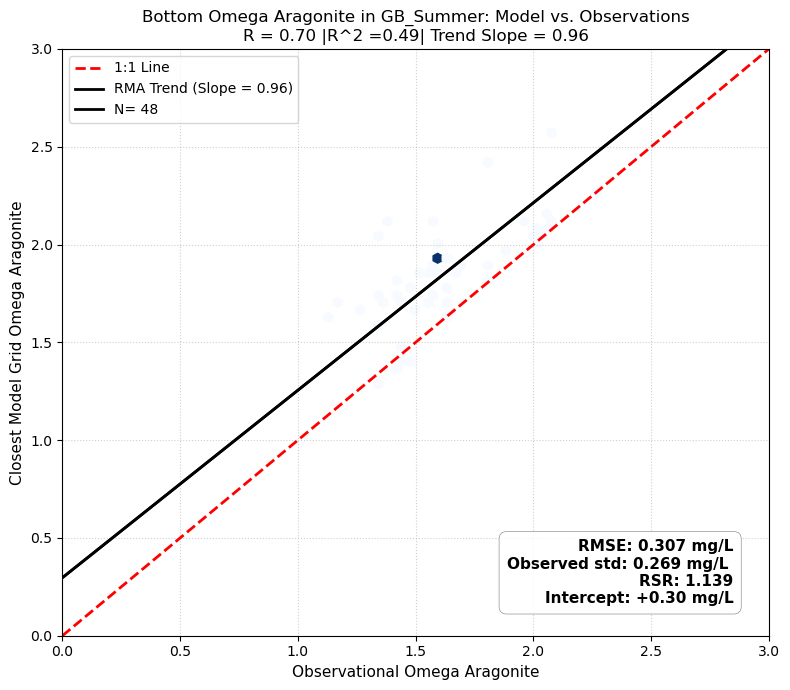

Mean of delta difference between model 3x3x3 grid data and observational data in GB_Fall is: 0.2182
Mean of delta difference between model exact grid data and observational data in GB_Fall is: 0.2641
Global RMSE (3x3x3 grid vs obs) between model and observations in GB_Fall is: 0.3241
Global RMSE (Exact point vs Obs) between model and observations in GB_Fall is: 0.3757
-> Calculated using 14 valid exact points in GB_Fall (out of 14 total pairs).
Calculated Observational Mean: 1.6693
Calculated Model Global Mean: 1.9644
Calculated Global Std Dev: 0.3539
Model grid overestimates the data 78.57 percent of the time
Model grid underestimates the data 21.43 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.2887
When underestimating, the average deficit aragonite (Ω) is: -0.0402
Real-World Observational STD: 0.1957
Model Global STD: 0.3539
Model-to-Observation Variance Ratio: 1.81
Model Grid RSR: 1.0245

ARAGONITE STRESSED STATUS MATCH METRICS (Numeric: Threshold 

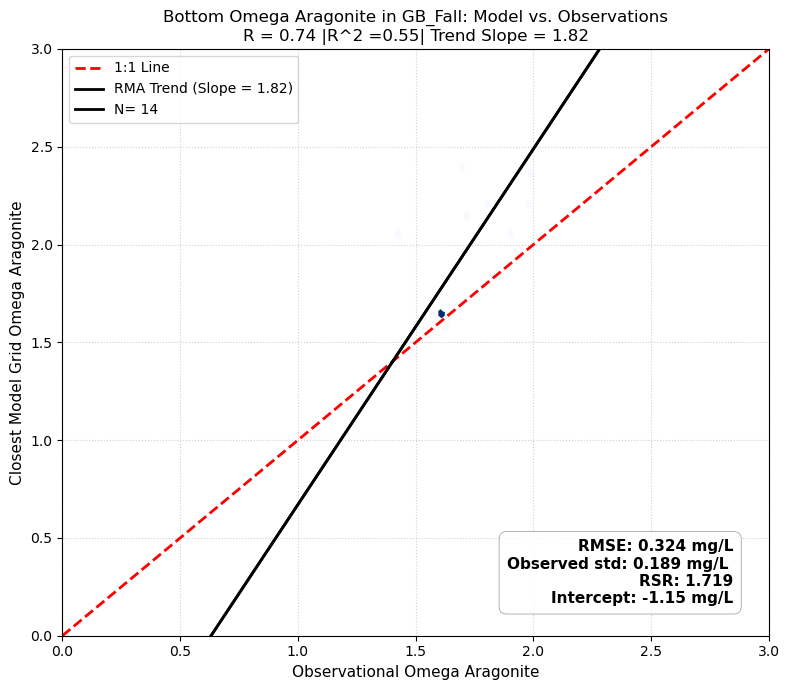

Mean of delta difference between model 3x3x3 grid data and observational data in GB_Winter is: 0.2384
Mean of delta difference between model exact grid data and observational data in GB_Winter is: 0.3230
Global RMSE (3x3x3 grid vs obs) between model and observations in GB_Winter is: 0.3175
Global RMSE (Exact point vs Obs) between model and observations in GB_Winter is: 0.3361
-> Calculated using 4 valid exact points in GB_Winter (out of 4 total pairs).
Calculated Observational Mean: 1.5025
Calculated Model Global Mean: 1.8622
Calculated Global Std Dev: 0.2096
Model grid overestimates the data 75.00 percent of the time
Model grid underestimates the data 25.00 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.3550
When underestimating, the average deficit aragonite (Ω) is: -0.1114
Real-World Observational STD: 0.0960
Model Global STD: 0.2096
Model-to-Observation Variance Ratio: 2.18
Model Grid RSR: 1.0038


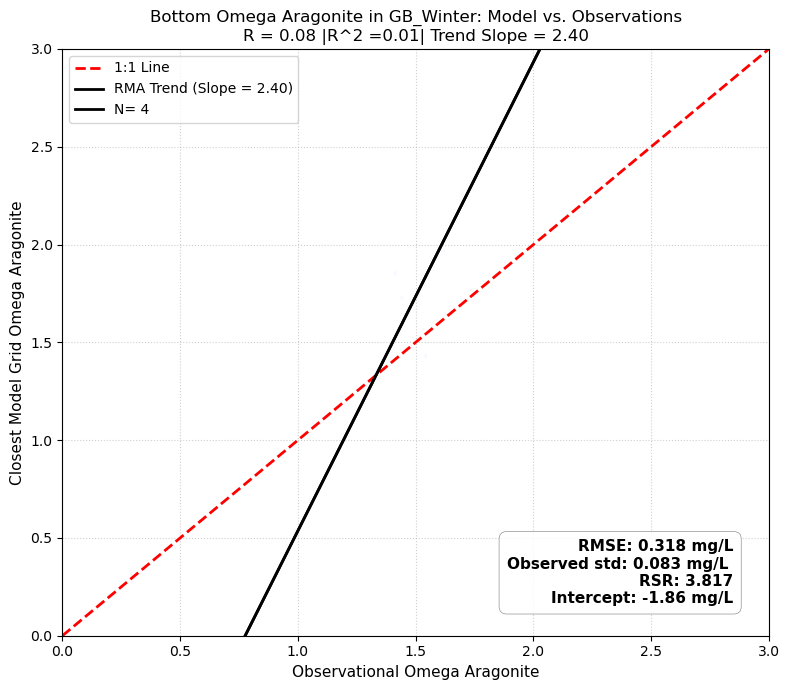

Mean of delta difference between model 3x3x3 grid data and observational data in GOM_west_Spring is: 0.0522
Mean of delta difference between model exact grid data and observational data in GOM_west_Spring is: 0.0037
Global RMSE (3x3x3 grid vs obs) between model and observations in GOM_west_Spring is: 0.1481
Global RMSE (Exact point vs Obs) between model and observations in GOM_west_Spring is: 0.1893
-> Calculated using 28 valid exact points in GOM_west_Spring (out of 28 total pairs).
Calculated Observational Mean: 1.4614
Calculated Model Global Mean: 1.4935
Calculated Global Std Dev: 0.1026
Model grid overestimates the data 60.71 percent of the time
Model grid underestimates the data 39.29 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.0952
When underestimating, the average deficit aragonite (Ω) is: -0.0142
Real-World Observational STD: 0.1276
Model Global STD: 0.1026
Model-to-Observation Variance Ratio: 0.80
Model Grid RSR: 0.4682

ARAGONITE STRESSED S

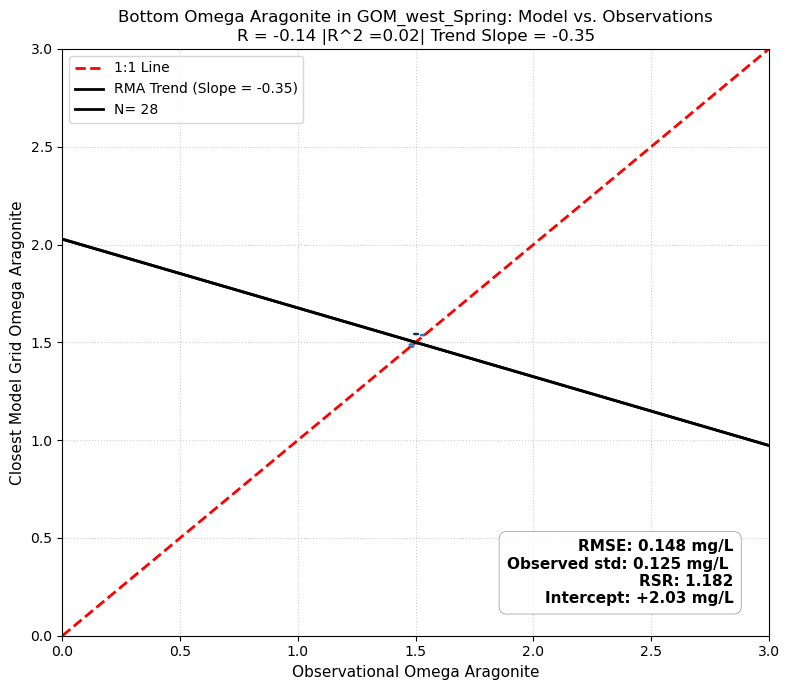

Mean of delta difference between model 3x3x3 grid data and observational data in GOM_west_Summer is: 0.1764
Mean of delta difference between model exact grid data and observational data in GOM_west_Summer is: 0.2149
Global RMSE (3x3x3 grid vs obs) between model and observations in GOM_west_Summer is: 0.2559
Global RMSE (Exact point vs Obs) between model and observations in GOM_west_Summer is: 0.2918
-> Calculated using 230 valid exact points in GOM_west_Summer (out of 230 total pairs).
Calculated Observational Mean: 1.3097
Calculated Model Global Mean: 1.5339
Calculated Global Std Dev: 0.1158
Model grid overestimates the data 86.52 percent of the time
Model grid underestimates the data 13.48 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.2057
When underestimating, the average deficit aragonite (Ω) is: -0.0116
Real-World Observational STD: 0.1510
Model Global STD: 0.1158
Model-to-Observation Variance Ratio: 0.77
Model Grid RSR: 0.8091

ARAGONITE STRESSED

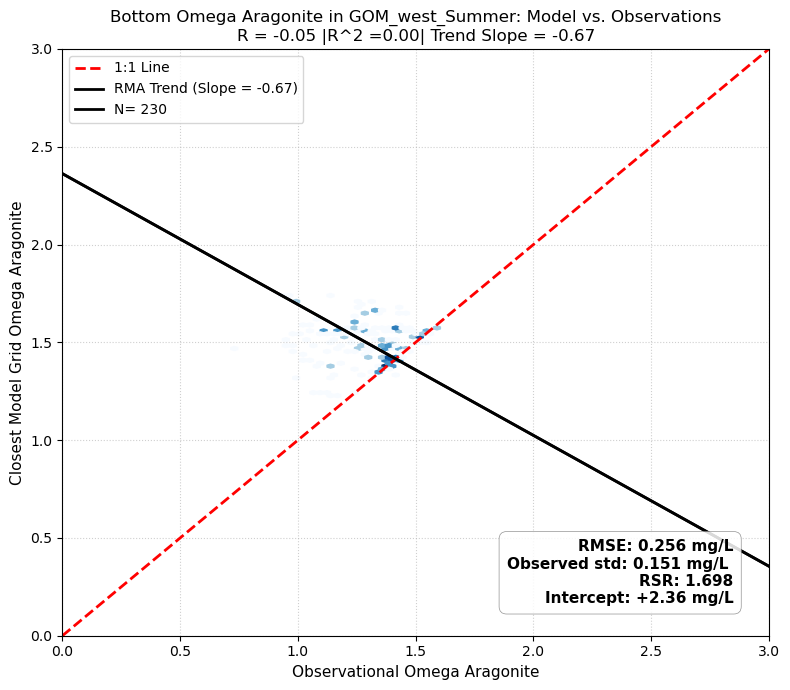

Mean of delta difference between model 3x3x3 grid data and observational data in GOM_west_Fall is: 0.0697
Mean of delta difference between model exact grid data and observational data in GOM_west_Fall is: 0.0772
Global RMSE (3x3x3 grid vs obs) between model and observations in GOM_west_Fall is: 0.1676
Global RMSE (Exact point vs Obs) between model and observations in GOM_west_Fall is: 0.2110
-> Calculated using 194 valid exact points in GOM_west_Fall (out of 194 total pairs).
Calculated Observational Mean: 1.3658
Calculated Model Global Mean: 1.4542
Calculated Global Std Dev: 0.1361
Model grid overestimates the data 67.53 percent of the time
Model grid underestimates the data 32.47 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.1320
When underestimating, the average deficit aragonite (Ω) is: -0.0600
Real-World Observational STD: 0.1460
Model Global STD: 0.1361
Model-to-Observation Variance Ratio: 0.93
Model Grid RSR: 0.5300

ARAGONITE STRESSED STATUS MA

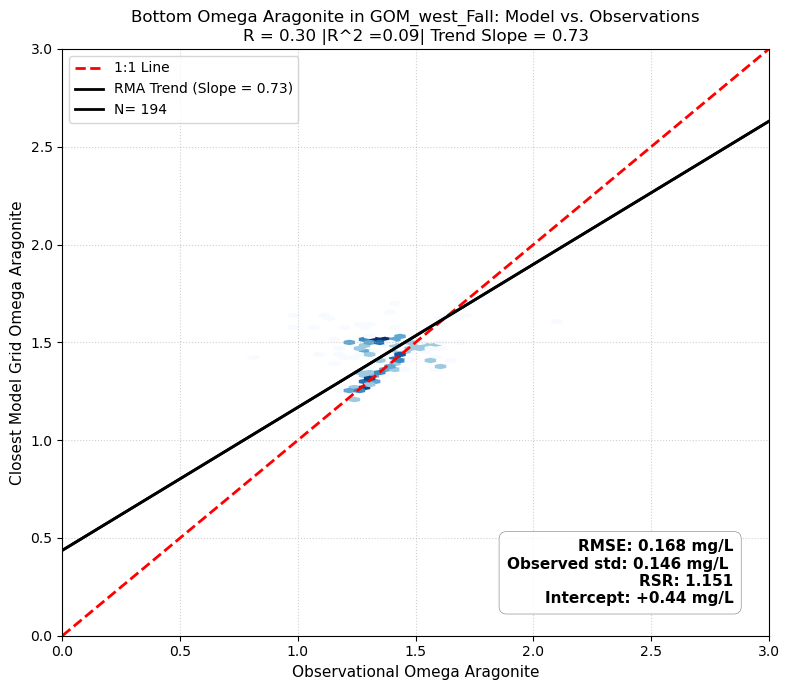

Mean of delta difference between model 3x3x3 grid data and observational data in GOM_west_Winter is: 0.1187
Mean of delta difference between model exact grid data and observational data in GOM_west_Winter is: 0.1498
Global RMSE (3x3x3 grid vs obs) between model and observations in GOM_west_Winter is: 0.1690
Global RMSE (Exact point vs Obs) between model and observations in GOM_west_Winter is: 0.2065
-> Calculated using 166 valid exact points in GOM_west_Winter (out of 166 total pairs).
Calculated Observational Mean: 1.4035
Calculated Model Global Mean: 1.5577
Calculated Global Std Dev: 0.1370
Model grid overestimates the data 83.73 percent of the time
Model grid underestimates the data 16.27 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.1519
When underestimating, the average deficit aragonite (Ω) is: -0.0519
Real-World Observational STD: 0.1489
Model Global STD: 0.1370
Model-to-Observation Variance Ratio: 0.92
Model Grid RSR: 0.5343

ARAGONITE STRESSED

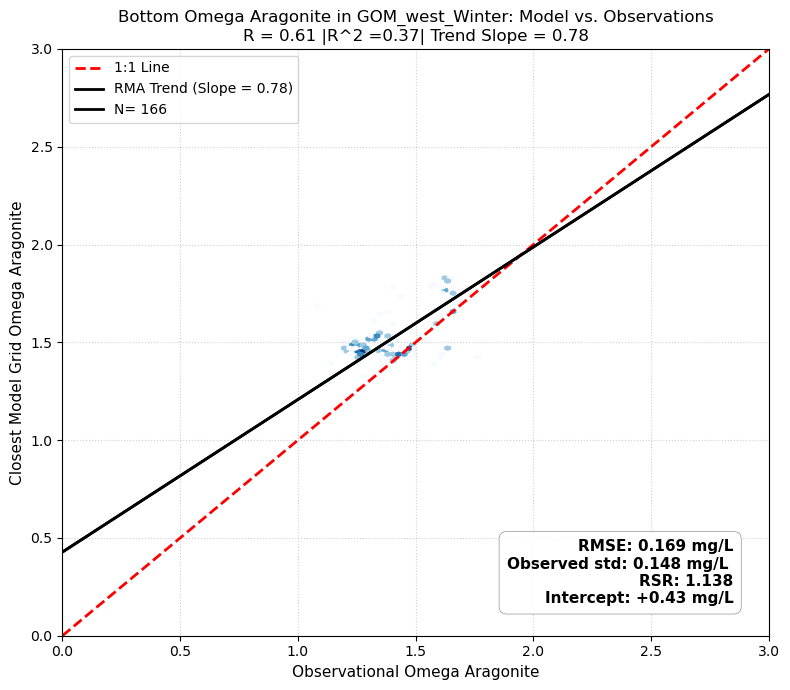

Mean of delta difference between model 3x3x3 grid data and observational data in GOM_east_Spring is: 0.1369
Mean of delta difference between model exact grid data and observational data in GOM_east_Spring is: 0.1729
Global RMSE (3x3x3 grid vs obs) between model and observations in GOM_east_Spring is: 0.1665
Global RMSE (Exact point vs Obs) between model and observations in GOM_east_Spring is: 0.1997
-> Calculated using 91 valid exact points in GOM_east_Spring (out of 91 total pairs).
Calculated Observational Mean: 1.4795
Calculated Model Global Mean: 1.6509
Calculated Global Std Dev: 0.0871
Model grid overestimates the data 93.41 percent of the time
Model grid underestimates the data 6.59 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.1468
When underestimating, the average deficit aragonite (Ω) is: -0.0044
Real-World Observational STD: 0.0826
Model Global STD: 0.0871
Model-to-Observation Variance Ratio: 1.05
Model Grid RSR: 0.5263

ARAGONITE STRESSED ST

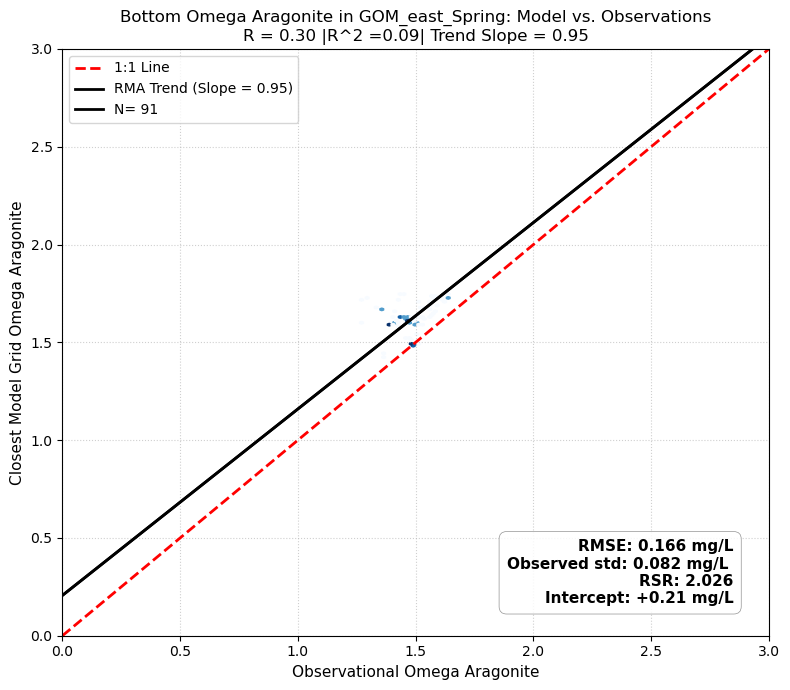

Mean of delta difference between model 3x3x3 grid data and observational data in GOM_east_Summer is: 0.2078
Mean of delta difference between model exact grid data and observational data in GOM_east_Summer is: 0.2358
Global RMSE (3x3x3 grid vs obs) between model and observations in GOM_east_Summer is: 0.2659
Global RMSE (Exact point vs Obs) between model and observations in GOM_east_Summer is: 0.2986
-> Calculated using 248 valid exact points in GOM_east_Summer (out of 248 total pairs).
Calculated Observational Mean: 1.4408
Calculated Model Global Mean: 1.6778
Calculated Global Std Dev: 0.1560
Model grid overestimates the data 91.13 percent of the time
Model grid underestimates the data 8.87 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.2363
When underestimating, the average deficit aragonite (Ω) is: -0.0858
Real-World Observational STD: 0.1477
Model Global STD: 0.1560
Model-to-Observation Variance Ratio: 1.06
Model Grid RSR: 0.8407

ARAGONITE STRESSED 

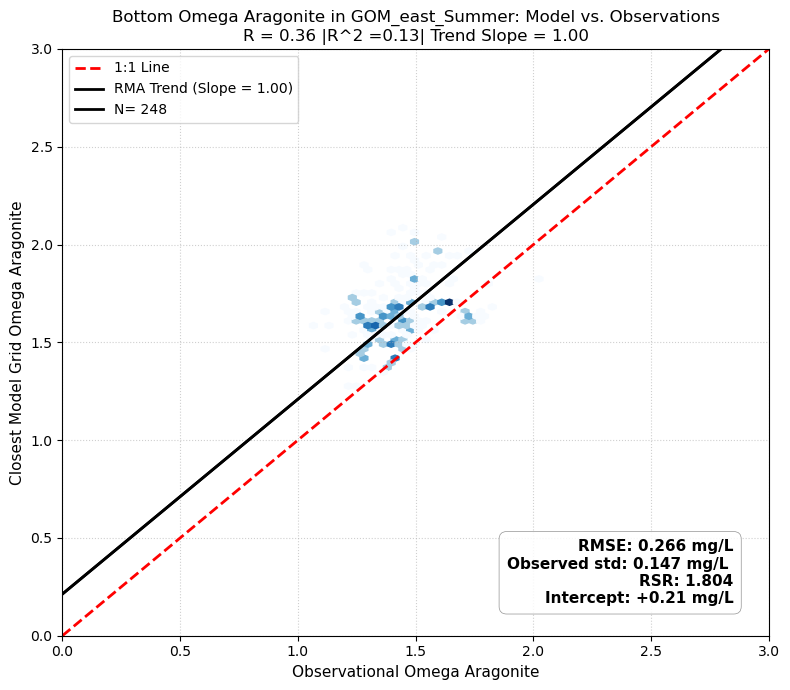

Mean of delta difference between model 3x3x3 grid data and observational data in GOM_east_Fall is: 0.1159
Mean of delta difference between model exact grid data and observational data in GOM_east_Fall is: 0.1236
Global RMSE (3x3x3 grid vs obs) between model and observations in GOM_east_Fall is: 0.2024
Global RMSE (Exact point vs Obs) between model and observations in GOM_east_Fall is: 0.2315
-> Calculated using 238 valid exact points in GOM_east_Fall (out of 238 total pairs).
Calculated Observational Mean: 1.4985
Calculated Model Global Mean: 1.6267
Calculated Global Std Dev: 0.0790
Model grid overestimates the data 81.51 percent of the time
Model grid underestimates the data 18.49 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.1677
When underestimating, the average deficit aragonite (Ω) is: -0.1123
Real-World Observational STD: 0.1753
Model Global STD: 0.0790
Model-to-Observation Variance Ratio: 0.45
Model Grid RSR: 0.6399

ARAGONITE STRESSED STATUS MA

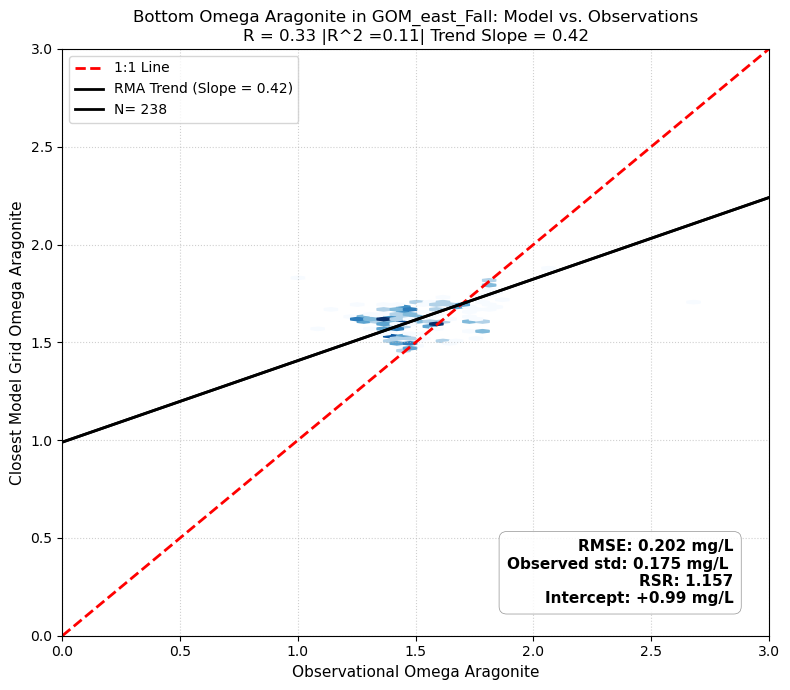

Mean of delta difference between model 3x3x3 grid data and observational data in GOM_east_Winter is: 0.1854
Mean of delta difference between model exact grid data and observational data in GOM_east_Winter is: 0.2140
Global RMSE (3x3x3 grid vs obs) between model and observations in GOM_east_Winter is: 0.2137
Global RMSE (Exact point vs Obs) between model and observations in GOM_east_Winter is: 0.2348
-> Calculated using 76 valid exact points in GOM_east_Winter (out of 76 total pairs).
Calculated Observational Mean: 1.4801
Calculated Model Global Mean: 1.6990
Calculated Global Std Dev: 0.0846
Model grid overestimates the data 96.05 percent of the time
Model grid underestimates the data 3.95 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.1932
When underestimating, the average deficit aragonite (Ω) is: -0.0049
Real-World Observational STD: 0.1361
Model Global STD: 0.0846
Model-to-Observation Variance Ratio: 0.62
Model Grid RSR: 0.6756

ARAGONITE STRESSED ST

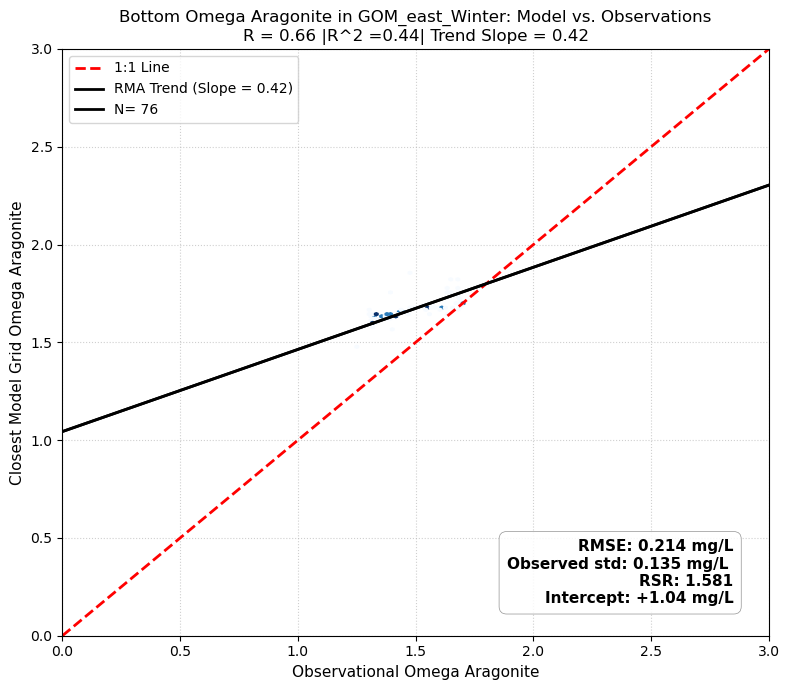


Running Region x Depth intersections...

>>> Analyzing Combination: MAB_south_Shallow(<25m) (N=369)
Mean of delta difference between model 3x3x3 grid data and observational data in MAB_south_Shallow(<25m) is: 0.3917
Mean of delta difference between model exact grid data and observational data in MAB_south_Shallow(<25m) is: 0.4297
Global RMSE (3x3x3 grid vs obs) between model and observations in MAB_south_Shallow(<25m) is: 0.5852
Global RMSE (Exact point vs Obs) between model and observations in MAB_south_Shallow(<25m) is: 0.6604
-> Calculated using 369 valid exact points in MAB_south_Shallow(<25m) (out of 369 total pairs).
Calculated Observational Mean: 1.6109
Calculated Model Global Mean: 2.0456
Calculated Global Std Dev: 0.2568
Model grid overestimates the data 79.13 percent of the time
Model grid underestimates the data 20.87 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.5291
When underestimating, the average deficit aragonite (Ω) is: -0.1293
Real-

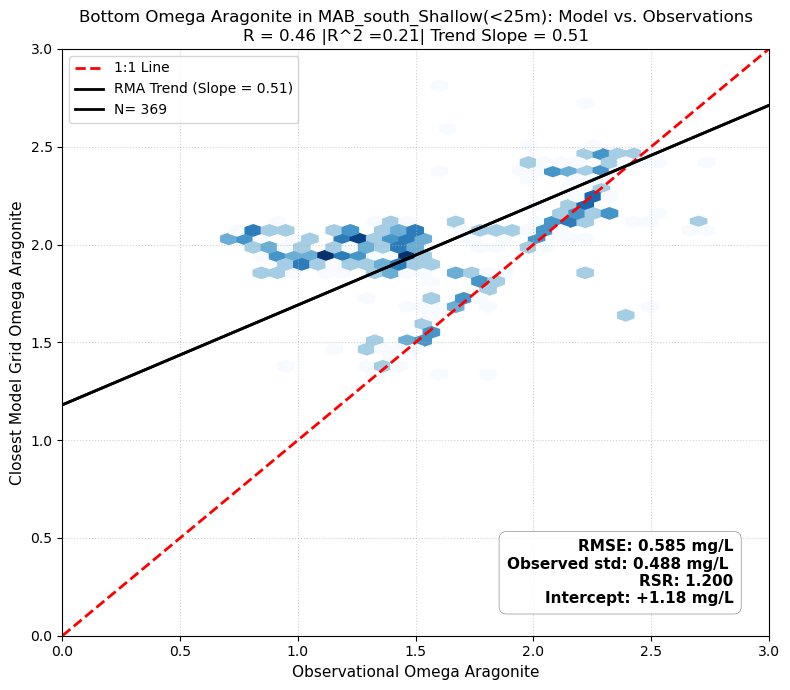


>>> Analyzing Combination: MAB_south_Inner-midshelf(<150m) (N=1412)
Mean of delta difference between model 3x3x3 grid data and observational data in MAB_south_Inner-midshelf(<150m) is: 0.3942
Mean of delta difference between model exact grid data and observational data in MAB_south_Inner-midshelf(<150m) is: 0.4642
Global RMSE (3x3x3 grid vs obs) between model and observations in MAB_south_Inner-midshelf(<150m) is: 0.5987
Global RMSE (Exact point vs Obs) between model and observations in MAB_south_Inner-midshelf(<150m) is: 0.6950
-> Calculated using 1412 valid exact points in MAB_south_Inner-midshelf(<150m) (out of 1412 total pairs).
Calculated Observational Mean: 1.6791
Calculated Model Global Mean: 2.1337
Calculated Global Std Dev: 0.2795
Model grid overestimates the data 82.93 percent of the time
Model grid underestimates the data 17.07 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.5083
When underestimating, the average deficit aragonite (Ω) is: -0.

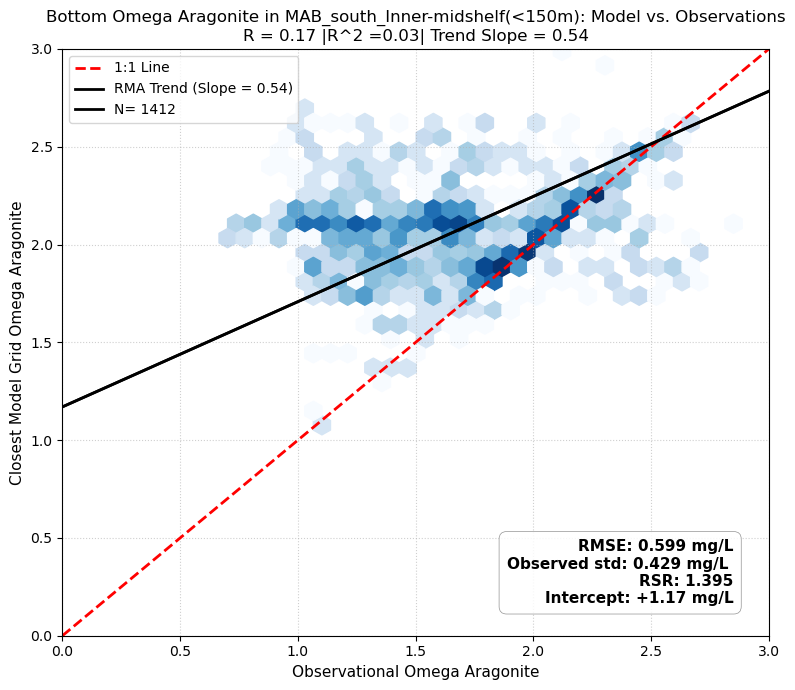


>>> Analyzing Combination: MAB_south_Shelf_slope(<400m) (N=10)
Mean of delta difference between model 3x3x3 grid data and observational data in MAB_south_Shelf_slope(<400m) is: 0.0290
Mean of delta difference between model exact grid data and observational data in MAB_south_Shelf_slope(<400m) is: 0.1596
Global RMSE (3x3x3 grid vs obs) between model and observations in MAB_south_Shelf_slope(<400m) is: 0.1155
Global RMSE (Exact point vs Obs) between model and observations in MAB_south_Shelf_slope(<400m) is: 0.2820
-> Calculated using 10 valid exact points in MAB_south_Shelf_slope(<400m) (out of 10 total pairs).
Calculated Observational Mean: 1.3745
Calculated Model Global Mean: 1.6268
Calculated Global Std Dev: 0.3450
Model grid overestimates the data 70.00 percent of the time
Model grid underestimates the data 30.00 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.0660
When underestimating, the average deficit aragonite (Ω) is: -0.0573
Real-World Observat

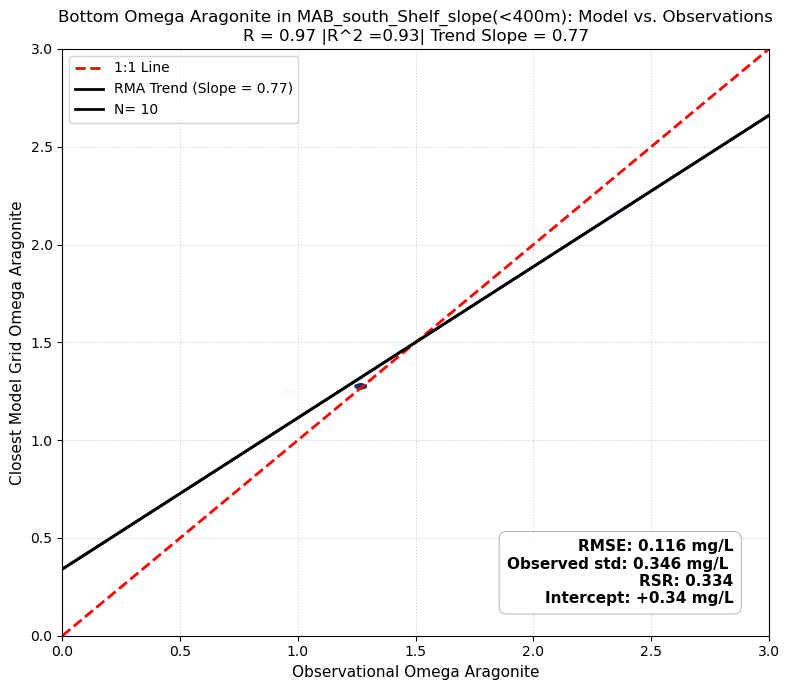


>>> Analyzing Combination: MAB_north_Shallow(<25m) (N=50)
Mean of delta difference between model 3x3x3 grid data and observational data in MAB_north_Shallow(<25m) is: 0.2071
Mean of delta difference between model exact grid data and observational data in MAB_north_Shallow(<25m) is: 0.1843
Global RMSE (3x3x3 grid vs obs) between model and observations in MAB_north_Shallow(<25m) is: 0.4791
Global RMSE (Exact point vs Obs) between model and observations in MAB_north_Shallow(<25m) is: 0.6360
-> Calculated using 50 valid exact points in MAB_north_Shallow(<25m) (out of 50 total pairs).
Calculated Observational Mean: 1.6571
Calculated Model Global Mean: 1.8584
Calculated Global Std Dev: 0.3514
Model grid overestimates the data 66.00 percent of the time
Model grid underestimates the data 34.00 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.4144
When underestimating, the average deficit aragonite (Ω) is: -0.1953
Real-World Observational STD: 0.4588
Model Global

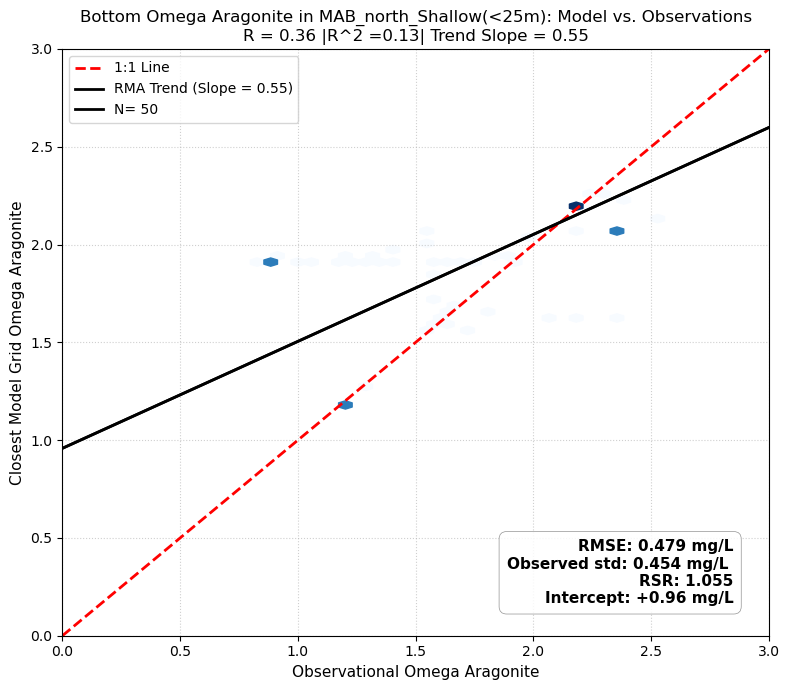


>>> Analyzing Combination: MAB_north_Inner-midshelf(<150m) (N=1734)
Mean of delta difference between model 3x3x3 grid data and observational data in MAB_north_Inner-midshelf(<150m) is: 0.4077
Mean of delta difference between model exact grid data and observational data in MAB_north_Inner-midshelf(<150m) is: 0.4510
Global RMSE (3x3x3 grid vs obs) between model and observations in MAB_north_Inner-midshelf(<150m) is: 0.5863
Global RMSE (Exact point vs Obs) between model and observations in MAB_north_Inner-midshelf(<150m) is: 0.6367
-> Calculated using 1734 valid exact points in MAB_north_Inner-midshelf(<150m) (out of 1734 total pairs).
Calculated Observational Mean: 1.4864
Calculated Model Global Mean: 1.9354
Calculated Global Std Dev: 0.2477
Model grid overestimates the data 84.08 percent of the time
Model grid underestimates the data 15.92 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.5171
When underestimating, the average deficit aragonite (Ω) is: -0.

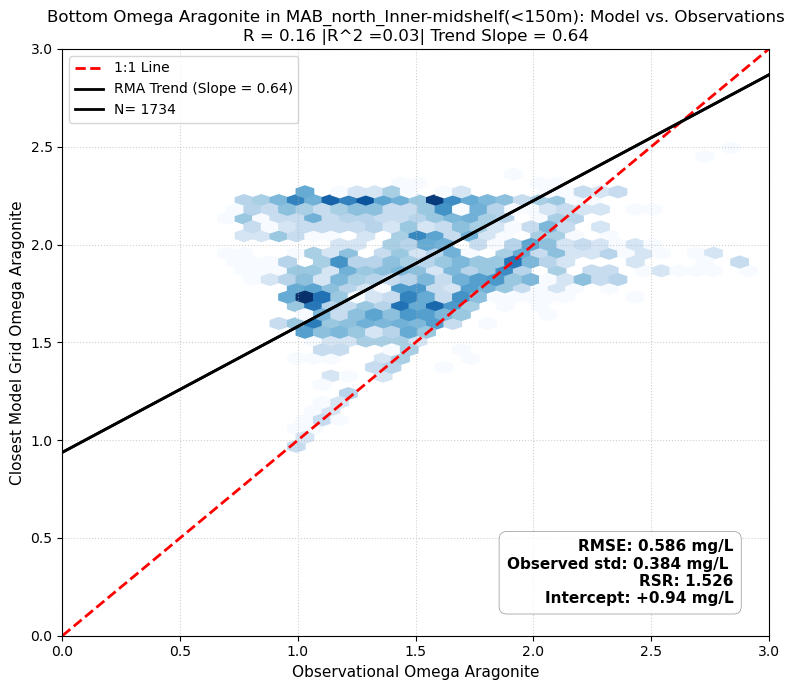


>>> Analyzing Combination: MAB_north_Shelf_slope(<400m) (N=22)
Mean of delta difference between model 3x3x3 grid data and observational data in MAB_north_Shelf_slope(<400m) is: 0.0006
Mean of delta difference between model exact grid data and observational data in MAB_north_Shelf_slope(<400m) is: 0.0339
Global RMSE (3x3x3 grid vs obs) between model and observations in MAB_north_Shelf_slope(<400m) is: 0.0638
Global RMSE (Exact point vs Obs) between model and observations in MAB_north_Shelf_slope(<400m) is: 0.2017
-> Calculated using 22 valid exact points in MAB_north_Shelf_slope(<400m) (out of 22 total pairs).
Calculated Observational Mean: 1.8059
Calculated Model Global Mean: 1.7400
Calculated Global Std Dev: 0.2097
Model grid overestimates the data 40.91 percent of the time
Model grid underestimates the data 59.09 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.0504
When underestimating, the average deficit aragonite (Ω) is: -0.0339
Real-World Observat

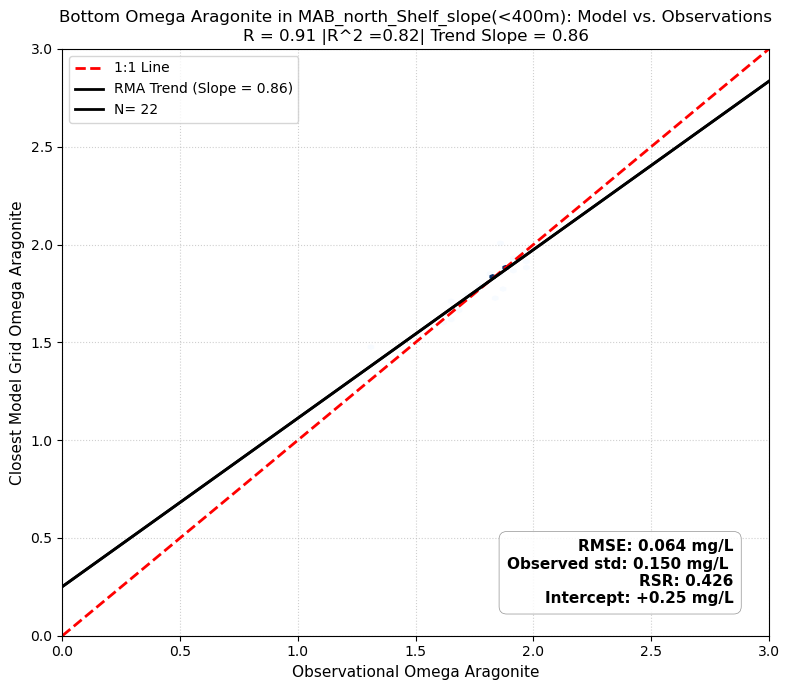


>>> Analyzing Combination: GB_Inner-midshelf(<150m) (N=61)
Mean of delta difference between model 3x3x3 grid data and observational data in GB_Inner-midshelf(<150m) is: 0.2817
Mean of delta difference between model exact grid data and observational data in GB_Inner-midshelf(<150m) is: 0.3300
Global RMSE (3x3x3 grid vs obs) between model and observations in GB_Inner-midshelf(<150m) is: 0.3414
Global RMSE (Exact point vs Obs) between model and observations in GB_Inner-midshelf(<150m) is: 0.3987
-> Calculated using 61 valid exact points in GB_Inner-midshelf(<150m) (out of 61 total pairs).
Calculated Observational Mean: 1.6596
Calculated Model Global Mean: 2.0006
Calculated Global Std Dev: 0.2373
Model grid overestimates the data 96.72 percent of the time
Model grid underestimates the data 3.28 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.2913
When underestimating, the average deficit aragonite (Ω) is: -0.0025
Real-World Observational STD: 0.2535
Model G

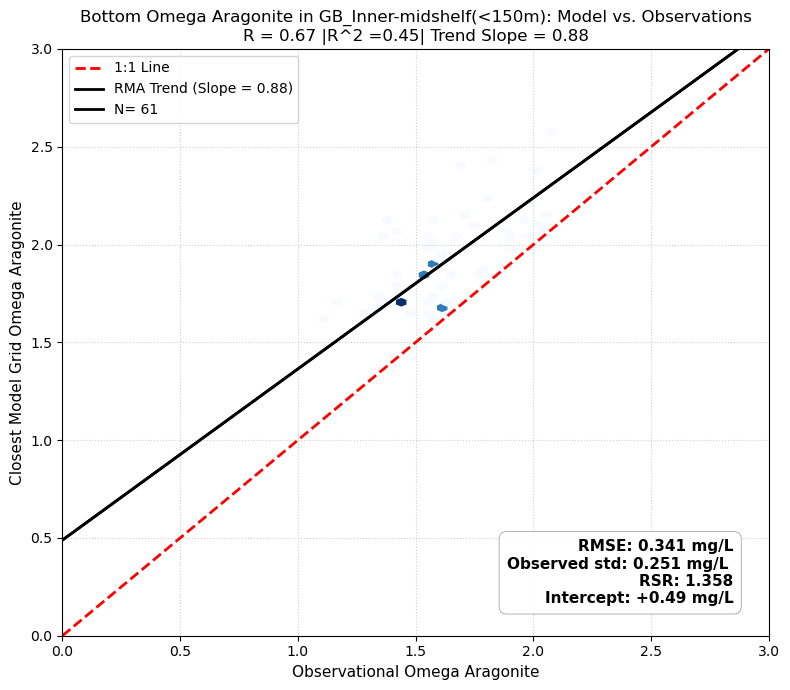


>>> Analyzing Combination: GB_Shelf_slope(<400m) (N=20)
Mean of delta difference between model 3x3x3 grid data and observational data in GB_Shelf_slope(<400m) is: 0.0338
Mean of delta difference between model exact grid data and observational data in GB_Shelf_slope(<400m) is: 0.0312
Global RMSE (3x3x3 grid vs obs) between model and observations in GB_Shelf_slope(<400m) is: 0.1077
Global RMSE (Exact point vs Obs) between model and observations in GB_Shelf_slope(<400m) is: 0.1954
-> Calculated using 20 valid exact points in GB_Shelf_slope(<400m) (out of 20 total pairs).
Calculated Observational Mean: 1.5535
Calculated Model Global Mean: 1.6534
Calculated Global Std Dev: 0.2451
Model grid overestimates the data 65.00 percent of the time
Model grid underestimates the data 35.00 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.0805
When underestimating, the average deficit aragonite (Ω) is: -0.0529
Real-World Observational STD: 0.1867
Model Global STD: 0.2451

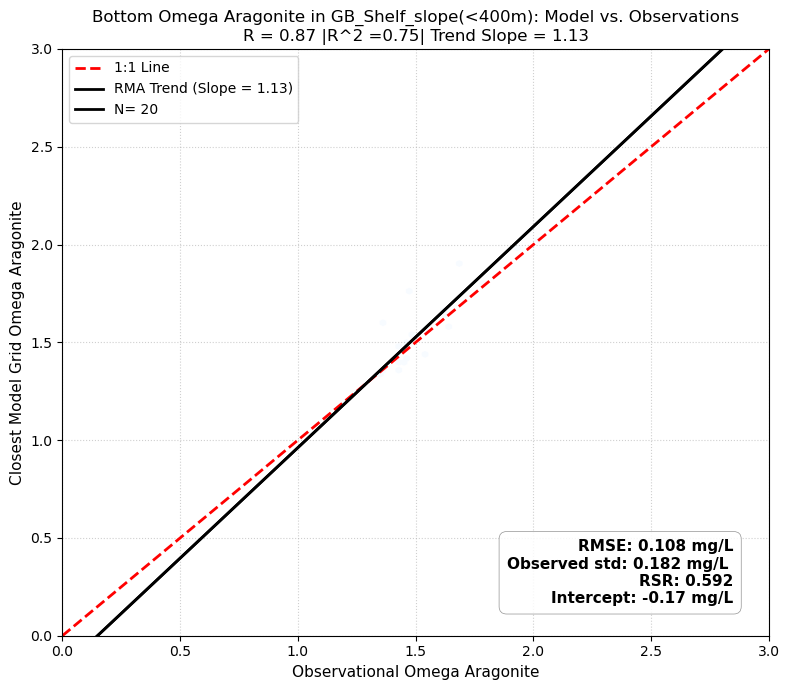


>>> Analyzing Combination: GOM_west_Inner-midshelf(<150m) (N=319)
Mean of delta difference between model 3x3x3 grid data and observational data in GOM_west_Inner-midshelf(<150m) is: 0.0889
Mean of delta difference between model exact grid data and observational data in GOM_west_Inner-midshelf(<150m) is: 0.1144
Global RMSE (3x3x3 grid vs obs) between model and observations in GOM_west_Inner-midshelf(<150m) is: 0.1986
Global RMSE (Exact point vs Obs) between model and observations in GOM_west_Inner-midshelf(<150m) is: 0.2549
-> Calculated using 319 valid exact points in GOM_west_Inner-midshelf(<150m) (out of 319 total pairs).
Calculated Observational Mean: 1.3848
Calculated Model Global Mean: 1.5164
Calculated Global Std Dev: 0.1730
Model grid overestimates the data 67.40 percent of the time
Model grid underestimates the data 32.60 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.1520
When underestimating, the average deficit aragonite (Ω) is: -0.0417
Real

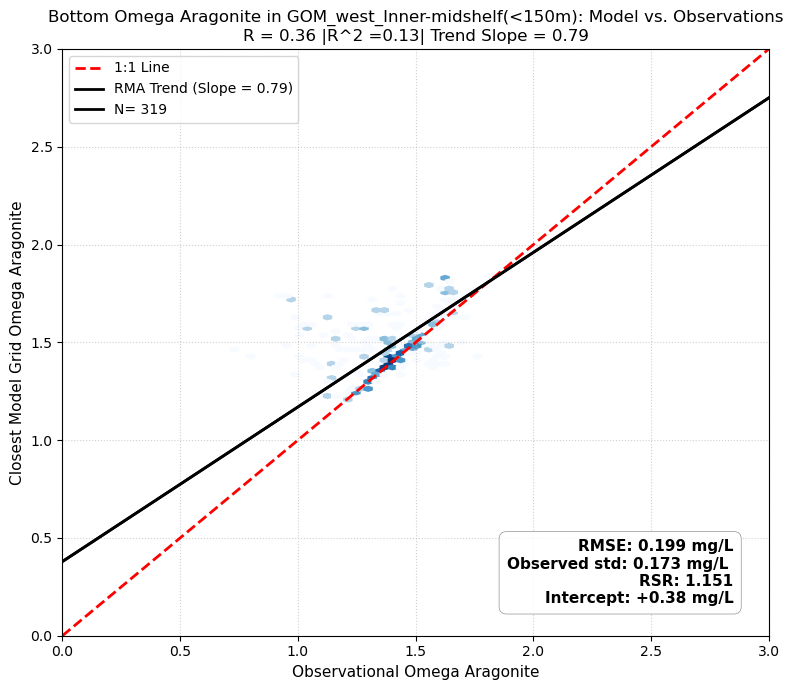


>>> Analyzing Combination: GOM_west_Shelf_slope(<400m) (N=299)
Mean of delta difference between model 3x3x3 grid data and observational data in GOM_west_Shelf_slope(<400m) is: 0.1569
Mean of delta difference between model exact grid data and observational data in GOM_west_Shelf_slope(<400m) is: 0.1769
Global RMSE (3x3x3 grid vs obs) between model and observations in GOM_west_Shelf_slope(<400m) is: 0.2108
Global RMSE (Exact point vs Obs) between model and observations in GOM_west_Shelf_slope(<400m) is: 0.2282
-> Calculated using 299 valid exact points in GOM_west_Shelf_slope(<400m) (out of 299 total pairs).
Calculated Observational Mean: 1.3323
Calculated Model Global Mean: 1.5102
Calculated Global Std Dev: 0.0738
Model grid overestimates the data 90.64 percent of the time
Model grid underestimates the data 9.36 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.1781
When underestimating, the average deficit aragonite (Ω) is: -0.0485
Real-World Observationa

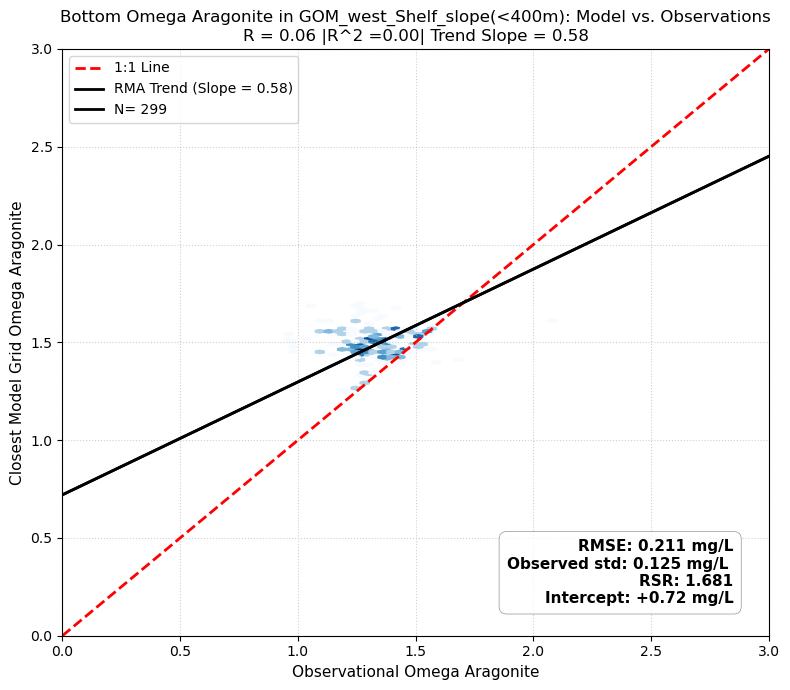


>>> Analyzing Combination: GOM_east_Inner-midshelf(<150m) (N=180)
Mean of delta difference between model 3x3x3 grid data and observational data in GOM_east_Inner-midshelf(<150m) is: 0.1374
Mean of delta difference between model exact grid data and observational data in GOM_east_Inner-midshelf(<150m) is: 0.1649
Global RMSE (3x3x3 grid vs obs) between model and observations in GOM_east_Inner-midshelf(<150m) is: 0.2217
Global RMSE (Exact point vs Obs) between model and observations in GOM_east_Inner-midshelf(<150m) is: 0.2691
-> Calculated using 180 valid exact points in GOM_east_Inner-midshelf(<150m) (out of 180 total pairs).
Calculated Observational Mean: 1.4858
Calculated Model Global Mean: 1.6567
Calculated Global Std Dev: 0.1732
Model grid overestimates the data 82.22 percent of the time
Model grid underestimates the data 17.78 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.1790
When underestimating, the average deficit aragonite (Ω) is: -0.0552
Real

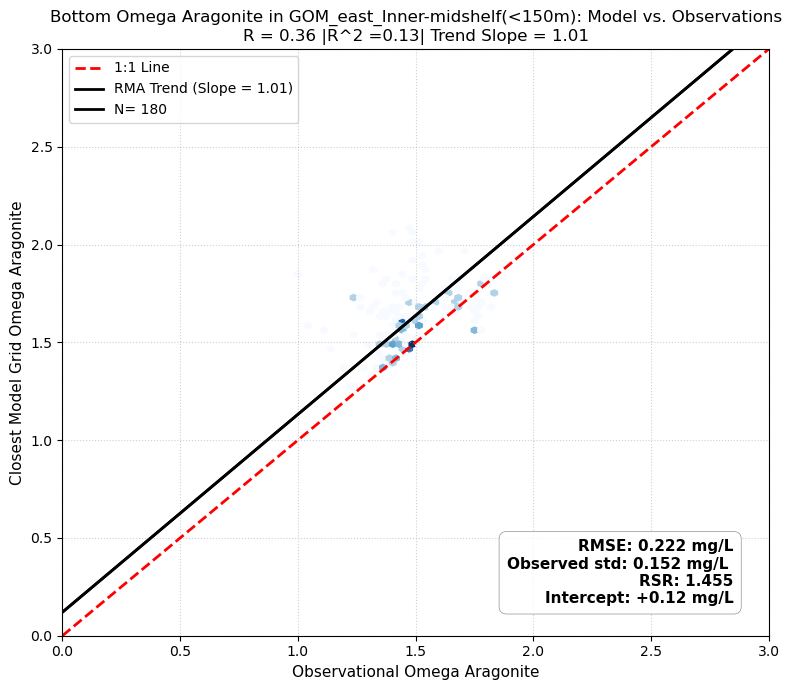


>>> Analyzing Combination: GOM_east_Shelf_slope(<400m) (N=473)
Mean of delta difference between model 3x3x3 grid data and observational data in GOM_east_Shelf_slope(<400m) is: 0.1711
Mean of delta difference between model exact grid data and observational data in GOM_east_Shelf_slope(<400m) is: 0.1907
Global RMSE (3x3x3 grid vs obs) between model and observations in GOM_east_Shelf_slope(<400m) is: 0.2273
Global RMSE (Exact point vs Obs) between model and observations in GOM_east_Shelf_slope(<400m) is: 0.2504
-> Calculated using 473 valid exact points in GOM_east_Shelf_slope(<400m) (out of 473 total pairs).
Calculated Observational Mean: 1.4664
Calculated Model Global Mean: 1.6583
Calculated Global Std Dev: 0.0898
Model grid overestimates the data 90.91 percent of the time
Model grid underestimates the data 9.09 percent of the time
When overestimating, the average excess aragonite (Ω) is: 0.2001
When underestimating, the average deficit aragonite (Ω) is: -0.1186
Real-World Observationa

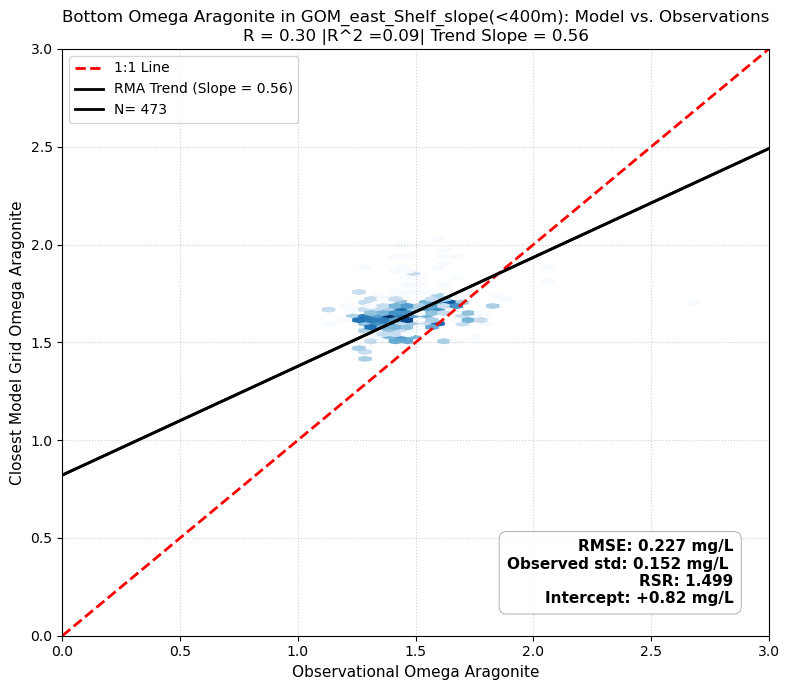


[SUCCESS] Matrix compiled. All cross-statistics successfully exported to: C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Processed_Data\comparison\complete\OA_spatiotemporal_summary2.csv


In [35]:
# 1. Load your 3x3x3 grid comparison CSV data
csv_path = r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Processed_Data\comparison\complete\OA_MOM6_3x3x3_comparison_classified.csv"
df = pd.read_csv(csv_path)

# Convert time column to datetime 
df['matched_time'] = pd.to_datetime(df['matched_time'])
    
# 2. Convert DataFrame into a GeoDataFrame (Points)
gdf_points = gpd.GeoDataFrame(
    df, 
    geometry=gpd.points_from_xy(df['matched_lon'], df['matched_lat']),
    crs="epsg:4326"
)

# 3. Load Bathymetry grid file & sample depths using closest-neighbor lookup
bathymetry_path = r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Bathymetry\MOM6_hindcast_ocean_static_deptho.nc"
ds = xr.open_dataset(bathymetry_path)

lon_da = xr.DataArray(gdf_points['matched_lon'].values, dims="point")
lat_da = xr.DataArray(gdf_points['matched_lat'].values, dims="point")
sampled_depths = ds['deptho'].sel(lon=lon_da, lat=lat_da, method='nearest').values

# Attach calculated depths straight onto the point rows
gdf_points['model_deptho'] = sampled_depths


gdf_points['depth_bin'] = gdf_points['model_deptho'].map(get_depth_bin)

# 4. Load the 5-region Northeast Shelf shapefile & map the names
shapefile_url = 'https://github.com/hsynan/READ-EDAB-Synan_hydrographic_climatologies/raw/refs/heads/main/data/shapefiles/NES_5REGIONS.zip'
gdf_shapes = gpd.read_file(shapefile_url)

region_names = {
    0: "MAB_south",
    1: "MAB_north",
    2: "GB",
    3: "GOM_west",
    4: "GOM_east"
}
# Reset the polygon index to guarantee the 0-4 dictionary keys map correctly
gdf_shapes = gdf_shapes.reset_index(drop=True)
gdf_shapes['Region_Name'] = gdf_shapes.index.map(region_names)

# Coordinate Reference System (CRS) alignment check / assign to World Geodetic System 84
if gdf_shapes.crs is None:
    gdf_shapes.set_crs("epsg:4326", inplace=True)

if gdf_shapes.crs != gdf_points.crs:
    gdf_shapes = gdf_shapes.to_crs(gdf_points.crs)

# 5. Spatial Join to attach Region Names to your prepared points
analyzable_gdf = gpd.sjoin(
    gdf_points, 
    gdf_shapes[['geometry', 'Region_Name']], 
    how='left', 
    predicate='intersects'
)

# Drop the temporary index column added automatically by GeoPandas
if 'index_right' in analyzable_gdf.columns:
    analyzable_gdf = analyzable_gdf.drop(columns=['index_right'])

# Quick verification check to prove both attributes exist side-by-side
print("\n--- Processed Dataset Verification ---")
print(analyzable_gdf[['matched_lat', 'matched_lon', 'Region_Name', 'model_deptho', 'depth_bin']].head(10))
#analyzable_gdf.to_csv(r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Processed_Data\comparison\complete\ECOMON_MOM6_3x3x3_comparison_complete.csv")
# 6. Execute full spatiotemporal summary function
output_csv = r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Processed_Data\comparison\complete\OA_spatiotemporal_summary2.csv"
analyze_spatiotemporal_data(analyzable_gdf, output_csv)

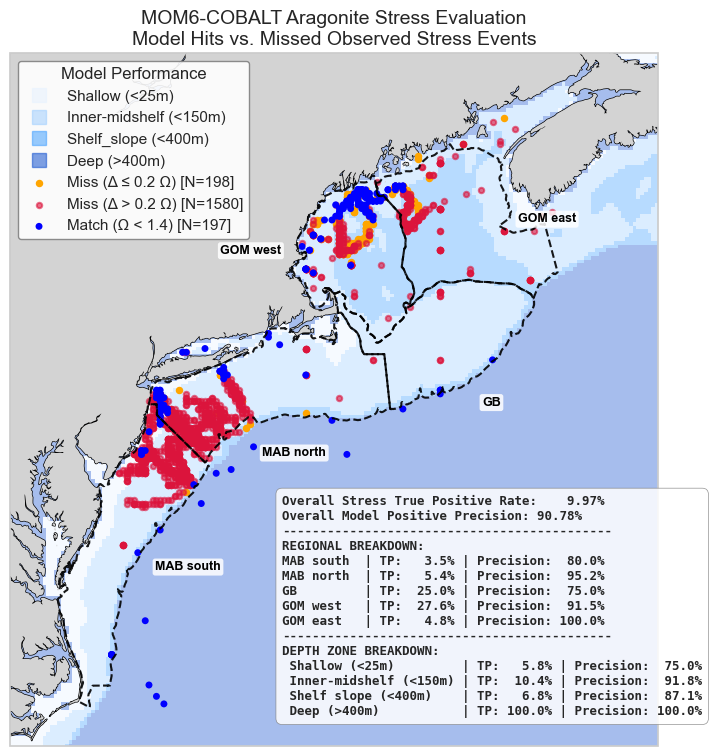

In [9]:
import numpy as np
import cartopy.crs as ccrs          # ccrs handles projections
import cartopy.feature as cfeature  # cfeature handles land, ocean, coastlines
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import pandas as pd
import geopandas as gpd
import xarray as xr
from shapely.ops import unary_union

def map_stress_advanced_evaluation(csv_file, bathymetry_nc_path, title):
    # 1. Load data and geospatial shapes
    final = pd.read_csv(csv_file)
    
    shapefile = gpd.read_file('https://github.com/hsynan/READ-EDAB-Synan_hydrographic_climatologies/raw/refs/heads/main/data/shapefiles/NES_5REGIONS.zip')
    if shapefile.crs is None:
        shapefile.set_crs("epsg:4326", inplace=True)
    elif shapefile.crs != "epsg:4326":
        shapefile = shapefile.to_crs("epsg:4326")

    ds_bathym = xr.open_dataset(bathymetry_nc_path)
    
    # 2. Crop Bathymetry Grid to Map Extent
    lon_var = 'lonh' if 'lonh' in ds_bathym.variables else ('lon' if 'lon' in ds_bathym.variables else 'xh')
    lat_var = 'lath' if 'lath' in ds_bathym.variables else ('lat' if 'lat' in ds_bathym.variables else 'yh')
    ds_bathym = ds_bathym.sel({lon_var: slice(-78, -62), lat_var: slice(34, 47)})

    # 3. CONVERT CONTINUOUS BATHYMETRY INTO FOUR DISCRETE BINS
    depth_data = ds_bathym['deptho'].values
    condlist = [
        depth_data < 25,
        (depth_data >= 25) & (depth_data < 150),
        (depth_data >= 150) & (depth_data < 400),
        depth_data >= 400
    ]
    choicelist = [0, 1, 2, 3]
    binned_depth = np.select(condlist, choicelist, default=3)

    # 4. CATEGORIZE ERROR POINTS FOR ACTUAL STRESSED OBSERVATIONS (NUMERIC LOGIC)
    stressed_obs = final[final['saturated_aragonite'] < 1.4].copy()
    stressed_mod = final[final['closest_model_val'] < 1.4].copy()

    obs_is_stressed = final['saturated_aragonite'] < 1.4
    mod_is_stressed = final['closest_model_val'] < 1.4
    
    if len(stressed_obs) > 0:
        status_matches = (obs_is_stressed & mod_is_stressed).sum()
        status_misses = (obs_is_stressed & ~mod_is_stressed).sum()
        
        match_rate = (status_matches / max(len(stressed_obs), 1)) * 100
        match_precision = (status_matches / max(len(stressed_mod), 1)) * 100
        false_positive = (mod_is_stressed & ~obs_is_stressed).sum()
        false_negative = (obs_is_stressed & ~mod_is_stressed).sum()

    # Calculate absolute error for misses based on delta_difference_grid
    stressed_obs['abs_error'] = stressed_obs['delta_difference_grid'].abs()

    # Split points based on pure numeric criteria:
    # Match = Obs stressed (<1.4) AND Model stressed (<1.4)
    # Miss = Obs stressed (<1.4) BUT Model not stressed (>=1.4)
    matches = stressed_obs[stressed_obs['closest_model_val'] < 1.4]
    misses = stressed_obs[stressed_obs['closest_model_val'] >= 1.4]
    
    # Errors are now based on actual Omega units (e.g., threshold error delta)
    miss_low_error = misses[misses['abs_error'] <= 0.2]
    miss_high_error = misses[misses['abs_error'] > 0.2]

    # 5. SETUP FIGURE & BASES
    fig = plt.figure(figsize=(15, 9))
    map_projection = ccrs.PlateCarree()
    ax = plt.axes(projection=map_projection)

    # 6. PLOT DISCRETE BATHYMETRY GRID BACKGROUND
    cmap_depth = mcolors.ListedColormap(['#e6f2ff', '#99ccff', '#3399ff', '#0044cc'])
    
    bathym_mesh = ax.pcolormesh(
        ds_bathym[lon_var], ds_bathym[lat_var], binned_depth,
        cmap=cmap_depth, 
        shading='auto',
        alpha=0.35,          
        transform=map_projection,
        zorder=1
    )
    bathym_mesh.set_clip_path(ax.patch)

    # Custom legend for Discrete Depth Zones
    depth_labels = ['Shallow (<25m)', 'Inner-midshelf (<150m)', 'Shelf_slope (<400m)', 'Deep (>400m)']
    patches = [plt.plot([],[], marker="s", ms=10, ls="", color=cmap_depth(i), alpha=0.5, label=depth_labels[i])[0] for i in range(4)]
    depth_legend = ax.legend(handles=patches, loc='lower left', title="Bathymetry Zones", fontsize=10, framealpha=0.9)

    # 7. PLOT DYNAMIC THREE-TIER POINT METRICS
    sc_miss_low = ax.scatter(
        miss_low_error['matched_lon'].astype(float), miss_low_error['matched_lat'].astype(float),
        color='orange', marker='o', s=15, linewidths=1.5,
        label=f"Miss (\u0394 \u2264 0.2 \u03a9) [N={len(miss_low_error)}]",
        transform=map_projection, zorder=5
    )
    
    sc_miss_high = ax.scatter(
        miss_high_error['matched_lon'].astype(float), miss_high_error['matched_lat'].astype(float),
        color='crimson', marker='o', alpha=0.6, s=15, linewidths=1.5,
        label=f"Miss (\u0394 > 0.2 \u03a9) [N={len(miss_high_error)}]",
        transform=map_projection, zorder=6
    )

    sc_match = ax.scatter(
        matches['matched_lon'].astype(float), matches['matched_lat'].astype(float),
        color='blue', marker='o', s=25, edgecolors='none', linewidths=0.5,
        label=f"Match (\u03a9 < 1.4) [N={len(matches)}]",
        transform=map_projection, zorder=7
    )

    # Add Point Category Legend
    ax.legend(loc='upper left', title="Model Performance", fontsize=11, framealpha=0.9, facecolor='white', edgecolor='gray')

    # 8. OVERLAY: Regional Shapefile Boundaries
    shapefile.geometry.boundary.plot(
        ax=ax, color='black', linewidth=1.5, linestyle='--', alpha=0.9,
        transform=map_projection, zorder=10
    )

    region_names = {0: "MAB_south", 1: "MAB_north", 2: "GB", 3: "GOM_west", 4: "GOM_east"}

    region_offsets = {
        "MAB_south":  {"lon": +1.4, "lat":  -0.4}, 
        "MAB_north":  {"lon":  0.4, "lat": -1.1}, 
        "GB":         {"lon":  1,   "lat": -1.1}, 
        "GOM_west":   {"lon": -2.3, "lat":  0.1}, 
        "GOM_east":   {"lon":  1.8, "lat":  0.1}  
    }

    region_script = {
        "MAB_south":  "MAB south", 
        "MAB_north":  "MAB north", 
        "GB":         "GB", 
        "GOM_west":   "GOM west", 
        "GOM_east":   "GOM east"  
    }

    for idx, row in shapefile.iterrows():
        name = region_names.get(idx, f"Region {region_names}")
        #display_text = name

        raw_name = region_names.get(idx, f"{idx}") 
        
        # Simply replace the underscore with a space
        display_text = raw_name.replace('_', ' ')
        
        centroid = row.geometry.centroid
        lon_pos = centroid.x
        lat_pos = centroid.y
        
        if name in region_offsets:
            lon_pos += region_offsets[name]["lon"]
            lat_pos += region_offsets[name]["lat"]
        
        ax.text(
            lon_pos, lat_pos, display_text, 
            color='black', fontsize=9, fontweight='bold',
            ha='center', va='center', transform=map_projection,
            bbox=dict(facecolor='white', alpha=0.85, edgecolor='none', linewidth=0.5, boxstyle='round,pad=0.2'),
            zorder=11
        )

    # 9. Map framing assets
    ax.add_feature(cfeature.COASTLINE, linewidth=1)
    ax.add_feature(cfeature.LAND, zorder=2, facecolor='lightgrey')
    ax.set_extent([-77, -63, 34.5, 46], crs=map_projection)
    ax.set_title(title, fontsize=14)

    # 10. Performance Metric Display Block (Updated with numeric true positives)
    total_obs_stress = len(stressed_obs)
    total_mod_stress = len(stressed_mod)
    
    # True Positives: Model correctly predicted stress (<1.4) where observed stress occurred
    true_positives = (stressed_mod['saturated_aragonite'] < 1.4).sum()
    
    global_recall = (true_positives / total_obs_stress) * 100 if total_obs_stress > 0 else 0
    global_precision = (true_positives / total_mod_stress) * 100 if total_mod_stress > 0 else 0
    
    # Regional Grouping
    reg_obs_totals = stressed_obs.groupby('region').size()
    reg_mod_totals = stressed_mod.groupby('region').size()
    regional_tps = stressed_mod[stressed_mod['saturated_aragonite'] < 1.4].groupby('region').size()
    
    # Depth Grouping
    # Properly grouping inputs by the 'depth_bin' column instead of reusing regional ones
    depth_obs_totals = stressed_obs.groupby('depth_bin').size()
    depth_mod_totals = stressed_mod.groupby('depth_bin').size()
    depth_tps = stressed_mod[stressed_mod['saturated_aragonite'] < 1.4].groupby('depth_bin').size()
    text_lines = [
        f"Overall Stress True Positive Rate:    {global_recall:.2f}%",
        f"Overall Model Positive Precision: {global_precision:.2f}%",
        "--------------------------------------------",
        "REGIONAL BREAKDOWN:"
    ]


    
    target_regions = ["MAB_south", "MAB_north", "GB", "GOM_west", "GOM_east"]
    for r in target_regions:
        r_obs = reg_obs_totals.get(r, 0)
        r_mod = reg_mod_totals.get(r, 0)
        r_tp = regional_tps.get(r, 0)
        
        r_recall = (r_tp / r_obs) * 100 if r_obs > 0 else 0.0
        r_precision = (r_tp / r_mod) * 100 if r_mod > 0 else 0.0
        
        text_lines.append(f"{region_script.get(r, r):<10} | TP: {r_recall:5.1f}% | Precision: {r_precision:5.1f}%")
    text_lines.append("--------------------------------------------")
    text_lines.append("DEPTH ZONE BREAKDOWN:")

    # Match exact string representations found in your 'depth_bin' column
    target_depths = ['Shallow (<25m)', 'Inner-midshelf (<150m)', 'Shelf_slope (<400m)', 'Deep (>400m)']
    depth_script = {
        'Shallow (<25m)': "Shallow (<25m)", 
        'Inner-midshelf (<150m)': 'Inner-midshelf (<150m)', 
        'Shelf_slope (<400m)': 'Shelf slope (<400m)', 
        'Deep (>400m)': 'Deep (>400m)'
    }
    for d in target_depths:
        d_obs = depth_obs_totals.get(d, 0)
        d_mod = depth_mod_totals.get(d, 0)
        d_tp = depth_tps.get(d, 0)
        
        d_recall = (d_tp / d_obs) * 100 if d_obs > 0 else 0.0
        d_precision = (d_tp / d_mod) * 100 if d_mod > 0 else 0.0
        
        text_lines.append(f" {depth_script.get(d, d):<22} | TP: {d_recall:5.1f}% | Precision: {d_precision:5.1f}%")
        
    text_str = "\n".join(text_lines)    
    text_str = "\n".join(text_lines)
    
    box_style = dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.85, edgecolor='gray', linewidth=0.5)
    ax.text(
        0.42, 0.04, text_str, transform=ax.transAxes, 
        fontfamily='monospace', fontsize=9, fontweight='bold', va='bottom', ha='left',
        bbox=box_style, zorder=105 
    )

    plt.show()

# Execution handles
csv_path = r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Processed_Data\comparison\complete\OA_MOM6_3x3x3_comparison_classified.csv"
bathymetry_path = r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Bathymetry\MOM6_hindcast_ocean_static_deptho.nc"


map_stress_advanced_evaluation(csv_path, bathymetry_path, 'MOM6-COBALT Aragonite Stress Evaluation\nModel Hits vs. Missed Observed Stress Events')


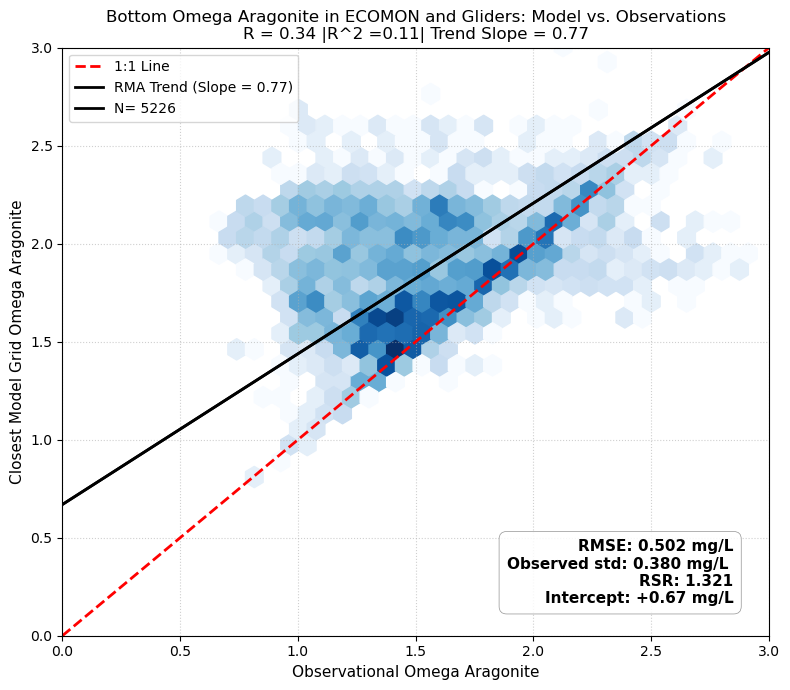

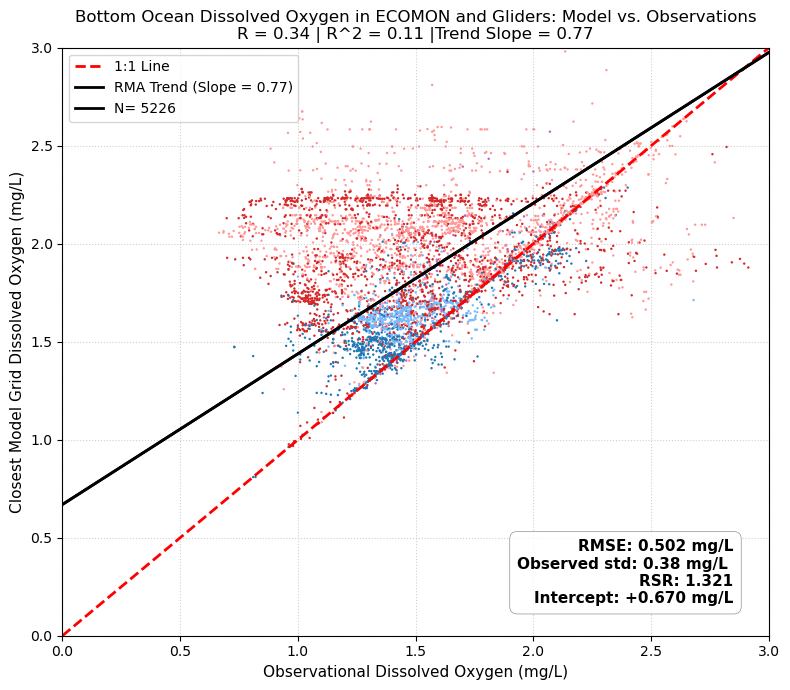

{'slope': 0.7688911399739264, 'r_value': 0.3359123619161504, 'N_samples': 5226}

In [40]:
df=pd.read_csv(csv_path)
hexplot_model_vs_obs_with_trend(df, "ECOMON and Gliders")
plot_model_vs_obs_with_trend(df, "ECOMON and Gliders")

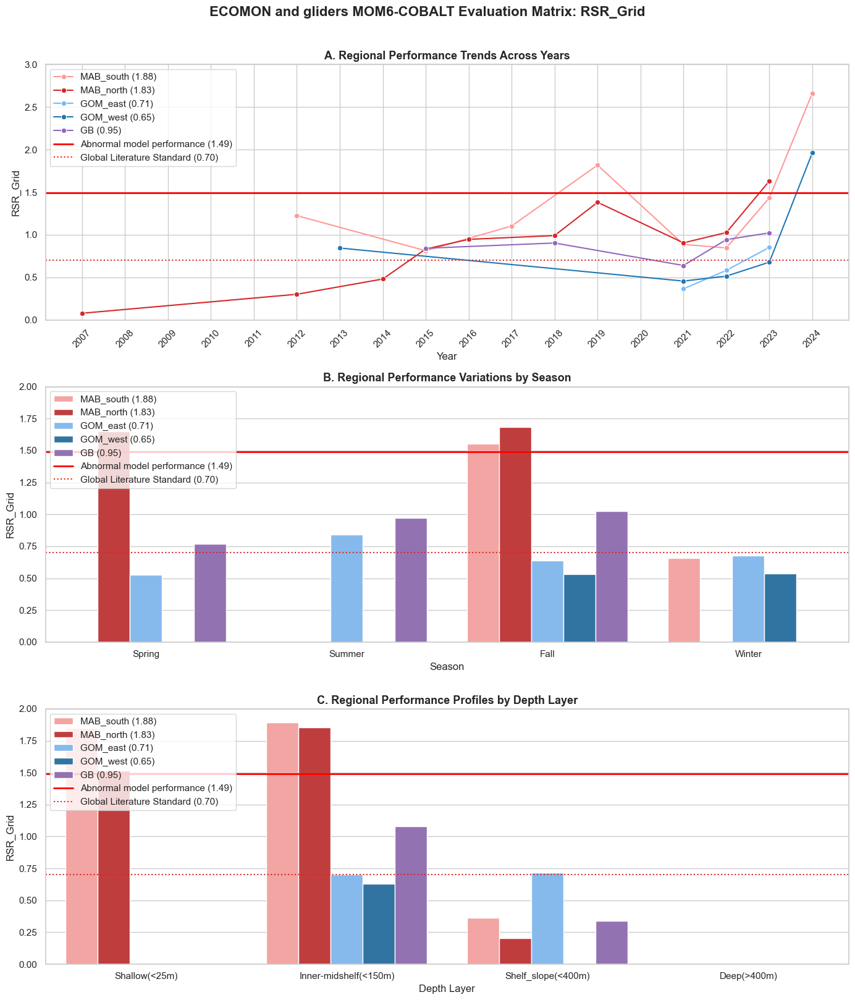

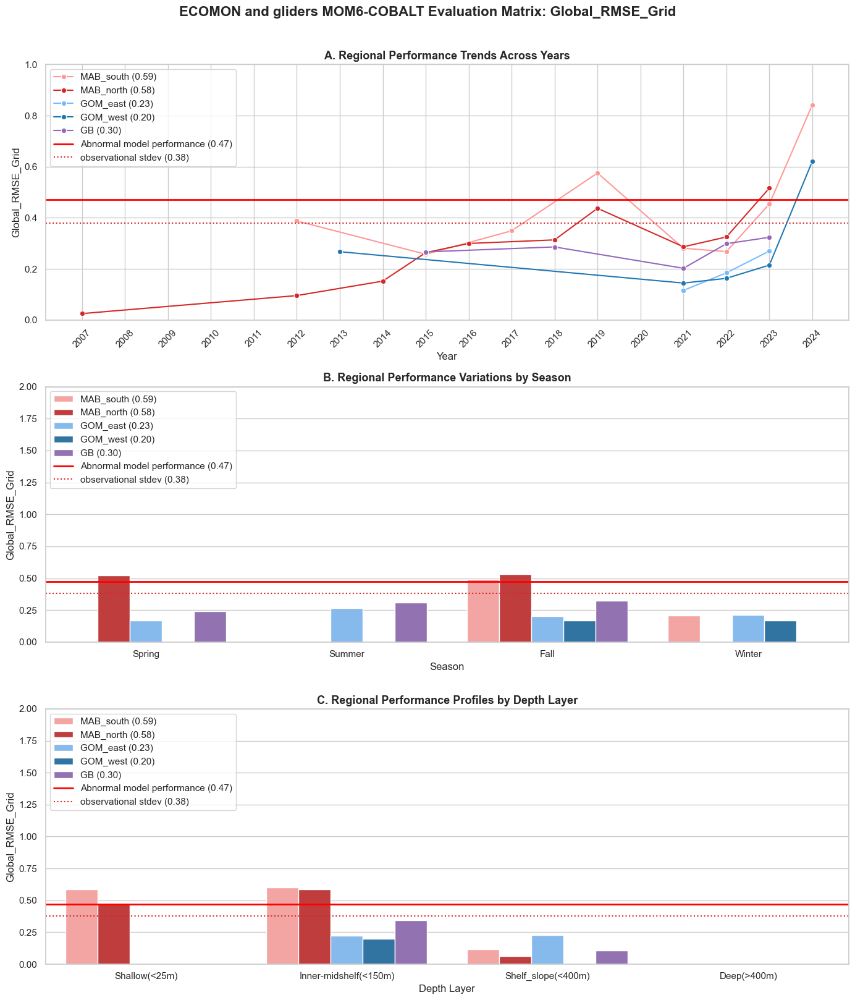

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

def plot_comprehensive_matrix(csv_path, metric_col, title, obs_std=None):
    # 1. Load your compiled spatiotemporal summary matrix
    df = pd.read_csv(csv_path)
    
    # FILTER for statistical significance
    df_clean = df[df['p_val'] < 0.05].copy()
    
    # Calculate your custom dynamic threshold (Approach A) 
    threshold_sample = df_clean[(df_clean['Year'] != 'ALL') & (df_clean['Region'] != 'ALL')]
    mean_rsr = threshold_sample[metric_col].mean()
    std_rsr = threshold_sample[metric_col].std()
    unsatisfactory_threshold = mean_rsr + std_rsr

    region_palette = {
        'MAB_south': '#ff9896',
        'MAB_north': '#d62728',
        'GOM_east':'#75bbfd',
        'GOM_west':'#1f77b4',
        'GB':'#9467bd',
    }

    unique_regions = list(region_palette.keys())

    # Pre-calculate the average RSR for each region to use in the legend later
    baseline_df = df_clean[(df_clean['Year'] == 'ALL') & (df_clean['Season'] == 'ALL') & (df_clean['Depth'] == 'ALL')]
    region_means = baseline_df.groupby('Region')[metric_col].mean().to_dict()

    # Set up styling
    sns.set_theme(style="whitegrid")
    fig, axes = plt.subplots(3, 1, figsize=(14, 16))
    
    # -------------------------------------------------------------
    # PANEL 1: REGION x YEAR (Fixed to disconnect gaps and set ylim to 3)
    # -------------------------------------------------------------
    region_year = df_clean[(df_clean['Year'] != 'ALL') & 
                           (df_clean['Season'] == 'ALL') & 
                           (df_clean['Depth'] == 'ALL') & 
                           (df_clean['Region'] != 'ALL')].copy()
    
    region_year['Year'] = region_year['Year'].astype(int)
    
    # FIX: Pivot and reindex to explicitly insert NaN values for missing year slots
    # This prevents lineplot from drawing straight lines through missing observation intervals
    all_years = np.arange(region_year['Year'].min(), region_year['Year'].max() + 1)
    
    pivoted_ry = region_year.pivot(index='Year', columns='Region', values=metric_col)
    pivoted_ry = pivoted_ry.reindex(all_years) # Inserts NaN rows for unobserved calendar gaps
    
    # Melt it back down to standard long-form structure for Seaborn processing
    region_year_clean = pivoted_ry.reset_index().melt(id_vars='Year', value_name=metric_col)

    sns.lineplot(
        ax=axes[0], data=region_year_clean, x='Year', y=metric_col, hue='Region',
        palette=region_palette, hue_order=unique_regions, marker='o'
    )
    axes[0].set_xticks(all_years)
    axes[0].set_xticklabels(all_years, rotation=45)
    
    axes[0].set_title('A. Regional Performance Trends Across Years', fontsize=13, fontweight='bold')
    axes[0].set_xlabel('Year')
    axes[0].set_ylabel(metric_col)
    
    # -------------------------------------------------------------
    # PANEL 2: REGION x SEASON 
    # -------------------------------------------------------------
    region_season = df_clean[(df_clean['Year'] == 'ALL') & 
                             (df_clean['Depth'] == 'ALL') & 
                             (df_clean['Season'] != 'ALL') & 
                             (df_clean['Region'] != 'ALL')]
    
    season_order = ['Spring', 'Summer', 'Fall', 'Winter']
    sns.barplot(
        ax=axes[1], data=region_season, x='Season', y=metric_col, hue='Region',
        palette=region_palette, hue_order=unique_regions, order=season_order, errorbar=None
    )
    axes[1].set_title('B. Regional Performance Variations by Season', fontsize=13, fontweight='bold')
    axes[1].set_xlabel('Season')
    axes[1].set_ylabel(metric_col)
    
    # -------------------------------------------------------------
    # PANEL 3: REGION x DEPTH 
    # -------------------------------------------------------------
    region_depth = df_clean[(df_clean['Year'] == 'ALL') & 
                            (df_clean['Season'] == 'ALL') & 
                            (df_clean['Depth'] != 'ALL') & 
                            (df_clean['Region'] != 'ALL')]
    
    depth_order = ['Shallow(<25m)', 'Inner-midshelf(<150m)', 'Shelf_slope(<400m)', 'Deep(>400m)']
    sns.barplot(
        ax=axes[2], data=region_depth, x='Depth', y=metric_col, hue='Region',
        palette=region_palette, hue_order=unique_regions, order=depth_order, errorbar=None
    )
    axes[2].set_title('C. Regional Performance Profiles by Depth Layer', fontsize=13, fontweight='bold')
    axes[2].set_xlabel('Depth Layer')
    axes[2].set_ylabel(metric_col)
    
    # -------------------------------------------------------------
    # ADD BOTH THRESHOLD LINES & POLISH + DYNAMIC LEGEND LABELS
    # -------------------------------------------------------------
    if metric_col=='RSR_Grid':
        for i, ax in enumerate(axes):
            if ax.has_data():
                ax.axhline(unsatisfactory_threshold, color='red', linestyle='-', linewidth=2, 
                        label=f'Abnormal model performance ({unsatisfactory_threshold:.2f})')
                ax.axhline(0.7, color='#d62728', linestyle=':', linewidth=1.5, 
                        label='Global Literature Standard (0.70)')
                
                # Fetch the auto-generated legend handles and text strings
                handles, labels = ax.get_legend_handles_labels()
                
                updated_labels = []
                for label in labels:
                    if label in region_means:
                        updated_labels.append(f"{label} ({region_means[label]:.2f})")
                    else:
                        updated_labels.append(label)
                
                ax.legend(handles, updated_labels, loc='upper left')
                
                # Dynamic Limit logic: Set Panel A to 3, leave Panels B and C to dynamic sizing
                if i == 0:
                    ax.set_ylim(0, 3.0)
                else:
                    ax.set_ylim(0, max(2.0, unsatisfactory_threshold + 0.3))
    if metric_col=='Global_RMSE_Grid' and obs_std is not None:
        for i, ax in enumerate(axes):
            if ax.has_data():
                ax.axhline(unsatisfactory_threshold, color='red', linestyle='-', linewidth=2, 
                        label=f'Abnormal model performance ({unsatisfactory_threshold:.2f})')
                ax.axhline(obs_std, color='#d62728', linestyle=':', linewidth=1.5, 
                        label=f'observational stdev ({obs_std:.2f})')
                
                # Fetch the auto-generated legend handles and text strings
                handles, labels = ax.get_legend_handles_labels()
                
                updated_labels = []
                for label in labels:
                    if label in region_means:
                        updated_labels.append(f"{label} ({region_means[label]:.2f})")
                    else:
                        updated_labels.append(label)
                
                ax.legend(handles, updated_labels, loc='upper left')
                
                # Dynamic Limit logic: Set Panel A to 3, leave Panels B and C to dynamic sizing
                if i == 0:
                    ax.set_ylim(0, 1.0)
                else:
                    ax.set_ylim(0, max(2.0, unsatisfactory_threshold + 0.3))
    plt.suptitle(f"{title} MOM6-COBALT Evaluation Matrix: {metric_col}", fontsize=16, fontweight='bold', y=1.01)
    plt.tight_layout()
    plt.show()
# Run the visualization targeting your final CSV output path
summary_csv_path = r"c:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Processed_Data\comparison\complete\OA_spatiotemporal_summary2.csv"
#plot_comprehensive_matrix(summary_csv_path, 'RSR_Grid','ECOMON and gliders')
plot_comprehensive_matrix(summary_csv_path, 'Global_RMSE_Grid','ECOMON and gliders', obs_std=0.38)

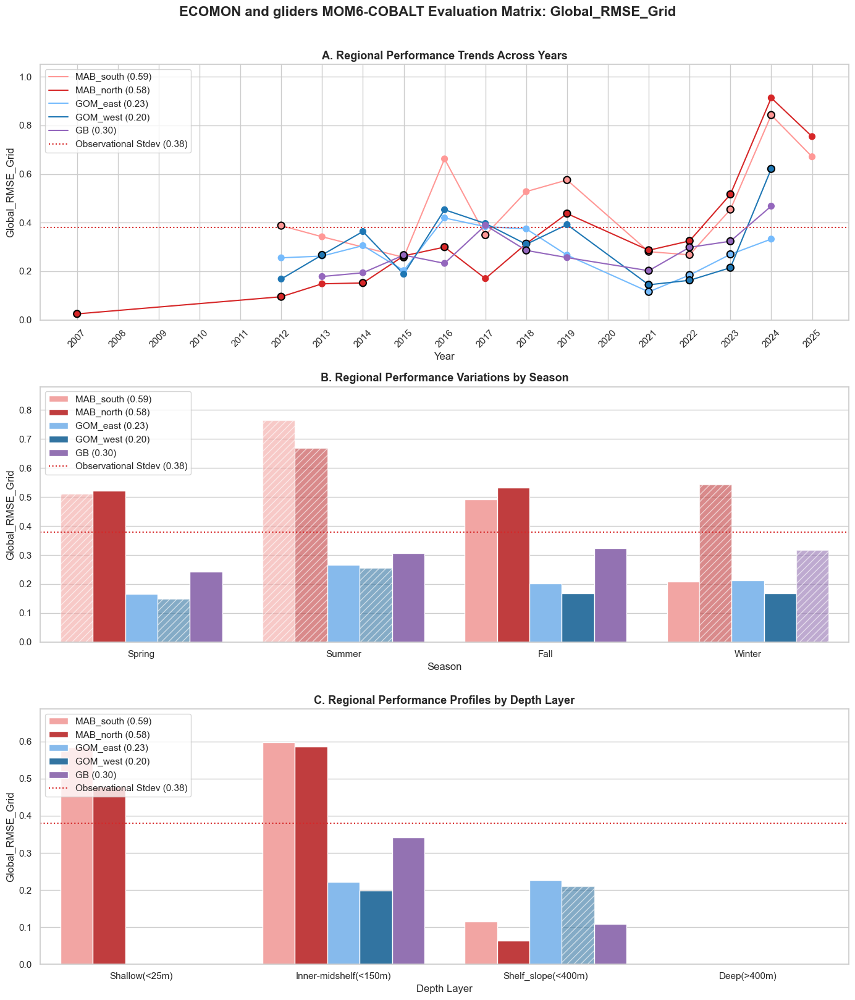

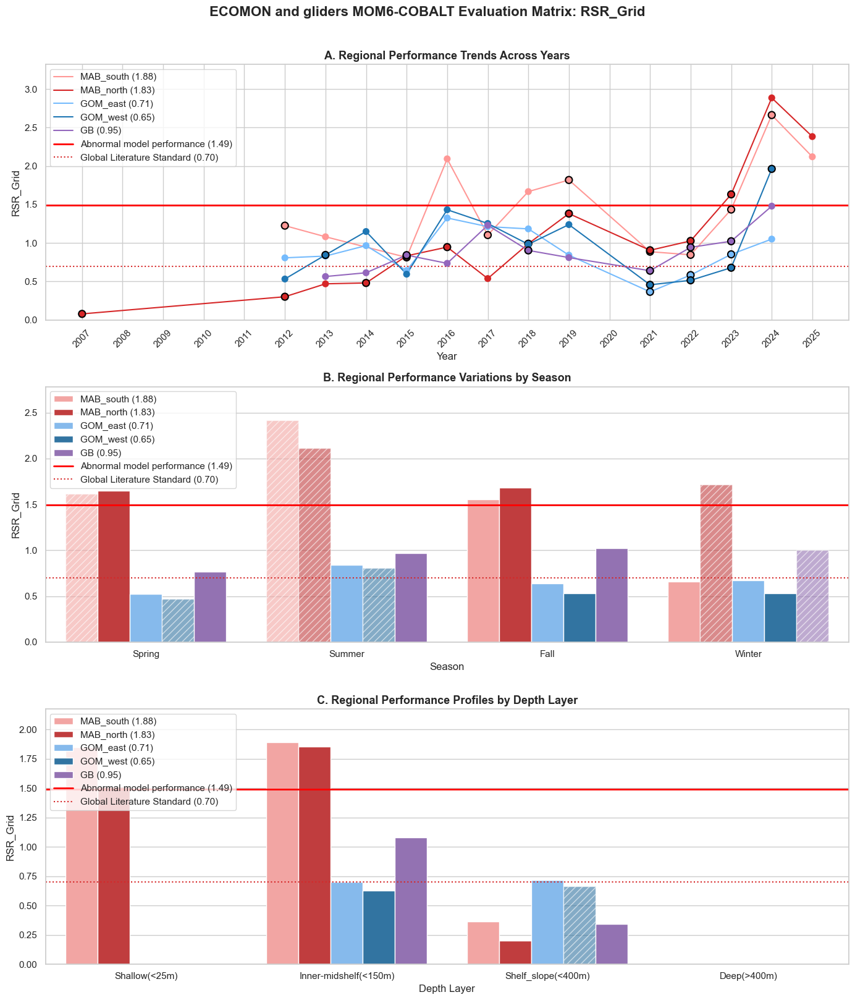

In [10]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

def plot_comprehensive_matrix(csv_path, metric_col, title, obs_std=None):
    # 1. Load your compiled spatiotemporal summary matrix
    df = pd.read_csv(csv_path)

    df_clean = df.copy() 
    
    # Calculate your custom dynamic threshold using significant samples to keep baseline valid
    threshold_sample = df_clean[(df_clean['p_val'] < 0.05) & (df_clean['Year'] != 'ALL') & (df_clean['Region'] != 'ALL')]
    mean_rsr = threshold_sample[metric_col].mean()
    std_rsr = threshold_sample[metric_col].std()
    if metric_col == "RSR_Grid":
        unsatisfactory_threshold = mean_rsr + std_rsr
    else:
        unsatisfactory_threshold = None

    region_palette = {
        'MAB_south': '#ff9896',
        'MAB_north': '#d62728',
        'GOM_east':'#75bbfd',
        'GOM_west':'#1f77b4',
        'GB':'#9467bd',
    }
    unique_regions = list(region_palette.keys())

    # Pre-calculate the average metric for significant baseline rows
    baseline_df = df_clean[(df_clean['p_val'] < 0.05) & (df_clean['Year'] == 'ALL') & (df_clean['Season'] == 'ALL') & (df_clean['Depth'] == 'ALL')]
    region_means = baseline_df.groupby('Region')[metric_col].mean().to_dict()

    # Set up styling
    sns.set_theme(style="whitegrid")
    fig, axes = plt.subplots(3, 1, figsize=(14, 16))
    
    # -------------------------------------------------------------
    # PANEL 1: REGION x YEAR (Outlined vs Unoutlined Markers)
    # -------------------------------------------------------------
    region_year = df_clean[(df_clean['Year'] != 'ALL') & 
                           (df_clean['Season'] == 'ALL') & 
                           (df_clean['Depth'] == 'ALL') & 
                           (df_clean['Region'] != 'ALL')].copy()
    
    region_year['Year'] = region_year['Year'].astype(int)
    
    # Pivot and reindex to explicitly insert NaN values for missing year slots
    all_years = np.arange(region_year['Year'].min(), region_year['Year'].max() + 1)
    pivoted_ry = region_year.pivot(index='Year', columns='Region', values=metric_col)
    pivoted_ry = pivoted_ry.reindex(all_years)
    region_year_clean = pivoted_ry.reset_index().melt(id_vars='Year', value_name=metric_col)

    # Standard continuous lines without standard markers
    sns.lineplot(
        ax=axes[0], data=region_year_clean, x='Year', y=metric_col, hue='Region',
        palette=region_palette, hue_order=unique_regions, marker=None, zorder=2
    )
    
    # Manually overlay scatter dots to control edge outlining dynamically based on p-value
    for reg in unique_regions:
        reg_data = region_year[region_year['Region'] == reg].sort_values('Year')
        if not reg_data.empty:
            # Significant points get a thick black edge; non-significant points get no edge/face-colored edge
            edge_colors = ['black' if p < 0.05 else 'none' for p in reg_data['p_val']]
            line_widths = [1.5 if p < 0.05 else 0.0 for p in reg_data['p_val']]
            
            axes[0].scatter(
                reg_data['Year'], reg_data[metric_col], 
                color=region_palette[reg], s=65, 
                edgecolors=edge_colors, linewidths=line_widths, 
                zorder=4, label='_nolegend_'
            )

    axes[0].set_xticks(all_years)
    axes[0].set_xticklabels(all_years, rotation=45)
    axes[0].set_title('A. Regional Performance Trends Across Years', fontsize=13, fontweight='bold')
    axes[0].set_xlabel('Year')
    axes[0].set_ylabel(metric_col)
    
    # -------------------------------------------------------------
    # PANEL 2: REGION x SEASON (Hatched Bars for Non-Significance)
    # -------------------------------------------------------------
    region_season = df_clean[(df_clean['Year'] == 'ALL') & 
                             (df_clean['Depth'] == 'ALL') & 
                             (df_clean['Season'] != 'ALL') & 
                             (df_clean['Region'] != 'ALL')].copy()
    
    season_order = ['Spring', 'Summer', 'Fall', 'Winter']
    sns.barplot(
        ax=axes[1], data=region_season, x='Season', y=metric_col, hue='Region',
        palette=region_palette, hue_order=unique_regions, order=season_order, errorbar=None
    )
    
    # SAFE HATCHING BY MATCHING TICK LABELS
    for i, region in enumerate(unique_regions):
        if i >= len(axes[1].containers):
            break
        bars = axes[1].containers[i]
        for bar in bars:
            # Look up which season category this bar belongs to based on its x-coordinate
            x_pos = int(round(bar.get_x() + bar.get_width() / 2.0))
            if 0 <= x_pos < len(season_order):
                season = season_order[x_pos]
                row = region_season[(region_season['Region'] == region) & (region_season['Season'] == season)]
                if not row.empty and row['p_val'].values[0] >= 0.05:
                    bar.set_hatch('///')
                    bar.set_alpha(0.6)

    axes[1].set_title('B. Regional Performance Variations by Season', fontsize=13, fontweight='bold')
    axes[1].set_xlabel('Season')
    axes[1].set_ylabel(metric_col)
    
    # -------------------------------------------------------------
    # PANEL 3: REGION x DEPTH (Hatched Bars for Non-Significance)
    # -------------------------------------------------------------
    region_depth = df_clean[(df_clean['Year'] == 'ALL') & 
                            (df_clean['Season'] == 'ALL') & 
                            (df_clean['Depth'] != 'ALL') & 
                            (df_clean['Region'] != 'ALL')].copy()
    
    depth_order = ['Shallow(<25m)', 'Inner-midshelf(<150m)', 'Shelf_slope(<400m)', 'Deep(>400m)']
    sns.barplot(
        ax=axes[2], data=region_depth, x='Depth', y=metric_col, hue='Region',
        palette=region_palette, hue_order=unique_regions, order=depth_order, errorbar=None
    )
    
    # SAFE HATCHING BY MATCHING TICK LABELS (Prevents IndexError on missing depth records)
    for i, region in enumerate(unique_regions):
        if i >= len(axes[2].containers):
            break
        bars = axes[2].containers[i]
        for bar in bars:
            # Look up which depth bin this bar sits over
            x_pos = int(round(bar.get_x() + bar.get_width() / 2.0))
            if 0 <= x_pos < len(depth_order):
                depth = depth_order[x_pos]
                row = region_depth[(region_depth['Region'] == region) & (region_depth['Depth'] == depth)]
                if not row.empty and row['p_val'].values[0] >= 0.05:
                    bar.set_hatch('///')
                    bar.set_alpha(0.6)

    axes[2].set_title('C. Regional Performance Profiles by Depth Layer', fontsize=13, fontweight='bold')
    axes[2].set_xlabel('Depth Layer')
    axes[2].set_ylabel(metric_col)
    
    # -------------------------------------------------------------
    # ADD BOTH THRESHOLD LINES & POLISH + DYNAMIC LEGEND LABELS
    # -------------------------------------------------------------
    for i, ax in enumerate(axes):
        if ax.has_data():
            # 1. Determine the maximum data point plotted in this specific panel
            if i == 0:
                # Panel A includes all records across the years
                max_val = region_year[metric_col].max()
            elif i == 1:
                # Panel B contains the seasonal breakdown
                max_val = region_season[metric_col].max()
            elif i == 2:
                # Panel C contains the depth breakdown
                max_val = region_depth[metric_col].max()
            
            # Fallback handle if max_val is NaN or empty
            if pd.isna(max_val) or max_val is None:
                max_val = 2.0

            # 2. Add threshold lines based on metric type
            if metric_col == 'RSR_Grid':
                ax.axhline(unsatisfactory_threshold, color='red', linestyle='-', linewidth=2, 
                           label=f'Abnormal model performance ({unsatisfactory_threshold:.2f})')
                ax.axhline(0.7, color='#d62728', linestyle=':', linewidth=1.5, 
                           label='Global Literature Standard (0.70)')
                
                # Dynamic Ceiling: Ensure the limit covers the max data point AND thresholds
                ceiling = max(max_val, unsatisfactory_threshold, 0.7)
                ax.set_ylim(0, ceiling * 1.15) # Add a 15% headroom padding above the absolute max
                    
            elif metric_col == 'Global_RMSE_Grid' and obs_std is not None:
    
                ax.axhline(obs_std, color='#d62728', linestyle=':', linewidth=1.5, 
                           label=f'Observational Stdev ({obs_std:.2f})')
                
                # Dynamic Ceiling for RMSE
                ceiling = max(max_val, obs_std)
                ax.set_ylim(0, ceiling * 1.15) # Add a 15% headroom padding above the absolute max
            
            # Reconstruct legend cleanly
            handles, labels = ax.get_legend_handles_labels()
            updated_labels = []
            for label in labels:
                if label in region_means:
                    updated_labels.append(f"{label} ({region_means[label]:.2f})")
                else:
                    updated_labels.append(label)
            
            ax.legend(handles, updated_labels, loc='upper left')
        
    plt.suptitle(f"{title} MOM6-COBALT Evaluation Matrix: {metric_col}", fontsize=16, fontweight='bold', y=1.01)
    plt.tight_layout()
    plt.show()

summary_csv_path = r"c:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Processed_Data\comparison\complete\OA_spatiotemporal_summary2.csv"
#plot_comprehensive_matrix(summary_csv_path, 'RSR_Grid','ECOMON and gliders')
plot_comprehensive_matrix(summary_csv_path, 'Global_RMSE_Grid','ECOMON and gliders', obs_std=0.38)
plot_comprehensive_matrix(summary_csv_path, 'RSR_Grid','ECOMON and gliders', obs_std=None)

C:\Users\edmund.gable\AppData\Local\Temp\ipykernel_20224\2785702995.py:31: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  base_cmap = plt.cm.get_cmap('viridis')


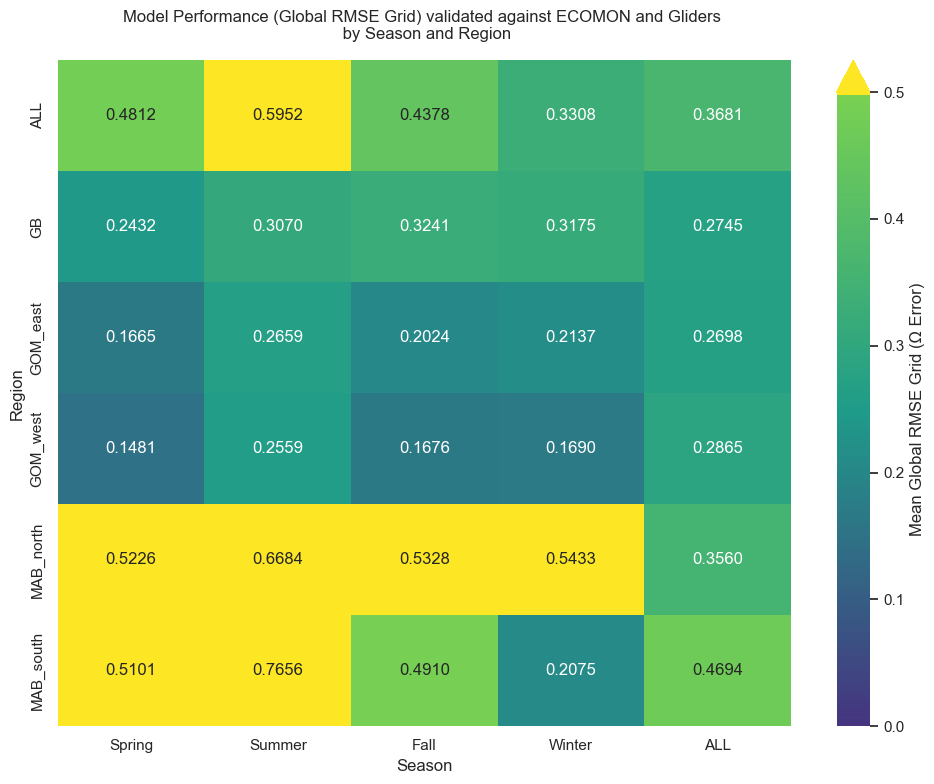

C:\Users\edmund.gable\AppData\Local\Temp\ipykernel_20224\2785702995.py:31: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  base_cmap = plt.cm.get_cmap('viridis')


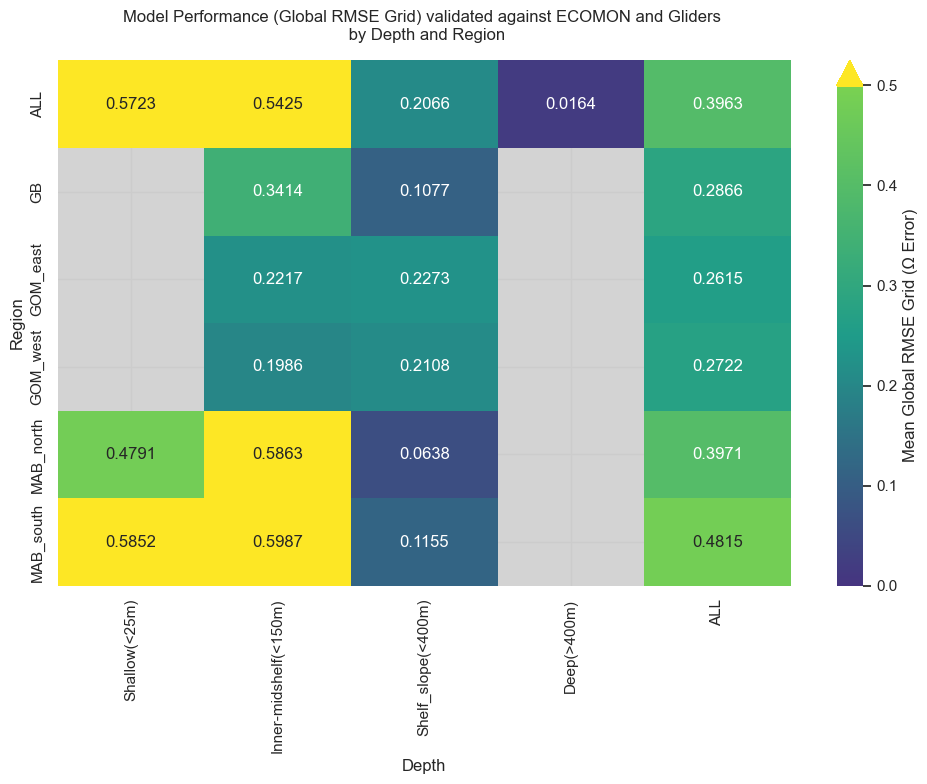

C:\Users\edmund.gable\AppData\Local\Temp\ipykernel_20224\2785702995.py:31: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  base_cmap = plt.cm.get_cmap('viridis')


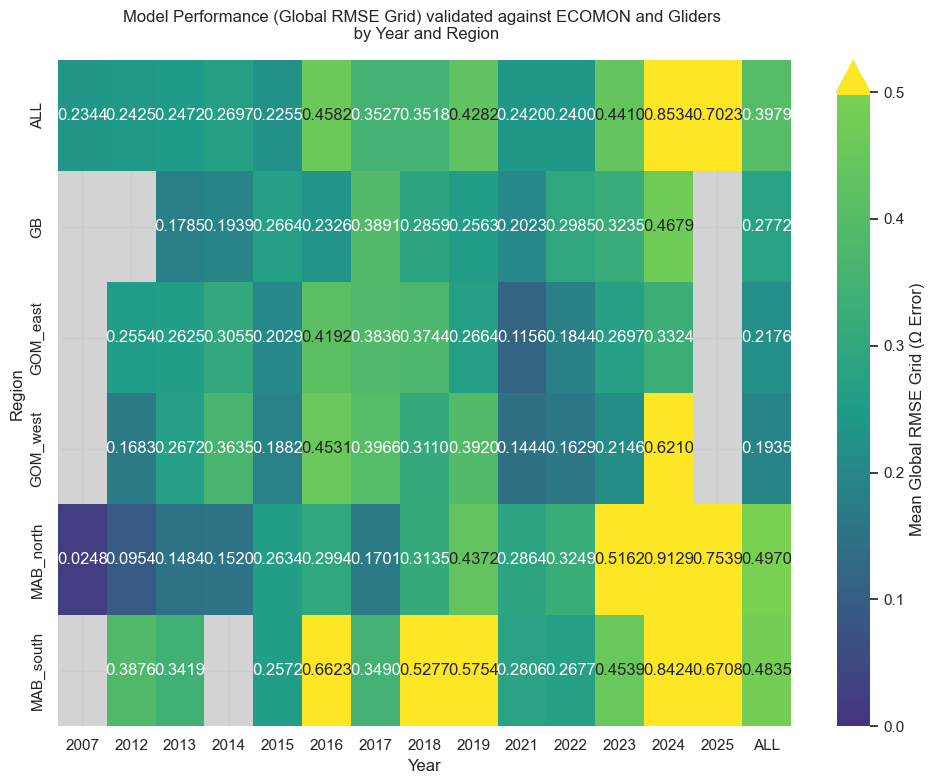

In [80]:
plot_df=pd.read_csv(r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Processed_Data\comparison\complete\OA_spatiotemporal_summary2.csv")

heatmap(plot_df, 'Region', 'Season', 'Global_RMSE_Grid', "ECOMON and Gliders")
heatmap(plot_df, 'Region', 'Depth', 'Global_RMSE_Grid', "ECOMON and Gliders")
heatmap(plot_df, 'Region', 'Year', 'Global_RMSE_Grid', "ECOMON and Gliders")

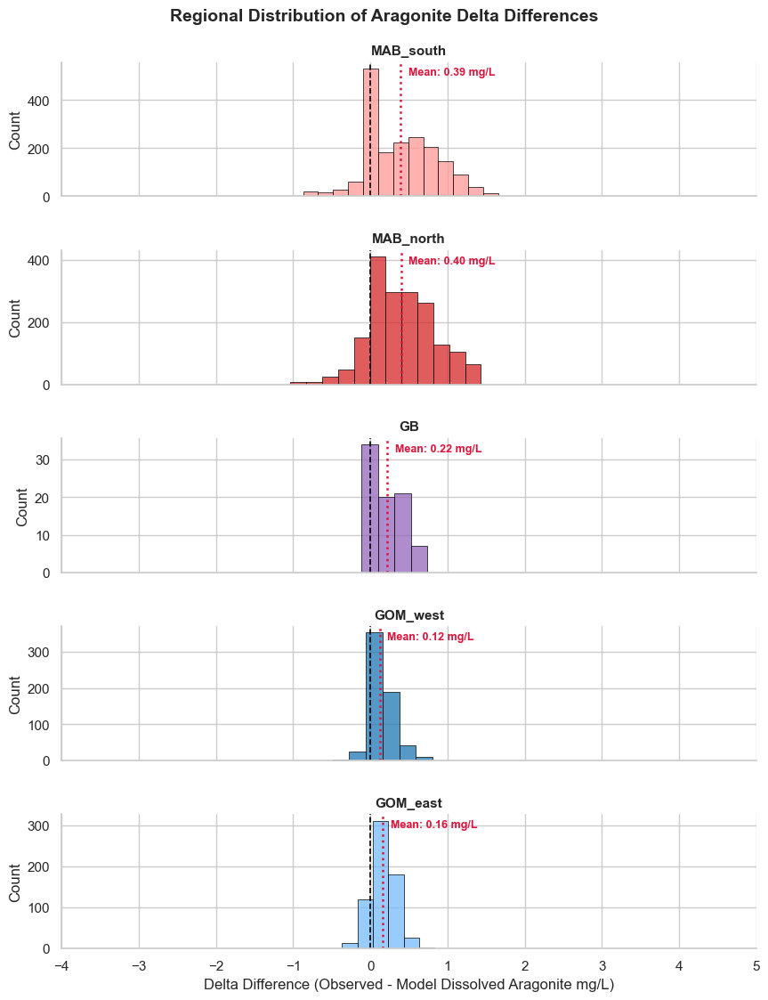

In [60]:
import matplotlib.pyplot as plt
import seaborn as sns


def plot_regional_delta_histograms(csv_file):
    # 1. Load data
    df = pd.read_csv(csv_file)

    # 2. Filter data to ensure we drop missing values
    df_clean = df.dropna(subset=["delta_difference_grid", "region"])

    # 3. Setup styling
    sns.set_theme(style="whitegrid")

    # Define a consistent 5-panel layout (one for each region)
    # Using row or col layout depending on preference; a single column stack works well for comparison
    g = sns.FacetGrid(
        df_clean,
        row="region",
        row_order=["MAB_south", "MAB_north", "GB", "GOM_west", "GOM_east"],
        hue="region",
        palette={
            "MAB_south": "#ff9896",
            "MAB_north": "#d62728",
            "GOM_east": "#75bbfd",
            "GOM_west": "#1f77b4",
            "GB": "#9467bd",
        },
        aspect=4,
        height=2.2,
        sharey=False,  # Allows each region's count to scale dynamically
    )

    # 4. Map the histogram
    # binwidth=0.4 creates the exact bin sizing increment you requested
    g.map_dataframe(
        sns.histplot,
        x="delta_difference_grid",
        binwidth=0.2,
        edgecolor="black",
        linewidth=0.5,
        alpha=0.75,
    )
    g.set(xlim=(-4, 5))
    # 5. Add a reference line at 0 (Perfect Model-Obs Agreement)
    g.refline(x=0, color="black", linestyle="--", linewidth=1.2)

     # 6. Dynamically add Mean Lines, Mean Text, and Clean Titles
    for bin_name, ax in g.axes_dict.items():
        # Filter data for the specific depth bin to calculate its mean
        bin_data = df_clean[df_clean["region"] == bin_name]["delta_difference_grid"]
        
        if not bin_data.empty:
            mean_val = bin_data.mean()
            
            # Draw the red dotted average line
            ax.axvline(x=mean_val, color="crimson", linestyle=":", linewidth=1.8, label=f"Mean: {mean_val:.2f}")
            
            # Add text label for the mean near the top of each plot
            # transform=ax.get_xaxis_transform() places the y-coordinate relative to the top of the axis (0.90 = 90% up)
            ax.text(
                mean_val + 0.1, 0.90, f"Mean: {mean_val:.2f} mg/L", 
                color="crimson", 
                fontweight="bold",
                fontsize=9,
                transform=ax.get_xaxis_transform(),
                ha="left" if mean_val >= 0 else "right" # Adjust alignment so text doesn't overlap the line drastically
            )
        
        # Clean title: Strip out "depth_bin =" entirely and just leave the clean name
        ax.set_title(bin_name, weight="bold", size=11)

    # Adjust layout spacing to avoid overlaps
    plt.subplots_adjust(hspace=0.4)
    g.fig.suptitle(
        "Regional Distribution of Aragonite Delta Differences",
        fontsize=14,
        fontweight="bold",
        y=1.02,
    )
    g.set_axis_labels("Delta Difference (Observed - Model Dissolved Aragonite mg/L)", "Count")
    plt.show()

csv_path=r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Processed_Data\comparison\complete\OA_MOM6_3x3x3_comparison_classified.csv"

plot_regional_delta_histograms(csv_path)

ValueError: `bins` must be positive, when an integer

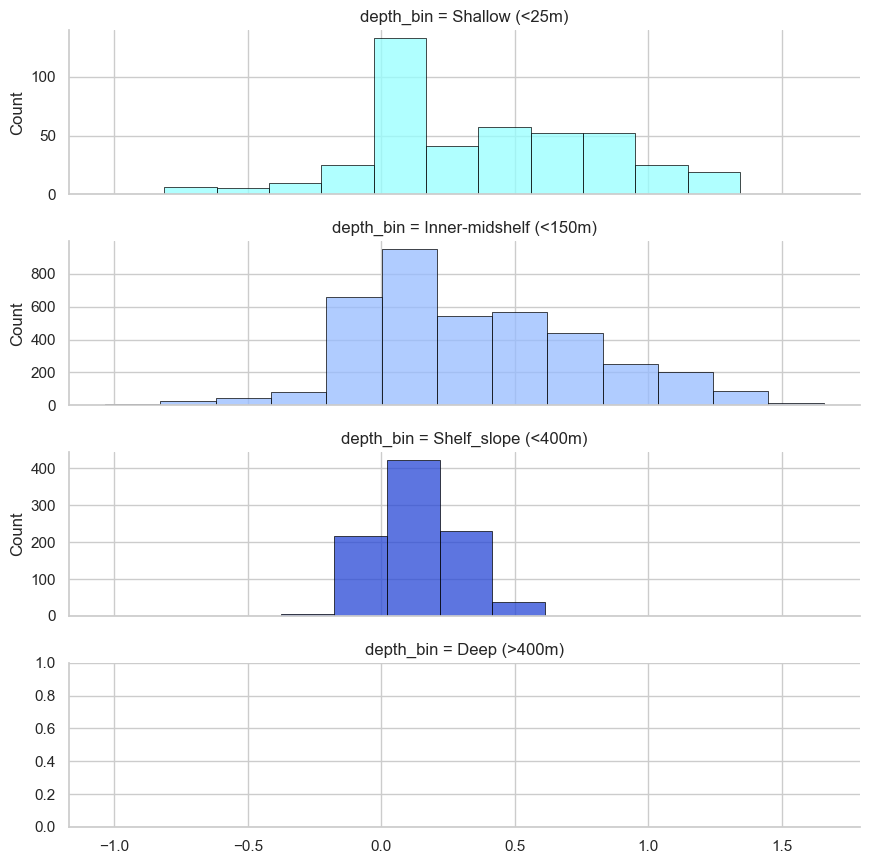

In [27]:

def plot_depth_delta_histograms(csv_file):
    # 1. Load data
    df = pd.read_csv(csv_file)

    # 2. Filter data to ensure we drop missing values
    df_clean = df.dropna(subset=["delta_difference_grid", "depth_bin"])

    # 3. Setup styling
    sns.set_theme(style="whitegrid")

    depth_order = ['Shallow (<25m)', 'Inner-midshelf (<150m)', 'Shelf_slope (<400m)', 'Deep (>400m)']

    g = sns.FacetGrid(
        df_clean,
        row="depth_bin",
        row_order=depth_order,
        hue="depth_bin",
        palette={
            "Shallow (<25m)": "#96ffff",
            "Inner-midshelf (<150m)": "#96bbff",
            "Shelf_slope (<400m)": "#2747d6",
            "Deep (>400m)": "#7775fd",
        },
        aspect=4,
        height=2.2,
        sharey=False,  # Allows each depth's count to scale dynamically
    )

    # 4. Map the histogram
    g.map_dataframe(
        sns.histplot,
        x="delta_difference_grid",
        binwidth=0.2,
        edgecolor="black",
        linewidth=0.5,
        alpha=0.75,
    )
    g.set(xlim=(-4, 5))
    
    # 5. Add a reference line at 0 (Perfect Model-Obs Agreement)
    g.refline(x=0, color="black", linestyle="-", linewidth=1.0, alpha=0.5)

    # 6. Dynamically add Mean Lines, Mean Text, and Clean Titles
    for bin_name, ax in g.axes_dict.items():
        # Filter data for the specific depth bin to calculate its mean
        bin_data = df_clean[df_clean["depth_bin"] == bin_name]["delta_difference_grid"]
        
        if not bin_data.empty:
            mean_val = bin_data.mean()
            
            # Draw the red dotted average line
            ax.axvline(x=mean_val, color="crimson", linestyle=":", linewidth=1.8, label=f"Mean: {mean_val:.2f}")
            
            # Add text label for the mean near the top of each plot
            # transform=ax.get_xaxis_transform() places the y-coordinate relative to the top of the axis (0.90 = 90% up)
            ax.text(
                mean_val + 0.1, 0.90, f"Mean: {mean_val:.2f} mg/L", 
                color="crimson", 
                fontweight="bold",
                fontsize=9,
                transform=ax.get_xaxis_transform(),
                ha="left" if mean_val >= 0 else "right" # Adjust alignment so text doesn't overlap the line drastically
            )
        
        # Clean title: Strip out "depth_bin =" entirely and just leave the clean name
        ax.set_title(bin_name, weight="bold", size=11)

    # Adjust layout spacing to avoid overlaps
    plt.subplots_adjust(hspace=0.5)
    g.fig.suptitle(
        "Depth-Resolved Distribution of Oxygen Delta Differences",
        fontsize=14,
        fontweight="bold",
        y=1.02,
    )
    g.set_axis_labels("Delta Difference (Observed - Model Dissolved Oxygen mg/L)", "Count")
    plt.show()

# Execution path
csv_path = r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Processed_Data\comparison\complete\OA_MOM6_3x3x3_comparison_classified.csv"
plot_depth_delta_histograms(csv_path)

In [6]:

shapefile_url = 'https://github.com/hsynan/READ-EDAB-Synan_hydrographic_climatologies/raw/refs/heads/main/data/shapefiles/NES_5REGIONS.zip'
gdf_shapes = gpd.read_file(shapefile_url)
gdf_shapes




,area,geometry
0,5.770158,"POLYGON ((-74.71113 36.50517, -74.71232 36.501..."
1,6.227196,"POLYGON ((-71.73448 39.95008, -71.74059 39.950..."
2,4.762347,"POLYGON ((-66.74085 40.75303, -66.74573 40.750..."
3,4.382310,"POLYGON ((-69.91489 42.02679, -69.98377 42.004..."
4,6.376634,"POLYGON ((-65.56925 42.16613, -65.68762 41.935..."


In [24]:
ds = xr.open_dataset(
    r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Raw_Data\New folder\0219960.4.5\0219960\4.5\data\0-data\Data_CODAP\NetCDF\CODAP_NA_v2021.nc",
    chunks={'obs': 10000} # Adjust 'obs' to match the actual primary dimension name if different
)
ds

<xarray.Dataset> Size: 17MB
Dimensions:                                  (data_grid: 28206, expo: 12,
                                              cruise_flag: 1, cruise_ID: 11,
                                              observation_type: 12, station: 5)
Dimensions without coordinates: data_grid, expo, cruise_flag, cruise_ID,
                                observation_type, station
Data variables: (12/73)
    Accession                                (data_grid) float64 226kB dask.array<chunksize=(28206,), meta=np.ndarray>
    EXPOCODE                                 (expo, data_grid) |S1 338kB dask.array<chunksize=(12, 28206), meta=np.ndarray>
    Cruise_flag                              (cruise_flag, data_grid) |S1 28kB dask.array<chunksize=(1, 28206), meta=np.ndarray>
    Cruise_ID                                (cruise_ID, data_grid) |S1 310kB dask.array<chunksize=(11, 28206), meta=np.ndarray>
    Observation_type                         (observation_type, data_grid) |S1 338kB dask.array<chunksize=(12, 28206), meta=np.ndarray>
    Profile_number                           (data_grid) float64 226kB dask.array<chunksize=(28206,), meta=np.ndarray>
    ...                                       ...
    Nitrate_and_Nitrite_umol_kg              (data_grid) float64 226kB dask.array<chunksize=(28206,), meta=np.ndarray>
    Nitrate_and_Nitrite_flag                 (data_grid) float64 226kB dask.array<chunksize=(28206,), meta=np.ndarray>
    recommended_Nitrate_and_Nitrite_umol_kg  (data_grid) float64 226kB dask.array<chunksize=(28206,), meta=np.ndarray>
    recommended_Nitrate_and_Nitrite_flag     (data_grid) float64 226kB dask.array<chunksize=(28206,), meta=np.ndarray>
    Ammonium_umol_kg                         (data_grid) float64 226kB dask.array<chunksize=(28206,), meta=np.ndarray>
    Ammonium_flag                            (data_grid) float64 226kB dask.array<chunksize=(28206,), meta=np.ndarray>
Attributes:
    Title:     Coastal Ocean Data Analysis Product in North America (CODAP-NA...
    Abstract:  This data product contains discrete carbon, oxygen and nutrien...

In [31]:
import numpy as np
import geopandas as gpd
import pandas as pd
import xarray as xr
from shapely.geometry import Point

# 1. Open the dataset using 'chunks' or lazy loading to prevent MemoryError
ds = xr.open_dataset(
    r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Raw_Data\New folder\0219960.4.5\0219960\4.5\data\0-data\Data_CODAP\NetCDF\CODAP_NA_v2021.nc",
    chunks={'obs': 10000} 
)

# 2. Extract the primary dimension name 
primary_dim = ds['Longitude'].dims[0]

# -------------------------------------------------------------
# MEMORY FIX: Vectorized filter for valid Aragonite data upfront
# -------------------------------------------------------------
aragonite_var_name = 'Aragonite' 

# Extract just the boolean mask without loading the whole dataset array
valid_aragonite_mask = ds[aragonite_var_name].notnull().values

# Fail-safe check to make sure your variable name matches
if not valid_aragonite_mask.any():
    print(f"Warning: No valid data or wrong variable name for '{aragonite_var_name}'. Check ds.data_vars")

# Apply the aragonite filter immediately to shrink the dataset size in memory
ds_filtered = ds.isel({primary_dim: valid_aragonite_mask})

# 3. Now perform the Spatial Join on the highly reduced dataset
gdf_shapes = gdf_shapes.set_crs("EPSG:4326")
gdf_shapes = gdf_shapes.to_crs("EPSG:4326").reset_index(drop=True)
region_mapping = {0: "MAB_south", 1: "MAB_north", 2: "GB", 3: "GOM_west", 4: "GOM_east"}
gdf_shapes['Region_Name'] = gdf_shapes.index.map(region_mapping)

# Pull coordinates ONLY for points that have valid aragonite values
lons = ds_filtered['Longitude'].values
lats = ds_filtered['Latitude'].values

points = [Point(xy) for xy in zip(lons, lats)]
gdf_points = gpd.GeoDataFrame(geometry=points, crs="EPSG:4326")
gdf_points = gdf_points.set_crs("EPSG:4326")

# Find spatial intersections
spatial_match = gpd.sjoin(gdf_points, gdf_shapes[['geometry', 'Region_Name']], how='left', predicate='within')
inside_polygon_mask = spatial_match['Region_Name'].notna().values

# Final slicing for geographic regions
ds_clipped = ds_filtered.isel({primary_dim: inside_polygon_mask})

# Assign labels
matched_regions = spatial_match['Region_Name'].dropna().values
ds_clipped = ds_clipped.assign(Region_Name=(primary_dim, matched_regions))

# Save full subset coordinates back out to your NetCDF file destination
#ds_clipped.to_netcdf(r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Raw_Data\Vessels\vessel_based_bottom_OA_data_2007_2024.nc")

# -------------------------------------------------------------
# EXTRACT THE DATAFRAME WITH ALL SPECIFIED METRICS
# -------------------------------------------------------------
# FIX: Added your explicit tracking variables into the extraction array list
target_variables = [
    'Longitude', 
    'Latitude', 
    aragonite_var_name, 
    'Region_Name', 
    'Year_UTC', 
    'Time_UTC', 
    'Day_UTC', 
    'Cruise_ID', 
    'Depth_bottom', 
    'Depth'
]

final_df = ds_clipped[target_variables].to_dataframe()

# Clean up flag value artifacts across key columns if present (-999 or -999.0)
final_df = final_df[final_df["Aragonite"] != -999]
final_df = final_df[final_df["Year_UTC"] != -999]

# Optional: Drop the index if 'obs' dimension was added as a row index hierarchy layout
final_df = final_df.reset_index(drop=True)

final_df

,Longitude,Latitude,Aragonite,Region_Name,Year_UTC,Time_UTC,Day_UTC,Cruise_ID,Depth_bottom,Depth
0,-70.236,40.5065,3.36,MAB_north,2015.0,0.349363,20.0,b'E',-999.0,2.0
1,-70.236,40.5065,3.36,MAB_north,2015.0,0.349363,20.0,b'C',-999.0,2.0
2,-70.236,40.5065,3.36,MAB_north,2015.0,0.349363,20.0,b'O',-999.0,2.0
3,-70.236,40.5065,3.36,MAB_north,2015.0,0.349363,20.0,b'A',-999.0,2.0
4,-70.236,40.5065,3.36,MAB_north,2015.0,0.349363,20.0,b'1',-999.0,2.0
...,...,...,...,...,...,...,...,...,...,...
22699,-70.548,43.0320,2.34,GOM_west,2012.0,0.518750,13.0,b'2',50.0,3.0
22700,-70.548,43.0320,2.34,GOM_west,2012.0,0.518750,13.0,b' ',50.0,3.0
22701,-70.548,43.0320,2.34,GOM_west,2012.0,0.518750,13.0,b' ',50.0,3.0
22702,-70.548,43.0320,2.34,GOM_west,2012.0,0.518750,13.0,b' ',50.0,3.0


TypeError: Axes.text() missing 1 required positional argument: 's'

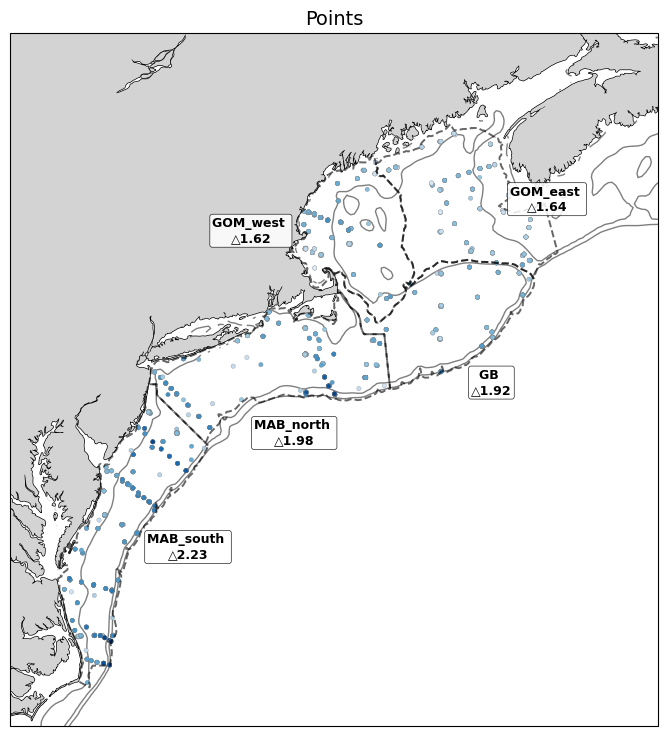

In [23]:
def map_datapoints(df, bathymetry_nc_path, title):
    # 1. Load delta data and geospatial shapes
    final = df
    
    # Load shapefile (already known to be in EPSG:4326 via your snippet)
    shapefile = gpd.read_file('https://github.com/hsynan/READ-EDAB-Synan_hydrographic_climatologies/raw/refs/heads/main/data/shapefiles/NES_5REGIONS.zip')
    if shapefile.crs is None:
        shapefile.set_crs("epsg:4326", inplace=True)
    elif shapefile.crs != "epsg:4326":
        shapefile = shapefile.to_crs("epsg:4326")

    # Load MOM6 static depth / bathymetry
    ds_bathym = xr.open_dataset(bathymetry_nc_path)
    
    # Setup base figure
    fig = plt.figure(figsize=(15, 9))
    map_projection = ccrs.PlateCarree()
    ax = plt.axes(projection=map_projection)


    # 3. Scatter Plot of Point Observations vs Grid Delta
    sc = ax.scatter(
        final['Longitude'].astype(float), 
        final['Latitude'].astype(float), 
        c=final['Aragonite'], 
        cmap='Blues', 
        s=10, 
        edgecolors='grey', 
        linewidths=0.2, 
        transform=map_projection,
        zorder=3
    )

# 4. OVERLAY: Bathymetry Contour Lines from MOM6 NetCDF
    lon_var = 'lonh' if 'lonh' in ds_bathym.variables else ('lon' if 'lon' in ds_bathym.variables else 'xh')
    lat_var = 'lath' if 'lath' in ds_bathym.variables else ('lat' if 'lat' in ds_bathym.variables else 'yh')

    # Extract raw 2D depth matrices and define target line thresholds
    depth_data = ds_bathym['deptho'].values
    contour_levels = [25, 150, 400]

    # Plot uncolored neutral gray contour line isobaths
    # FIX: Pass clip_path=ax.patch directly inside the contour function call
    bathym_contours = ax.contour(
        ds_bathym[lon_var], ds_bathym[lat_var], depth_data,
        levels=contour_levels,
        colors='#7f7f7f',       # Clean, uncolored neutral gray lines
        linewidths=1.0,         # Slim line weight
        linestyles='-',         # Solid contour lines
        transform=map_projection,
        clip_path=ax.patch,     # Forces exact clipping to map frame boundaries natively
        zorder=1
    )

    # Custom legend matching the clean line format
    depth_labels = ['Shallow Limit (25m)', 'Midshelf Limit (150m)', 'Shelf-Slope Limit (400m)']
    
    # Generate line handles for the legend matching our contour lines
    legend_lines = [
        plt.Line2D([0], [0], color='#7f7f7f', linewidth=1.0, linestyle='-', label=label)
        for label in depth_labels
    ]
    



    # 5. OVERLAY: Regional Shapefile Boundaries & Text Labels
    # Draw regional outlines
    shapefile.geometry.boundary.plot(
        ax=ax, 
        color='black', 
        linewidth=1.4, 
        linestyle='--', 
        alpha=0.6,
        transform=map_projection,
        zorder=10
    )

    # Define dictionary maps matching your shapefile index/id rows
    region_names = {0: "MAB_south", 1: "MAB_north", 2: "GB", 3: "GOM_west", 4: "GOM_east"}


    region_offsets = {
        "MAB_south":  {"lon": +1.4, "lat":  -0.4}, # Shift left and up slightly
        "MAB_north":  {"lon":  0.4, "lat": -1.1}, # Shift down slightly
        "GB":         {"lon":  1, "lat":  -1.1}, # Shift right and down
        "GOM_west":   {"lon": -2.3, "lat":  0.1}, # Shift left slightly
        "GOM_east":   {"lon":  1.8, "lat": 0.1}  # Shift right and down
    }

    regional_means = final.groupby('Region_Name')['Aragonite'].mean().to_dict()

    for idx, row in shapefile.iterrows():
        name = region_names.get(idx, f"Region {idx}")
        r_mean=regional_means.get(name, 0.0)
        display_text = f"{name} \n△{r_mean:.2f}"
        
        # Get the default center coordinates
        centroid = row.geometry.centroid
        lon_pos = centroid.x
        lat_pos = centroid.y
        
        # CHANGED: Apply custom offset if the region exists in our dictionary
        if name in region_offsets:
            lon_pos += region_offsets[name]["lon"]
            lat_pos += region_offsets[name]["lat"]
        
        ax.text(
            lon_pos, lat_pos, display_text, # Using the adjusted coordinates
            color='black', fontsize=9, fontweight='bold',
            ha='center', va='center', transform=map_projection,
            bbox=dict(facecolor='white', alpha=0.85, edgecolor='black', linewidth=0.5, boxstyle='round,pad=0.2'),
            zorder=11
        )

    # 6. Map features and basemaps
    ax.add_feature(cfeature.COASTLINE, linewidth=1)
    ax.add_feature(cfeature.LAND, zorder=2, facecolor='lightgrey')
    
    # Set explicit spatial scope frame
    ax.set_extent([-77, -63, 34.5, 46], crs=ccrs.PlateCarree())
    ax.set_title(title, fontsize=14)

    

    box_style = dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.85, edgecolor='gray', linewidth=0.5)
    ax.text(
        0.67, 0.05,  
        transform=ax.transAxes, 
        fontsize=10, 
        fontweight='bold',
        va='bottom', 
        ha='left', 
        bbox=box_style,
        zorder=105 
    )

    plt.show()

# Execution Syntax
csv_path = r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Processed_Data\comparison\complete\CONCAT_MOM6_3x3x3_comparison.csv"
bathymetry_path = r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Bathymetry\MOM6_hindcast_ocean_static_deptho.nc"

map_datapoints(final_df, bathymetry_path, 'Points')


Data columns list: ['time', 'data_source', 'cruise', 'obs_type', 'accession', 'lat', 'lon', 'depth', 'bottom_depth', 'pH_bottom', 'omega_bottom', 'temperature_bottom', 'Region_Name']

Points assigned per region:
Region_Name
MAB_south    203
MAB_north    181
GOM_east     168
NaN          159
GOM_west     157
GB           109
Name: count, dtype: int64


TypeError: Axes.text() missing 1 required positional argument: 's'

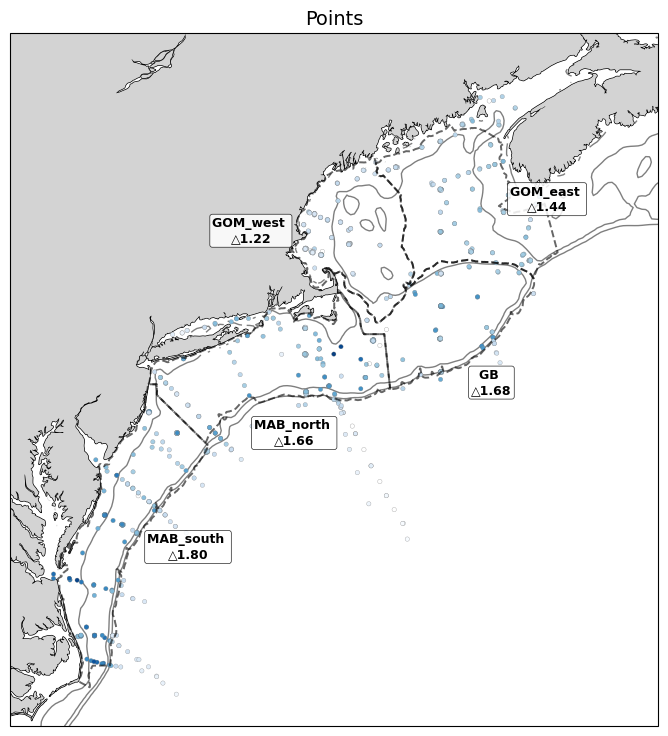

In [21]:
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point
import xarray as xr

# 1. Load the new vessel dataset
ds = xr.open_dataset(r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Raw_Data\Vessels\vessel_based_bottom_OA_data_2007_2024.nc")
df = ds.to_dataframe().reset_index() # reset_index ensures coordinates like Lat/Lon become standard columns

# 2. Prepare your shapefile and map your region names dictionary
# (Assuming gdf_shapes is your existing GeoDataFrame for the 5 regions)
gdf_shapes = gdf_shapes.to_crs("EPSG:4326").reset_index(drop=True)
region_mapping = {
    0: "MAB_south",
    1: "MAB_north",
    2: "GB",
    3: "GOM_west",
    4: "GOM_east"
}
gdf_shapes['Region_Name'] = gdf_shapes.index.map(region_mapping)

# 3. Convert your dataframe points into a GeoDataFrame
# NOTE: Check your print(df.columns.to_list()) output. 
# If columns are lower-case, change 'Longitude'/'Latitude' to 'longitude'/'latitude' below.
points = [Point(xy) for xy in zip(df['lon'], df['lat'])]
gdf_points = gpd.GeoDataFrame(df, geometry=points, crs="EPSG:4326")

# 4. Perform the Spatial Join to tag points with their respective regions
spatial_match = gpd.sjoin(gdf_points, gdf_shapes[['geometry', 'Region_Name']], how='left', predicate='within')

# 5. Push the matched region names back onto your main dataframe 
# points outside your polygons will cleanly default to "NaN" (unclassified shelf/open ocean)
df['Region_Name'] = spatial_match['Region_Name']

# Print verification info
print("Data columns list:", df.columns.to_list())
print("\nPoints assigned per region:")
print(df['Region_Name'].value_counts(dropna=False))

# 6. Pass your newly region-tagged dataframe into your mapping function
map_datapoints(df, bathymetry_path, 'Points')


In [ ]:
final_df

In [28]:
df.to_csv(processed_data / "README.csv")